In [1]:
%matplotlib inline
import matplotlib
matplotlib.rcParams['figure.dpi'] = 120

### All Imports

In [2]:
%pip install numpy pandas matplotlib seaborn scipy scikit-learn xgboost torch lime shap

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: C:\Users\Anushree\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [3]:
# =============================================================================
# STANDARD LIBRARIES
# =============================================================================
import os
import re
import gc
import time
import math
import ast
import warnings
import subprocess
from pathlib import Path

warnings.filterwarnings("ignore")

# =============================================================================
# DATA PROCESSING
# =============================================================================
import numpy as np
import pandas as pd

# =============================================================================
# VISUALIZATION
# =============================================================================
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import matplotlib.patches as mpatches
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns

# =============================================================================
# SCIENTIFIC / STATISTICS
# =============================================================================
from scipy.stats import pointbiserialr

# =============================================================================
# MACHINE LEARNING — PREPROCESSING
# =============================================================================
from sklearn.preprocessing import RobustScaler, StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif

# =============================================================================
# MACHINE LEARNING — MODEL SELECTION
# =============================================================================
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GroupKFold,
    GroupShuffleSplit,
    cross_validate,
    GridSearchCV,
    RandomizedSearchCV
)

# =============================================================================
# MACHINE LEARNING — MODELS
# =============================================================================
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.cluster import KMeans
from xgboost import XGBClassifier

# =============================================================================
# MACHINE LEARNING — PIPELINES
# =============================================================================
from sklearn.pipeline import Pipeline

# =============================================================================
# MACHINE LEARNING — METRICS
# =============================================================================
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    silhouette_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

# =============================================================================
# DEEP LEARNING (PYTORCH)
# =============================================================================
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

# =============================================================================
# EXPLAINABLE AI
# =============================================================================
import lime
import lime.lime_tabular
import subprocess
subprocess.run(["pip", "install", "shap", "lime", "--break-system-packages"], check=True)

CompletedProcess(args=['pip', 'install', 'shap', 'lime', '--break-system-packages'], returncode=0)

# Data Cleaning

## Loading the datasheets

In [4]:
# DATA_RAW = Path("/Users/yasme/Desktop/OULAD_Proj/oulad-clustered-student-engagement/data/raw")
#DATA_RAW = Path("/Users/emaniftikhar/Desktop/oulad-clustered-student-engagement/data")
DATA_RAW = Path("C:/Users/Anushree/Documents/PythonProjects/OULAD/oulad-clustered-student-engagement/data/raw")

studentInfo = pd.read_csv(DATA_RAW / "studentInfo.csv")
studentVle = pd.read_csv(DATA_RAW / "studentVle.csv")
assessments = pd.read_csv(DATA_RAW / "assessments.csv")
studentAssessment = pd.read_csv(DATA_RAW / "studentAssessment.csv")
courses = pd.read_csv(DATA_RAW / "courses.csv")
vle = pd.read_csv(DATA_RAW / "vle.csv")
studentReg = pd.read_csv(DATA_RAW / "studentRegistration.csv")

## Tables Overview

In [5]:
datasets = {
    "studentInfo": studentInfo,
    "studentVle": studentVle,
    "assessments": assessments,
    "studentAssessment": studentAssessment,
    "courses": courses,
    "vle": vle,
    "studentRegistration": studentReg
}

for name, df in datasets.items():
    print(f"\n{'='*40}")
    print(f"{name}")
    print(f"{'='*40}")
    print("Shape:", df.shape)
    print("\nMissing values:\n", df.isnull().sum())
    print("\nDuplicate rows:", df.duplicated().sum())


studentInfo
Shape: (32593, 12)

Missing values:
 code_module                0
code_presentation          0
id_student                 0
gender                     0
region                     0
highest_education          0
imd_band                1111
age_band                   0
num_of_prev_attempts       0
studied_credits            0
disability                 0
final_result               0
dtype: int64

Duplicate rows: 0

studentVle
Shape: (10655280, 6)

Missing values:
 code_module          0
code_presentation    0
id_student           0
id_site              0
date                 0
sum_click            0
dtype: int64

Duplicate rows: 787170

assessments
Shape: (206, 6)

Missing values:
 code_module           0
code_presentation     0
id_assessment         0
assessment_type       0
date                 11
weight                0
dtype: int64

Duplicate rows: 0

studentAssessment
Shape: (173912, 5)

Missing values:
 id_assessment       0
id_student          0
date_submitted      0

In [6]:
#Constants
KEYS        = ["id_student", "code_module", "code_presentation"]
COURSE_KEYS = ["code_module", "code_presentation"]
eps         = 1e-9

CONTENT_TYPES    = {"subpage","homepage","oucontent","resource","url","page",
                    "folder","glossary","htmlactivity","dualpane","repeatactivity"}
ASSESSMENT_TYPES = {"quiz","externalquiz","questionnaire"}
SOCIAL_TYPES     = {"forumng","ouwiki","oucollaborate","ouelluminate",
                    "dataplus","sharedsubpage"}
dim_keep         = {"content", "assessment", "social"}
TARGET = "target_at_risk"

In [7]:
# Convert registration and unregistration dates to numeric values
studentReg["date_unregistration"] = pd.to_numeric(
    studentReg["date_unregistration"], errors="coerce")

studentReg["date_registration"] = pd.to_numeric(
    studentReg["date_registration"], errors="coerce")


# Flag students with missing registration dates
studentReg["registration_missing_flag"] = studentReg["date_registration"].isna().astype(int)


# Flag students who withdrew from the course
studentReg["unregistered_flag"] = studentReg["date_unregistration"].notna().astype(int)


# Convert the unregistration date (in days) into the week of withdrawal
studentReg["unregistration_week"] = (
    (studentReg["date_unregistration"] // 7) + 1
).fillna(-1).astype(int)


# Replace missing registration dates with 0
studentReg["date_registration"] = studentReg["date_registration"].fillna(0)


# Flag students who registered after the course start date
studentReg["late_registration_flag"] = (studentReg["date_registration"] > 0).astype(int)


print("Total registration records:", len(studentReg))

print("Students withdrawn before course start:", (studentReg["date_unregistration"] < 0).sum())

print(   "Students with a withdrawal date:",studentReg["date_unregistration"].notna().sum())


Total registration records: 32593
Students withdrawn before course start: 2678
Students with a withdrawal date: 10072


In [8]:
# Create a copy of courses
courses = courses.copy()

# Convert module presentation length (in days) to numeric
courses["module_presentation_length"] = pd.to_numeric(
    courses["module_presentation_length"], errors="coerce")

# Convert course length from days to weeks
courses["course_weeks"] = np.ceil(
    courses["module_presentation_length"] / 7).astype("Int64")


# Identify course type: STEM vs non-STEM
# Modules AAA, BBB, GGG are considered non-STEM
non_stem_modules = {"AAA", "BBB", "GGG"}
courses["course_type_stem"] = (
    ~courses["code_module"].astype(str).str.upper().str.strip().isin(non_stem_modules)
).astype(int)


# Display distribution of course lengths in weeks
print("Unique course week lengths:")
print(courses["course_weeks"].value_counts(dropna=False))


# Function to determine quarter cutoffs for each course
# For 38-week and 34-week courses, fixed cutoffs are used (based on the paper)
# Other course lengths use proportional cutoffs
def assign_quarter_cutoffs(course_weeks):
    """
    Paper's fixed cutoffs:
      38-week: Q1=10, Q2=19, Q3=29, Q4=38
      34-week: Q1=9,  Q2=17, Q3=26, Q4=34
    All other lengths: proportional fallback.
    """
    if course_weeks == 38:
        return 10, 19, 29, 38
    elif course_weeks == 34:
        return 9, 17, 26, 34
    else:
        q1 = max(1, int(np.ceil(course_weeks * 0.25)))
        q2 = min(int(np.ceil(course_weeks * 0.50)), course_weeks)
        q3 = min(int(np.ceil(course_weeks * 0.75)), course_weeks)
        q4 = course_weeks
        return q1, q2, q3, q4


# Create course-level table containing unique module–presentation pairs
course_windows = courses[COURSE_KEYS + ["course_weeks"]].drop_duplicates().copy()

# Handle missing or invalid week values
course_windows["course_weeks"] = course_windows["course_weeks"].fillna(1).clip(lower=1).astype(int)


# Apply quarter cutoff function to determine Q1–Q4 end weeks
cutoffs = course_windows["course_weeks"].apply(
    lambda cw: pd.Series(
        assign_quarter_cutoffs(cw), index=["q1_end","q2_end","q3_end","q4_end"]))

# Merge cutoff values back into the course table
course_windows = pd.concat([course_windows, cutoffs], axis=1)


# Define start weeks for each quarter window
course_windows["q1_start"] = 1
course_windows["q2_start"] = course_windows["q1_end"] + 1
course_windows["q3_start"] = course_windows["q2_end"] + 1
course_windows["q4_start"] = course_windows["q3_end"] + 1


# Display computed temporal windows for each course
print("\nCourse windows:")
print(course_windows[COURSE_KEYS + ["course_weeks","q1_end","q2_end","q3_end","q4_end"]])


Unique course week lengths:
course_weeks
39    9
35    8
38    4
34    1
Name: count, dtype: Int64

Course windows:
   code_module code_presentation  course_weeks  q1_end  q2_end  q3_end  q4_end
0          AAA             2013J            39      10      20      30      39
1          AAA             2014J            39      10      20      30      39
2          BBB             2013J            39      10      20      30      39
3          BBB             2014J            38      10      19      29      38
4          BBB             2013B            35       9      18      27      35
5          BBB             2014B            34       9      17      26      34
6          CCC             2014J            39      10      20      30      39
7          CCC             2014B            35       9      18      27      35
8          DDD             2013J            38      10      19      29      38
9          DDD             2014J            38      10      19      29      38
10         DDD 

In [9]:
# Create a copy of studentInfo
studentInfo = studentInfo.copy()


# Create binary target variable for academic risk
studentInfo["target_at_risk"] = (
    studentInfo["final_result"].isin(["Fail","Withdrawn"])).astype(int)


# Convert gender to binary variable (Male = 1, Female = 0)
studentInfo["gender_bin"] = (
    studentInfo["gender"].astype(str).str.upper() == "M").astype(int)


# Convert disability status to binary variable (Yes = 1, No = 0)
studentInfo["disability_bin"] = (
    studentInfo["disability"].astype(str).str.upper() == "Y").astype(int)


# Map age bands to ordinal numeric categories
age_map = {"0-35": 0, "35-55": 1, "55<=": 2, "55+": 2}
studentInfo["age_band_ord"] = studentInfo["age_band"].map(age_map)

# Flag missing or unknown age band values
studentInfo["age_band_missing_flag"] = (
    studentInfo["age_band"].isna() |
    ~studentInfo["age_band"].isin(age_map.keys())).astype(int)

# Impute missing age band values using the median category
studentInfo["age_band_ord"] = studentInfo["age_band_ord"].fillna(
    studentInfo["age_band_ord"].median())


# Map education levels to ordinal scale representing qualification level
edu_map = {
    "No Formal quals": 0,
    "Lower Than A Level": 1,
    "A Level or Equivalent": 2,
    "HE Qualification": 3,
    "Post Graduate Qualification": 4
}
studentInfo["highest_education_ord"] = studentInfo["highest_education"].map(edu_map)

# Flag missing or unknown education values
studentInfo["highest_education_missing_flag"] = (
    studentInfo["highest_education"].isna() |
    ~studentInfo["highest_education"].isin(edu_map.keys())).astype(int)

# Impute missing education values with the median category
studentInfo["highest_education_ord"] = studentInfo["highest_education_ord"].fillna(
    studentInfo["highest_education_ord"].median())


# Map detailed regions into broader UK nation groups
def map_region_to_nation(region):
    if pd.isna(region):
        return "Other"
    r = str(region).lower()
    if "scotland" in r:
        return "Scotland"
    if "wales" in r:
        return "Wales"
    if "ireland" in r:
        return "Northern_Ireland"
    if "england" in r or "region" in r:
        return "England"
    return "Other"

studentInfo["nation"] = studentInfo["region"].apply(map_region_to_nation)


# One-hot encode the nation categories
nation_ohe = pd.get_dummies(studentInfo["nation"], prefix="nation", dummy_na=False)
studentInfo = pd.concat([studentInfo, nation_ohe], axis=1)


# Convert IMD (deprivation index) bands into 5 broader categories
def bin_imd_5(x):
    x = str(x).strip()
    if x in {"0-10%","10-20%"}:   return "VeryLow"
    if x in {"20-30%","30-40%"}:  return "Low"
    if x in {"40-50%","50-60%"}:  return "Medium"
    if x in {"60-70%","70-80%"}:  return "High"
    if x in {"80-90%","90-100%"}: return "VeryHigh"
    return "Unknown"


# Clean IMD values and apply binning
studentInfo["imd_band"] = studentInfo["imd_band"].fillna("Unknown").astype(str)
studentInfo["imd_5cat"] = studentInfo["imd_band"].apply(bin_imd_5)


# Convert IMD categories to ordinal numeric values
imd_ord_map = {
    "VeryLow":0,
    "Low":1,
    "Medium":2,
    "High":3,
    "VeryHigh":4,
    "Unknown":np.nan
}

studentInfo["imd_ordinal"] = studentInfo["imd_5cat"].map(imd_ord_map)

# Flag unknown IMD values
studentInfo["imd_unknown_flag"] = studentInfo["imd_ordinal"].isna().astype(int)

# Impute missing IMD values with the median
studentInfo["imd_ordinal"] = studentInfo["imd_ordinal"].fillna(
    studentInfo["imd_ordinal"].median()).astype(float)


# Drop original categorical columns after encoding and transformation
studentInfo.drop(
    columns=[
        "gender",
        "disability",
        "age_band",
        "highest_education",
        "region",
        "nation",
        "imd_band",
        "imd_5cat"
    ],
    inplace=True
)

In [10]:
# Remove the course_weeks column from the courses table
courses_no_weeks = courses.drop(columns=["course_weeks"], errors="ignore")


# Create the base dataset by merging all static information sources
base_static = (
    studentInfo
    .merge(studentReg, on=KEYS, how="inner")                     # add registration and withdrawal information
    .merge(courses_no_weeks, on=COURSE_KEYS, how="inner")        # add course-level attributes
    .merge(
        course_windows[COURSE_KEYS + ["course_weeks","q1_end","q2_end","q3_end","q4_end"]],
        on=COURSE_KEYS, how="inner"                              # add temporal quarter boundaries
    )
)
print(
    f"\nbase_static: {base_static.shape}  |  at-risk: {base_static['target_at_risk'].mean()*100:.1f}%"
)


base_static: (32593, 32)  |  at-risk: 52.8%


In [11]:

# =========================================================
# Identify students enrolled at each checkpoint
# =========================================================

# Existing checkpoint definitions from the notebook
CHECKPOINT_COLS = {
    "Q1": "q1_end",
    "Q2": "q2_end",
    "Q3": "q3_end",
    "Q4": "q4_end",
    "Master": "q4_end"
}

# Keep withdrawal information separately from model features
enrollment_lookup = base_static[
    KEYS + [
        "date_registration", "date_unregistration",
        "q1_end", "q2_end", "q3_end", "q4_end"
    ]
].copy()

assert not enrollment_lookup.duplicated(KEYS).any()


def add_enrollment_status(df, checkpoint):

    cutoff_col = CHECKPOINT_COLS[checkpoint]

    result = df.merge(
        enrollment_lookup[
            KEYS + ["date_registration", "date_unregistration", cutoff_col]
        ],
        on=KEYS,
        how="left",
        validate="many_to_one",
        indicator=True
    )

    if not (result["_merge"] == "both").all():
        raise ValueError("Some student records have no enrollment information")

    result.drop(columns="_merge", inplace=True)

    # The notebook defines week as date // 7 + 1
    result["checkpoint_day"] = result[cutoff_col] * 7 - 1

    # Registered by the checkpoint AND not already withdrawn.
    # Missing registration dates were set to 0 with missingness indicator in cell 11.
    result["enrolled_at_checkpoint"] = (
        (result["date_registration"] <= result["checkpoint_day"])
        & (result["date_unregistration"].isna()
           | (result["date_unregistration"] > result["checkpoint_day"]))
    )

    return result.drop(columns=[cutoff_col])


print("Enrollment-checking function created.")


Enrollment-checking function created.


In [12]:
# Function to convert presentation codes into a sortable chronological format
def parse_presentation_order(pres):
    """Parse '2013B', '2013J', '2014B' → (year, season) for chronological ordering."""
    pres = str(pres).strip()
    try:
        year = int(pres[:4])
        season_order = {"B": 0, "J": 1}.get(pres[4:].upper(), 0)
        return (year, season_order)
    except:
        return (0, 0)


# Count number of students in each module–presentation combination
pres_per_module = (
    base_static.groupby(COURSE_KEYS).size().reset_index(name="n_students")
)

# Add chronological order for each presentation
pres_per_module["pres_order"] = pres_per_module["code_presentation"].apply(
    parse_presentation_order
)

# Sort presentations within each module by time
pres_per_module = pres_per_module.sort_values(
    ["code_module", "pres_order"]
).reset_index(drop=True)


# Display all module presentations in chronological order
print("\nAll presentations (chronological):")
print(pres_per_module[["code_module", "code_presentation", "n_students"]].to_string(index=False))


# Identify modules that appear in only one presentation
# These cannot contribute to the held-out test split across time
single_pres = (
    pres_per_module.groupby("code_module")["code_presentation"]
    .nunique()
    .pipe(lambda s: s[s == 1])
    .index.tolist()
)

if single_pres:
    print(f"\n⚠️  Modules with 1 presentation (train only): {single_pres}")


# Select the latest presentation of each module as the test set
# This simulates deployment on future presentations
test_presentations = (
    pres_per_module.sort_values(["code_module", "pres_order"])
    .groupby("code_module")
    .last()
    .reset_index()[["code_module", "code_presentation"]]
)

print("\nHeld-out test presentations:")
print(test_presentations.to_string(index=False))


# Create a set of test module–presentation pairs
test_set = set(zip(
    test_presentations["code_module"],
    test_presentations["code_presentation"]
))

# Mark rows belonging to the held-out test presentations
test_mask = base_static.apply(
    lambda r: (r["code_module"], r["code_presentation"]) in test_set,
    axis=1
)


# Extract train and test student keys based on the presentation split
train_keys = base_static.loc[~test_mask, KEYS].copy()
test_keys  = base_static.loc[test_mask, KEYS].copy()


# Print summary of train and test split sizes
print(f"\nTrain: {len(train_keys):,} students | "
      f"{base_static.loc[~test_mask,'code_presentation'].nunique()} presentations")
print(f"Test:  {len(test_keys):,} students | "
      f"{base_static.loc[test_mask,'code_presentation'].nunique()} presentations")


# Ensure no module–presentation pair appears in both train and test sets
# This prevents temporal leakage across presentations
assert len(
    set(zip(train_keys["code_module"], train_keys["code_presentation"])) &
    set(zip(test_keys["code_module"],  test_keys["code_presentation"]))
) == 0, "Presentation leakage detected!"

print("✓ No presentation overlap")


All presentations (chronological):
code_module code_presentation  n_students
        AAA             2013J         383
        AAA             2014J         365
        BBB             2013B        1767
        BBB             2013J        2237
        BBB             2014B        1613
        BBB             2014J        2292
        CCC             2014B        1936
        CCC             2014J        2498
        DDD             2013B        1303
        DDD             2013J        1938
        DDD             2014B        1228
        DDD             2014J        1803
        EEE             2013J        1052
        EEE             2014B         694
        EEE             2014J        1188
        FFF             2013B        1614
        FFF             2013J        2283
        FFF             2014B        1500
        FFF             2014J        2365
        GGG             2013J         952
        GGG             2014B         833
        GGG             2014J         74

In [13]:

# =========================================================
# Enrollment audit on held-out test students
# =========================================================

enrollment_audit = []

for quarter in ["Q1", "Q2", "Q3", "Q4"]:

    test_q = add_enrollment_status(
        test_keys.copy(),
        quarter
    )

    total = len(test_q)

    enrolled = int(
        test_q["enrolled_at_checkpoint"].sum()
    )

    not_actionable = total - enrolled

    enrollment_audit.append({
        "Quarter": quarter,
        "Total_Test_Students": total,
        "Still_Enrolled": enrolled,
        "Not_Enrolled_At_Checkpoint": not_actionable,
        "Not_Enrolled_%": round(
            100 * not_actionable / total, 2
        )
    })

enrollment_audit_df = pd.DataFrame(enrollment_audit)

display(enrollment_audit_df)


,Quarter,Total_Test_Students,Still_Enrolled,Not_Enrolled_At_Checkpoint,Not_Enrolled_%
0,Q1,11260,8703,2557,22.71
1,Q2,11260,8121,3139,27.88
2,Q3,11260,7623,3637,32.30
3,Q4,11260,7521,3739,33.21


In [14]:
# Convert activity date to numeric format
studentVle["date"] = pd.to_numeric(studentVle["date"], errors="coerce")

# Convert click counts to numeric, replace missing values with 0 and ensure no negative click values remain
studentVle["sum_click"] = pd.to_numeric(
    studentVle["sum_click"], errors="coerce"
).fillna(0).clip(lower=0)


# Aggregate raw VLE interactions at the student–site–day level
studentVle_daily = (
    studentVle
    .groupby(
        ["id_student", "code_module", "code_presentation", "id_site", "date"],
        as_index=False
    )
    .agg(sum_click=("sum_click", "sum"))
)

# Create lookup table linking site IDs to activity types
vle_lookup = vle[["id_site", "activity_type"]].drop_duplicates()

# Enrich daily interactions with activity type information
studentVle_daily_enr = studentVle_daily.merge(vle_lookup, on="id_site", how="left")

# Free memory after intermediate merge
del studentVle_daily, vle_lookup, studentVle
gc.collect()


# Remove interactions recorded before course start
studentVle_daily_enr = studentVle_daily_enr[studentVle_daily_enr["date"] >= 0].copy()

# Convert activity day into course week number
studentVle_daily_enr["week"] = (studentVle_daily_enr["date"] // 7) + 1


# Map detailed VLE activity types into broader engagement dimensions
def map_engagement_dim(activity_type):
    if pd.isna(activity_type):
        return "unknown"
    a = str(activity_type).strip().lower()
    if a in CONTENT_TYPES:
        return "content"
    if a in ASSESSMENT_TYPES:
        return "assessment"
    if a in SOCIAL_TYPES:
        return "social"
    return "other"


# Assign engagement dimension to each interaction
studentVle_daily_enr["engagement_dim"] = studentVle_daily_enr["activity_type"].apply(
    map_engagement_dim
)

# Keep only relevant columns for weekly aggregation
studentVle_daily_enr = studentVle_daily_enr[
    ["id_student", "code_module", "code_presentation", "week", "sum_click", "engagement_dim"]
].copy()


# Aggregate interactions to student–week–engagement dimension level
studentVle_weekly = (
    studentVle_daily_enr
    .groupby(
        ["id_student", "code_module", "code_presentation", "week", "engagement_dim"],
        as_index=False
    )
    .agg(sum_click=("sum_click", "sum"))
)

print(f"studentVle_weekly shape: {studentVle_weekly.shape}")

# Free memory after weekly aggregation
del studentVle_daily_enr
gc.collect()

studentVle_weekly shape: (1085419, 6)


0

In [15]:
# Copy assessment table and standardize assessment type values
assess_clean = assessments.copy()
assess_clean["assessment_type"] = assess_clean["assessment_type"].astype(str).str.lower()

# Exclude exams since they are not used in the behavioural metrics
assess_clean = assess_clean[assess_clean["assessment_type"] != "exam"].copy()

# Convert assessment due date to numeric and remove missing values
assess_clean["date"] = pd.to_numeric(assess_clean["date"], errors="coerce")
assess_clean = assess_clean.dropna(subset=["date"])

# Keep only required assessment fields and rename date as due_date
assess_clean = assess_clean[
    ["id_assessment", "code_module", "code_presentation", "date"]
].rename(columns={"date": "due_date"})

# Keep only records with a valid submission date
sa = studentAssessment.copy()
sa = sa[sa["date_submitted"].notna()].copy()

# Convert submission date to numeric and prevent negative values
sa["date_submitted"] = pd.to_numeric(sa["date_submitted"], errors="coerce").clip(lower=0)

# Keep only relevant submission fields
sa = sa[["id_assessment", "id_student", "date_submitted"]]


# Merge submissions with assessment due dates
sub_all = sa.merge(assess_clean, on="id_assessment", how="inner", validate="m:1")

# Add quarter boundaries for later temporal feature calculations
sub_all = sub_all.merge(
    course_windows[COURSE_KEYS + ["q1_end", "q2_end", "q3_end", "q4_end"]],
    on=COURSE_KEYS, how="inner", validate="m:1"
)

In [16]:
# Robust VLE outlier caps: derive statistics from TRAIN presentations ONLY.
# The original cap_outliers_within_cohort computed 99th percentiles separately
# for held-out test presentations. This implementation freezes train statistics.
_VLE_CAP_KEYS = ["code_module", "code_presentation", "week", "engagement_dim"]
_VLE_CAP_MODE_WEEK = ["code_module", "week", "engagement_dim"]
_VLE_CAP_WEEK = ["week", "engagement_dim"]
_VLE_CAP_DIM = ["engagement_dim"]
_VLE_CAP_CACHE = {}

def _vle_training_caps(vle_weekly, cap_q=0.99):
    cache_key = float(cap_q)
    if cache_key not in _VLE_CAP_CACHE:
        train_vle = vle_weekly.merge(train_keys[KEYS].drop_duplicates(), on=KEYS,
                                     how="inner", validate="many_to_one")
        _VLE_CAP_CACHE[cache_key] = [
            train_vle.groupby(cols, as_index=False)["sum_click"].quantile(cap_q)
                     .rename(columns={"sum_click": f"cap_{j}"})
            for j, cols in enumerate([_VLE_CAP_KEYS, _VLE_CAP_MODE_WEEK,
                                       _VLE_CAP_WEEK, _VLE_CAP_DIM])
        ]
    return _VLE_CAP_CACHE[cache_key]

def cap_outliers_within_cohort(vle_weekly, cohort_keys, cap_q=0.99):
    """Clip weekly clicks with 99th-percentile reference from TRAIN only.

    Exact presentation first; test presentations use historical module-week,
    then historical all-module week, then dimension fallback. No test fitting.
    """
    vle_c = vle_weekly.merge(cohort_keys[KEYS].drop_duplicates(), on=KEYS,
                              how="inner", validate="many_to_one").copy()
    key_sets = [_VLE_CAP_KEYS, _VLE_CAP_MODE_WEEK, _VLE_CAP_WEEK, _VLE_CAP_DIM]
    for j, (cols, cap_table) in enumerate(zip(key_sets, _vle_training_caps(vle_weekly, cap_q))):
        vle_c = vle_c.merge(cap_table, on=cols, how="left", validate="many_to_one")
    cap = vle_c["cap_0"]
    for j in range(1, 4):
        cap = cap.fillna(vle_c[f"cap_{j}"])
    vle_c["sum_click"] = np.minimum(vle_c["sum_click"].to_numpy(dtype=float),
                                     cap.fillna(vle_c["sum_click"]).to_numpy(dtype=float))
    return vle_c.drop(columns=[f"cap_{j}" for j in range(4)])


In [17]:
# Build weekly normalized engagement features using cohort-based denominators
# Each feature represents a student's share of total cohort clicks for a given week and engagement dimension
def build_weekly_norm_features(studentVle_weekly, cohort_keys, course_windows):
    """Weekly norm columns. Denominators from cohort only."""

    # Keep only the engagement dimensions used in modelling
    vle_w = studentVle_weekly[
        studentVle_weekly["engagement_dim"].isin(dim_keep)
    ].copy()

    # Add course length information
    vle_w = vle_w.merge(
        course_windows[COURSE_KEYS + ["course_weeks"]],
        on=COURSE_KEYS, how="inner", validate="m:1"
    )

    # Keep only valid course weeks
    vle_w = vle_w[
        (vle_w["week"] >= 1) & (vle_w["week"] <= vle_w["course_weeks"])
    ].copy()

    # Ensure week is numeric and remove invalid values
    vle_w["week"] = pd.to_numeric(vle_w["week"], errors="coerce")
    vle_w = vle_w.dropna(subset=["week"]).copy()
    vle_w["week"] = vle_w["week"].astype(int)

    # Keep only records belonging to the selected cohort
    vle_cohort = vle_w.merge(cohort_keys, on=KEYS, how="inner")

    # Compute total cohort clicks for each module–presentation–week–dimension
    course_week_dim = (
        vle_cohort
        .groupby(COURSE_KEYS + ["week", "engagement_dim"], as_index=False)
        .agg(course_clicks=("sum_click", "sum"))
    )

    # Merge cohort totals back to student-level weekly data
    vle_cohort = vle_cohort.merge(
        course_week_dim,
        on=COURSE_KEYS + ["week", "engagement_dim"],
        how="left",
        validate="m:1"
    )

    # Calculate each student's normalized share of weekly clicks
    vle_cohort["share_clicks"] = np.where(
        vle_cohort["course_clicks"] > 0,
        vle_cohort["sum_click"] / (vle_cohort["course_clicks"] + eps),
        0.0
    )

    # Pivot to wide format: one column per week–dimension combination
    weekly_wide = (
        vle_cohort.pivot_table(
            index=KEYS,
            columns=["week", "engagement_dim"],
            values="share_clicks",
            fill_value=0.0
        )
        .reset_index()
    )

    # Flatten multi-index columns after pivot
    weekly_wide.columns = [
        c[0] if (isinstance(c, tuple) and (c[1] == "" or c[1] is None)) else c
        for c in weekly_wide.columns
    ]

    # Rename columns into readable feature names
    def _col_name(col):
        if isinstance(col, tuple):
            wk, dim = col
            return f"wk{int(wk):02d}_{dim}_norm"
        return col

    return weekly_wide.rename(columns=_col_name)

In [18]:
# Create course-length-aware aggregate features from weekly normalized engagement columns
# These features summarise overall engagement patterns across the full observed course period
def add_weekly_aggregates(df, course_weeks_col="course_weeks", suffix="_norm", eps=1e-9):
    """Course-length-aware aggregated features from weekly norm columns."""

    # Match weekly normalized columns 
    pat = re.compile(rf"^wk(\d{{2}})_(content|assessment|social){re.escape(suffix)}$")

    # Extract all available week numbers from the dataframe columns
    weeks = sorted({int(pat.match(c).group(1)) for c in df.columns if pat.match(c)})

    # If no matching weekly columns exist, return the dataframe unchanged
    if not weeks:
        return df.copy()

    max_w = max(weeks)

    # Build matrices for content, assessment, and social engagement across weeks
    Xc = df.reindex(
        columns=[f"wk{w:02d}_content{suffix}" for w in weeks],
        fill_value=0.0
    ).to_numpy(float)

    Xa = df.reindex(
        columns=[f"wk{w:02d}_assessment{suffix}" for w in weeks],
        fill_value=0.0
    ).to_numpy(float)

    Xs = df.reindex(
        columns=[f"wk{w:02d}_social{suffix}" for w in weeks],
        fill_value=0.0
    ).to_numpy(float)

    # Total engagement per week across all dimensions
    Xt = Xc + Xa + Xs

    # Read course length and ensure it stays within valid week range
    cw = pd.to_numeric(df[course_weeks_col], errors="coerce").fillna(max_w).clip(1, max_w).to_numpy(int)

    # Create mask so only valid course weeks are included for each student
    week_index = np.array(weeks, dtype=int)[None, :]
    valid_mask = (week_index <= cw[:, None]).astype(float)

    # Apply course-length mask to ignore weeks beyond the student's course duration
    Xc_v, Xa_v, Xs_v, Xt_v = Xc * valid_mask, Xa * valid_mask, Xs * valid_mask, Xt * valid_mask

    # Aggregate total engagement by dimension
    content_eng = Xc_v.sum(axis=1)
    assess_eng = Xa_v.sum(axis=1)
    social_eng = Xs_v.sum(axis=1)
    total_eng = Xt_v.sum(axis=1)

    # Compute dimension ratios relative to total engagement
    content_ratio = content_eng / (total_eng + eps)
    assessment_ratio = assess_eng / (total_eng + eps)
    social_ratio = social_eng / (total_eng + eps)

    # Count number of active weeks (weeks with any engagement)
    active_weeks = (Xt_v > 0).sum(axis=1).astype(int)

    # Store total observed weeks for each student
    weeks_observed = cw

    # Measure consistency of engagement across the course
    active_weeks_ratio = active_weeks / (weeks_observed + eps)

    # Compute entropy of weekly engagement distribution
    # Higher entropy indicates engagement spread more evenly over time
    row_sum = Xt_v.sum(axis=1, keepdims=True)
    P = np.divide(Xt_v, row_sum + eps)

    logP = np.zeros_like(P)
    m = P > 0
    logP[m] = np.log(P[m])

    ent = -(P * logP).sum(axis=1)

    # Normalize entropy by course length
    ent_norm = ent / (np.log(weeks_observed) + eps)

    # Create dataframe of aggregated behavioural features
    new_feat = pd.DataFrame({
        f"content_engagement{suffix}":           content_eng,
        f"assessment_engagement{suffix}":        assess_eng,
        f"social_engagement{suffix}":            social_eng,
        f"total_engagement{suffix}":             total_eng,
        f"content_ratio{suffix}":                content_ratio,
        f"assessment_ratio{suffix}":             assessment_ratio,
        f"social_ratio{suffix}":                 social_ratio,
        f"active_weeks{suffix}":                 active_weeks,
        f"weeks_observed{suffix}":               weeks_observed,
        f"active_weeks_ratio{suffix}":           active_weeks_ratio,
        f"engagement_entropy{suffix}":           ent,
        f"engagement_week_entropy_norm{suffix}": ent_norm,
    }, index=df.index)

    # Append aggregated features to the original dataframe
    return pd.concat([df.copy(), new_feat], axis=1).copy()

In [19]:
# Build quarter-level normalized engagement features
# Each feature represents a student's share of cohort engagement up to a given quarter endpoint (e.g., Q1, Q2, Q3, Q4)
def build_quarter_norm_features(studentVle_weekly, cohort_keys,
                                 course_windows, q_end_col, q_label):
    """Quarter engagement norm features. Denominators from cohort only."""

    # Add course length and quarter boundary information
    vle_q = studentVle_weekly.merge(
        course_windows[COURSE_KEYS + ["course_weeks", "q1_end", "q2_end", "q3_end", "q4_end"]],
        on=COURSE_KEYS, how="inner", validate="m:1"
    ).copy()

    # Keep only valid course weeks
    vle_q = vle_q[
        (vle_q["week"] >= 1) & (vle_q["week"] <= vle_q["course_weeks"])
    ].copy()

    # Keep interactions only up to the selected quarter endpoint
    df = vle_q[vle_q["week"] <= vle_q[q_end_col]].copy()

    # Restrict cohort-based denominators to the selected training cohort
    df_cohort = df.merge(cohort_keys, on=KEYS, how="inner")

    # Compute total cohort clicks by course and engagement dimension
    course_dim = (
        df_cohort[df_cohort["engagement_dim"].isin(dim_keep)]
        .groupby(COURSE_KEYS + ["engagement_dim"], as_index=False)
        .agg(course_clicks=("sum_click", "sum"))
    )

    # Compute total cohort clicks across all engagement types
    course_total = (
        df_cohort.groupby(COURSE_KEYS, as_index=False)
        .agg(course_total_clicks=("sum_click", "sum"))
    )

    # Compute each student's clicks by engagement dimension
    student_dim = (
        df[df["engagement_dim"].isin(dim_keep)]
        .merge(cohort_keys, on=KEYS, how="inner")
        .groupby(KEYS + ["engagement_dim"], as_index=False)
        .agg(clicks=("sum_click", "sum"))
    )

    # Compute each student's total clicks across all engagement types
    student_total = (
        df.merge(cohort_keys, on=KEYS, how="inner")
        .groupby(KEYS, as_index=False)
        .agg(total_clicks=("sum_click", "sum"))
    )

    # Normalize student dimension-level clicks by cohort totals
    student_dim = student_dim.merge(
        course_dim, on=COURSE_KEYS + ["engagement_dim"], how="left", validate="m:1"
    )
    student_dim["norm"] = np.where(
        student_dim["course_clicks"] > 0,
        student_dim["clicks"] / student_dim["course_clicks"],
        0.0
    )

    # Pivot normalized dimension-level features to wide format
    dim_wide = (
        student_dim
        .pivot_table(index=KEYS, columns="engagement_dim", values="norm", fill_value=0.0)
        .reset_index()
        .rename(columns={
            "content":    f"norm_content_{q_label}",
            "assessment": f"norm_assessment_{q_label}",
            "social":     f"norm_social_{q_label}",
        })
    )

    # Normalize total student clicks by total cohort clicks
    total_norm = student_total.merge(
        course_total, on=COURSE_KEYS, how="left", validate="m:1"
    )
    total_norm[f"norm_total_{q_label}"] = np.where(
        total_norm["course_total_clicks"] > 0,
        total_norm["total_clicks"] / total_norm["course_total_clicks"],
        0.0
    )
    total_norm = total_norm[KEYS + [f"norm_total_{q_label}"]]

    # Combine total and dimension-level normalized features
    out = total_norm.merge(dim_wide, on=KEYS, how="left")

    # Fill any missing dimension features with 0
    for c in [f"norm_content_{q_label}", f"norm_assessment_{q_label}", f"norm_social_{q_label}"]:
        out[c] = out.get(c, pd.Series(0.0, index=out.index)).fillna(0.0)

    return out

In [20]:
# Build full-course AP (anti-procrastination) features
# AP is based on how early a student submits relative to the earliest submission for the same assessment within the cohort
def build_ap_full(sub_all, cohort_keys, eps=1e-9):
    """Full-course AP score. Smin from cohort only."""

    # Keep only submissions from the selected cohort
    sub_c = sub_all.merge(cohort_keys, on=KEYS, how="inner")

    # Find the earliest submission date for each assessment within the cohort
    smin = (
        sub_c.groupby(COURSE_KEYS + ["id_assessment"], as_index=False)
        .agg(Smin=("date_submitted", "min"))
    )

    # Merge earliest submission date back to each submission
    sub_c = sub_c.merge(
        smin, on=COURSE_KEYS + ["id_assessment"], how="left", validate="m:1"
    )

    # Compute available submission window and student submission gap
    sub_c["Wa"] = sub_c["due_date"] - sub_c["Smin"]
    sub_c["delta"] = sub_c["due_date"] - sub_c["date_submitted"]

    # Compute AP score: higher values indicate earlier submission behaviour
    sub_c["Ts"] = np.where(
        sub_c["Wa"] > 0,
        sub_c["delta"] / (sub_c["Wa"] + eps),
        0.0
    )

    # Flag late submissions
    sub_c["late_flag"] = (sub_c["date_submitted"] > sub_c["due_date"]).astype(int)

    # Aggregate full-course AP features at student level
    return (
        sub_c.groupby(KEYS, as_index=False)
        .agg(
            AP_full=("Ts", "mean"),
            n_submissions=("Ts", "count"),
            num_late_submissions=("late_flag", "sum")
        )
    )

# Build quarter-specific AP features using only assessments due within that quarter
# AP is calculated relative to the earliest cohort submission for each assessment in that period
def build_ap_quarter(sub_all, cohort_keys, q_end_col, q_label,
                     prev_q_end_col=None, eps=1e-9):
    """Quarter AP score. Smin_q from cohort only."""

    # Keep only submissions from the selected cohort
    sub_c = sub_all.merge(cohort_keys, on=KEYS, how="inner")

    # Convert quarter endpoints from week number to day number
    q_end_day = sub_c[q_end_col] * 7 - 1
    prev_end_day = -1 if prev_q_end_col is None else sub_c[prev_q_end_col] * 7 - 1

    # Keep only assessments whose due dates fall within the selected quarter
    dfq = sub_c[
        (sub_c["due_date"] > prev_end_day) & (sub_c["due_date"] <= q_end_day)
    ].copy()

    # Flag late submissions within the quarter
    dfq["late_q"] = (dfq["date_submitted"] > dfq["due_date"]).astype(int)

    # Find earliest submission date per assessment within the quarter
    smin_q = (
        dfq[dfq["date_submitted"].notna()]
        .groupby(COURSE_KEYS + ["id_assessment"], as_index=False)
        .agg(Smin_q=("date_submitted", "min"))
    )

    # Merge earliest quarter submission date back to each record
    dfq = dfq.merge(
        smin_q, on=COURSE_KEYS + ["id_assessment"], how="left", validate="m:1"
    )

    # Compute AP components within the quarter
    dfq["Wa_q"] = dfq["due_date"] - dfq["Smin_q"]
    dfq["delta_q"] = dfq["due_date"] - dfq["date_submitted"]

    # Compute quarter AP score
    dfq["Ts_q"] = np.where(
        (dfq["Wa_q"] > 0) & (dfq["date_submitted"].notna()),
        dfq["delta_q"] / (dfq["Wa_q"] + eps),
        0.0
    )

    # Aggregate quarter AP features at student level
    return (
        dfq.groupby(KEYS, as_index=False).agg(**{
            f"AP_{q_label}":                   ("Ts_q", "mean"),
            f"n_submissions_{q_label}":        ("Ts_q", "count"),
            f"num_late_submissions_{q_label}": ("late_q", "sum"),
        })
    )

# Derive additional quarter-level behavioural features
# These include engagement ratios and entropy across content, assessment, and social activity
def add_quarter_derived_features(df, q_label, eps=1e-9):
    t, c = f"norm_total_{q_label}", f"norm_content_{q_label}"
    a, s = f"norm_assessment_{q_label}", f"norm_social_{q_label}"

    # Ensure required normalized engagement columns exist
    for col in [t, c, a, s]:
        if col not in df.columns:
            df[col] = 0.0
        df[col] = df[col].fillna(0.0)

    # Total engagement across the three dimensions
    dim_sum = df[c] + df[a] + df[s]

    # Compute proportion of engagement in each dimension
    df[f"content_ratio_{q_label}"] = df[c] / (dim_sum + eps)
    df[f"assessment_ratio_{q_label}"] = df[a] / (dim_sum + eps)
    df[f"social_ratio_{q_label}"] = df[s] / (dim_sum + eps)

    # Compute entropy across engagement dimensions
    # Higher entropy indicates more balanced engagement across dimensions
    vals = df[[c, a, s]].to_numpy(float)
    row_sum = vals.sum(axis=1, keepdims=True)
    P = vals / (row_sum + eps)

    logP = np.zeros_like(P)
    mask = P > 0
    logP[mask] = np.log(P[mask])

    dim_ent = -(P * logP).sum(axis=1)
    df[f"dim_entropy_{q_label}"] = dim_ent
    df[f"dim_entropy_norm_{q_label}"] = dim_ent / (np.log(3) + eps)

    # Handle missing AP values and add a missingness flag
    ap = f"AP_{q_label}"
    if ap in df.columns:
        df[f"{ap}_missing"] = df[ap].isna().astype(int)
        df[ap] = df[ap].fillna(0.0)

    return df

In [21]:
# Compute spacing scores for each quarter and for the full course
# The score measures how evenly a student's engagement is distributed over time using only the timing of activity, without cross-student normalization
def build_spacing_scores(studentVle_weekly_cohort, course_windows, eps=1e-9):
    """
    Spacing scores per quarter + full course.
    Uses only WHEN a student engages — no cross-student normalisation needed.
    Pass VLE data pre-filtered to the cohort.
    """

    # Create a copy of course windows and define full-course boundaries
    cw = course_windows.copy()
    cw["full_start"] = 1
    cw["full_end"] = cw["q4_end"]

    # Define temporal windows to evaluate
    q_windows = [
        ("q1_start", "q1_end", "Q1"),
        ("q2_start", "q2_end", "Q2"),
        ("q3_start", "q3_end", "Q3"),
        ("q4_start", "q4_end", "Q4"),
        ("full_start", "full_end", "full"),
    ]

    results = {}

    # Process each quarter/full-course window separately
    for q_start_col, q_end_col, q_label in q_windows:

        # Add course window boundaries to weekly VLE data
        vle_q = studentVle_weekly_cohort.merge(
            cw[COURSE_KEYS + ["course_weeks", q_start_col, q_end_col]],
            on=COURSE_KEYS, how="inner", validate="m:1"
        ).copy()

        # Keep only weeks within the selected window and relevant engagement dimensions
        vle_q = vle_q[
            (vle_q["week"] >= vle_q[q_start_col]) &
            (vle_q["week"] <= vle_q[q_end_col]) &
            (vle_q["engagement_dim"].isin(dim_keep))
        ].copy()

        # Aggregate total clicks at student–week level
        student_week = (
            vle_q.groupby(KEYS + ["week"], as_index=False)
            .agg(total_click=("sum_click", "sum"))
        )

        # Store unique start/end boundaries for each course presentation
        bounds = cw[COURSE_KEYS + [q_start_col, q_end_col]].drop_duplicates()

        records = []

        # Compute spacing score for each student separately
        for key, grp in student_week.groupby(KEYS):
            id_student, code_module, code_presentation = key

            # Retrieve quarter boundaries for the student's course presentation
            b = bounds[
                (bounds["code_module"] == code_module) &
                (bounds["code_presentation"] == code_presentation)
            ]

            # If no matching bounds exist, assign default score
            if b.empty:
                records.append({
                    "id_student": id_student,
                    "code_module": code_module,
                    "code_presentation": code_presentation,
                    f"spacing_score_{q_label}": 0.0,
                    f"spacing_defined_{q_label}": 0
                })
                continue

            # Determine window length and active weeks
            s, e = int(b[q_start_col].iloc[0]), int(b[q_end_col].iloc[0])
            qlen = e - s + 1
            weeks_active = grp.loc[grp["total_click"] > 0, "week"].sort_values().to_numpy()
            m = len(weeks_active)

            # Spacing score requires at least two active weeks
            if m < 2 or qlen < 2:
                score, defined = 0.0, 0
            else:
                # Compute gaps between active weeks
                gaps = np.diff(weeks_active)

                # Ideal gap assumes engagement is evenly spread across the window
                ideal_gap = (qlen - 1) / (m - 1)

                # Measure deviation from ideal spacing
                dev = np.mean(np.abs(gaps - ideal_gap)) / (ideal_gap + eps)

                # Higher consistency means activity is more evenly distributed
                consistency = 1.0 / (1.0 + dev)

                # Penalize long breaks between active weeks
                break_severity = (gaps.max() - 1) / max(qlen - 1, 1)

                # Final score combines consistency and break severity
                score = 0.7 * consistency + 0.3 * (
                    1.0 - np.clip(break_severity, 0.0, 1.0)
                )
                defined = 1

            # Store spacing score and whether it was meaningfully defined
            records.append({
                "id_student": id_student,
                "code_module": code_module,
                "code_presentation": code_presentation,
                f"spacing_score_{q_label}": score,
                f"spacing_defined_{q_label}": defined
            })

        # Save results for the current quarter/window
        results[q_label] = pd.DataFrame(records)

    return results

In [22]:
# Build quarter-level temporal engagement features from weekly norm columns
# These features capture:
# 1) how consistently a student was active across the quarter
# 2) how evenly engagement was distributed across the quarter weeks
def build_quarter_temporal_features(master_df, course_windows, eps=1e-9):
    """
    Build:
      - active_weeks_ratio_Qx
      - week_entropy_norm_Qx

    Uses weekly norm columns safely via reindex(fill_value=0.0),
    so missing week-dimension columns do not break the pipeline.
    """

    # Match weekly normalized columns
    pat = re.compile(r"^wk(\d{2})_(content|assessment|social)_norm$")

    # Extract all available week numbers from the dataframe
    weeks = sorted({
        int(pat.match(c).group(1))
        for c in master_df.columns
        if pat.match(c)
    })

    # If no weekly columns exist, return zero-filled quarter temporal features
    if not weeks:
        extra = master_df[KEYS].copy()
        for q_label in ["Q1", "Q2", "Q3", "Q4"]:
            extra[f"active_weeks_ratio_{q_label}"] = 0.0
            extra[f"week_entropy_norm_{q_label}"] = 0.0
        return extra, master_df

    # Ensure quarter cutoff columns are present
    q_end_cols = ["q1_end", "q2_end", "q3_end", "q4_end"]
    missing_q = [c for c in q_end_cols if c not in master_df.columns]

    if missing_q:
        master_df = master_df.merge(
            course_windows[COURSE_KEYS + q_end_cols].drop_duplicates(),
            on=COURSE_KEYS,
            how="left"
        )

    # Safely collect weekly normalized content, assessment, and social matrices
    Xc = master_df.reindex(
        columns=[f"wk{w:02d}_content_norm" for w in weeks],
        fill_value=0.0
    ).to_numpy(float)

    Xa = master_df.reindex(
        columns=[f"wk{w:02d}_assessment_norm" for w in weeks],
        fill_value=0.0
    ).to_numpy(float)

    Xs = master_df.reindex(
        columns=[f"wk{w:02d}_social_norm" for w in weeks],
        fill_value=0.0
    ).to_numpy(float)

    # Total weekly engagement across all three dimensions
    Xt = Xc + Xa + Xs
    week_index = np.array(weeks)

    # Start output dataframe with student/course keys
    extra = master_df[KEYS].copy()

    # Compute temporal features separately for each quarter
    for q_label, q_end_col in [
        ("Q1", "q1_end"),
        ("Q2", "q2_end"),
        ("Q3", "q3_end"),
        ("Q4", "q4_end"),
    ]:
        # Read quarter endpoint in weeks
        q_end = pd.to_numeric(master_df[q_end_col], errors="coerce").fillna(0).astype(int).to_numpy()

        # Keep only weeks that fall within the current quarter
        valid = (week_index[None, :] <= q_end[:, None])

        # Zero out weeks beyond the current quarter
        Xt_q = np.where(valid, Xt, 0.0)

        # Count number of active weeks with any engagement
        active_weeks = (Xt_q > 0).sum(axis=1)

        # Count total valid weeks in the quarter
        n_valid = valid.sum(axis=1).clip(min=1)

        # Ratio of active weeks to total available weeks
        extra[f"active_weeks_ratio_{q_label}"] = active_weeks / (n_valid + eps)

        # Compute entropy of weekly engagement distribution
        # Higher entropy means engagement is spread more evenly across weeks
        row_sum = Xt_q.sum(axis=1, keepdims=True)
        P = Xt_q / (row_sum + eps)

        logP = np.zeros_like(P)
        m = P > 0
        logP[m] = np.log(P[m])

        ent = -(P * logP).sum(axis=1)

        # Normalize entropy by number of valid weeks
        extra[f"week_entropy_norm_{q_label}"] = ent / (np.log(n_valid) + eps)

    return extra, master_df

In [23]:
def safe_cols(df, cols):
    return [c for c in cols if c in df.columns]


In [24]:
# Demographic features describing student background characteristics
DEMOGRAPHIC_FEATURES = [
    "gender_bin", "disability_bin",
    "age_band_ord", "age_band_missing_flag",
    "highest_education_ord", "highest_education_missing_flag",
    "imd_ordinal", "imd_unknown_flag",
    "nation_England", "nation_Scotland", "nation_Wales", "nation_Northern_Ireland",
    "late_registration_flag",
]

# Academic features describing course context and prior student history
ACADEMIC_FEATURES = [
    "studied_credits", "course_type_stem", "num_of_prev_attempts",
]

# Full-course behavioural features derived from VLE activity and submissions
MASTER_BEHAVIOURAL = [
    "total_engagement_norm", "content_engagement_norm",
    "assessment_engagement_norm", "social_engagement_norm",
    "content_ratio_norm", "assessment_ratio_norm", "social_ratio_norm",
    "active_weeks_ratio_norm", "engagement_week_entropy_norm_norm",
    "engagement_entropy_norm",
    "AP_full", "AP_full_missing", "n_submissions", "num_late_submissions",
    "n_missed_assessments_full", "n_due_assessments_full",
    "spacing_score_full", "spacing_defined_full"
]

# Function that returns the behavioural feature set for a specific quarter
def quarter_behavioural(q):
    return [
        f"norm_total_{q}", f"norm_content_{q}",
        f"norm_assessment_{q}", f"norm_social_{q}",
        f"content_ratio_{q}", f"assessment_ratio_{q}", f"social_ratio_{q}",
        f"dim_entropy_norm_{q}",
        f"active_weeks_ratio_{q}", f"week_entropy_norm_{q}",
        f"AP_{q}", f"AP_{q}_missing",
        f"n_submissions_{q}", f"num_late_submissions_{q}",
        f"n_missed_assessments_{q}", f"n_due_assessments_{q}",
        f"spacing_score_{q}", f"spacing_defined_{q}",
    ]

In [25]:
# Build complete ML-ready feature tables for a single cohort
def build_cohort_features(cohort_keys, studentVle_weekly, sub_all,
                           base_static, course_windows, label="cohort"):
    """
    Build complete ML-ready feature tables for one cohort.
    All reference stats computed from this cohort only. No outcome labels used.
    Returns: ml_master, ml_Q1, ml_Q2, ml_Q3, ml_Q4
    """

    # Print cohort summary
    print(f"\n  [{label}] {len(cohort_keys):,} students...")

    # Merge cohort keys with static student/course information
    base = base_static.merge(cohort_keys, on=KEYS, how="inner")

    # Cap extreme weekly VLE activity values within this cohort
    studentVle_weekly_c = cap_outliers_within_cohort(studentVle_weekly, cohort_keys, cap_q=0.99)

    # Ensure the base merge preserved the expected number of students
    assert len(base) == len(cohort_keys), "Student count mismatch after base merge"


    # Create weekly normalized engagement table
    weekly_wide = build_weekly_norm_features(studentVle_weekly_c, cohort_keys, course_windows)

    # Merge weekly features into the static base table
    master = base.merge(weekly_wide, on=KEYS, how="left")

    # Fill missing weekly normalized features with 0
    norm_weekly_cols = [c for c in weekly_wide.columns if c not in KEYS]
    master[norm_weekly_cols] = master[norm_weekly_cols].fillna(0.0)

    # Add aggregated full-course engagement features
    master = add_weekly_aggregates(master, course_weeks_col="course_weeks", suffix="_norm", eps=eps)

    # Build AP and submission behaviour features for the full course
    ap_full_q4 = build_ap_quarter(sub_all, cohort_keys, "q4_end", "Q4", None, eps)
    ap_full = ap_full_q4.rename(columns={
        "AP_Q4":"AP_full", "n_submissions_Q4":"n_submissions",
        "num_late_submissions_Q4":"num_late_submissions",
        "n_missed_assessments_Q4":"n_missed_assessments_full",
        "n_due_assessments_Q4":"n_due_assessments_full"})

    # Merge AP features into the master table
    master = master.merge(ap_full, on=KEYS, how="left")

    # Fill missing AP-related values
    master["AP_full_missing"] = master["AP_full"].isna().astype(int)
    master["AP_full"] = master["AP_full"].fillna(0.0)
    master["n_submissions"] = master["n_submissions"].fillna(0).astype(int)
    master["num_late_submissions"] = master["num_late_submissions"].fillna(0).astype(int)

    quarter_tables = {}

    # Build normalized engagement and AP features for each quarter
    for q_end_col, q_label, prev_q_end_col in [
        ("q1_end", "Q1", None),
        ("q2_end", "Q2", "q1_end"),
        ("q3_end", "Q3", "q2_end"),
        ("q4_end", "Q4", "q3_end")
    ]:
        # Quarter-level normalized engagement features
        q_norm = build_quarter_norm_features(
            studentVle_weekly_c, cohort_keys, course_windows, q_end_col, q_label
        )

        # Quarter-level anti-procrastination features
        ap_q = build_ap_quarter(
            sub_all, cohort_keys, q_end_col, q_label, prev_q_end_col, eps
        )

        # Combine base, quarter engagement, and AP features
        q_df = add_quarter_derived_features(
            base.merge(q_norm, on=KEYS, how="left").merge(ap_q, on=KEYS, how="left"),
            q_label, eps
        )

        quarter_tables[q_label] = q_df

    # Keep only cohort VLE activity for spacing calculations
    vle_cohort = studentVle_weekly_c.merge(cohort_keys, on=KEYS, how="inner")

    # Compute spacing scores for each quarter and full course
    spacing = build_spacing_scores(vle_cohort, course_windows, eps)

    # Merge all quarter spacing tables together
    spacing_all = spacing["Q1"]
    for q in ["Q2", "Q3", "Q4"]:
        spacing_all = spacing_all.merge(spacing[q], on=KEYS, how="outer")

    # Fill missing spacing values
    for q in ["Q1", "Q2", "Q3", "Q4"]:
        spacing_all[f"spacing_score_{q}"] = spacing_all[f"spacing_score_{q}"].fillna(0.0)
        spacing_all[f"spacing_defined_{q}"] = spacing_all[f"spacing_defined_{q}"].fillna(0).astype(int)

    # Add quarter spacing features to the master table
    master = master.merge(spacing_all, on=KEYS, how="left")

    for q in ["Q1", "Q2", "Q3", "Q4"]:
        master[f"spacing_score_{q}"] = master[f"spacing_score_{q}"].fillna(0.0)
        master[f"spacing_defined_{q}"] = master[f"spacing_defined_{q}"].fillna(0).astype(int)

    # Add full-course spacing features if available
    if "full" in spacing:
        master = master.merge(
            spacing["full"][KEYS + ["spacing_score_full", "spacing_defined_full"]],
            on=KEYS, how="left"
        )
        master["spacing_score_full"] = master["spacing_score_full"].fillna(0.0)
        master["spacing_defined_full"] = master["spacing_defined_full"].fillna(0).astype(int)

    for q_label in ["Q1", "Q2", "Q3", "Q4"]:
        q_df = quarter_tables[q_label]

        # Remove any old spacing columns before merging fresh ones
        old = [c for c in q_df.columns if "spacing" in c and q_label in c]
        q_df.drop(columns=old, errors="ignore", inplace=True)

        # Merge quarter-specific spacing features
        q_df = q_df.merge(spacing[q_label], on=KEYS, how="left", validate="1:1")

        # Fill missing spacing values
        q_df[f"spacing_score_{q_label}"] = q_df[f"spacing_score_{q_label}"].fillna(0.0)
        q_df[f"spacing_defined_{q_label}"] = q_df[f"spacing_defined_{q_label}"].fillna(0).astype(int)

        quarter_tables[q_label] = q_df


    master = master.drop(columns=[
        "final_result", "outcome_group", "risk_label",
        "module_presentation_length", "weeks_observed_norm",
        "date_registration", "date_unregistration",
        "unregistered_flag", "unregistration_week",
    ], errors="ignore")


    # Build additional temporal quarter features from weekly activity
    quarter_extra, master = build_quarter_temporal_features(master, course_windows)


    # Helper: build final master modelling table

    def build_ml_master(mt):
        # Select safe subsets of demographic, academic, and full-course behavioural features
        dem, acad, beh = (
            safe_cols(mt, DEMOGRAPHIC_FEATURES),
            safe_cols(mt, ACADEMIC_FEATURES),
            safe_cols(mt, MASTER_BEHAVIOURAL)
        )

        # Build final full-course ML table
        ml = mt[KEYS + ["target_at_risk"] + dem + acad + beh].copy()

        # Fill any missing modelling values with 0
        ml[dem + acad + beh] = ml[dem + acad + beh].fillna(0.0)
        return ml


    # Helper: build final quarter-specific modelling table

    def build_ml_quarter(q_df, q_label):
        # Additional temporal features derived from weekly patterns
        new_feats = [f"active_weeks_ratio_{q_label}", f"week_entropy_norm_{q_label}"]

        # Select available behavioural, demographic, and academic features
        beh = safe_cols(q_df, quarter_behavioural(q_label))
        dem = safe_cols(q_df, DEMOGRAPHIC_FEATURES)
        acad = safe_cols(q_df, ACADEMIC_FEATURES)

        # Avoid duplicate temporal features before merging
        existing_beh = [c for c in beh if c not in new_feats]

        # Build quarter-level ML table
        ml = q_df[KEYS + ["target_at_risk"] + dem + acad + existing_beh].copy()

        # Merge extra temporal quarter features
        ml = ml.merge(quarter_extra[KEYS + new_feats], on=KEYS, how="left")

        # Fill missing values
        all_feat = dem + acad + existing_beh + new_feats
        ml[all_feat] = ml[all_feat].fillna(0.0)
        return ml


    # Build final modelling tables for full course and each quarter
    ml_master = build_ml_master(master)
    ml_Q1 = build_ml_quarter(quarter_tables["Q1"], "Q1")
    ml_Q2 = build_ml_quarter(quarter_tables["Q2"], "Q2")
    ml_Q3 = build_ml_quarter(quarter_tables["Q3"], "Q3")
    ml_Q4 = build_ml_quarter(quarter_tables["Q4"], "Q4")


    # Build sequential weekly feature table for sequence models

    # Select weekly normalized columns only
    wk_pattern = re.compile(r"^wk\d{2}_(content|assessment|social)_norm$")
    wk_cols = [c for c in master.columns if wk_pattern.match(c)]

    # Build sequence-ready table with weekly features
    ml_seq = master[KEYS + ["target_at_risk"] + wk_cols].copy()
    ml_seq[wk_cols] = ml_seq[wk_cols].fillna(0.0)


    # Print summary of final output tables
    print(f"  master: {ml_master.shape}  at-risk={ml_master['target_at_risk'].mean()*100:.1f}%")
    print(f"  Q1:{ml_Q1.shape} Q2:{ml_Q2.shape} Q3:{ml_Q3.shape} Q4:{ml_Q4.shape}")
    print(f"  seq: {ml_seq.shape}  weekly cols: {len(wk_cols)}")

    return ml_master, ml_Q1, ml_Q2, ml_Q3, ml_Q4, ml_seq

## Checkpoint-safe feature definitions (applied to all downstream `ml_Q*` inputs)

- AP, submission count, late count, and spacing are cumulative from the start of the course.
- Only submissions timestamped on or before the checkpoint are counted as observed. Assessments due by cutoff and not observed by cutoff are marked missed.
- Engagement uses a student's weekly clicks divided by the corresponding presentation-week median **per student**, including zero-click students, not the student's share of all cohort clicks.
- This is a *contemporaneous, transductive peer normalization*: it assumes the presentation's enrolled peer data at that week are available. For strictly inductive unseen-presentation evaluation, use training-derived frozen references instead.
- Exclude previously withdrawn students only from checkpoint model train/test tables. Preserve full tables for an observational comparison.


In [26]:
import numpy as np
import pandas as pd


def configure_notebook(notebook_namespace):
    """Provide the notebook's existing constants/tables to patch functions."""
    required = ["KEYS", "COURSE_KEYS", "course_windows", "dim_keep"]
    missing = [name for name in required if name not in notebook_namespace]
    if missing:
        raise ValueError(f"Notebook has not yet defined: {missing}")
    for name in required:
        globals()[name] = notebook_namespace[name]



def build_submission_opportunities(assess_clean, student_assessment, cohort_keys):
    """Build ALL assessment opportunities, including non-submissions.

    Assumes students enrolled in a module/presentation are eligible for all
    non-exam assignments in that module/presentation. Verify this assumption
    against OULAD and your paper's intended assessment eligibility rules.
    """
    ass = assess_clean[COURSE_KEYS + ["id_assessment", "due_date"]].drop_duplicates()
    students = cohort_keys[KEYS].drop_duplicates()
    opportunities = students.merge(ass, on=COURSE_KEYS, how="inner", validate="m:m")
    submitted = student_assessment[["id_student", "id_assessment", "date_submitted"]].copy()
    submitted["date_submitted"] = pd.to_numeric(submitted["date_submitted"], errors="coerce")
    if submitted.duplicated(["id_student", "id_assessment"]).any():
        raise ValueError("Multiple submissions for same student/assessment: define a rule first")
    return opportunities.merge(submitted, on=["id_student", "id_assessment"], how="left", validate="m:1")


def build_ap_quarter(sub_all, cohort_keys, q_end_col, q_label,
                     prev_q_end_col=None, eps=1e-9):
    """Cumulative, cutoff-safe AP/submission counts for ALL due opportunities.

    sub_all MUST be an opportunities table, not just observed submissions.
    Uses available-to-date cohort earliest submissions as AP reference.
    For assessments without any on-time-or-known cohort submission, AP=0.
    """
    opportunities = sub_all.merge(cohort_keys[KEYS].drop_duplicates(), on=KEYS, how="inner")
    windows = course_windows[COURSE_KEYS + [q_end_col]].drop_duplicates()
    df = opportunities.merge(windows, on=COURSE_KEYS, how="left", validate="m:1")
    if df[q_end_col].isna().any():
        raise ValueError("Missing course checkpoint boundary")
    df["cutoff"] = df[q_end_col] * 7 - 1
    # Due at or before the checkpoint; includes ALL PRIOR QUARTERS.
    df = df[df["due_date"] <= df["cutoff"]].copy()
    # 'observed' means the submission actually existed by this checkpoint.
    df["observed"] = (df["date_submitted"].notna() &
                      (df["date_submitted"] <= df["cutoff"]))
    df["missing_by_checkpoint"] = (~df["observed"]).astype(int)
    df["late_observed"] = (df["observed"] &
                           (df["date_submitted"] > df["due_date"])).astype(int)
    earliest = (df.loc[df["observed"]]
                  .groupby(COURSE_KEYS + ["id_assessment"], as_index=False)
                  ["date_submitted"].min().rename(columns={"date_submitted": "Smin"}))
    df = df.merge(earliest, on=COURSE_KEYS + ["id_assessment"], how="left", validate="m:1")
    available_window = df["due_date"] - df["Smin"]
    df["AP_component"] = np.where(
        df["observed"] & (available_window > 0),
        (df["due_date"] - df["date_submitted"]) / (available_window + eps), 0.0)
    df["AP_component"] = df["AP_component"].replace([np.inf, -np.inf], 0).fillna(0)
    result = df.groupby(KEYS, as_index=False).agg(**{
        f"AP_{q_label}": ("AP_component", "mean"),
        f"n_submissions_{q_label}": ("observed", "sum"),
        f"num_late_submissions_{q_label}": ("late_observed", "sum"),
        f"n_missed_assessments_{q_label}": ("missing_by_checkpoint", "sum"),
        f"n_due_assessments_{q_label}": ("id_assessment", "count"),
    })
    # For students with no assessments yet due, feature-builder merges and fills 0.
    return result


def build_weekly_norm_features(studentVle_weekly, cohort_keys, course_windows):
    """Individual weekly clicks / cohort median among all student opportunities.

    Missing-click students enter the reference as zero. Zero-median cohorts
    use 1 as denominator; robust ratio is additionally clipped to 100.
    NOTE: Descriptive contemporaneous cohort medians rely on peers in this
    presentation. For strictly prospective deployment, freeze reference values
    or use historically observed, training-only reference baselines instead.
    """
    valid = course_windows[COURSE_KEYS + ["course_weeks"]].drop_duplicates()
    students = cohort_keys[KEYS].drop_duplicates().merge(valid, on=COURSE_KEYS, how="inner")
    vle = studentVle_weekly[studentVle_weekly["engagement_dim"].isin(dim_keep)].copy()
    vle = vle.merge(students[KEYS + ["course_weeks"]], on=KEYS, how="inner")
    vle = vle.loc[(vle["week"] >= 1) & (vle["week"] <= vle["course_weeks"])]
    counts = (vle.groupby(KEYS + ["week", "engagement_dim"], as_index=False)
                .agg(clicks=("sum_click", "sum")))
    frames = []
    for dim in dim_keep:
        # Crossjoin only relevant weeks and student membership, including zero-click students
        wk = valid[COURSE_KEYS + ["course_weeks"]].copy()
        wk["week"] = wk["course_weeks"].map(lambda n: list(range(1, int(n)+1)))
        wk = wk.explode("week").drop(columns="course_weeks")
        panel = students[KEYS].merge(wk, on=COURSE_KEYS, how="inner")
        panel["engagement_dim"] = dim
        panel = panel.merge(counts, on=KEYS + ["week", "engagement_dim"], how="left")
        panel["clicks"] = panel["clicks"].fillna(0.0)
        frames.append(panel)
    panel = pd.concat(frames, ignore_index=True)
    med = (panel.groupby(COURSE_KEYS + ["week", "engagement_dim"], as_index=False)
                .agg(median_clicks=("clicks", "median")))
    panel = panel.merge(med, on=COURSE_KEYS + ["week", "engagement_dim"], validate="m:1")
    panel["norm"] = (panel["clicks"] / panel["median_clicks"].clip(lower=1.0)).clip(0, 100)
    wide = panel.pivot_table(index=KEYS, columns=["week", "engagement_dim"],
                              values="norm", fill_value=0.0).reset_index()
    cols = []
    for c in wide.columns:
        if isinstance(c, tuple) and c[0] in KEYS:
            cols.append(c[0])
        elif isinstance(c, tuple):
            cols.append(f"wk{int(c[0]):02d}_{c[1]}_norm")
        else:
            cols.append(c)
    wide.columns = cols
    return wide


def build_quarter_norm_features(studentVle_weekly, cohort_keys,
                                course_windows, q_end_col, q_label):
    """Cumulative per-student clicks relative to cohort median *per student*."""
    students = cohort_keys[KEYS].drop_duplicates()
    bounds = course_windows[COURSE_KEYS + [q_end_col]].drop_duplicates()
    vle = studentVle_weekly.merge(bounds, on=COURSE_KEYS, how="inner")
    vle = vle.merge(students, on=KEYS, how="inner")
    vle = vle[(vle["week"] >= 1) & (vle["week"] <= vle[q_end_col])]
    dims = ["content", "assessment", "social"]
    # All student rows, even if zero activity
    base = students.copy()
    total = vle.groupby(KEYS, as_index=False).agg(clicks=("sum_click", "sum"))
    total = base.merge(total, on=KEYS, how="left").fillna({"clicks": 0})
    med = total.groupby(COURSE_KEYS)["clicks"].transform("median").clip(lower=1.0)
    out = base.copy()
    out[f"norm_total_{q_label}"] = (total["clicks"] / med).clip(0, 100).to_numpy()
    for dim in dims:
        d = (vle[vle["engagement_dim"] == dim]
             .groupby(KEYS, as_index=False).agg(clicks=("sum_click", "sum")))
        d = base.merge(d, on=KEYS, how="left").fillna({"clicks": 0})
        med = d.groupby(COURSE_KEYS)["clicks"].transform("median").clip(lower=1.0)
        out[f"norm_{dim}_{q_label}"] = (d["clicks"] / med).clip(0, 100).to_numpy()
    return out


def enrolled_only_dataset(df, checkpoint, enrollment_lookup, keys):
    """Filter students enrolled at the checkpoint without leaking status to predictors.

    The input may already contain q*_end columns for sequence masking. Avoid
    pandas merge suffixes (_x/_y) by using an independent lookup for eligibility.
    """
    cutoff_col = {"Q1": "q1_end", "Q2": "q2_end", "Q3": "q3_end", "Q4": "q4_end"}[checkpoint]
    lookup_cols = keys + ["date_registration", "date_unregistration", cutoff_col]
    lookup = enrollment_lookup[lookup_cols].drop_duplicates(subset=keys)
    if lookup[keys].isna().any().any() or lookup.duplicated(keys).any():
        raise ValueError("Invalid enrollment lookup keys")
    # Only merge the keys: never introduce a duplicate cutoff column into df.
    status = df[keys].merge(lookup, on=keys, how="left", validate="m:1", indicator=True)
    if not status["_merge"].eq("both").all():
        raise ValueError("Missing withdrawal-date lookup entries")
    if status[cutoff_col].isna().any():
        raise ValueError(f"Missing {cutoff_col} in enrollment lookup")
    if cutoff_col in df.columns:
        existing = pd.to_numeric(df[cutoff_col], errors="coerce").to_numpy()
        expected = pd.to_numeric(status[cutoff_col], errors="coerce").to_numpy()
        if not np.allclose(existing, expected, equal_nan=True):
            raise ValueError(f"Inconsistent {cutoff_col} in input vs enrollment lookup")
    cutoff = status[cutoff_col].to_numpy() * 7 - 1
    unreg = status["date_unregistration"].to_numpy()
    registration = status["date_registration"].to_numpy()
    eligible = (pd.notna(registration) & (registration <= cutoff) &
                (pd.isna(unreg) | (unreg > cutoff)))
    # Preserve exactly the original columns, including q*_end for sequence masking.
    return df.iloc[np.flatnonzero(eligible)].copy()


def audit_temporal_submissions(opportunities, course_windows, q_end_col):
    """Assertion: late submissions occurring after checkpoint are not observed."""
    d = opportunities.merge(course_windows[COURSE_KEYS + [q_end_col]], on=COURSE_KEYS, how="inner")
    cutoff = d[q_end_col] * 7 - 1
    return pd.Series({
        "assessment_opportunities": len(d),
        "submissions_after_checkpoint": int((d["date_submitted"] > cutoff).sum()),
        "never_submitted": int(d["date_submitted"].isna().sum()),
        "assessments_due_by_checkpoint": int((d["due_date"] <= cutoff).sum()),
    })


# Compute spacing scores for each quarter and for the full course
# The score measures how evenly a student's engagement is distributed over time using only the timing of activity, without cross-student normalization
def build_spacing_scores(studentVle_weekly_cohort, course_windows, eps=1e-9):
    """
    Spacing scores per quarter + full course.
    Uses only WHEN a student engages — no cross-student normalisation needed.
    Pass VLE data pre-filtered to the cohort.
    """

    # Create a copy of course windows and define full-course boundaries
    cw = course_windows.copy()
    cw["full_start"] = 1
    cw["full_end"] = cw["q4_end"]

    # Define temporal windows to evaluate
    q_windows = [
        ("q1_start", "q1_end", "Q1"),
        ("q1_start", "q2_end", "Q2"),
        ("q1_start", "q3_end", "Q3"),
        ("q1_start", "q4_end", "Q4"),
        ("full_start", "full_end", "full"),
    ]

    results = {}

    # Process each quarter/full-course window separately
    for q_start_col, q_end_col, q_label in q_windows:

        # Add course window boundaries to weekly VLE data
        vle_q = studentVle_weekly_cohort.merge(
            cw[COURSE_KEYS + ["course_weeks", q_start_col, q_end_col]],
            on=COURSE_KEYS, how="inner", validate="m:1"
        ).copy()

        # Keep only weeks within the selected window and relevant engagement dimensions
        vle_q = vle_q[
            (vle_q["week"] >= vle_q[q_start_col]) &
            (vle_q["week"] <= vle_q[q_end_col]) &
            (vle_q["engagement_dim"].isin(dim_keep))
        ].copy()

        # Aggregate total clicks at student–week level
        student_week = (
            vle_q.groupby(KEYS + ["week"], as_index=False)
            .agg(total_click=("sum_click", "sum"))
        )

        # Store unique start/end boundaries for each course presentation
        bounds = cw[COURSE_KEYS + [q_start_col, q_end_col]].drop_duplicates()

        records = []

        # Compute spacing score for each student separately
        for key, grp in student_week.groupby(KEYS):
            id_student, code_module, code_presentation = key

            # Retrieve quarter boundaries for the student's course presentation
            b = bounds[
                (bounds["code_module"] == code_module) &
                (bounds["code_presentation"] == code_presentation)
            ]

            # If no matching bounds exist, assign default score
            if b.empty:
                records.append({
                    "id_student": id_student,
                    "code_module": code_module,
                    "code_presentation": code_presentation,
                    f"spacing_score_{q_label}": 0.0,
                    f"spacing_defined_{q_label}": 0
                })
                continue

            # Determine window length and active weeks
            s, e = int(b[q_start_col].iloc[0]), int(b[q_end_col].iloc[0])
            qlen = e - s + 1
            weeks_active = grp.loc[grp["total_click"] > 0, "week"].sort_values().to_numpy()
            m = len(weeks_active)

            # Spacing score requires at least two active weeks
            if m < 2 or qlen < 2:
                score, defined = 0.0, 0
            else:
                # Compute gaps between active weeks
                gaps = np.diff(weeks_active)

                # Ideal gap assumes engagement is evenly spread across the window
                ideal_gap = (qlen - 1) / (m - 1)

                # Measure deviation from ideal spacing
                dev = np.mean(np.abs(gaps - ideal_gap)) / (ideal_gap + eps)

                # Higher consistency means activity is more evenly distributed
                consistency = 1.0 / (1.0 + dev)

                # Penalize long breaks between active weeks
                break_severity = (gaps.max() - 1) / max(qlen - 1, 1)

                # Final score combines consistency and break severity
                score = 0.7 * consistency + 0.3 * (
                    1.0 - np.clip(break_severity, 0.0, 1.0)
                )
                defined = 1

            # Store spacing score and whether it was meaningfully defined
            records.append({
                "id_student": id_student,
                "code_module": code_module,
                "code_presentation": code_presentation,
                f"spacing_score_{q_label}": score,
                f"spacing_defined_{q_label}": defined
            })

        # Save results for the current quarter/window
        results[q_label] = pd.DataFrame(records)

    return results


# Activate corrected function definitions and construct complete submission opportunities.
configure_notebook(globals())

# ---------------------------------------------------------------------------
# TRAIN-ONLY engagement reference. Never derive denominators from test rows.
# Training presentations are the only reference population. Zero-click
# students contribute a zero to the median. Module-specific historical
# references are preferred; unseen modules use global training references.
# ---------------------------------------------------------------------------
ENGAGEMENT_DIMS = ("content", "assessment", "social")

def _fit_weekly_reference(vle, training_students, windows):
    students = training_students[KEYS].drop_duplicates()
    ticks = (vle[vle["engagement_dim"].isin(ENGAGEMENT_DIMS)]
             .merge(students, on=KEYS, how="inner")
             .groupby(KEYS + ["week", "engagement_dim"], as_index=False)
             .agg(clicks=("sum_click", "sum")))
    bounds = students[COURSE_KEYS].drop_duplicates().merge(
        windows[COURSE_KEYS + ["course_weeks"]].drop_duplicates(),
        on=COURSE_KEYS, validate="1:1")
    # Form a zero-inclusive training-only student / week / dimension panel.
    course_students = students.merge(bounds, on=COURSE_KEYS, validate="m:1")
    weeks = pd.DataFrame({"week": range(1, int(bounds["course_weeks"].max()) + 1)})
    dims = pd.DataFrame({"engagement_dim": ENGAGEMENT_DIMS})
    panel = course_students.merge(weeks, how="cross")
    panel = panel[panel["week"] <= panel["course_weeks"]].merge(dims, how="cross")
    panel = panel.merge(ticks, on=KEYS + ["week", "engagement_dim"], how="left")
    panel["clicks"] = panel["clicks"].fillna(0.0)
    # The cohort itself, not the test presentation, is the source of medians.
    by_module = (panel.groupby(["code_module", "week", "engagement_dim"])["clicks"]
                 .median().rename("module_ref").reset_index())
    global_week = (panel.groupby(["week", "engagement_dim"])["clicks"]
                   .median().rename("global_ref").reset_index())
    global_dim = panel.groupby("engagement_dim")["clicks"].median().to_dict()
    return by_module, global_week, global_dim

TRAIN_ENGAGEMENT_REFERENCE = _fit_weekly_reference(
    cap_outliers_within_cohort(studentVle_weekly, train_keys), train_keys, course_windows)

def _normalised_week_panel(vle, cohort_keys, windows):
    students = cohort_keys[KEYS].drop_duplicates()
    bounds = students[COURSE_KEYS].drop_duplicates().merge(
        windows[COURSE_KEYS + ["course_weeks"]].drop_duplicates(),
        on=COURSE_KEYS, validate="1:1")
    s = students.merge(bounds, on=COURSE_KEYS, validate="m:1")
    weeks = pd.DataFrame({"week": range(1, int(bounds["course_weeks"].max()) + 1)})
    dims = pd.DataFrame({"engagement_dim": ENGAGEMENT_DIMS})
    panel = s.merge(weeks, how="cross")
    panel = panel[panel["week"] <= panel["course_weeks"]].merge(dims, how="cross")
    actual = (vle[vle["engagement_dim"].isin(ENGAGEMENT_DIMS)]
              .merge(students, on=KEYS, how="inner")
              .groupby(KEYS + ["week", "engagement_dim"], as_index=False)
              .agg(clicks=("sum_click", "sum")))
    panel = panel.merge(actual, on=KEYS + ["week", "engagement_dim"], how="left")
    panel["clicks"] = panel["clicks"].fillna(0.0)
    module, week, dim_fallback = TRAIN_ENGAGEMENT_REFERENCE
    panel = panel.merge(module, on=["code_module", "week", "engagement_dim"], how="left", validate="m:1")
    panel = panel.merge(week, on=["week", "engagement_dim"], how="left", validate="m:1")
    denom = panel["module_ref"].fillna(panel["global_ref"])
    denom = denom.fillna(panel["engagement_dim"].map(dim_fallback)).fillna(0.0)
    panel["norm"] = (panel["clicks"] / denom.clip(lower=1.0)).clip(0, 100)
    assert np.isfinite(panel["norm"]).all()
    return panel

def build_weekly_norm_features(studentVle_weekly, cohort_keys, course_windows):
    panel = _normalised_week_panel(studentVle_weekly, cohort_keys, course_windows)
    wide = panel.pivot_table(index=KEYS, columns=["week", "engagement_dim"],
                             values="norm", fill_value=0.0).reset_index()
    wide.columns = [col[0] if isinstance(col, tuple) and col[0] in KEYS
                    else f"wk{int(col[0]):02d}_{col[1]}_norm" if isinstance(col, tuple)
                    else col for col in wide.columns]
    return wide

def build_quarter_norm_features(studentVle_weekly, cohort_keys,
                                course_windows, q_end_col, q_label):
    panel = _normalised_week_panel(studentVle_weekly, cohort_keys, course_windows)
    cutoffs = course_windows[COURSE_KEYS + [q_end_col]].drop_duplicates()
    panel = panel.merge(cutoffs, on=COURSE_KEYS, how="left", validate="m:1")
    assert panel[q_end_col].notna().all()
    panel = panel.loc[panel["week"] <= panel[q_end_col]]
    grouped = panel.groupby(KEYS + ["engagement_dim"], as_index=False)["norm"].sum()
    wide = grouped.pivot_table(index=KEYS, columns="engagement_dim", values="norm", fill_value=0.0)
    wide = wide.reindex(columns=list(ENGAGEMENT_DIMS), fill_value=0.0)
    out = wide.reset_index()
    out[f"norm_total_{q_label}"] = out[list(ENGAGEMENT_DIMS)].sum(axis=1)
    out = out.rename(columns={d: f"norm_{d}_{q_label}" for d in ENGAGEMENT_DIMS})
    # Every student must remain present, including zero-activity students.
    return cohort_keys[KEYS].drop_duplicates().merge(out, on=KEYS, how="left").fillna(0.0)

# Validate the reference excludes held-out presentations when train/test
# are presentation-disjoint; no refit is performed in test feature building.
assert TRAIN_ENGAGEMENT_REFERENCE is not None
print("Training-only weekly engagement references fitted; test uses frozen medians.")

all_cohort_keys = pd.concat([train_keys[KEYS], test_keys[KEYS]], ignore_index=True).drop_duplicates(KEYS)
sub_all_legacy = sub_all.copy()
sub_all = build_submission_opportunities(assess_clean, studentAssessment, all_cohort_keys)
assert not sub_all.duplicated(KEYS + ["id_assessment"]).any()
print("Corrected assessment opportunities:", len(sub_all))


Training-only weekly engagement references fitted; test uses frozen medians.
Corrected assessment opportunities: 286898


In [27]:
# Build feature tables for the training cohort
print("\n" + "="*70)
print("BUILDING TRAIN COHORT FEATURES")
print("="*70)

# Generate ML-ready datasets for the training cohort
ml_master_train, ml_Q1_train, ml_Q2_train, ml_Q3_train, ml_Q4_train, ml_seq_train = \
    build_cohort_features(
        train_keys,
        studentVle_weekly,
        sub_all,
        base_static,
        course_windows,
        label="Train"
    )


# Build feature tables for the held-out test cohort
print("\n" + "="*70)
print("BUILDING TEST COHORT FEATURES")
print("="*70)

# Generate ML-ready datasets for the test cohort
ml_master_test, ml_Q1_test, ml_Q2_test, ml_Q3_test, ml_Q4_test, ml_seq_test = \
    build_cohort_features(
        test_keys,
        studentVle_weekly,
        sub_all,
        base_static,
        course_windows,
        label="Test"
    )


BUILDING TRAIN COHORT FEATURES

  [Train] 21,333 students...
  master: (21333, 38)  at-risk=53.5%
  Q1:(21333, 38) Q2:(21333, 38) Q3:(21333, 38) Q4:(21333, 38)
  seq: (21333, 121)  weekly cols: 117

BUILDING TEST COHORT FEATURES

  [Test] 11,260 students...
  master: (11260, 38)  at-risk=51.5%
  Q1:(11260, 38) Q2:(11260, 38) Q3:(11260, 38) Q4:(11260, 38)
  seq: (11260, 121)  weekly cols: 117


In [28]:
# Identify weekly normalized engagement columns for sequence modelling

# Pattern matching columns
pat = re.compile(r"^wk(\d{2})_(content|assessment|social)_norm$")

# Extract all weekly normalized feature columns from the training sequence dataset
wk_cols = [c for c in ml_seq_train.columns if pat.match(c)]

# Extract the week numbers represented in the dataset
weeks = sorted({int(pat.match(c).group(1)) for c in wk_cols})


# Display summary information for the sequence datasets

print(f"ml_seq_train shape : {ml_seq_train.shape}")
print(f"ml_seq_test  shape : {ml_seq_test.shape}")
print(f"Weekly cols found  : {len(wk_cols)}")
print(f"Weeks              : {weeks}")

ml_seq_train shape : (21333, 121)
ml_seq_test  shape : (11260, 121)
Weekly cols found  : 117
Weeks              : [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39]


In [29]:
# Ensure training and test datasets have identical feature columns

def align_columns(train_df, test_df):
    # Identify feature columns in the training dataset
    train_feats = [
        c for c in train_df.columns
        if c not in KEYS + ["target_at_risk"]
    ]

    # Add any missing training features to the test dataset
    for c in train_feats:
        if c not in test_df.columns:
            test_df[c] = 0.0

    # Ensure the test dataset follows the same column order as training
    keep = KEYS + ["target_at_risk"] + train_feats

    return train_df, test_df[[c for c in keep if c in test_df.columns]].copy()


# Align columns for full-course modelling dataset
ml_master_train, ml_master_test = align_columns(
    ml_master_train, ml_master_test
)

# Align columns for quarter-level modelling datasets
ml_Q1_train, ml_Q1_test = align_columns(ml_Q1_train, ml_Q1_test)
ml_Q2_train, ml_Q2_test = align_columns(ml_Q2_train, ml_Q2_test)
ml_Q3_train, ml_Q3_test = align_columns(ml_Q3_train, ml_Q3_test)
ml_Q4_train, ml_Q4_test = align_columns(ml_Q4_train, ml_Q4_test)

print("\nColumn alignment complete")



Column alignment complete


## Checkpoint evaluation populations

In [30]:
FULL_TEST_WINDOWS = {}
ENROLLED_WINDOWS = {}
for q in ["Q1", "Q2", "Q3", "Q4"]:
    original = {"train": globals()[f"ml_{q}_train"], "test": globals()[f"ml_{q}_test"]}
    FULL_TEST_WINDOWS[q] = original["test"].copy()
    eligible_train = enrolled_only_dataset(original["train"], q, enrollment_lookup, KEYS)
    eligible_test = enrolled_only_dataset(original["test"], q, enrollment_lookup, KEYS)
    ENROLLED_WINDOWS[q] = {"train": eligible_train, "test": eligible_test}
    globals()[f"ml_{q}_train"] = eligible_train
    globals()[f"ml_{q}_test"] = eligible_test
    assert len(eligible_test) <= len(original["test"])
    assert set(eligible_train.columns) == set(original["train"].columns)
    assert all(not any(x in column.lower() for x in ["unregistration", "enrolled_at_checkpoint", "final_result"])
               for column in eligible_train.columns)
    print(q, "enrolled train/test", len(eligible_train), len(eligible_test))

# Sequential datasets are used by Q1-Q3 (and the separate retrospective Master).
# Keep all weekly history but remove withdrawn students from training and evaluation.
SEQUENCE_FULL = {"train": ml_seq_train.copy(), "test": ml_seq_test.copy()}
allowed_train = pd.concat([ENROLLED_WINDOWS[q]["train"][KEYS] for q in ["Q1", "Q2", "Q3"]]).drop_duplicates()
allowed_test = pd.concat([ENROLLED_WINDOWS[q]["test"][KEYS] for q in ["Q1", "Q2", "Q3"]]).drop_duplicates()
# Per-checkpoint sequence filtering is applied when each window is actually evaluated.
# Retain full sequence table for Master; see warning below on shared sequence train/test populations.

for q in ENROLLED_WINDOWS:
    for subset in ["train", "test"]:
        d = ENROLLED_WINDOWS[q][subset]
        assert d[KEYS].duplicated().sum() == 0
print("Quarterly tabular inputs replaced. Sequence paths need per-window eligibility filtering at model entry.")
# A full-course (Master) prediction is only actionable for students enrolled at Q4.
ml_master_test_full = ml_master_test.copy()
ml_master_train = enrolled_only_dataset(ml_master_train, "Q4", enrollment_lookup, KEYS)
ml_master_test = enrolled_only_dataset(ml_master_test, "Q4", enrollment_lookup, KEYS)

# The raw sequence tables intentionally retain the full membership. EACH sequence
# training/evaluation function below filters its own checkpoint, not a shared union.
def checkpoint_sequence_pair(train_df, test_df, window):
    q = "Q4" if window == "Master" else window
    tr = enrolled_only_dataset(train_df, q, enrollment_lookup, KEYS)
    te = enrolled_only_dataset(test_df, q, enrollment_lookup, KEYS)
    expected_tr = set(map(tuple, ENROLLED_WINDOWS[q]["train"][KEYS].to_numpy()))
    expected_te = set(map(tuple, ENROLLED_WINDOWS[q]["test"][KEYS].to_numpy()))
    assert set(map(tuple, tr[KEYS].to_numpy())) == expected_tr, f"{window}: wrong sequence train population"
    assert set(map(tuple, te[KEYS].to_numpy())) == expected_te, f"{window}: wrong sequence test population"
    assert not tr.duplicated(KEYS).any() and not te.duplicated(KEYS).any()
    return tr, te

# Complete corrected test tables use the same feature computation as enrolled-only tests.
for _q in ["Q1", "Q2", "Q3", "Q4"]:
    globals()[f"ml_{_q}_test_full"] = FULL_TEST_WINDOWS[_q].copy()
    _expected = enrolled_only_dataset(FULL_TEST_WINDOWS[_q], _q, enrollment_lookup, KEYS)
    _observed = globals()[f"ml_{_q}_test"]
    assert _expected[KEYS].reset_index(drop=True).equals(_observed[KEYS].reset_index(drop=True))
ml_master_test_full = ml_master_test_full.copy()


Q1 enrolled train/test 17462 8703
Q2 enrolled train/test 16343 8121
Q3 enrolled train/test 15456 7623
Q4 enrolled train/test 15001 7521
Quarterly tabular inputs replaced. Sequence paths need per-window eligibility filtering at model entry.


In [31]:
# Print pipeline summary
def get_feature_cols(df):
    return [c for c in df.columns if c not in KEYS + ["target_at_risk"]]

print("\n" + "="*70)
print("PIPELINE SUMMARY")
print("="*70)
print(f"\nProtocol: Cross-presentation deployment")
print(f"\nTest presentations (held out):")
print(test_presentations.to_string(index=False))
print(f"\nTrain: {len(train_keys):,} students  |  Test: {len(test_keys):,} students")
print(f"\nFeature counts (train):")
print(f"  master: {len(get_feature_cols(ml_master_train))}")
print(f"  Q1: {len(get_feature_cols(ml_Q1_train))}  "
      f"Q2: {len(get_feature_cols(ml_Q2_train))}  "
      f"Q3: {len(get_feature_cols(ml_Q3_train))}  "
      f"Q4: {len(get_feature_cols(ml_Q4_train))}")
print(f"\nAt-risk rates:")
print(f"  Train master: {ml_master_train['target_at_risk'].mean()*100:.1f}%")
print(f"  Test  master: {ml_master_test['target_at_risk'].mean()*100:.1f}%")
print("\nReady for ML pipeline")



PIPELINE SUMMARY

Protocol: Cross-presentation deployment

Test presentations (held out):
code_module code_presentation
        AAA             2014J
        BBB             2014J
        CCC             2014J
        DDD             2014J
        EEE             2014J
        FFF             2014J
        GGG             2014J

Train: 21,333 students  |  Test: 11,260 students

Feature counts (train):
  master: 34
  Q1: 34  Q2: 34  Q3: 34  Q4: 34

At-risk rates:
  Train master: 33.8%
  Test  master: 27.4%

Ready for ML pipeline


In [32]:
# Pretraining assertions: all pathway inputs refer to the same actionable students.
for q in ["Q1", "Q2", "Q3", "Q4"]:
    tr, te = checkpoint_sequence_pair(ml_seq_train, ml_seq_test, q)
    assert len(tr) == len(ENROLLED_WINDOWS[q]["train"])
    assert len(te) == len(ENROLLED_WINDOWS[q]["test"])
    assert not any("unregistration" in c.lower() for c in ENROLLED_WINDOWS[q]["train"].columns)
    for split in ["train", "test"]:
        table = ENROLLED_WINDOWS[q][split]
        for col in [f"n_submissions_{q}", f"n_missed_assessments_{q}", f"n_due_assessments_{q}"]:
            assert col in table.columns, f"Missing corrected feature {col}"
        assert (table[f"n_submissions_{q}"] + table[f"n_missed_assessments_{q}"] <= table[f"n_due_assessments_{q}"]).all()
assert len(ml_master_train) == len(ENROLLED_WINDOWS["Q4"]["train"])
assert len(ml_master_test) == len(ENROLLED_WINDOWS["Q4"]["test"])
print("PASS: per-window enrollment and cumulative assessment feature sanity checks")

PASS: per-window enrollment and cumulative assessment feature sanity checks


In [33]:
# Print feature lists for each table
tables = {
    "ml_master_train": ml_master_train,
    "ml_Q1_train":     ml_Q1_train,
    "ml_Q2_train":     ml_Q2_train,
    "ml_Q3_train":     ml_Q3_train,
    "ml_Q4_train":     ml_Q4_train,
}

for name, df in tables.items():
    feat_cols = [c for c in df.columns if c not in KEYS + ["target_at_risk"]]
    print(f"\n{'='*60}")
    print(f"{name}  |  shape: {df.shape}  |  {len(feat_cols)} features")
    print(f"{'='*60}")
    print(f"  KEYS + target : {KEYS + ['target_at_risk']}")
    print(f"  Features ({len(feat_cols)}):")
    for i, c in enumerate(feat_cols, 1):
        print(f"    {i:>3}. {c}")


ml_master_train  |  shape: (15001, 38)  |  34 features
  KEYS + target : ['id_student', 'code_module', 'code_presentation', 'target_at_risk']
  Features (34):
      1. gender_bin
      2. disability_bin
      3. age_band_ord
      4. age_band_missing_flag
      5. highest_education_ord
      6. highest_education_missing_flag
      7. imd_ordinal
      8. imd_unknown_flag
      9. nation_England
     10. nation_Scotland
     11. nation_Wales
     12. nation_Northern_Ireland
     13. late_registration_flag
     14. studied_credits
     15. course_type_stem
     16. num_of_prev_attempts
     17. total_engagement_norm
     18. content_engagement_norm
     19. assessment_engagement_norm
     20. social_engagement_norm
     21. content_ratio_norm
     22. assessment_ratio_norm
     23. social_ratio_norm
     24. active_weeks_ratio_norm
     25. engagement_week_entropy_norm_norm
     26. engagement_entropy_norm
     27. AP_full
     28. AP_full_missing
     29. n_submissions
     30. num_lat

## Clustering

In [34]:
# Audits of corrected feature tables before any clustering or fitting.
for q in ["Q1", "Q2", "Q3", "Q4"]:
    q_end = {"Q1":"q1_end", "Q2":"q2_end", "Q3":"q3_end", "Q4":"q4_end"}[q]
    print(q, audit_temporal_submissions(sub_all, course_windows, q_end).to_dict())
    for split in ("train", "test"):
        d = ENROLLED_WINDOWS[q][split]
        assert not d.duplicated(KEYS).any()
        assert (d[f"n_submissions_{q}"] + d[f"n_missed_assessments_{q}"] ==
                d[f"n_due_assessments_{q}"]).all(), (q, split)
        assert (d[f"n_missed_assessments_{q}"] >= 0).all()
print("Checkpoint assessment and enrollment table assertions passed.")


Q1 {'assessment_opportunities': 286898, 'submissions_after_checkpoint': 109427, 'never_submitted': 117945, 'assessments_due_by_checkpoint': 74482}
Q2 {'assessment_opportunities': 286898, 'submissions_after_checkpoint': 68630, 'never_submitted': 117945, 'assessments_due_by_checkpoint': 138279}
Q3 {'assessment_opportunities': 286898, 'submissions_after_checkpoint': 25555, 'never_submitted': 117945, 'assessments_due_by_checkpoint': 201244}
Q4 {'assessment_opportunities': 286898, 'submissions_after_checkpoint': 73, 'never_submitted': 117945, 'assessments_due_by_checkpoint': 286898}
Checkpoint assessment and enrollment table assertions passed.


In [35]:
CLUSTERING_FEATURES = [
    # Engagement profile
    "content_ratio_norm",
    "assessment_ratio_norm",
    "social_ratio_norm",

    # Consistency
    "active_weeks_ratio_norm",
    "spacing_score_full",

    # Submission behaviour
    "AP_full",
    "num_late_submissions",
]
cluster_models = {}
CLUSTER_FEATURES_Q = {
    "Q1": [
        "content_ratio_Q1", "assessment_ratio_Q1", "social_ratio_Q1",
        "AP_Q1", 
         "num_late_submissions_Q1",
        "spacing_score_Q1", "active_weeks_ratio_Q1"],
    "Q2": [
        "content_ratio_Q2", "assessment_ratio_Q2", "social_ratio_Q2",
        "AP_Q2", 
        "num_late_submissions_Q2",
        "spacing_score_Q2", "active_weeks_ratio_Q2"],
    "Q3": [
        "content_ratio_Q3", "assessment_ratio_Q3", "social_ratio_Q3",
        "AP_Q3", 
        "num_late_submissions_Q3",
        "spacing_score_Q3", "active_weeks_ratio_Q3"],
    "Q4": [
        "content_ratio_Q4", "assessment_ratio_Q4", "social_ratio_Q4",
        "AP_Q4", 
        "num_late_submissions_Q4",
        "spacing_score_Q4", "active_weeks_ratio_Q4"],
}

def _ensure_numeric_matrix(df, features):
    """
    Extract features matrix as float32, coercing non-numeric to NaN then fill with 0.
    """
    X = df[features].copy()
    for c in features:
        X[c] = pd.to_numeric(X[c], errors="coerce")
    X = X.fillna(0.0).astype(np.float32)
    return X


def choose_k_kmeans(X_scaled, k_min=2, k_max=12, n_init=20, random_state=42):
    """
    Pick k using silhouette (primary), with CH (higher better) and DB (lower better) tracked.
    Returns:
      best_k, metrics_df
    """
    rows = []
    n = X_scaled.shape[0]

    # If too few samples, fall back safely
    if n < (k_min + 1):
        return 1, pd.DataFrame([{
            "k": 1, "silhouette": np.nan, "calinski_harabasz": np.nan, "davies_bouldin": np.nan
        }])

    k_max_eff = min(k_max, n - 1)
    k_min_eff = min(k_min, k_max_eff)

    best_k = None
    best_s = -np.inf

    for k in range(k_min_eff, k_max_eff + 1):
        km = KMeans(n_clusters=k, n_init=n_init, random_state=random_state)
        labels = km.fit_predict(X_scaled)

        # Guard: silhouette requires >=2 clusters and no empty clusters
        if len(np.unique(labels)) < 2:
            s = np.nan
        else:
            s = silhouette_score(X_scaled, labels)

        ch = calinski_harabasz_score(X_scaled, labels) if len(np.unique(labels)) > 1 else np.nan
        db = davies_bouldin_score(X_scaled, labels) if len(np.unique(labels)) > 1 else np.nan

        rows.append({"k": k, "silhouette": s, "calinski_harabasz": ch, "davies_bouldin": db})

        # Primary criterion: silhouette
        if np.isfinite(s) and s > best_s:
            best_s = s
            best_k = k

    metrics_df = pd.DataFrame(rows).sort_values("k").reset_index(drop=True)

    # If silhouette failed everywhere (rare), choose k with best (lowest) DB, else k_min
    if best_k is None:
        if metrics_df["davies_bouldin"].notna().any():
            best_k = int(metrics_df.loc[metrics_df["davies_bouldin"].idxmin(), "k"])
        else:
            best_k = k_min_eff

    # Optional stability bias: choose smallest k within 1% of best silhouette
    best_row = metrics_df.loc[metrics_df["k"] == best_k]
    if not best_row.empty and np.isfinite(best_row["silhouette"].iloc[0]):
        best_val = best_row["silhouette"].iloc[0]
        near = metrics_df[np.isfinite(metrics_df["silhouette"]) & (metrics_df["silhouette"] >= 0.99 * best_val)]
        if len(near) > 0:
            best_k = int(near["k"].min())

    return best_k, metrics_df


def fit_cluster_model(train_df, features, *,
                      k_min=2, k_max=12, n_init=20, random_state=42,
                      add_onehot=True, add_distances=True,
                      prefix="cluster"):
    """
    Fit scaler + choose k + fit KMeans on TRAIN ONLY.
    Returns dict: model bundle + train artifacts.
    """
    features = safe_cols(train_df, features)
    if len(features) == 0:
        raise ValueError(f"[{prefix}] No clustering features found in train_df.")

    X_train = _ensure_numeric_matrix(train_df, features)
    scaler = RobustScaler()
    Xs_train = scaler.fit_transform(X_train)

    best_k, metrics_df = choose_k_kmeans(
        Xs_train, k_min=k_min, k_max=k_max, n_init=n_init, random_state=random_state
    )

    if best_k == 1:
        # Degenerate case: can't cluster; everyone same label
        kmeans = None
        train_labels = np.zeros(len(train_df), dtype=int)
        train_dists = np.zeros((len(train_df), 1), dtype=np.float32)
    else:
        kmeans = KMeans(n_clusters=best_k, n_init=n_init, random_state=random_state)
        train_labels = kmeans.fit_predict(Xs_train)

        if add_distances:
            train_dists = kmeans.transform(Xs_train).astype(np.float32)
        else:
            train_dists = None

    bundle = {
        "features": features,
        "scaler": scaler,
        "k": int(best_k),
        "kmeans": kmeans,
        "metrics": metrics_df,
        "add_onehot": add_onehot,
        "add_distances": add_distances,
        "prefix": prefix,
    }
    return bundle, train_labels, train_dists


def apply_cluster_model(df, bundle):
    """
    Apply fitted clustering bundle to any df (train or test).
    Adds:
      - {prefix}_id (int cluster label)
      - one-hot columns (optional)
      - distance columns (optional)
    Returns: new_df
    """
    features = bundle["features"]
    scaler = bundle["scaler"]
    k = bundle["k"]
    kmeans = bundle["kmeans"]
    prefix = bundle["prefix"]

    add_onehot = bundle["add_onehot"]
    add_distances = bundle["add_distances"]

    X = _ensure_numeric_matrix(df, features)
    Xs = scaler.transform(X)

    out = df.copy()

    if k == 1 or kmeans is None:
        labels = np.zeros(len(df), dtype=int)
        dists = np.zeros((len(df), 1), dtype=np.float32) if add_distances else None
    else:
        labels = kmeans.predict(Xs)
        dists = kmeans.transform(Xs).astype(np.float32) if add_distances else None

    # integer label
    out[f"{prefix}_id"] = labels.astype(int)

    # one-hot cluster membership
    if add_onehot:
        for j in range(k):
            out[f"{prefix}_{j}"] = (out[f"{prefix}_id"] == j).astype(int)

    # distances to centroids (soft membership)
    if add_distances:
        # name columns cluster_dist_0 .. cluster_dist_(k-1)
        dist_cols = [f"{prefix}_dist_{j}" for j in range(dists.shape[1])]
        out[dist_cols] = dists

    return out


def attach_clusters(train_df, test_df, features, *,
                    prefix,
                    k_min=2, k_max=12, n_init=20, random_state=42,
                    add_onehot=True, add_distances=True,
                    verbose=True):
    """
    Fit on train, apply to train & test, return updated dfs + model bundle.
    """
    bundle, train_labels, train_dists = fit_cluster_model(
        train_df, features,
        k_min=k_min, k_max=k_max, n_init=n_init, random_state=random_state,
        add_onehot=add_onehot, add_distances=add_distances,
        prefix=prefix
    )
    train_out = apply_cluster_model(train_df, bundle)
    test_out  = apply_cluster_model(test_df,  bundle)

    if verbose:
        print(f"[{prefix}] chosen k = {bundle['k']}")
        # Print top rows of metrics
        m = bundle["metrics"].copy()
        if len(m) > 0:
            print(m.to_string(index=False))

    return train_out, test_out, bundle


# Master clustering
ml_master_train, ml_master_test, bundle_master = attach_clusters(
    ml_master_train, ml_master_test,
    features=CLUSTERING_FEATURES,
    prefix="cluster_master",
    k_min=2, k_max=12,
    n_init=30, random_state=42,
    add_onehot=True,
    add_distances=True,   # set False if you don't want distance features
    verbose=True
)
cluster_models["master"] = bundle_master

# Quarterly clustering
for q in ["Q1", "Q2", "Q3", "Q4"]:
    train_df = globals()[f"ml_{q}_train"]
    test_df  = globals()[f"ml_{q}_test"]

    train_df, test_df, bundle_q = attach_clusters(
        train_df, test_df,
        features=CLUSTER_FEATURES_Q[q],
        prefix=f"cluster_{q}",
        k_min=2, k_max=12,
        n_init=30, random_state=42,
        add_onehot=True,
        add_distances=True,
        verbose=True
    )

    globals()[f"ml_{q}_train"] = train_df
    globals()[f"ml_{q}_test"]  = test_df
    cluster_models[q] = bundle_q

def align_columns_full(train_df, test_df, keys, target="target_at_risk"):
    train_cols = list(train_df.columns)
    for c in train_cols:
        if c not in test_df.columns:
            # infer dtype type-ish
            if pd.api.types.is_integer_dtype(train_df[c]):
                test_df[c] = 0
            else:
                test_df[c] = 0.0
    # Keep same order
    keep = train_cols
    return train_df[keep].copy(), test_df[keep].copy()

KEYS = ["id_student", "code_module", "code_presentation"]

ml_master_train, ml_master_test = align_columns_full(ml_master_train, ml_master_test, KEYS)
for q in ["Q1", "Q2", "Q3", "Q4"]:
    globals()[f"ml_{q}_train"], globals()[f"ml_{q}_test"] = align_columns_full(
        globals()[f"ml_{q}_train"], globals()[f"ml_{q}_test"], KEYS
    )

print("Clustering features added + train/test aligned")

[cluster_master] chosen k = 3
 k  silhouette  calinski_harabasz  davies_bouldin
 2    0.343176        5872.522185        1.091940
 3    0.394392        6412.030517        0.899745
 4    0.259772        5969.338574        1.314489
 5    0.260336        5647.373239        1.228159
 6    0.269803        5537.986594        1.155295
 7    0.270617        5491.289331        1.134508
 8    0.274262        5318.260444        1.063023
 9    0.268376        5141.201593        1.105660
10    0.269444        4996.258097        1.090677
11    0.277153        4932.404104        1.011786
12    0.275889        4816.938767        1.029343
[cluster_Q1] chosen k = 2
 k  silhouette  calinski_harabasz  davies_bouldin
 2    0.743048       11040.324895        0.555171
 3    0.323252        9047.905990        0.944668
 4    0.376749        8785.178293        0.904610
 5    0.350553        9140.692753        0.988485
 6    0.256585        9039.154571        1.024153
 7    0.286827        9049.653184        0.9

In [36]:
# Printing cluster profiles
def print_cluster_profiles(train_df, features, cluster_id_col, target_col="target_at_risk"):
    """Print mean feature values per cluster with at-risk rate."""
    feats = [f for f in features if f in train_df.columns]
    profile = (
        train_df.groupby(cluster_id_col)[feats + [target_col]]
        .mean()
        .round(3)
    )
    sizes = train_df.groupby(cluster_id_col).size().rename("n_students")
    profile = profile.join(sizes)
    profile["at_risk_%"] = (profile[target_col] * 100).round(1)
    profile = profile.drop(columns=[target_col])
    print(profile.to_string())
    return profile

print("\n" + "="*60)
print("MASTER CLUSTER PROFILES")
print("="*60)
master_profile = print_cluster_profiles(
    ml_master_train, CLUSTERING_FEATURES, "cluster_master_id")

print("\n" + "="*60)
print("Q1 CLUSTER PROFILES")
print("="*60)
q1_profile = print_cluster_profiles(
    ml_Q1_train, CLUSTER_FEATURES_Q["Q1"], "cluster_Q1_id")

print("\n" + "="*60)
print("Q2 CLUSTER PROFILES")
print("="*60)
q2_profile = print_cluster_profiles(
    ml_Q2_train, CLUSTER_FEATURES_Q["Q2"], "cluster_Q2_id")

print("\n" + "="*60)
print("Q3 CLUSTER PROFILES")
print("="*60)
q3_profile = print_cluster_profiles(
    ml_Q3_train, CLUSTER_FEATURES_Q["Q3"], "cluster_Q3_id")

print("\n" + "="*60)
print("Q4 CLUSTER PROFILES")
print("="*60)
q4_profile = print_cluster_profiles(
    ml_Q4_train, CLUSTER_FEATURES_Q["Q4"], "cluster_Q4_id")


MASTER CLUSTER PROFILES
                   content_ratio_norm  assessment_ratio_norm  social_ratio_norm  active_weeks_ratio_norm  spacing_score_full  AP_full  num_late_submissions  n_students  at_risk_%
cluster_master_id                                                                                                                                                                 
0                               0.298                  0.032              0.087                    0.012               0.002    0.014                 0.039         639       99.7
1                               0.477                  0.198              0.325                    0.619               0.793    0.002                 2.875       11363       36.0
2                               0.553                  0.288              0.158                    0.755               0.840    0.359                 0.465        2999       11.4

Q1 CLUSTER PROFILES
               content_ratio_Q1  assessment_ratio_Q1  socia

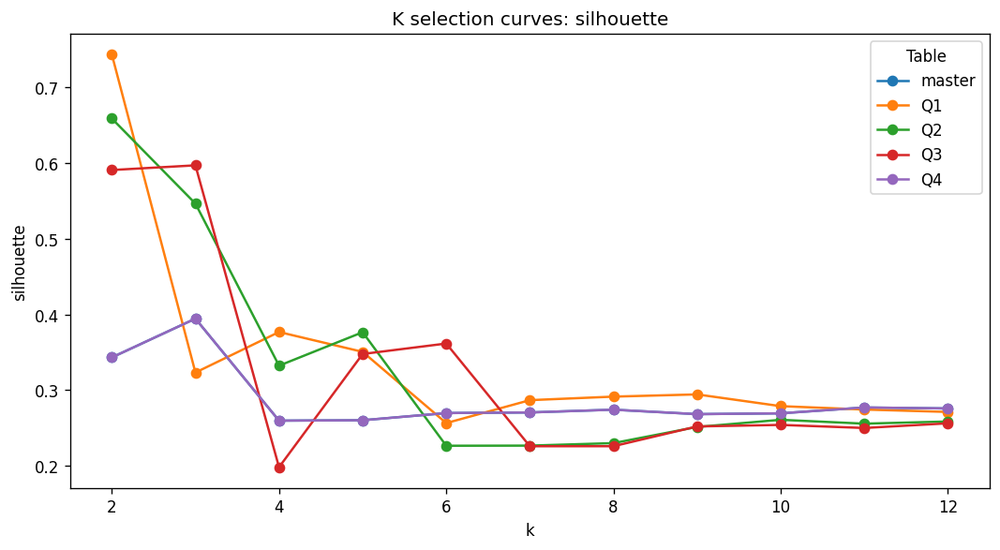

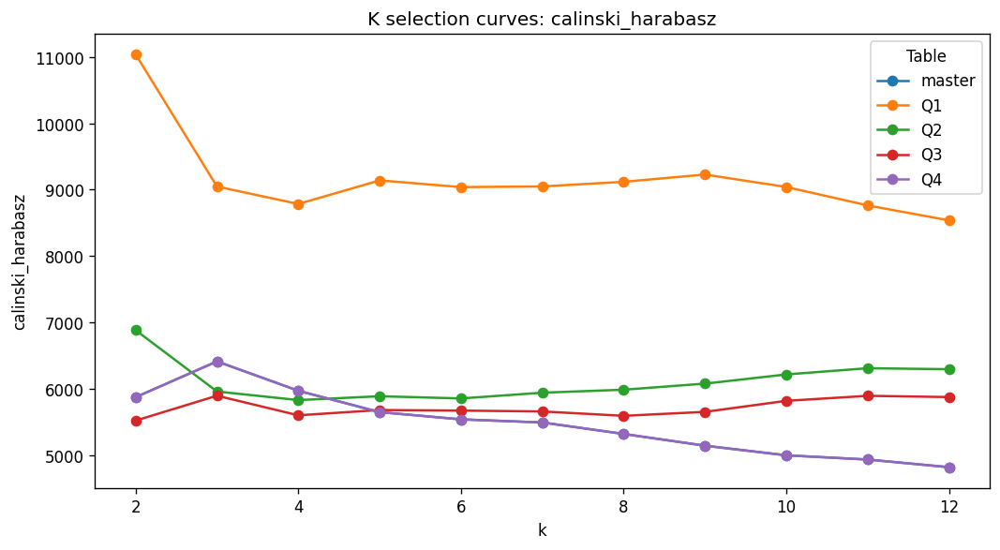

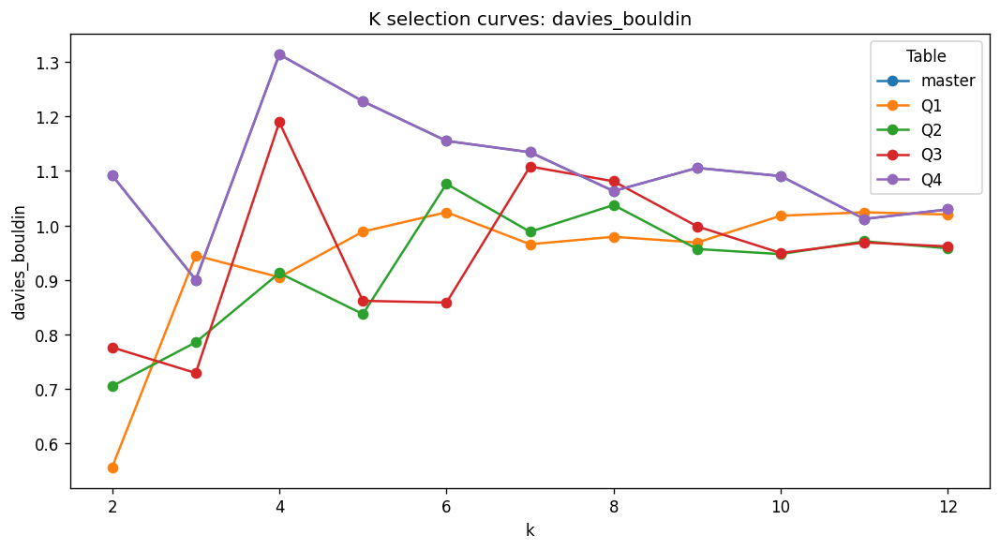

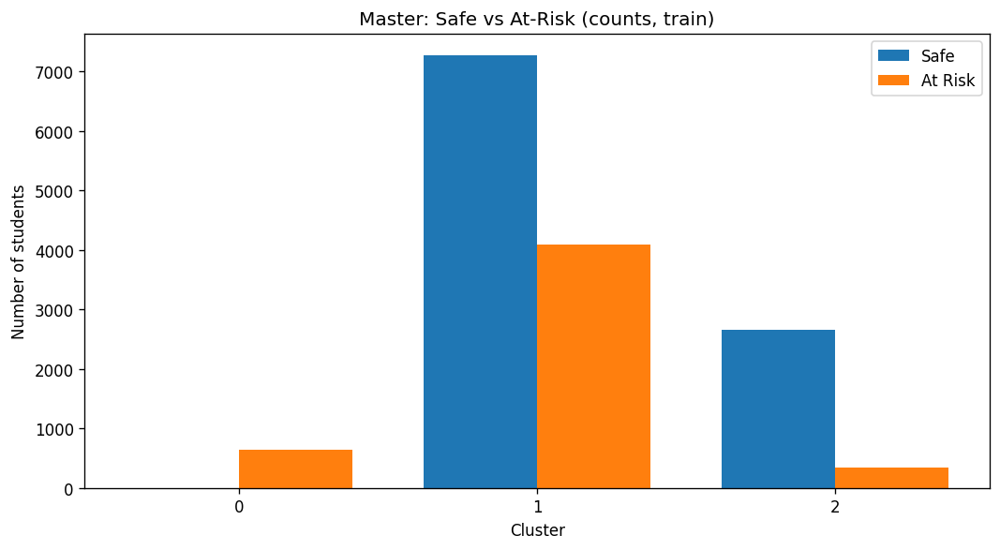

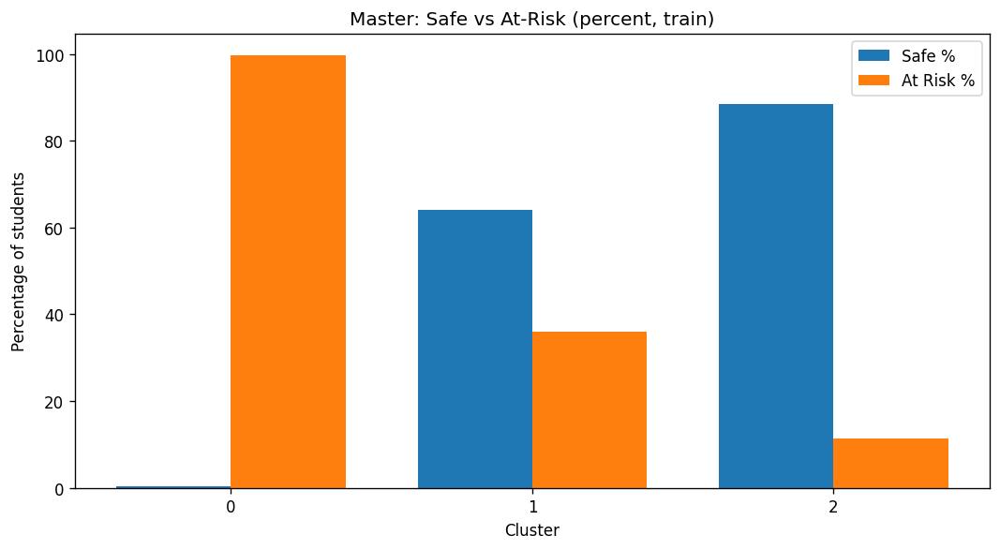

...

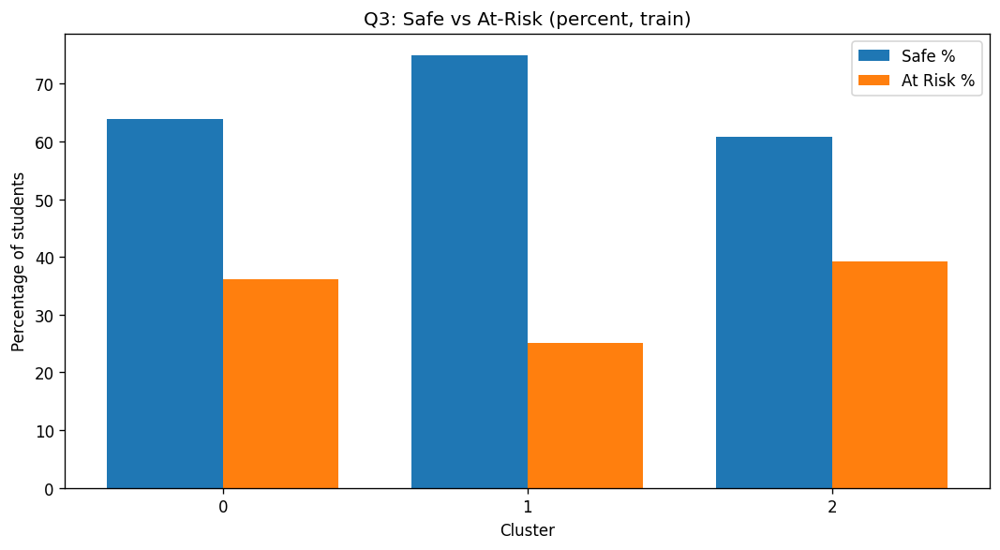

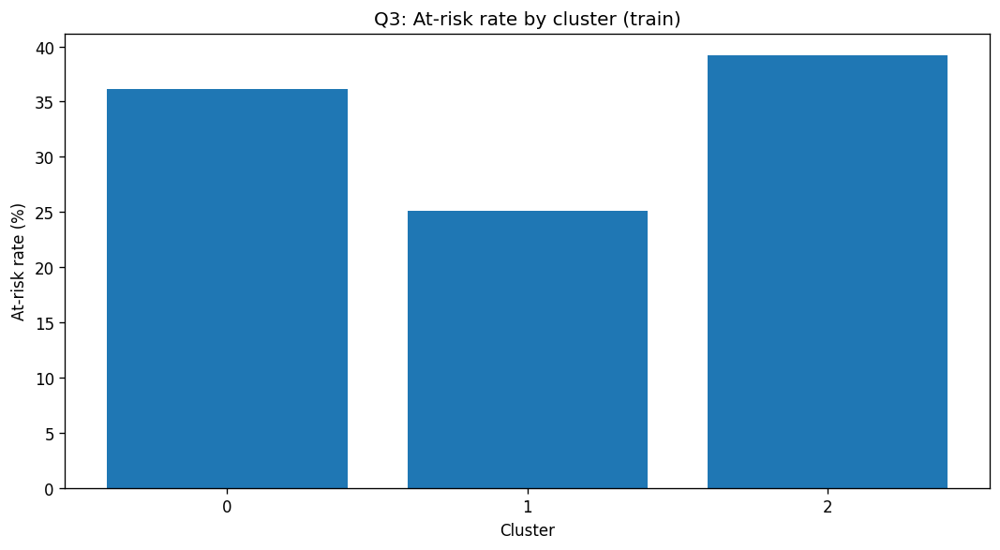

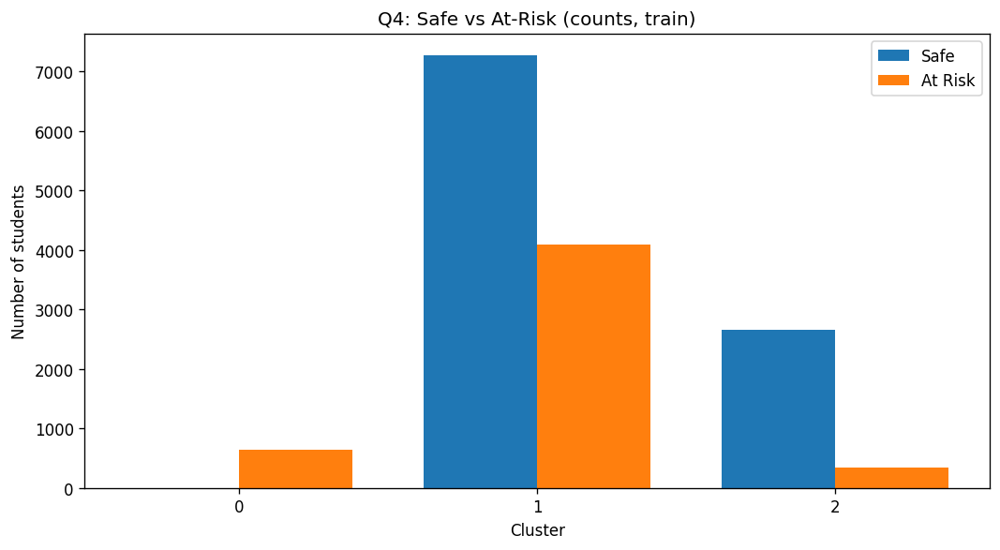

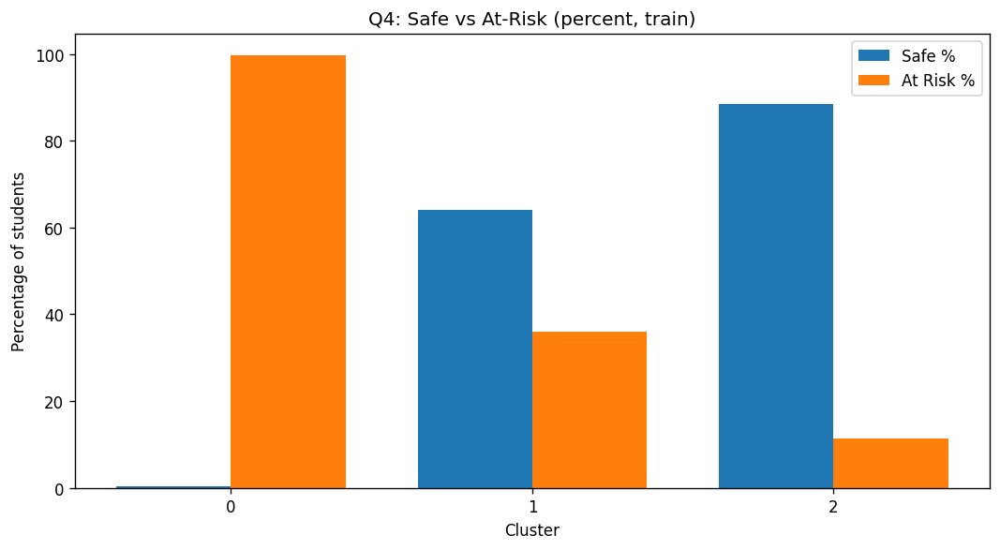

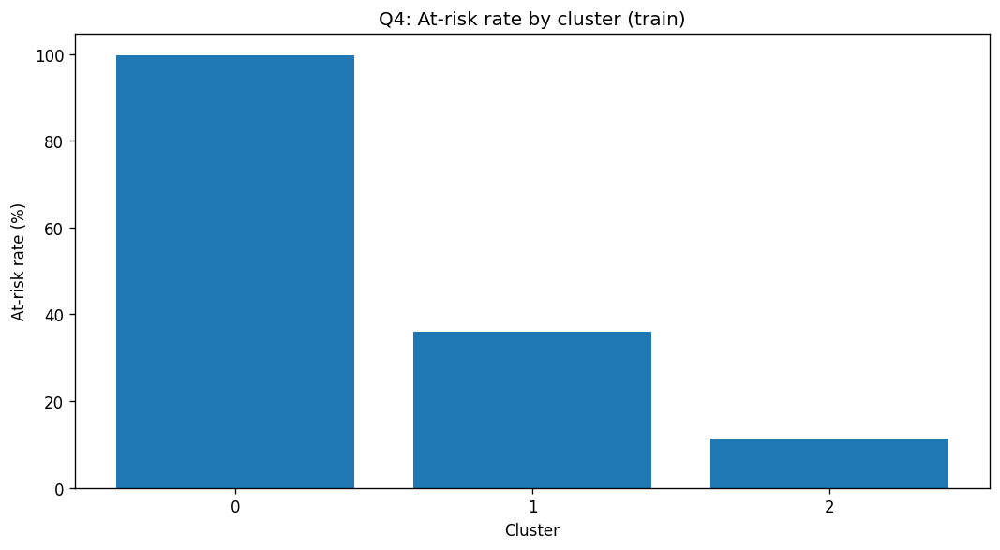

In [37]:
# Visualizatons for clustering

def _cluster_metrics_from_models(cluster_models: dict):
    rows = []
    for name, bundle in cluster_models.items():
        m = bundle.get("metrics", None)
        if m is None or len(m) == 0:
            continue
        m = m.copy()
        m["table"] = name
        rows.append(m)
    if not rows:
        return pd.DataFrame()
    out = pd.concat(rows, ignore_index=True)
    return out[["table","k","silhouette","calinski_harabasz","davies_bouldin"]]


def plot_k_selection_curves(cluster_models, tables=("master","Q1","Q2","Q3","Q4")):
    metrics_df = _cluster_metrics_from_models(cluster_models)
    if metrics_df.empty:
        print("No metrics found in cluster_models (bundle['metrics'] missing).")
        return

    for metric in ["silhouette", "calinski_harabasz", "davies_bouldin"]:
        plt.figure(figsize=(9,5))
        for t in tables:
            d = metrics_df[metrics_df["table"] == t].sort_values("k")
            if d.empty:
                continue
            plt.plot(d["k"], d[metric], marker="o", label=str(t))
        plt.title(f"K selection curves: {metric}")
        plt.xlabel("k")
        plt.ylabel(metric)
        plt.legend(title="Table")
        plt.tight_layout()
        plt.show()

def cluster_profiles_table(df, cluster_col, feature_cols, outcome_col="target_at_risk"):
    feats = safe_cols(df, feature_cols)
    base_cols = [cluster_col] + feats + ([outcome_col] if outcome_col in df.columns else [])
    base = df[base_cols].copy()

    for c in feats:
        base[c] = pd.to_numeric(base[c], errors="coerce").fillna(0.0)

    prof = base.groupby(cluster_col)[feats].mean()
    n = base.groupby(cluster_col).size().rename("n_students")
    out = prof.merge(n, left_index=True, right_index=True)

    if outcome_col in base.columns:
        at_risk = base.groupby(cluster_col)[outcome_col].mean().rename("at_risk_%") * 100.0
        out = out.merge(at_risk, left_index=True, right_index=True)

    return out.sort_index()



def plot_cluster_heatmap_with_values(df, cluster_col, feature_cols, title):
    
    profile = (
        df.groupby(cluster_col)[feature_cols]
        .mean()
        .sort_index()
    )

    plt.figure(figsize=(10,5))
    sns.heatmap(
        profile,
        annot=True,         
        fmt=".2f",          
        cmap="coolwarm",
        linewidths=0.5
    )

    plt.title(title)
    plt.xlabel("Features")
    plt.ylabel("Cluster")
    plt.tight_layout()
    plt.show()

def plot_safe_risk_side_by_side(df, cluster_col, title, outcome_col="target_at_risk"):
    dist = (
        df.groupby([cluster_col, outcome_col])
        .size()
        .unstack(fill_value=0)
        .sort_index()
    )
    if 0 not in dist.columns: dist[0] = 0
    if 1 not in dist.columns: dist[1] = 0
    dist = dist[[0,1]]
    dist.columns = ["Safe", "At_Risk"]

    clusters = dist.index.astype(str).tolist()
    x = np.arange(len(clusters))
    w = 0.38

    plt.figure(figsize=(9,5))
    plt.bar(x - w/2, dist["Safe"].to_numpy(), w, label="Safe")
    plt.bar(x + w/2, dist["At_Risk"].to_numpy(), w, label="At Risk")
    plt.xticks(x, clusters)
    plt.xlabel("Cluster")
    plt.ylabel("Number of students")
    plt.title(title)
    plt.legend()
    plt.tight_layout()
    plt.show()

def plot_safe_risk_side_by_side_pct(df, cluster_col, title, outcome_col="target_at_risk"):
    dist = (
        df.groupby([cluster_col, outcome_col])
        .size()
        .unstack(fill_value=0)
        .sort_index()
    )
    if 0 not in dist.columns: dist[0] = 0
    if 1 not in dist.columns: dist[1] = 0
    dist = dist[[0,1]]
    dist = dist.div(dist.sum(axis=1).replace(0, np.nan), axis=0).fillna(0.0) * 100.0
    dist.columns = ["Safe_%", "At_Risk_%"]

    clusters = dist.index.astype(str).tolist()
    x = np.arange(len(clusters))
    w = 0.38

    plt.figure(figsize=(9,5))
    plt.bar(x - w/2, dist["Safe_%"].to_numpy(), w, label="Safe %")
    plt.bar(x + w/2, dist["At_Risk_%"].to_numpy(), w, label="At Risk %")
    plt.xticks(x, clusters)
    plt.xlabel("Cluster")
    plt.ylabel("Percentage of students")
    plt.title(title)
    plt.legend()
    plt.tight_layout()
    plt.show()

def plot_risk_rate_by_cluster(df, cluster_col, title, outcome_col="target_at_risk"):
    rate = df.groupby(cluster_col)[outcome_col].mean().sort_index() * 100.0
    clusters = rate.index.astype(str).tolist()
    x = np.arange(len(clusters))

    plt.figure(figsize=(9,5))
    plt.bar(x, rate.to_numpy())
    plt.xticks(x, clusters)
    plt.xlabel("Cluster")
    plt.ylabel("At-risk rate (%)")
    plt.title(title)
    plt.tight_layout()
    plt.show()


def visualize_all(ml_master_train, ml_Q1_train, ml_Q2_train, ml_Q3_train, ml_Q4_train,
                  CLUSTERING_FEATURES, CLUSTER_FEATURES_Q,
                  cluster_models=None):

    if cluster_models is not None:
        plot_k_selection_curves(cluster_models, tables=("master","Q1","Q2","Q3","Q4"))

    plot_safe_risk_side_by_side(
        ml_master_train, "cluster_master_id",
        "Master: Safe vs At-Risk (counts, train)"
    )
    plot_safe_risk_side_by_side_pct(
        ml_master_train, "cluster_master_id",
        "Master: Safe vs At-Risk (percent, train)"
    )
    plot_risk_rate_by_cluster(
        ml_master_train, "cluster_master_id",
        "Master: At-risk rate by cluster (train)"
    )

    quarter_map = {
        "Q1": (ml_Q1_train, "cluster_Q1_id"),
        "Q2": (ml_Q2_train, "cluster_Q2_id"),
        "Q3": (ml_Q3_train, "cluster_Q3_id"),
        "Q4": (ml_Q4_train, "cluster_Q4_id"),
    }
    for q, (df, ccol) in quarter_map.items():
        plot_safe_risk_side_by_side(
            df, ccol,
            f"{q}: Safe vs At-Risk (counts, train)"
        )
        plot_safe_risk_side_by_side_pct(
            df, ccol,
            f"{q}: Safe vs At-Risk (percent, train)"
        )
        plot_risk_rate_by_cluster(
            df, ccol,
            f"{q}: At-risk rate by cluster (train)"
        )


visualize_all(
    ml_master_train, ml_Q1_train, ml_Q2_train, ml_Q3_train, ml_Q4_train,
    CLUSTERING_FEATURES, CLUSTER_FEATURES_Q,
    cluster_models=cluster_models 
)

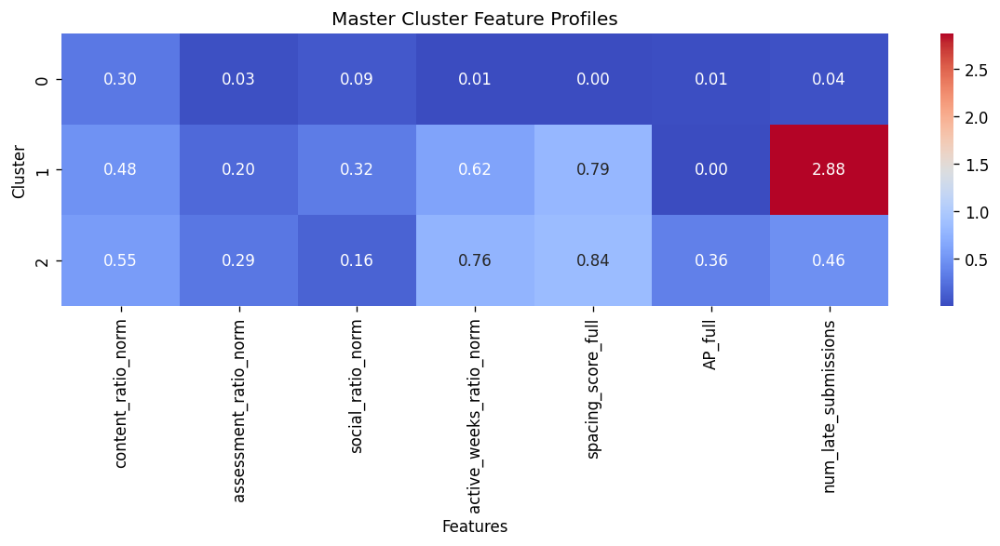

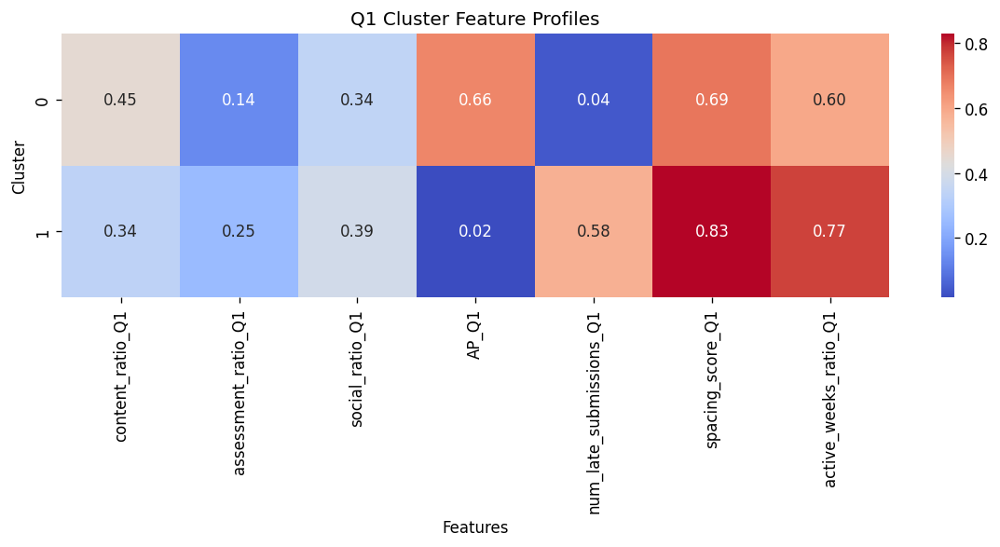

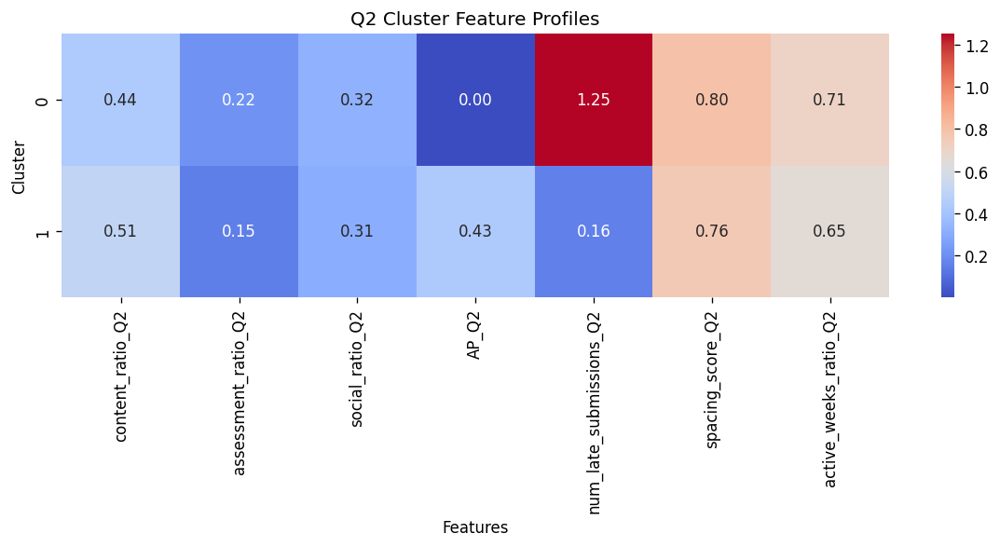

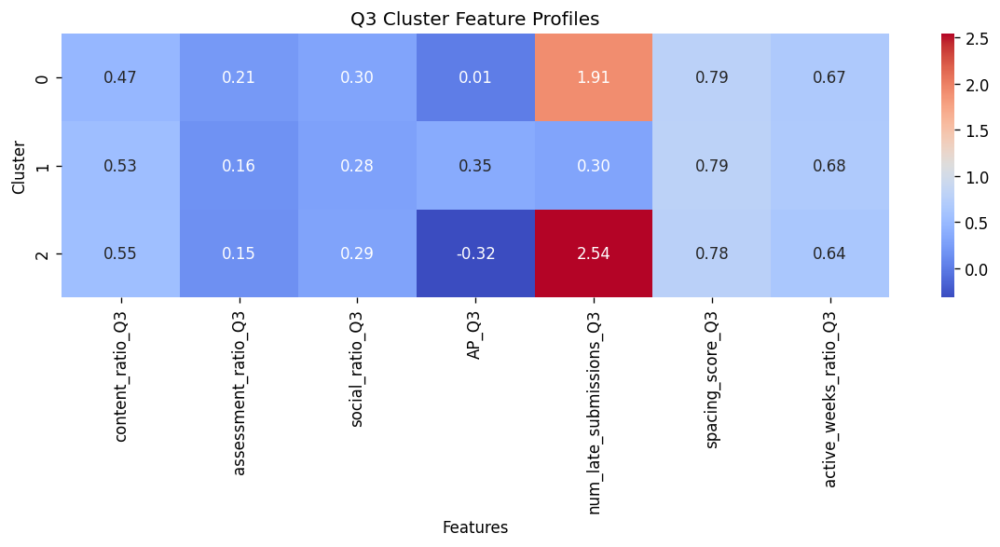

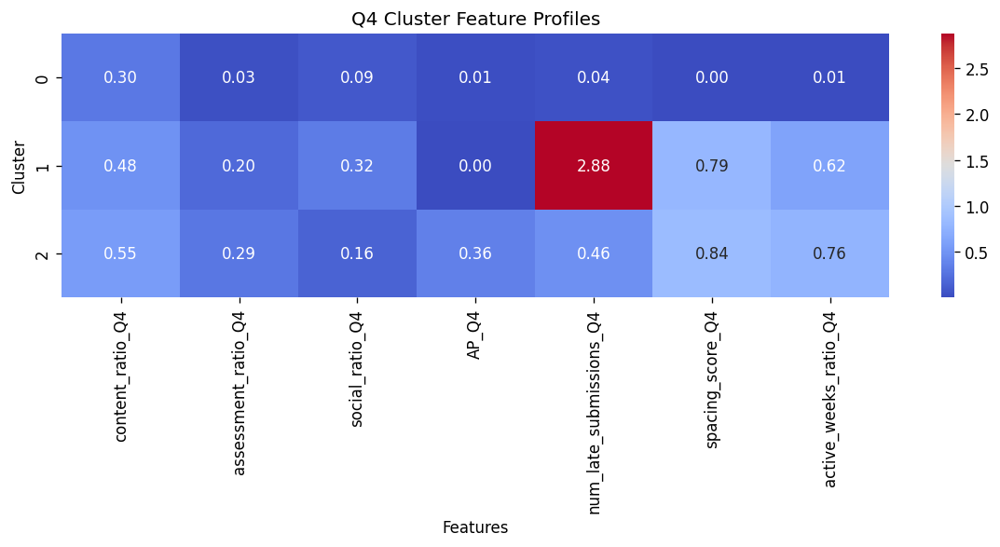

In [38]:
# Visualizations for clusters 
def plot_cluster_heatmap(df, cluster_col, feature_cols, title):
    profile = (
        df.groupby(cluster_col)[feature_cols]
        .mean()
    )

    plt.figure(figsize=(10,5))
    sns.heatmap(profile, annot=True, fmt=".2f", cmap="coolwarm")
    plt.title(title)
    plt.xlabel("Features")
    plt.ylabel("Cluster")
    plt.tight_layout()
    plt.show()

plot_cluster_heatmap(
    df=ml_master_train,
    cluster_col="cluster_master_id",
    feature_cols=CLUSTERING_FEATURES,
    title="Master Cluster Feature Profiles"
)

plot_cluster_heatmap(
    ml_Q1_train,
    cluster_col="cluster_Q1_id",
    feature_cols=CLUSTER_FEATURES_Q["Q1"],
    title="Q1 Cluster Feature Profiles"
)

plot_cluster_heatmap(
    ml_Q2_train,
    cluster_col="cluster_Q2_id",
    feature_cols=CLUSTER_FEATURES_Q["Q2"],
    title="Q2 Cluster Feature Profiles"
)

plot_cluster_heatmap(
    ml_Q3_train,
    cluster_col="cluster_Q3_id",
    feature_cols=CLUSTER_FEATURES_Q["Q3"],
    title="Q3 Cluster Feature Profiles"
)

plot_cluster_heatmap(
    ml_Q4_train,
    cluster_col="cluster_Q4_id",
    feature_cols=CLUSTER_FEATURES_Q["Q4"],
    title="Q4 Cluster Feature Profiles"
)

## ML Model

In [39]:
# Limit PyTorch to a single CPU thread for consistent performance
torch.set_num_threads(1)

sns.set_style("whitegrid")
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False
})

# Define key identifier columns and target label
KEYS   = ["id_student", "code_module", "code_presentation"]

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("\nClass balance (train):")
print(ml_master_train[TARGET].value_counts())
print(ml_master_train[TARGET].value_counts(normalize=True).round(3))


Class balance (train):
target_at_risk
0    9928
1    5073
Name: count, dtype: int64
target_at_risk
0    0.662
1    0.338
Name: proportion, dtype: float64


In [40]:
# Function to extract feature columns by excluding identifier keys and target label
def get_feature_cols(df):
    return [c for c in df.columns if c not in KEYS + [TARGET] and not any(
        bad in c.lower() for bad in ["unregistration", "enrolled_at_checkpoint", "final_result", "checkpoint_day"])]


# Define modelling windows
# Each window contains:
# - training dataset
# - test dataset
# - list of feature columns used for modelling
WINDOWS = {
    "Q1": {
        "train": ml_Q1_train,
        "test":  ml_Q1_test,
        "features": get_feature_cols(ml_Q1_train),
    },
    "Q2": {
        "train": ml_Q2_train,
        "test":  ml_Q2_test,
        "features": get_feature_cols(ml_Q2_train),
    },
    "Q3": {
        "train": ml_Q3_train,
        "test":  ml_Q3_test,
        "features": get_feature_cols(ml_Q3_train),
    },
    "Master": {
        "train": ml_master_train,
        "test":  ml_master_test,
        "features": get_feature_cols(ml_master_train),
    },
}


# Display dataset summary for each modelling window
print("Windows:")
for label, w in WINDOWS.items():
    print(
        f"  {label:10s}  "
        f"train={len(w['train']):,}  "
        f"test={len(w['test']):,}  "
        f"features={len(w['features'])}"
    )


# Display the presentations used as the held-out test set
print("\nTest presentations (held out per module):")
print(test_presentations.to_string(index=False))

Windows:
  Q1          train=17,462  test=8,703  features=39
  Q2          train=16,343  test=8,121  features=39
  Q3          train=15,456  test=7,623  features=41
  Master      train=15,001  test=7,521  features=41

Test presentations (held out per module):
code_module code_presentation
        AAA             2014J
        BBB             2014J
        CCC             2014J
        DDD             2014J
        EEE             2014J
        FFF             2014J
        GGG             2014J


In [41]:
# Remove highly correlated features to reduce multicollinearity
def correlation_filter(X_df, features, threshold=0.85, verbose=True):

    # Extract feature subset
    X = X_df[features].copy()

    # Compute absolute Pearson correlation matrix
    corr_matrix = X.corr().abs()

    # Keep only the upper triangle of the matrix to avoid duplicate pairs
    upper = corr_matrix.where(
        np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
    )

    # Store highly correlated feature pairs
    high_corr_pairs = []

    # Track features that should be removed
    to_drop = set()

    # Identify feature pairs exceeding the correlation threshold
    for col in upper.columns:
        correlated_with_col = upper.index[upper[col] > threshold].tolist()
        for row in correlated_with_col:
            high_corr_pairs.append((row, col, upper.loc[row, col]))
            to_drop.add(col)  # drop the later feature

    # Keep only non-correlated features
    kept = [f for f in features if f not in to_drop]

    # Print summary if verbose mode is enabled
    if verbose:
        print(f"    Correlation filter: {len(features)} -> {len(kept)}")

        if high_corr_pairs:
            print("    Highly correlated pairs:")
            for f1, f2, corr_val in sorted(high_corr_pairs, key=lambda x: -x[2]):
                print(f"      {f1} vs {f2} : r = {corr_val:.3f}")
        else:
            print("    No highly correlated pairs found.")

        if to_drop:
            print(f"    Dropped features: {sorted(to_drop)}")

    # Return filtered feature list, correlation matrix, and detected pairs
    return kept, corr_matrix, high_corr_pairs

In [42]:
SELECTED_FEATURES = {}
SELECTION_SUMMARY = []
CORR_INFO = {}

for window_label, w in WINDOWS.items():
    print(f"\n{'='*55}")
    print(f"  Feature selection — {window_label}")
    print(f"{'='*55}")

    train_df = w["train"]
    features = w["features"]

    # train only
    X_train = train_df[features].fillna(0)

    kept, corr_matrix, high_corr_pairs = correlation_filter(
        X_train,
        features,
        threshold=0.85,
        verbose=True
    )

    SELECTED_FEATURES[window_label] = kept
    CORR_INFO[window_label] = {
        "corr_matrix": corr_matrix,
        "high_corr_pairs": high_corr_pairs
    }

    SELECTION_SUMMARY.append({
        "Window": window_label,
        "Original": len(features),
        "Final": len(kept),
        "Dropped": sorted(list(set(features) - set(kept))),
        "Selected": kept,
    })

summary_df = pd.DataFrame(SELECTION_SUMMARY)

print("\n" + "="*55)
print("FEATURE SELECTION SUMMARY")
print("="*55)
print(summary_df[["Window", "Original", "Final"]].to_string(index=False))


  Feature selection — Q1
    Correlation filter: 39 -> 33
    Highly correlated pairs:
      cluster_Q1_id vs cluster_Q1_1 : r = 1.000
      cluster_Q1_id vs cluster_Q1_0 : r = 1.000
      cluster_Q1_0 vs cluster_Q1_1 : r = 1.000
      AP_Q1 vs cluster_Q1_dist_0 : r = 0.927
      spacing_score_Q1 vs active_weeks_ratio_Q1 : r = 0.889
      active_weeks_ratio_Q1 vs week_entropy_norm_Q1 : r = 0.876
      spacing_score_Q1 vs spacing_defined_Q1 : r = 0.858
    Dropped features: ['active_weeks_ratio_Q1', 'cluster_Q1_0', 'cluster_Q1_1', 'cluster_Q1_dist_0', 'spacing_defined_Q1', 'week_entropy_norm_Q1']

  Feature selection — Q2
    Correlation filter: 39 -> 35
    Highly correlated pairs:
      cluster_Q2_id vs cluster_Q2_0 : r = 1.000
      cluster_Q2_id vs cluster_Q2_1 : r = 1.000
      cluster_Q2_0 vs cluster_Q2_1 : r = 1.000
      active_weeks_ratio_Q2 vs week_entropy_norm_Q2 : r = 0.923
      norm_total_Q2 vs norm_content_Q2 : r = 0.870
    Dropped features: ['cluster_Q2_0', 'cluster_Q2

In [43]:
# Define models used for classification

def make_models(spw=1.0):
    return {

        "Logistic Regression": Pipeline([
            ("scaler", RobustScaler()),
            ("clf", LogisticRegression(
                class_weight="balanced",
                max_iter=1000,
                random_state=42
            ))
        ]),

        "SVM": Pipeline([
            ("scaler", RobustScaler()),
            ("clf", SVC(
                kernel="rbf",
                class_weight="balanced",
                probability=True,
                C=1.0,
                random_state=42
            ))
        ]),

        "Random Forest": Pipeline([
            ("scaler", RobustScaler()),
            ("clf", RandomForestClassifier(
                n_estimators=300,
                max_depth=8,
                min_samples_leaf=10,
                min_samples_split=20,
                max_features="sqrt",
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            ))
        ]),

        "XGBoost": Pipeline([
            ("scaler", RobustScaler()),
            ("clf", XGBClassifier(
                n_estimators=300,
                learning_rate=0.05,
                max_depth=3,
                subsample=0.7,
                colsample_bytree=0.7,
                reg_alpha=0.5,
                reg_lambda=2.0,
                scale_pos_weight=spw,
                random_state=42,
                eval_metric="logloss",
                verbosity=0
            ))
        ]),

        "MLP": Pipeline([
            ("scaler", RobustScaler()),
            ("clf", MLPClassifier(
                hidden_layer_sizes=(128,),
                alpha=0.001,
                learning_rate_init=0.001,
                max_iter=200,
                early_stopping=True,
                validation_fraction=0.1,
                random_state=42
            ))
        ]),
    }


# Evaluate model performance and return metrics

def score_row(name, model, X_te, y_te, window_label, features, y_prob=None):

    # Generate predictions
    y_pred = model.predict(X_te)

    # Compute predicted probabilities if not already provided
    if y_prob is None:
        y_prob = model.predict_proba(X_te)[:, 1]

    # Compute evaluation metrics
    row = {
        "Window":    window_label,
        "Model":     name,
        "Accuracy":  round(accuracy_score(y_te, y_pred), 4),
        "Precision": round(precision_score(y_te, y_pred, zero_division=0), 4),
        "Recall":    round(recall_score(y_te, y_pred, zero_division=0), 4),
        "F1":        round(f1_score(y_te, y_pred, zero_division=0), 4),
        "ROC-AUC":   round(roc_auc_score(y_te, y_prob), 4),

        # Store objects for later analysis (e.g., plots or explanations)
        "_model":    model,
        "_X_te":     X_te,
        "_y_te":     y_te,
        "_features": features,
        "_y_prob":   y_prob,
    }

    # Print model performance summary
    print(
        f"    {name:22s}  "
        f"Acc={row['Accuracy']:.3f}  "
        f"Prec={row['Precision']:.3f}  "
        f"Rec={row['Recall']:.3f}  "
        f"F1={row['F1']:.3f}  "
        f"AUC={row['ROC-AUC']:.3f}"
    )

    return row


# Confirm model definitions are ready
print("Models defined.")

Models defined.


In [44]:
# Run cross-validation on training data to estimate model performance
# Uses GroupKFold otherwise defaults to StratifiedKFold

def run_cross_validation(window_label, X_tr, y_tr, spw, groups=None):
    """
    CV on train data.
    If groups provided -> GroupKFold by module-presentation.
    Otherwise -> StratifiedKFold.
    """

    # Choose cross-validation strategy
    if groups is not None:
        # Count unique module–presentation groups
        unique_groups = pd.Series(groups).nunique()

        # Limit folds based on number of available groups
        n_splits = min(3, unique_groups)

        if n_splits < 2:
            raise ValueError(
                f"Not enough unique groups for GroupKFold in {window_label}. "
                f"Found only {unique_groups} unique groups."
            )

        # Group-aware CV prevents leakage across course presentations
        cv = GroupKFold(n_splits=n_splits)
        print(f"\n    --- GroupKFold CV on train cohort ({n_splits} folds, module-presentation groups) ---")

    else:
        # Standard stratified CV maintaining class distribution
        cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
        print(f"\n    --- Stratified 5-Fold CV on train cohort ---")


    # Initialize models with class imbalance weight
    models = make_models(spw=spw)

    cv_rows = []

    # Evaluate each model using cross-validation
    for name, model in models.items():

        cv_results = cross_validate(
            model,
            X_tr,
            y_tr,
            cv=cv,
            groups=groups,
            scoring={
                "f1": "f1",
                "roc_auc": "roc_auc",
                "recall": "recall",
            },
            return_train_score=True,
            n_jobs=-1
        )

        # Aggregate CV performance metrics
        row = {
            "Window": window_label,
            "Model": name,

            "CV F1": round(cv_results["test_f1"].mean(), 4),
            "CV F1 Std": round(cv_results["test_f1"].std(), 4),

            "CV AUC": round(cv_results["test_roc_auc"].mean(), 4),
            "CV AUC Std": round(cv_results["test_roc_auc"].std(), 4),

            "CV Recall": round(cv_results["test_recall"].mean(), 4),

            # Training performance for overfitting analysis
            "Train AUC": round(cv_results["train_roc_auc"].mean(), 4),

            # Gap between training and validation performance
            "Overfit Gap": round(
                cv_results["train_roc_auc"].mean() - cv_results["test_roc_auc"].mean(), 4
            ),
        }

        cv_rows.append(row)

        # Simple overfitting indicator
        status = "OK" if row["Overfit Gap"] < 0.05 else "OVERFIT"

        print(
            f"    {name:22s}  "
            f"CV_AUC={row['CV AUC']:.3f}(+/-{row['CV AUC Std']:.3f})  "
            f"CV_F1={row['CV F1']:.3f}  "
            f"Gap={row['Overfit Gap']:.3f}  {status}"
        )

    # Return CV summary table
    return pd.DataFrame(cv_rows)

In [45]:
# Set random seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)


# Multi-Layer Perceptron architecture for tabular classification

class MLP(nn.Module):
    def __init__(self, input_dim):
        super().__init__()

        # Feedforward neural network with batch normalization and dropout
        self.net = nn.Sequential(
            nn.Linear(input_dim, 128),   # input layer
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(128, 64),          # hidden layer
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(64, 32),           # hidden layer
            nn.ReLU(),

            nn.Linear(32, 1)             # output layer (logit)
        )

    def forward(self, x):
        return self.net(x).squeeze(1)    # return logits


# Train MLP model with validation monitoring and early stopping

def train_mlp(X_tr, y_tr, X_te, y_te,
              epochs=40, batch_size=1024, lr=3e-3, patience=5):

    # Reproducibility
    torch.manual_seed(42)
    np.random.seed(42)

    # Print dataset statistics
    print(f"      [MLP] Input shape: {X_tr.shape} | pos={y_tr.sum()} neg={(y_tr==0).sum()}")

    # Train / Validation split
    print(f"      [MLP] Splitting train/val...")
    X_tr_inner, X_val, y_tr_inner, y_val = train_test_split(
        X_tr, y_tr, test_size=0.10, random_state=42, stratify=y_tr
    )

    print(f"      [MLP] Train inner: {X_tr_inner.shape} | Val: {X_val.shape}")

    # Feature scaling
    print(f"      [MLP] Scaling...")
    scaler = RobustScaler()

    X_tr_s = scaler.fit_transform(X_tr_inner)
    X_val_s = scaler.transform(X_val)
    X_te_s  = scaler.transform(X_te)

    # Handle class imbalance using positive class weighting
    pos_weight = torch.tensor(
        [(y_tr_inner == 0).sum() / max((y_tr_inner == 1).sum(), 1)],
        dtype=torch.float32
    ).to(device)

    print(f"      [MLP] pos_weight: {pos_weight.item():.3f}")

    # Build training DataLoader
    print(f"      [MLP] Building DataLoader (batch_size={batch_size})...")

    train_loader = DataLoader(
        TensorDataset(
            torch.tensor(X_tr_s, dtype=torch.float32),
            torch.tensor(y_tr_inner, dtype=torch.float32)
        ),
        batch_size=batch_size,
        shuffle=True,
        num_workers=0,
    )

    print(f"      [MLP] Batches per epoch: {len(train_loader)}")

    # Initialize model, loss, optimizer
    model = MLP(X_tr.shape[1]).to(device)

    print(f"      [MLP] Model on device: {device}")

    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)

    # Early stopping variables
    best_state   = None
    best_val_auc = -np.inf
    wait         = 0

    X_val_t = torch.tensor(X_val_s, dtype=torch.float32).to(device)

    print(f"      [MLP] Starting training loop ({epochs} max epochs, patience={patience})...")

    # Training loop

    for epoch in range(epochs):

        model.train()
        epoch_loss = 0.0

        for xb, yb in train_loader:

            xb, yb = xb.to(device), yb.to(device)

            optimizer.zero_grad()

            logits = model(xb)
            loss   = criterion(logits, yb)

            loss.backward()
            optimizer.step()

            epoch_loss += loss.item()

        # Validation evaluation
        model.eval()

        with torch.no_grad():
            val_logits = model(X_val_t)
            val_prob   = torch.sigmoid(val_logits).cpu().numpy()

        val_auc = roc_auc_score(y_val, val_prob)

        print(f"      [MLP] Epoch {epoch+1:>3}/{epochs}  "
              f"loss={epoch_loss/len(train_loader):.4f}  "
              f"val_auc={val_auc:.4f}  "
              f"wait={wait}/{patience}")

        # Save best model
        if val_auc > best_val_auc:
            best_val_auc = val_auc
            best_state   = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            wait         = 0
        else:
            wait += 1

        # Early stopping condition
        if wait >= patience:
            print(f"      [MLP] Early stopping at epoch {epoch+1} "
                  f"(best val_auc={best_val_auc:.4f})")
            break

    # Final inference on full train and test sets
    print(f"      [MLP] Training done. Running final inference...")

    model.load_state_dict(best_state)
    model.eval()

    with torch.no_grad():

        tr_logits = model(torch.tensor(
            scaler.transform(X_tr), dtype=torch.float32).to(device))

        te_logits = model(torch.tensor(
            X_te_s, dtype=torch.float32).to(device))

        # Convert logits to probabilities
        y_prob_tr = torch.sigmoid(tr_logits).cpu().numpy()
        y_prob_te = torch.sigmoid(te_logits).cpu().numpy()

    print(f"      [MLP] Done")

    return y_prob_tr, y_prob_te

In [46]:
# Leakage-safe presentation groups and out-of-fold threshold calibration.
from sklearn.model_selection import GroupShuffleSplit, GroupKFold

def presentation_groups(frame):
    required = {'code_module', 'code_presentation'}
    if not required.issubset(frame.columns):
        raise KeyError(f"Missing presentation identifiers: {required - set(frame.columns)}")
    return (frame['code_module'].astype(str) + '__' + frame['code_presentation'].astype(str)).to_numpy()

def grouped_holdout_indices(y, groups, test_size=0.15):
    if groups is None:
        raise ValueError('groups are mandatory: do not use row-random LSTM validation')
    groups = np.asarray(groups)
    if len(groups) != len(y) or len(np.unique(groups)) < 2:
        raise ValueError('Need at least two module-presentation groups for validation')
    splitter = GroupShuffleSplit(n_splits=20, test_size=test_size, random_state=42)
    for tr, va in splitter.split(np.zeros(len(y)), y, groups):
        if len(np.unique(np.asarray(y)[tr])) == 2 and len(np.unique(np.asarray(y)[va])) == 2:
            assert not (set(groups[tr]) & set(groups[va]))
            return tr, va
    raise ValueError('Could not find a grouped validation split containing both classes')

def grouped_oof_threshold(y, groups, predict_fold, n_splits=3):
    """Train each fold on other presentations, calibrate F1 on OOF probabilities only."""
    y = np.asarray(y).astype(int)
    groups = np.asarray(groups)
    n_splits = min(n_splits, len(np.unique(groups)))
    if n_splits < 2:
        raise ValueError('At least two presentations required for OOF threshold')
    oof = np.full(len(y), np.nan, dtype=float)
    for tr, va in GroupKFold(n_splits=n_splits).split(np.zeros(len(y)), y, groups):
        assert not (set(groups[tr]) & set(groups[va]))
        if len(np.unique(y[tr])) < 2:
            raise ValueError('OOF training fold contains a single class')
        oof[va] = np.asarray(predict_fold(tr, va)).reshape(-1)
    assert np.isfinite(oof).all(), 'Incomplete OOF probabilities'
    return find_best_threshold(y, oof, metric='f1')



def _rebuild_fold_caf_risk_prior(train_frame, valid_frame, risk_col, cluster_col, target_col, group_col_values):
    """Replace globally prepared CAF prior with fold-trained values.

    Training rows get leave-one-presentation-out cluster priors; the held-out
    validation presentation receives a prior derived only from fitting rows.
    """
    fit = train_frame.copy()
    valid = valid_frame.copy()
    y = fit[target_col].astype(float).to_numpy()
    groups = np.asarray(group_col_values)
    if len(groups) != len(fit):
        raise ValueError('Group length mismatch in CAF prior cross-fitting')
    cid = fit[cluster_col]
    global_fit_rate = float(np.mean(y))
    cluster_rates = fit.groupby(cluster_col)[target_col].mean()
    valid[risk_col] = valid[cluster_col].map(cluster_rates).fillna(global_fit_rate)
    # Each training presentation's prior is estimated from *other* presentations.
    fit_priors = np.full(len(fit), np.nan, dtype=float)
    for g in np.unique(groups):
        left_out = groups == g
        other = fit.loc[~left_out]
        if other.empty:
            raise ValueError('CAF fold has only one training presentation')
        rates = other.groupby(cluster_col)[target_col].mean()
        fallback = float(other[target_col].mean())
        fit_priors[left_out] = fit.loc[left_out, cluster_col].map(rates).fillna(fallback).to_numpy()
    fit[risk_col] = fit_priors
    assert np.isfinite(fit_priors).all()
    return fit, valid


def grouped_tabular_threshold(model, train_frame, features, target_col, *,
                              n_splits=3, caf_window=None, cluster_col=None):
    """Select a threshold from presentation-disjoint out-of-fold predictions.

    For CAF, replace cross-fitted prior for *each* CV fold, so the validation
    labels never contribute to that fold's risk-prior feature. The existing
    unsupervised cluster assignment remains based on overall train data; see
    notebook limitations about fully nested clustering.
    """
    from sklearn.base import clone
    y = train_frame[target_col].astype(int).to_numpy()
    groups = presentation_groups(train_frame)
    risk_col = f"caf_{caf_window.lower()}_risk_prior" if caf_window else None
    if risk_col and (cluster_col is None or cluster_col not in train_frame.columns):
        raise ValueError('Missing CAF cluster ID for fold-specific prior calculation')

    def predict_fold(tr, va):
        fit = train_frame.iloc[tr].copy()
        held = train_frame.iloc[va].copy()
        if risk_col:
            fit, held = _rebuild_fold_caf_risk_prior(
                fit, held, risk_col, cluster_col, target_col, groups[tr])
        x_fit = fit[features].fillna(0).to_numpy()
        x_held = held[features].fillna(0).to_numpy()
        est = clone(model)
        # Fit-fold-only scale_pos_weight for XGBoost, when applicable.
        candidate_keys = ('clf__scale_pos_weight', 'scale_pos_weight')
        for key in candidate_keys:
            if key in est.get_params(deep=True):
                y_fit = y[tr]
                est.set_params(**{key: float((y_fit == 0).sum()/max((y_fit == 1).sum(), 1))})
                break
        est.fit(x_fit, y[tr])
        return est.predict_proba(x_held)[:, 1]

    threshold, oof_f1 = grouped_oof_threshold(y, groups, predict_fold, n_splits=n_splits)
    return threshold, oof_f1


def caf_fold_hybrid_prediction(seq_train_frame, X_seq, y, static_cols,
                               window_label, train_idx, valid_idx, **train_kwargs):
    """Outer OOF CAF neural prediction; cluster-risk feature rebuilt per fold.

    Cluster assignments are from previously fitted unsupervised training clustering.
    The validation group labels are NEVER used to construct any fold priors.
    """
    cluster_col = CLUSTER_ID_COLS[window_label]
    risk_col = f'caf_{window_label.lower()}_risk_prior'
    groups = presentation_groups(seq_train_frame)
    if cluster_col not in seq_train_frame:
        raise KeyError(f'Missing {cluster_col} in hybrid CAF sequence table')
    fit, held = _rebuild_fold_caf_risk_prior(
        seq_train_frame.iloc[train_idx], seq_train_frame.iloc[valid_idx],
        risk_col, cluster_col, TARGET, groups[train_idx]
    )
    # Full rank, table-order aligned static arrays are required.
    train_static = fit[static_cols].to_numpy(dtype=np.float32)
    valid_static = held[static_cols].to_numpy(dtype=np.float32)
    return train_hybrid_seq_model(
        X_seq[train_idx], train_static, y[train_idx],
        X_seq[valid_idx], valid_static, y[valid_idx],
        groups=groups[train_idx],
        caf_cluster_ids=fit[cluster_col].to_numpy(),
        caf_risk_prior_index=static_cols.index(risk_col),
        **train_kwargs,
    )[1]


def caf_cv_fold_features(train_frame, train_idx, valid_idx, features, target_col,
                         cluster_col, caf_window):
    """Build classifier matrices with risk prior fit on each CV fitting fold."""
    groups = presentation_groups(train_frame)
    risk_col = f'caf_{caf_window.lower()}_risk_prior'
    fit, held = _rebuild_fold_caf_risk_prior(
        train_frame.iloc[train_idx], train_frame.iloc[valid_idx],
        risk_col, cluster_col, target_col, groups[train_idx]
    )
    return (fit[features].fillna(0).to_numpy(), held[features].fillna(0).to_numpy())


def run_cross_validation_caf(window_label, train_frame, features, spw):
    """CAF descriptive CV: folds do not use their validation labels in risk priors.

    Clustering is still fitted on overall training presentations outside CV,
    therefore this is not a fully nested representation-learning evaluation.
    """
    from sklearn.base import clone
    from sklearn.metrics import roc_auc_score, f1_score, recall_score
    y = train_frame[TARGET].astype(int).to_numpy()
    groups = presentation_groups(train_frame)
    splits = GroupKFold(n_splits=min(3, len(np.unique(groups))))
    fold_cache = []
    for tr, va in splits.split(np.zeros(len(y)), y, groups):
        if len(np.unique(y[tr])) < 2 or len(np.unique(y[va])) < 2:
            raise ValueError(f'CAF CV fold for {window_label} must contain both classes')
        x_fit, x_hold = caf_cv_fold_features(
            train_frame, tr, va, features, TARGET,
            CLUSTER_ID_COLS[window_label], window_label)
        fold_cache.append((tr, va, x_fit, x_hold))
    rows=[]
    for model_name, model in make_models(spw=spw).items():
        val_auc=[];tr_auc=[];val_f1=[];val_recall=[]
        for tr, va, x_fit, x_hold in fold_cache:
            m=clone(model)
            for key in ('clf__scale_pos_weight', 'scale_pos_weight'):
                if key in m.get_params(deep=True):
                    m.set_params(**{key: float((y[tr]==0).sum()/max((y[tr]==1).sum(),1))})
                    break
            m.fit(x_fit,y[tr])
            pr=m.predict_proba(x_hold)[:,1]
            p_tr=m.predict_proba(x_fit)[:,1]
            val_auc.append(roc_auc_score(y[va],pr))
            tr_auc.append(roc_auc_score(y[tr],p_tr))
            pred=pr>=0.5
            val_f1.append(f1_score(y[va],pred,zero_division=0))
            val_recall.append(recall_score(y[va],pred,zero_division=0))
        row={'Window':window_label,'Model':model_name,
             'CV F1':round(float(np.mean(val_f1)),4),
             'CV F1 Std':round(float(np.std(val_f1)),4),
             'CV AUC':round(float(np.mean(val_auc)),4),
             'CV AUC Std':round(float(np.std(val_auc)),4),
             'CV Recall':round(float(np.mean(val_recall)),4),
             'Train AUC':round(float(np.mean(tr_auc)),4),
             'Overfit Gap':round(float(np.mean(tr_auc)-np.mean(val_auc)),4)}
        rows.append(row)
        print(f"    {model_name:22s}  CAF fold-safe CV_AUC={row['CV AUC']:.3f}")
    return pd.DataFrame(rows)


def search_tuned_model_caf(pipe, param_grid, train_frame, features, target_col,
                           window_label):
    """Tune CAF hyperparameters with fold-specific, label-safe risk priors."""
    from sklearn.base import clone
    from sklearn.model_selection import ParameterGrid
    from sklearn.metrics import roc_auc_score
    y = train_frame[target_col].astype(int).to_numpy()
    groups=presentation_groups(train_frame)
    folds=[]
    for tr,va in GroupKFold(n_splits=min(3,len(np.unique(groups)))).split(np.zeros(len(y)),y,groups):
        if len(np.unique(y[tr]))!=2 or len(np.unique(y[va]))!=2:
            raise ValueError(f'Cannot tune {window_label}: missing a class in grouped CV')
        x_fit,x_held=caf_cv_fold_features(train_frame,tr,va,features,target_col,
                                          CLUSTER_ID_COLS[window_label],window_label)
        folds.append((tr,va,x_fit,x_held))
    best_score=-np.inf
    best_params=None
    candidates=list(ParameterGrid(param_grid))
    print(f'    CAF fold-safe grid: {len(candidates)} configurations x {len(folds)} folds')
    for idx,params in enumerate(candidates,1):
        fold_scores=[]
        for tr,va,x_fit,x_held in folds:
            m=clone(pipe).set_params(**params)
            if 'clf__scale_pos_weight' in m.get_params():
                m.set_params(clf__scale_pos_weight=float((y[tr]==0).sum()/max((y[tr]==1).sum(),1)))
            m.fit(x_fit,y[tr])
            fold_scores.append(roc_auc_score(y[va],m.predict_proba(x_held)[:,1]))
        avg=float(np.mean(fold_scores))
        if avg>best_score:
            best_score=avg
            best_params=dict(params)
        if idx % 50 == 0 or idx == len(candidates):
            print(f'      evaluated {idx}/{len(candidates)}; best fold-safe CV AUC={best_score:.4f}')
    best_model=clone(pipe).set_params(**best_params)
    best_model.fit(train_frame[features].fillna(0).to_numpy(),y)
    return best_model,best_params,best_score


In [47]:
# Set random seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)


# LSTM architecture for sequential engagement modelling

class LSTMModel(nn.Module):
    def __init__(self, input_size=3, hidden_size=64,
                 num_layers=2, dropout=0.3,
                 bidirectional=False, clf_hidden_dim=64):
        super().__init__()
        self.bidirectional = bidirectional

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0,
            bidirectional=bidirectional
        )

        factor = 2 if bidirectional else 1
        self.classifier = nn.Sequential(
            nn.Linear(hidden_size * factor, clf_hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(clf_hidden_dim, 1)
        )

    def forward(self, x):
        _, (h_n, _) = self.lstm(x)

        last = (
            torch.cat([h_n[-2], h_n[-1]], dim=1)
            if self.bidirectional else h_n[-1]
        )

        return self.classifier(last).squeeze(1)


# Convert weekly behavioural features into masked sequences
def build_sequences_masked(df, global_max_week, q_end_col):

    """
    Build fixed-length weekly sequences for LSTM.
    Weeks beyond each student's true quarter cutoff are masked to zero.
    """

    pat = re.compile(r"^wk(\d{2})_(content|assessment|social)_norm$")

    # Identify weekly columns
    weeks = sorted({
        int(pat.match(c).group(1))
        for c in df.columns
        if pat.match(c) and int(pat.match(c).group(1)) <= global_max_week
    })

    if not weeks:
        raise ValueError("No weekly normalized sequence columns found; check feature construction")

    n = len(df)

    # Sequence shape: (students, weeks, engagement dimensions)
    seq = np.zeros((n, len(weeks), 3), dtype=np.float32)

    # True quarter cutoff per student
    true_cutoffs = (
        df[q_end_col].values
        if q_end_col in df.columns
        else np.full(n, global_max_week)
    )

    for wi, wk in enumerate(weeks):

        # Retrieve weekly engagement features
        c = df.get(f"wk{wk:02d}_content_norm", pd.Series(0.0, index=df.index)).fillna(0).values
        a = df.get(f"wk{wk:02d}_assessment_norm", pd.Series(0.0, index=df.index)).fillna(0).values
        s = df.get(f"wk{wk:02d}_social_norm", pd.Series(0.0, index=df.index)).fillna(0).values

        # Mask weeks beyond each student's course quarter
        mask = (wk <= true_cutoffs).astype(np.float32)

        seq[:, wi, 0] = c * mask
        seq[:, wi, 1] = a * mask
        seq[:, wi, 2] = s * mask

    return seq   # shape: (n_students, n_weeks, 3)

def train_seq_model(
    X_tr, y_tr, X_te, y_te,
    bidirectional=False,
    hidden_size=64,
    num_layers=2,
    dropout=0.3,
    clf_hidden_dim=64,
    epochs=60,
    batch_size=512,
    lr=1e-3,
    patience=10,
    weight_decay=1e-4,
    return_val_auc=False,
    verbose=False,
    groups=None
):
    torch.manual_seed(42)
    np.random.seed(42)

    idx = np.arange(len(y_tr))
    tr_idx, val_idx = grouped_holdout_indices(y_tr, groups)

    X_tr_inner, y_tr_inner = X_tr[tr_idx], y_tr[tr_idx]
    X_val, y_val = X_tr[val_idx], y_tr[val_idx]

    mean = X_tr_inner.mean(axis=(0, 1), keepdims=True)
    std  = X_tr_inner.std(axis=(0, 1), keepdims=True) + 1e-8

    X_tr_s      = (X_tr_inner - mean) / std
    X_val_s     = (X_val - mean) / std
    X_te_s      = (X_te - mean) / std
    X_tr_full_s = (X_tr - mean) / std

    pos_weight = torch.tensor(
        [(y_tr_inner == 0).sum() / max((y_tr_inner == 1).sum(), 1)],
        dtype=torch.float32
    ).to(device)

    train_loader = DataLoader(
        TensorDataset(
            torch.tensor(X_tr_s, dtype=torch.float32),
            torch.tensor(y_tr_inner, dtype=torch.float32)
        ),
        batch_size=batch_size,
        shuffle=True
    )

    model = LSTMModel(
        input_size=X_tr.shape[2],
        hidden_size=hidden_size,
        num_layers=num_layers,
        dropout=dropout,
        bidirectional=bidirectional,
        clf_hidden_dim=clf_hidden_dim
    ).to(device)

    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

    best_state = None
    best_val_auc = -np.inf
    wait = 0

    X_val_t = torch.tensor(X_val_s, dtype=torch.float32).to(device)

    for epoch in range(epochs):
        model.train()
        epoch_loss = 0.0

        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)

            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()

            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

            epoch_loss += loss.item()

        model.eval()
        with torch.no_grad():
            val_logits = model(X_val_t)
            val_prob = torch.sigmoid(val_logits).cpu().numpy()

        val_auc = roc_auc_score(y_val, val_prob)

        if val_auc > best_val_auc:
            best_val_auc = val_auc
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            wait = 0
        else:
            wait += 1

        if verbose and (epoch + 1) % 10 == 0:
            print(f"Epoch {epoch+1}/{epochs} loss={epoch_loss/len(train_loader):.4f} val_auc={val_auc:.4f}")

        if wait >= patience:
            if verbose:
                print(f"Early stopping at epoch {epoch+1}")
            break

    if best_state is None:
        raise RuntimeError("LSTM validation did not produce a finite AUC; check sequence finiteness and group labels")
    model.load_state_dict(best_state)
    model.eval()

    with torch.no_grad():
        tr_logits = model(torch.tensor(X_tr_full_s, dtype=torch.float32).to(device))
        te_logits = model(torch.tensor(X_te_s, dtype=torch.float32).to(device))

        y_prob_tr = torch.sigmoid(tr_logits).cpu().numpy()
        y_prob_te = torch.sigmoid(te_logits).cpu().numpy()

    if return_val_auc:
        return y_prob_tr, y_prob_te, best_val_auc

    return y_prob_tr, y_prob_te


### Fix: sequence cutoff / enrollment merge collision
This cell attaches `q1_end`–`q4_end` idempotently. Enrollment filtering uses a separate status lookup and preserves existing sequence cutoff columns. Run from the beginning after updating the notebook.


In [48]:
# Attach course-specific quarter cutoffs to sequence data, without merge suffixes.
# Safe to re-run; keeps checkpoint masking aligned with the course presentation.
_CUTOFF_COLS = ["q1_end", "q2_end", "q3_end", "q4_end"]
_COURSE_KEYS = ["code_module", "code_presentation"]
_cutoffs = course_windows[_COURSE_KEYS + _CUTOFF_COLS].drop_duplicates(_COURSE_KEYS)
assert not _cutoffs.duplicated(_COURSE_KEYS).any(), "Duplicate course-window keys"

def ensure_sequence_cutoffs(df):
    out = df.drop(columns=_CUTOFF_COLS, errors="ignore").merge(
        _cutoffs, on=_COURSE_KEYS, how="left", validate="m:1"
    )
    if out[_CUTOFF_COLS].isna().any().any():
        raise ValueError("Missing course-specific sequence checkpoint cutoffs")
    assert len(out) == len(df), "Sequence cutoff merge changed row count"
    return out

ml_seq_train = ensure_sequence_cutoffs(ml_seq_train)
ml_seq_test = ensure_sequence_cutoffs(ml_seq_test)
print("Sequence checkpoint cutoffs ready:", _CUTOFF_COLS)
# Regression test: eligibility filtering must work with existing q*_end columns.
for _checkpoint in ("Q1", "Q2", "Q3", "Q4"):
    _filtered = enrolled_only_dataset(ml_seq_train, _checkpoint, enrollment_lookup, KEYS)
    assert set(_CUTOFF_COLS).issubset(_filtered.columns)
    assert not any(col.endswith(("_x", "_y")) for col in _filtered.columns if col.startswith("q"))
print("PASS: checkpoint filtering and sequence masking columns coexist")


Sequence checkpoint cutoffs ready: ['q1_end', 'q2_end', 'q3_end', 'q4_end']
PASS: checkpoint filtering and sequence masking columns coexist


In [49]:
# PRE-FLIGHT 1 — run before first neural training (fast, no fitting)
def _audit_grouped_class_windows(source_train, source_test):
    audit_windows = {"Q1": "q1_end", "Q2": "q2_end", "Q3": "q3_end", "Master": "q4_end"}
    for win, col in audit_windows.items():
        tr, te = checkpoint_sequence_pair(source_train, source_test, win)
        groups = presentation_groups(tr)
        if len(np.unique(groups)) < 3:
            raise ValueError(f"{win}: {len(np.unique(groups))} train presentations; grouped outer + inner validation needs >=3")
        if not ({0, 1} <= set(tr[TARGET].dropna().astype(int).unique())):
            raise ValueError(f"{win}: train set does not contain both target classes")
        if not ({0, 1} <= set(te[TARGET].dropna().astype(int).unique())):
            raise ValueError(f"{win}: held-out test set does not contain both classes")
        # Validate every OOF training fold, because it needs an inner grouped holdout.
        folds = GroupKFold(n_splits=min(3, len(np.unique(groups))))
        for fit, held in folds.split(np.zeros(len(tr)), tr[TARGET], groups):
            if len(set(groups[fit])) < 2 or len(set(groups[fit]) & set(groups[held])):
                raise ValueError(f"{win}: OOF group separation invalid")
            grouped_holdout_indices(tr[TARGET].to_numpy()[fit], groups[fit])
        if col not in tr.columns or col not in te.columns:
            raise KeyError(f"{win}: missing cutoff {col} in sequence train/test")
        print(f"PASS {win}: {len(tr)} train, {len(te)} test, {len(np.unique(groups))} presentations")
_audit_grouped_class_windows(ml_seq_train, ml_seq_test)


PASS Q1: 17462 train, 8703 test, 15 presentations
PASS Q2: 16343 train, 8121 test, 15 presentations
PASS Q3: 15456 train, 7623 test, 15 presentations
PASS Master: 15001 train, 7521 test, 15 presentations


In [50]:
# Determine maximum week length used for each modelling window
QUARTER_MAX_WEEKS = {
    "Q1":     int(course_windows["q1_end"].median()),   # typical Q1 length
    "Q2":     int(course_windows["q2_end"].median()),   # typical Q2 length
    "Q3":     int(course_windows["q3_end"].median()),   # typical Q3 length
    "Master": int(course_windows["q4_end"].max()),      # full course length
}
print("Quarter max weeks:", QUARTER_MAX_WEEKS)


# Threshold optimisation using training predictions
def find_best_threshold(y_true, y_prob, metric="f1"):

    # Search thresholds between 0.10 and 0.90
    thresholds = np.arange(0.10, 0.91, 0.02)

    best_thr = 0.50
    best_score = -1

    for thr in thresholds:

        # Convert probabilities to predictions
        y_pred = (y_prob >= thr).astype(int)

        # Compute chosen metric
        if metric == "f1":
            score = f1_score(y_true, y_pred, zero_division=0)
        elif metric == "recall":
            score = recall_score(y_true, y_pred, zero_division=0)
        elif metric == "precision":
            score = precision_score(y_true, y_pred, zero_division=0)
        else:
            raise ValueError("metric must be one of: f1, recall, precision")

        # Keep best-performing threshold
        if score > best_score:
            best_score = score
            best_thr = thr

    return best_thr, best_score


# Train model and obtain probability predictions
def fit_model_and_get_probs(model, X_tr, y_tr, X_te):

    model.fit(X_tr, y_tr)

    y_prob_tr = model.predict_proba(X_tr)[:, 1]  # train probabilities
    y_prob_te = model.predict_proba(X_te)[:, 1]  # test probabilities

    return model, y_prob_tr, y_prob_te


# Evaluate predictions using selected probability threshold
def score_probabilities(name, y_te, y_prob_te, window_label, features,
                        model_obj=None, X_te=None, threshold=0.5):

    # Convert probabilities to class predictions
    y_pred = (y_prob_te >= threshold).astype(int)

    row = {
        "Window": window_label,
        "Model": name,
        "Threshold": round(float(threshold), 3),

        "Accuracy": round(accuracy_score(y_te, y_pred), 4),
        "Precision": round(precision_score(y_te, y_pred, zero_division=0), 4),
        "Recall": round(recall_score(y_te, y_pred, zero_division=0), 4),
        "F1": round(f1_score(y_te, y_pred, zero_division=0), 4),
        "ROC-AUC": round(roc_auc_score(y_te, y_prob_te), 4),

        # Stored for later analysis/visualisation
        "_model": model_obj,
        "_X_te": X_te,
        "_y_te": y_te,
        "_features": features,
        "_y_prob": y_prob_te,
    }

    # Print performance summary
    print(
        f"    {name:22s}  "
        f"Thr={row['Threshold']:.2f}  "
        f"Acc={row['Accuracy']:.3f}  "
        f"Prec={row['Precision']:.3f}  "
        f"Rec={row['Recall']:.3f}  "
        f"F1={row['F1']:.3f}  "
        f"AUC={row['ROC-AUC']:.3f}"
    )

    return row


# Run modelling experiments across all time windows
all_cv_rows = []
all_test_rows = []

for window_label, w in WINDOWS.items():

    print(f"\n{'='*65}")
    print(f"  {window_label}")
    print(f"{'='*65}")

    # Extract selected features for this window
    features = SELECTED_FEATURES[window_label]
    train_df = w["train"]
    test_df = w["test"]

    X_tr = train_df[features].fillna(0).values
    X_te = test_df[features].fillna(0).values
    y_tr = train_df[TARGET].astype(int).values
    y_te = test_df[TARGET].astype(int).values

    # Compute class imbalance ratio
    spw = (y_tr == 0).sum() / max((y_tr == 1).sum(), 1)

    print(f"\n    Train: {len(y_tr):,}  Test: {len(y_te):,}  SPW: {spw:.2f}  Features: {len(features)}")

    # Cross-validation using module-presentation groups
    groups = (
        train_df["code_module"].astype(str) + "_" +
        train_df["code_presentation"].astype(str)
    ).values

    cv_df = run_cross_validation(window_label, X_tr, y_tr, spw, groups=groups)
    all_cv_rows.append(cv_df)

    # Final evaluation on held-out test presentation
    print(f"\n    --- Final Test (latest presentation per module) ---")

    models = make_models(spw=spw)

    for name, model in models.items():

        model, y_prob_tr, y_prob_te = fit_model_and_get_probs(model, X_tr, y_tr, X_te)

        # OOF threshold: each validation presentation was unseen by its fold model.
        best_thr, best_train_score = grouped_tabular_threshold(
            model, train_df, features, TARGET
        )

        print(f"    OOF threshold for {name}: {best_thr:.2f} (train F1={best_train_score:.3f})")

        row = score_probabilities(
            name=name,
            y_te=y_te,
            y_prob_te=y_prob_te,
            window_label=window_label,
            features=features,
            model_obj=model,
            X_te=X_te,
            threshold=best_thr
        )

        all_test_rows.append(pd.DataFrame([row]))



# Aggregate results
results_cv = pd.concat(all_cv_rows, ignore_index=True)
results_test = pd.concat(all_test_rows, ignore_index=True)


# Display columns
display_cols = ["Window", "Model", "Threshold", "Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
cv_display = ["Window", "Model", "CV AUC", "CV AUC Std", "CV F1", "CV F1 Std", "CV Recall", "Train AUC", "Overfit Gap"]


# Print cross-validation results
print("\n" + "="*95)
print("CROSS VALIDATION RESULTS (train cohort only)")
print("="*95)

print(results_cv[cv_display].to_string(index=False))


# Print final test results
print("\n" + "="*95)
print("FINAL TEST RESULTS (latest presentation per module)")
print("="*95)

print(results_test[display_cols].to_string(index=False))


# Save results for reporting
results_cv[cv_display].to_csv("results_cv.csv", index=False)
results_test[display_cols].to_csv("results_test.csv", index=False)

print("\nSaved results_cv.csv and results_test.csv")


# Overfitting diagnostics
print("\nOverfitting Check — CV Train vs CV Test AUC")
print("="*65)

for _, row in results_cv.iterrows():

    gap = row["Overfit Gap"]
    status = "OK" if gap < 0.05 else "OVERFIT"

    print(
        f"  {row['Window']:10s}  {row['Model']:22s}  "
        f"Train={row['Train AUC']:.3f}  "
        f"CV={row['CV AUC']:.3f}  "
        f"Gap={gap:.3f}  {status}"
    )

print("\nAll tabular windows complete.")

Quarter max weeks: {'Q1': 10, 'Q2': 19, 'Q3': 29, 'Master': 39}

  Q1

    Train: 17,462  Test: 8,703  SPW: 1.32  Features: 33

    --- GroupKFold CV on train cohort (3 folds, module-presentation groups) ---
    Logistic Regression     CV_AUC=0.793(+/-0.010)  CV_F1=0.670  Gap=0.008  OK
    SVM                     CV_AUC=0.798(+/-0.003)  CV_F1=0.677  Gap=0.029  OK
    Random Forest           CV_AUC=0.798(+/-0.006)  CV_F1=0.673  Gap=0.048  OK
    XGBoost                 CV_AUC=0.805(+/-0.003)  CV_F1=0.686  Gap=0.038  OK
    MLP                     CV_AUC=0.802(+/-0.006)  CV_F1=0.666  Gap=0.018  OK

    --- Final Test (latest presentation per module) ---
    OOF threshold for Logistic Regression: 0.42 (train F1=0.687)
    Logistic Regression     Thr=0.42  Acc=0.712  Prec=0.595  Rec=0.714  F1=0.649  AUC=0.789
    OOF threshold for SVM: 0.32 (train F1=0.690)
    SVM                     Thr=0.32  Acc=0.714  Prec=0.596  Rec=0.726  F1=0.655  AUC=0.791
    OOF threshold for Random Forest: 0.42 

In [51]:
# Define static features to combine with weekly sequence features
HYBRID_STATIC_BASE = [
    "gender_bin", "disability_bin",
    "age_band_ord", "age_band_missing_flag",
    "highest_education_ord", "highest_education_missing_flag",
    "imd_ordinal", "imd_unknown_flag",
    "nation_England", "nation_Scotland", "nation_Wales", "nation_Northern_Ireland",
    "late_registration_flag",
    "studied_credits", "course_type_stem", "num_of_prev_attempts",
]

# Key identifier columns
KEYS = ["id_student", "code_module", "code_presentation"]

# Merge static features into sequence datasets
# Use the original static lookup and full train/test identity sets, not Q1-enrolled
# tables: Q2/Q3 registrants would otherwise silently receive all-zero features.
_missing_static = [c for c in HYBRID_STATIC_BASE if c not in base_static.columns]
if _missing_static:
    raise KeyError(f"Missing hybrid static columns in base_static: {_missing_static}")
_static_source = base_static[KEYS + HYBRID_STATIC_BASE].drop_duplicates(subset=KEYS)
_static_train = train_keys[KEYS].drop_duplicates().merge(
    _static_source, on=KEYS, how="left", validate="one_to_one", indicator=True
)
_static_test = test_keys[KEYS].drop_duplicates().merge(
    _static_source, on=KEYS, how="left", validate="one_to_one", indicator=True
)
for _name, _table in (("train", _static_train), ("test", _static_test)):
    if not _table["_merge"].eq("both").all():
        raise ValueError(f"{_name} student missing from full hybrid static lookup")
_static_train = _static_train.drop(columns="_merge")
_static_test = _static_test.drop(columns="_merge")

# Attach static demographic/academic features to sequence tables
ml_seq_train_h = ml_seq_train.merge(_static_train, on=KEYS, how="left")
ml_seq_test_h  = ml_seq_test.merge(_static_test,   on=KEYS, how="left")

# All sequence student keys must match the source; fail before silent zero-filling.
for _name, _frame in (("train", ml_seq_train_h), ("test", ml_seq_test_h)):
    if _frame[HYBRID_STATIC_BASE].isna().all(axis=1).any():
        raise ValueError(f"{_name} has a sequence student with no hybrid static features")
# Fill legitimately missing individual static predictors with 0
ml_seq_train_h[HYBRID_STATIC_BASE] = ml_seq_train_h[HYBRID_STATIC_BASE].fillna(0)
ml_seq_test_h[HYBRID_STATIC_BASE]  = ml_seq_test_h[HYBRID_STATIC_BASE].fillna(0)

# Check resulting dataset shapes
print(f"ml_seq_train_h: {ml_seq_train_h.shape}")
print(f"ml_seq_test_h:  {ml_seq_test_h.shape}")


class HybridLSTM(nn.Module):
    def __init__(self, seq_input_size, static_input_size,
                 hidden_size=64, num_layers=2, dropout=0.3,
                 bidirectional=False, static_hidden_dim=32,
                 clf_hidden_dim=64):
        super().__init__()
        self.bidirectional = bidirectional

        self.lstm = nn.LSTM(
            input_size=seq_input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0,
            bidirectional=bidirectional
        )

        factor = 2 if bidirectional else 1

        self.static_net = nn.Sequential(
            nn.Linear(static_input_size, static_hidden_dim),
            nn.BatchNorm1d(static_hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout)
        )

        self.classifier = nn.Sequential(
            nn.Linear(hidden_size * factor + static_hidden_dim, clf_hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(clf_hidden_dim, 1)
        )

    def forward(self, x_seq, x_static):
        _, (h_n, _) = self.lstm(x_seq)

        if self.bidirectional:
            last = torch.cat([h_n[-2], h_n[-1]], dim=1)
        else:
            last = h_n[-1]

        static_out = self.static_net(x_static)
        combined = torch.cat([last, static_out], dim=1)

        return self.classifier(combined).squeeze(1)

#  Train HybridLSTM / HybridBiLSTM model

def train_hybrid_seq_model(
    X_tr_seq, X_tr_static, y_tr,
    X_te_seq, X_te_static, y_te,
    bidirectional=False,
    hidden_size=64,
    num_layers=2,
    dropout=0.3,
    static_hidden_dim=32,
    clf_hidden_dim=64,
    epochs=60,
    batch_size=512,
    lr=1e-3,
    patience=10,
    weight_decay=1e-4,
    return_val_auc=False,
    verbose=False,
    groups=None,
    caf_cluster_ids=None,
    caf_risk_prior_index=None
):
    torch.manual_seed(42)
    np.random.seed(42)

    idx = np.arange(len(y_tr))
    tr_idx, val_idx = grouped_holdout_indices(y_tr, groups)

    X_tr_seq_i = X_tr_seq[tr_idx]
    X_val_seq = X_tr_seq[val_idx]

    X_tr_static_i = X_tr_static[tr_idx].copy()
    X_val_static = X_tr_static[val_idx].copy()

    y_tr_inner = y_tr[tr_idx]
    y_val = y_tr[val_idx]

    # CAF training features must not use labels of the inner validation group.
    if caf_cluster_ids is not None:
        if caf_risk_prior_index is None or groups is None:
            raise ValueError('CAF model requires risk-prior column index and presentation groups')
        group_ids = np.asarray(groups)
        clusters = np.asarray(caf_cluster_ids)
        if len(clusters) != len(y_tr):
            raise ValueError('CAF cluster IDs do not align with neural input rows')
        fit_info = pd.DataFrame({'cluster': clusters[tr_idx], 'label': y_tr_inner})
        risk_index = int(caf_risk_prior_index)
        # Training rows receive leave-one-presentation-out priors.
        inner_groups = group_ids[tr_idx]
        for g in np.unique(inner_groups):
            local_mask = inner_groups == g
            remaining = fit_info.loc[~local_mask]
            if remaining.empty:
                raise ValueError('CAF inner training needs multiple presentations')
            group_rates = remaining.groupby('cluster')['label'].mean()
            fallback = float(remaining['label'].mean())
            X_tr_static_i[local_mask, risk_index] = (
                fit_info.loc[local_mask, 'cluster'].map(group_rates)
                .fillna(fallback).to_numpy()
            )
        # Validation priors use only the inner training set, never validation labels.
        fit_rates = fit_info.groupby('cluster')['label'].mean()
        X_val_static[:, risk_index] = (
            pd.Series(clusters[val_idx]).map(fit_rates)
            .fillna(float(fit_info['label'].mean())).to_numpy()
        )

    static_scaler = RobustScaler()
    X_tr_static_s = static_scaler.fit_transform(X_tr_static_i)
    X_val_static_s = static_scaler.transform(X_val_static)
    X_te_static_s = static_scaler.transform(X_te_static)
    X_tr_static_full_s = static_scaler.transform(X_tr_static)

    mean = X_tr_seq_i.mean(axis=(0, 1), keepdims=True)
    std = X_tr_seq_i.std(axis=(0, 1), keepdims=True) + 1e-8

    X_tr_seq_s = (X_tr_seq_i - mean) / std
    X_val_seq_s = (X_val_seq - mean) / std
    X_te_seq_s = (X_te_seq - mean) / std
    X_tr_seq_full_s = (X_tr_seq - mean) / std

    pos_weight = torch.tensor(
        [(y_tr_inner == 0).sum() / max((y_tr_inner == 1).sum(), 1)],
        dtype=torch.float32
    ).to(device)

    train_loader = DataLoader(
        TensorDataset(
            torch.tensor(X_tr_seq_s, dtype=torch.float32),
            torch.tensor(X_tr_static_s, dtype=torch.float32),
            torch.tensor(y_tr_inner, dtype=torch.float32)
        ),
        batch_size=batch_size,
        shuffle=True,
        drop_last=(len(y_tr_inner) > batch_size and len(y_tr_inner) % batch_size == 1),
        num_workers=0
    )

    model = HybridLSTM(
        seq_input_size=X_tr_seq.shape[2],
        static_input_size=X_tr_static.shape[1],
        hidden_size=hidden_size,
        num_layers=num_layers,
        dropout=dropout,
        bidirectional=bidirectional,
        static_hidden_dim=static_hidden_dim,
        clf_hidden_dim=clf_hidden_dim
    ).to(device)

    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

    best_state = None
    best_val_auc = -np.inf
    wait = 0

    X_val_seq_t = torch.tensor(X_val_seq_s, dtype=torch.float32).to(device)
    X_val_static_t = torch.tensor(X_val_static_s, dtype=torch.float32).to(device)

    for epoch in range(epochs):
        model.train()
        epoch_loss = 0.0

        for x_seq_b, x_static_b, yb in train_loader:
            x_seq_b = x_seq_b.to(device)
            x_static_b = x_static_b.to(device)
            yb = yb.to(device)

            optimizer.zero_grad()
            logits = model(x_seq_b, x_static_b)
            loss = criterion(logits, yb)
            loss.backward()

            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

            epoch_loss += loss.item()

        model.eval()
        with torch.no_grad():
            val_logits = model(X_val_seq_t, X_val_static_t)
            val_prob = torch.sigmoid(val_logits).cpu().numpy()

        val_auc = roc_auc_score(y_val, val_prob)

        if val_auc > best_val_auc:
            best_val_auc = val_auc
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            wait = 0
        else:
            wait += 1

        if verbose and (epoch + 1) % 10 == 0:
            print(f"Epoch {epoch+1}/{epochs} loss={epoch_loss/len(train_loader):.4f} val_auc={val_auc:.4f}")

        if wait >= patience:
            if verbose:
                print(f"Early stopping at epoch {epoch+1}")
            break

    if best_state is None:
        raise RuntimeError("Hybrid validation did not produce a finite AUC; check feature finiteness and group labels")
    model.load_state_dict(best_state)
    model.eval()

    with torch.no_grad():
        tr_logits = model(
            torch.tensor(X_tr_seq_full_s, dtype=torch.float32).to(device),
            torch.tensor(X_tr_static_full_s, dtype=torch.float32).to(device)
        )
        te_logits = model(
            torch.tensor(X_te_seq_s, dtype=torch.float32).to(device),
            torch.tensor(X_te_static_s, dtype=torch.float32).to(device)
        )

        y_prob_tr = torch.sigmoid(tr_logits).cpu().numpy()
        y_prob_te = torch.sigmoid(te_logits).cpu().numpy()

    if return_val_auc:
        return y_prob_tr, y_prob_te, best_val_auc

    return y_prob_tr, y_prob_te

ml_seq_train_h: (21333, 141)
ml_seq_test_h:  (11260, 141)


In [52]:
QUARTER_CONFIG = {
    "Q1": ("q1_end", int(course_windows["q1_end"].max())),
    "Q2": ("q2_end", int(course_windows["q2_end"].max())),
    "Q3": ("q3_end", int(course_windows["q3_end"].max())),
    "Master": ("q4_end", int(course_windows["q4_end"].max())),
}

# Define static feature sets for HybridLSTM + cluster-aware features
HYBRID_STATIC_CAF = {
    "Q1": HYBRID_STATIC_BASE + [
        "caf_q1_risk_prior",
        "caf_q1_z_AP",
        "caf_q1_z_total",
        "caf_q1_z_active",
    ],
    "Q2": HYBRID_STATIC_BASE + [
        "caf_q2_risk_prior",
        "caf_q2_z_AP",
        "caf_q2_z_total",
        "caf_q2_z_active",
    ],
    "Q3": HYBRID_STATIC_BASE + [
        "caf_q3_risk_prior",
        "caf_q3_z_AP",
        "caf_q3_z_total",
        "caf_q3_z_active",
    ],
    "Master": HYBRID_STATIC_BASE + [
        "caf_master_risk_prior",
        "caf_master_z_AP",
        "caf_master_z_total",
        "caf_master_z_active",
    ],
}


def run_baseline_seq_windows(seq_train, seq_test):
    rows = []

    y_tr = seq_train[TARGET].astype(int).values
    y_te = seq_test[TARGET].astype(int).values

    for window_label, (q_end_col, global_max_wk) in QUARTER_CONFIG.items():
        _train, _test = checkpoint_sequence_pair(seq_train, seq_test, window_label)
        y_tr = _train[TARGET].astype(int).values
        y_te = _test[TARGET].astype(int).values
        print(f"\n{'='*70}")
        print(f"BASELINE SEQ — {window_label}")
        print(f"{'='*70}")

        X_tr_seq = build_sequences_masked(_train, global_max_wk, q_end_col)
        X_te_seq = build_sequences_masked(_test, global_max_wk, q_end_col)

        for model_name, bidir in [("LSTM", False), ("BiLSTM", True)]:
            print(f"\nTraining {model_name}...")

            y_prob_tr, y_prob_te = train_seq_model(
                X_tr_seq, y_tr, X_te_seq, y_te,
                bidirectional=bidir,
                hidden_size=64,
                num_layers=2,
                dropout=0.3,
                clf_hidden_dim=64,
                lr=1e-3,
                batch_size=512,
                weight_decay=1e-4,
                epochs=60,
                patience=10,
                verbose=False
            ,
                groups=presentation_groups(_train)
            )
            best_thr, best_train_score = grouped_oof_threshold(
                y_tr, presentation_groups(_train),
                lambda _fold_tr, _fold_va: train_seq_model(

                X_tr_seq[_fold_tr], y_tr[_fold_tr], X_tr_seq[_fold_va], y_tr[_fold_va],
                bidirectional=bidir,
                hidden_size=64,
                num_layers=2,
                dropout=0.3,
                clf_hidden_dim=64,
                lr=1e-3,
                batch_size=512,
                weight_decay=1e-4,
                epochs=60,
                patience=10,
                verbose=False,
                groups=presentation_groups(_train)[_fold_tr]
                )[1]
            )


            print(f"Best train threshold for {model_name}: {best_thr:.2f} (train F1={best_train_score:.3f})")

            row = score_probabilities(
                name=model_name,
                y_te=y_te,
                y_prob_te=y_prob_te,
                window_label=window_label,
                features=["content", "assessment", "social"],
                threshold=best_thr
            )

            row["Experiment"] = "seq_baseline"
            rows.append(row)

    return pd.DataFrame(rows)

def run_baseline_hybrid_windows(seq_train_h, seq_test_h):
    rows = []

    y_tr = seq_train_h[TARGET].astype(int).values
    y_te = seq_test_h[TARGET].astype(int).values

    X_tr_static_all = seq_train_h[HYBRID_STATIC_BASE].values.astype(np.float32)
    X_te_static_all = seq_test_h[HYBRID_STATIC_BASE].values.astype(np.float32)

    for window_label, (q_end_col, global_max_wk) in QUARTER_CONFIG.items():
        _train, _test = checkpoint_sequence_pair(seq_train_h, seq_test_h, window_label)
        y_tr = _train[TARGET].astype(int).values
        y_te = _test[TARGET].astype(int).values
        X_tr_static_all = _train[HYBRID_STATIC_BASE].values.astype(np.float32)
        X_te_static_all = _test[HYBRID_STATIC_BASE].values.astype(np.float32)
        print(f"\n{'='*70}")
        print(f"BASELINE HYBRID — {window_label}")
        print(f"{'='*70}")

        X_tr_seq = build_sequences_masked(_train, global_max_wk, q_end_col)
        X_te_seq = build_sequences_masked(_test, global_max_wk, q_end_col)

        for model_name, bidir in [("HybridLSTM", False), ("HybridBiLSTM", True)]:
            print(f"\nTraining {model_name}...")

            y_prob_tr, y_prob_te = train_hybrid_seq_model(
                X_tr_seq, X_tr_static_all, y_tr,
                X_te_seq, X_te_static_all, y_te,
                bidirectional=bidir,
                hidden_size=64,
                num_layers=2,
                dropout=0.3,
                static_hidden_dim=32,
                clf_hidden_dim=64,
                lr=1e-3,
                batch_size=512,
                weight_decay=1e-4,
                epochs=60,
                patience=10,
                verbose=False
            ,
                groups=presentation_groups(_train)
            )
            best_thr, best_train_score = grouped_oof_threshold(
                y_tr, presentation_groups(_train),
                lambda _fold_tr, _fold_va: train_hybrid_seq_model(

                X_tr_seq[_fold_tr], X_tr_static_all[_fold_tr], y_tr[_fold_tr],
                X_tr_seq[_fold_va], X_tr_static_all[_fold_va], y_tr[_fold_va],
                bidirectional=bidir,
                hidden_size=64,
                num_layers=2,
                dropout=0.3,
                static_hidden_dim=32,
                clf_hidden_dim=64,
                lr=1e-3,
                batch_size=512,
                weight_decay=1e-4,
                epochs=60,
                patience=10,
                verbose=False,
                groups=presentation_groups(_train)[_fold_tr]
                )[1]
            )


            print(f"Best train threshold for {model_name}: {best_thr:.2f} (train F1={best_train_score:.3f})")

            row = score_probabilities(
                name=model_name,
                y_te=y_te,
                y_prob_te=y_prob_te,
                window_label=window_label,
                features=["seq+static"],
                threshold=best_thr
            )

            row["Experiment"] = "hybrid_baseline"
            rows.append(row)

    return pd.DataFrame(rows)

In [53]:
print("\nRunning untuned sequence models...")
results_seq_baseline = run_baseline_seq_windows(ml_seq_train, ml_seq_test)

print("\nRunning untuned hybrid models...")
results_hybrid_baseline = run_baseline_hybrid_windows(ml_seq_train_h, ml_seq_test_h)


Running untuned sequence models...

BASELINE SEQ — Q1

Training LSTM...
Best train threshold for LSTM: 0.36 (train F1=0.651)
    LSTM                    Thr=0.36  Acc=0.637  Prec=0.510  Rec=0.727  F1=0.599  AUC=0.736

Training BiLSTM...
Best train threshold for BiLSTM: 0.38 (train F1=0.652)
    BiLSTM                  Thr=0.38  Acc=0.615  Prec=0.490  Rec=0.786  F1=0.604  AUC=0.738

BASELINE SEQ — Q2

Training LSTM...
Best train threshold for LSTM: 0.50 (train F1=0.691)
    LSTM                    Thr=0.50  Acc=0.784  Prec=0.699  Rec=0.598  F1=0.645  AUC=0.821

Training BiLSTM...
Best train threshold for BiLSTM: 0.50 (train F1=0.691)
    BiLSTM                  Thr=0.50  Acc=0.783  Prec=0.725  Rec=0.547  F1=0.623  AUC=0.824

BASELINE SEQ — Q3

Training LSTM...
Best train threshold for LSTM: 0.68 (train F1=0.762)
    LSTM                    Thr=0.68  Acc=0.856  Prec=0.859  Rec=0.589  F1=0.698  AUC=0.878

Training BiLSTM...
Best train threshold for BiLSTM: 0.52 (train F1=0.773)
    BiLST

In [54]:
results_seq_baseline.to_csv("results_seq_baseline.csv", index=False)
results_hybrid_baseline.to_csv("results_hybrid_baseline.csv", index=False)

In [55]:

display_cols = ["Window", "Model", "Accuracy",
                "Precision", "Recall", "F1", "ROC-AUC"]

cv_display   = ["Window", "Model", "CV AUC", "CV AUC Std",
                "CV F1", "CV F1 Std", "CV Recall",
                "Train AUC", "Overfit Gap"]

print("\n" + "="*95)
print("CROSS VALIDATION RESULTS (train cohort only — 5-fold)")
print("="*95)
print(results_cv[cv_display].to_string(index=False))

print("\n" + "="*95)
print("FINAL TEST RESULTS (latest presentation per module)")
print("="*95)
print(results_test[display_cols].to_string(index=False))

results_cv[cv_display].to_csv("results_cv.csv", index=False)
results_test[display_cols].to_csv("results_test.csv", index=False)
print("\nSaved results_cv.csv and results_test.csv")


CROSS VALIDATION RESULTS (train cohort only — 5-fold)
Window               Model  CV AUC  CV AUC Std  CV F1  CV F1 Std  CV Recall  Train AUC  Overfit Gap
    Q1 Logistic Regression  0.7926      0.0103 0.6700     0.0126     0.6515     0.8009       0.0083
    Q1                 SVM  0.7976      0.0030 0.6766     0.0169     0.6436     0.8267       0.0291
    Q1       Random Forest  0.7982      0.0058 0.6734     0.0126     0.6514     0.8465       0.0482
    Q1             XGBoost  0.8046      0.0033 0.6862     0.0170     0.6750     0.8429       0.0383
    Q1                 MLP  0.8018      0.0058 0.6662     0.0166     0.6018     0.8199       0.0181
    Q2 Logistic Regression  0.8632      0.0087 0.7349     0.0103     0.7356     0.8728       0.0097
    Q2                 SVM  0.8439      0.0205 0.7225     0.0141     0.6982     0.8852       0.0413
    Q2       Random Forest  0.8570      0.0147 0.7225     0.0099     0.7155     0.9046       0.0476
    Q2             XGBoost  0.8646      0.012

In [56]:
seq_display_cols = ["Window", "Model", "Threshold", "Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]

print("\n--- LSTM / BiLSTM ---")
print(results_seq_baseline[seq_display_cols].to_string(index=False))

print("\n--- HybridLSTM / HybridBiLSTM ---")
print(results_hybrid_baseline[seq_display_cols].to_string(index=False))


--- LSTM / BiLSTM ---
Window  Model  Threshold  Accuracy  Precision  Recall     F1  ROC-AUC
    Q1   LSTM       0.36    0.6373     0.5096  0.7274 0.5993   0.7362
    Q1 BiLSTM       0.38    0.6147     0.4897  0.7865 0.6036   0.7377
    Q2   LSTM       0.50    0.7836     0.6988  0.5983 0.6447   0.8208
    Q2 BiLSTM       0.50    0.7833     0.7249  0.5469 0.6234   0.8238
    Q3   LSTM       0.68    0.8556     0.8586  0.5886 0.6984   0.8783
    Q3 BiLSTM       0.52    0.8586     0.8469  0.6131 0.7113   0.8812
Master   LSTM       0.54    0.8843     0.8248  0.7345 0.7770   0.9056
Master BiLSTM       0.62    0.8880     0.8776  0.6880 0.7713   0.9067

--- HybridLSTM / HybridBiLSTM ---
Window        Model  Threshold  Accuracy  Precision  Recall     F1  ROC-AUC
    Q1   HybridLSTM       0.42    0.6638     0.5358  0.7384 0.6210   0.7627
    Q1 HybridBiLSTM       0.40    0.6618     0.5327  0.7609 0.6267   0.7681
    Q2   HybridLSTM       0.46    0.7893     0.6808  0.6734 0.6771   0.8389
    Q2 H

## Cluster-based ML models

In [57]:
# Save baseline results and create baseline-only feature sets

# Keep copies of baseline CV and test results for later comparison
results_cv_baseline   = results_cv.copy()
results_test_baseline = results_test.copy()

# Helper to identify clustering-related columns
def is_cluster_col(col):
    return (
        col.startswith("cluster_") or
        col.startswith("caf_")
    )

# Remove cluster-related features from selected feature lists
SELECTED_FEATURES_BASE = {
    k: [f for f in v if not is_cluster_col(f)]
    for k, v in SELECTED_FEATURES.items()
}

print("Baseline results and selected features saved")
for w in ["Q1", "Q2", "Q3", "Master"]:
    print(f"{w}: {len(SELECTED_FEATURES_BASE[w])} features")


# Create copies of modelling tables for cluster-aware experiments
ml_master_train_cl = ml_master_train.copy()
ml_master_test_cl  = ml_master_test.copy()
ml_Q1_train_cl     = ml_Q1_train.copy()
ml_Q1_test_cl      = ml_Q1_test.copy()
ml_Q2_train_cl     = ml_Q2_train.copy()
ml_Q2_test_cl      = ml_Q2_test.copy()
ml_Q3_train_cl     = ml_Q3_train.copy()
ml_Q3_test_cl      = ml_Q3_test.copy()

print("Cluster experiment copies created")


# Define behavioural features used to create cluster-aware z-scores

Z_FEATURES_BY_WINDOW = {
    "Q1":     ["AP_Q1",   "norm_total_Q1",         "active_weeks_ratio_Q1"],
    "Q2":     ["AP_Q2",   "norm_total_Q2",         "active_weeks_ratio_Q2"],
    "Q3":     ["AP_Q3",   "norm_total_Q3",         "active_weeks_ratio_Q3"],
    "Master": ["AP_full", "total_engagement_norm", "active_weeks_ratio_norm"],
}

# Mapping from modelling window to cluster ID column
CLUSTER_ID_COLS = {
    "Q1":     "cluster_Q1_id",
    "Q2":     "cluster_Q2_id",
    "Q3":     "cluster_Q3_id",
    "Master": "cluster_master_id",
}

# Helper to safely convert a series to numeric
def _safe_numeric(series):
    return pd.to_numeric(series, errors="coerce").fillna(0.0)


# Generic experiment runner for tabular models
# Supports both baseline and cluster-aware feature sets
def run_tabular_experiment(windows_dict, selected_features_dict, label="baseline"):
    all_cv_rows = []
    all_test_rows = []

    for window_label, w in windows_dict.items():
        print(f"\n{'='*70}")
        print(f"{label.upper()} — {window_label}")
        print(f"{'='*70}")

        # Extract feature list and train/test data
        features = selected_features_dict[window_label]
        train_df = w["train"]
        test_df  = w["test"]

        X_tr = train_df[features].fillna(0).values
        X_te = test_df[features].fillna(0).values
        y_tr = train_df[TARGET].astype(int).values
        y_te = test_df[TARGET].astype(int).values

        # Compute class imbalance ratio
        spw = (y_tr == 0).sum() / max((y_tr == 1).sum(), 1)
        print(f"\nTrain: {len(y_tr):,} | Test: {len(y_te):,} | SPW: {spw:.2f} | Features: {len(features)}")

        # Group identifiers for leakage-safe cross-validation
        groups = (
            train_df["code_module"].astype(str) + "_" +
            train_df["code_presentation"].astype(str)
        ).values

        # Cross-validation on training data
        cv_df = (run_cross_validation(window_label, X_tr, y_tr, spw, groups=groups)
                 if label == "baseline"
                 else run_cross_validation_caf(window_label, train_df, features, spw))
        cv_df["Experiment"] = label
        all_cv_rows.append(cv_df)

        # Final test evaluation for classical models
        print(f"\n--- Final Test ({label}) ---")
        models = make_models(spw=spw)

        for name, model in models.items():
            model, y_prob_tr, y_prob_te = fit_model_and_get_probs(model, X_tr, y_tr, X_te)

            # Fit-fold-only CAF priors and presentation-disjoint OOF threshold.
            best_thr, best_train_score = grouped_tabular_threshold(
                model, train_df, features, TARGET,
                caf_window=(window_label if label != "baseline" else None),
                cluster_col=(CLUSTER_ID_COLS[window_label] if label != "baseline" else None),
            )

            print(f"OOF threshold for {name}: {best_thr:.2f} (train F1={best_train_score:.3f})")

            row = score_probabilities(
                name=name,
                y_te=y_te,
                y_prob_te=y_prob_te,
                window_label=window_label,
                features=features,
                model_obj=model,
                X_te=X_te,
                threshold=best_thr
            )
            row["Experiment"] = label
            all_test_rows.append(pd.DataFrame([row]))


    # Combine all CV and test results
    results_cv_exp = pd.concat(all_cv_rows, ignore_index=True)
    results_test_exp = pd.concat(all_test_rows, ignore_index=True)

    return results_cv_exp, results_test_exp


# Add final cluster-aware features
# These are computed from TRAIN only and then applied to both train/test

def add_cluster_aware_features_final(train_df, test_df, cluster_id_col, window, z_features_by_window):
    """
    Final cluster-aware features:
      - risk_prior : train-only cluster failure rate
      - z_AP       : AP score vs cluster peers
      - z_total    : total engagement vs cluster peers
      - z_active   : consistency vs cluster peers

    All statistics computed on TRAIN only, then applied to train/test.
    """

    prefix = f"caf_{window.lower()}"
    z_features = z_features_by_window[window]

    result_train = train_df.copy()
    result_test = test_df.copy()

    def _safe_numeric(series):
        return pd.to_numeric(series, errors="coerce").fillna(0.0)

    # Used if a cluster is missing in test or has unstable variance
    global_stats = {}
    for f in z_features:
        vals = _safe_numeric(train_df[f])
        mean_f = vals.mean()
        std_f = vals.std()

        if pd.isna(std_f) or std_f < 1e-6:
            std_f = 1e-6

        global_stats[f] = {"mean": mean_f, "std": std_f}

    global_risk = train_df[TARGET].mean()

    # Cluster-specific statistics from training data only
    cluster_stats = {}
    cluster_risk = {}

    for cid in sorted(train_df[cluster_id_col].dropna().unique()):
        mask = train_df[cluster_id_col] == cid
        stats = {}

        # Cluster-specific at-risk rate
        risk_val = train_df.loc[mask, TARGET].mean()
        cluster_risk[cid] = risk_val
        stats["risk_prior"] = risk_val

        # Cluster-specific mean and std for chosen behavioural features
        for f in z_features:
            vals = _safe_numeric(train_df.loc[mask, f])
            mean_f = vals.mean()
            std_f = vals.std()

            if pd.isna(std_f) or std_f < 1e-6:
                std_f = 1e-6

            stats[f] = {"mean": mean_f, "std": std_f}

        cluster_stats[cid] = stats

    # Identify highest-risk cluster in training set
    worst_cid = max(cluster_risk, key=cluster_risk.get)

    # Apply cluster-aware statistics to a dataframe
    def apply_stats(df):
        df = df.copy()
        labels = ["AP", "total", "active"]

        # Default fallback values
        df[f"{prefix}_risk_prior"] = global_risk
        for lbl in labels:
            df[f"{prefix}_z_{lbl}"] = 0.0

        for cid in df[cluster_id_col].dropna().unique():
            mask = df[cluster_id_col] == cid
            cid_stats = cluster_stats.get(cid, None)

            # Use cluster-specific risk if available, else global fallback
            if cid_stats is None:
                risk_val = global_risk
            else:
                risk_val = cid_stats["risk_prior"]

            df.loc[mask, f"{prefix}_risk_prior"] = risk_val

            # Compute z-scores relative to cluster peers
            for f, lbl in zip(z_features, labels):
                vals = _safe_numeric(df.loc[mask, f])

                if cid_stats is None:
                    mean_f = global_stats[f]["mean"]
                    std_f = global_stats[f]["std"]
                else:
                    mean_f = cid_stats[f]["mean"]
                    std_f = cid_stats[f]["std"]

                z = (vals - mean_f) / std_f
                df.loc[mask, f"{prefix}_z_{lbl}"] = z.clip(-3, 3)

        return df

    # Apply train-derived statistics to both train and test
    result_train = apply_stats(result_train)
    result_test = apply_stats(result_test)

    # The training rows MUST NOT receive risk priors calculated using their own
    # outcomes. Cross-fit by module-presentation; test retains full-train priors.
    _groups = presentation_groups(train_df)
    _y = train_df[TARGET].astype(float).to_numpy()
    _cid = train_df[cluster_id_col].to_numpy()
    _oof_prior = np.full(len(train_df), np.nan)
    _cv = GroupKFold(n_splits=min(5, len(np.unique(_groups))))
    for _fit, _hold in _cv.split(np.zeros(len(train_df)), _y, _groups):
        assert not (set(_groups[_fit]) & set(_groups[_hold]))
        _fallback = float(_y[_fit].mean())
        _fit_map = pd.DataFrame({'cluster': _cid[_fit], 'risk': _y[_fit]}).groupby('cluster')['risk'].mean()
        _oof_prior[_hold] = pd.Series(_cid[_hold]).map(_fit_map).fillna(_fallback).to_numpy()
    assert np.isfinite(_oof_prior).all(), 'CAF risk-prior crossfit incomplete'
    result_train[f"{prefix}_risk_prior"] = _oof_prior
    print(f"[{window}] train CAF risk prior cross-fitted across presentations; test from full training")

    print(f"[{window}] cluster-aware features added")
    print(f"  Worst cluster (train only): {worst_cid}")
    print(f"  Worst-cluster risk: {cluster_risk[worst_cid]:.4f}")

    return result_train, result_test


# Build cluster-aware train/test tables for each window
ml_Q1_train_caf, ml_Q1_test_caf = add_cluster_aware_features_final(
    ml_Q1_train_cl, ml_Q1_test_cl, CLUSTER_ID_COLS["Q1"], "Q1", Z_FEATURES_BY_WINDOW
)
ml_Q2_train_caf, ml_Q2_test_caf = add_cluster_aware_features_final(
    ml_Q2_train_cl, ml_Q2_test_cl, CLUSTER_ID_COLS["Q2"], "Q2", Z_FEATURES_BY_WINDOW
)
ml_Q3_train_caf, ml_Q3_test_caf = add_cluster_aware_features_final(
    ml_Q3_train_cl, ml_Q3_test_cl, CLUSTER_ID_COLS["Q3"], "Q3", Z_FEATURES_BY_WINDOW
)
ml_master_train_caf, ml_master_test_caf = add_cluster_aware_features_final(
    ml_master_train_cl, ml_master_test_cl, CLUSTER_ID_COLS["Master"], "Master", Z_FEATURES_BY_WINDOW
)

print("\nFinal cluster-aware tables built")

# Apply clustering learned from enrolled TRAIN to the complete corrected test tables.
# No cluster scaler, centre, or outcome is fitted using held-out students.
FULL_TEST_CLUSTERED = {}
FULL_TEST_CAF = {}
for _w in ["Q1", "Q2", "Q3", "Master"]:
    _q = "Q4" if _w == "Master" else _w
    _raw = ml_master_test_full if _w == "Master" else FULL_TEST_WINDOWS[_q]
    _clustered = apply_cluster_model(_raw.copy(), cluster_models["master" if _w == "Master" else _q])
    FULL_TEST_CLUSTERED[_w] = _clustered
    _train = {"Q1": ml_Q1_train, "Q2": ml_Q2_train, "Q3": ml_Q3_train, "Master": ml_master_train}[_w]
    _, _full_caf = add_cluster_aware_features_final(
        _train, _clustered, CLUSTER_ID_COLS[_w], _w, Z_FEATURES_BY_WINDOW
    )
    FULL_TEST_CAF[_w] = _full_caf
    _enrolled = {"Q1": ml_Q1_test_caf, "Q2": ml_Q2_test_caf, "Q3": ml_Q3_test_caf, "Master": ml_master_test_caf}[_w]
    _match = _full_caf.merge(_enrolled, on=KEYS, suffixes=("_full", "_enrolled"), validate="one_to_one")
    assert len(_match) == len(_enrolled), f"{_w}: missing enrolled comparison records"
    for _col in [f"caf_{_w.lower()}_risk_prior", f"caf_{_w.lower()}_z_AP", f"caf_{_w.lower()}_z_total", f"caf_{_w.lower()}_z_active"]:
        assert np.allclose(_match[f"{_col}_full"], _match[f"{_col}_enrolled"], equal_nan=True), (_w, _col)



# Define new cluster-aware feature columns added to each window
CAF_COLS_BY_WINDOW = {
    "Q1": [
        "caf_q1_risk_prior",
        "caf_q1_z_AP",
        "caf_q1_z_total",
        "caf_q1_z_active",
    ],
    "Q2": [
        "caf_q2_risk_prior",
        "caf_q2_z_AP",
        "caf_q2_z_total",
        "caf_q2_z_active",
    ],
    "Q3": [
        "caf_q3_risk_prior",
        "caf_q3_z_AP",
        "caf_q3_z_total",
        "caf_q3_z_active",
    ],
    "Master": [
        "caf_master_risk_prior",
        "caf_master_z_AP",
        "caf_master_z_total",
        "caf_master_z_active",
    ],
}

# Window dictionary for cluster-aware modelling
WINDOWS_CAF = {
    "Q1":     {"train": ml_Q1_train_caf,     "test": ml_Q1_test_caf},
    "Q2":     {"train": ml_Q2_train_caf,     "test": ml_Q2_test_caf},
    "Q3":     {"train": ml_Q3_train_caf,     "test": ml_Q3_test_caf},
    "Master": {"train": ml_master_train_caf, "test": ml_master_test_caf},
}

# Final feature lists = baseline features + new cluster-aware features
SELECTED_FEATURES_CLUSTER_AWARE_FINAL = {
    w: SELECTED_FEATURES_BASE[w] + CAF_COLS_BY_WINDOW[w]
    for w in WINDOWS_CAF
}

# Print feature count summary
for w in ["Q1", "Q2", "Q3", "Master"]:
    print(f"{w}: baseline={len(SELECTED_FEATURES_BASE[w])} | cluster-aware extra={len(CAF_COLS_BY_WINDOW[w])} | total={len(SELECTED_FEATURES_CLUSTER_AWARE_FINAL[w])}")


# Run final cluster-aware modelling experiment
results_cv_caf, results_test_caf = run_tabular_experiment(
    WINDOWS_CAF,
    SELECTED_FEATURES_CLUSTER_AWARE_FINAL,
    label="cluster_aware_final"
)

print("\nFinal cluster-aware experiment complete")

Baseline results and selected features saved
Q1: 31 features
Q2: 32 features
Q3: 32 features
Master: 31 features
Cluster experiment copies created
[Q1] train CAF risk prior cross-fitted across presentations; test from full training
[Q1] cluster-aware features added
  Worst cluster (train only): 0
  Worst-cluster risk: 0.4584
[Q2] train CAF risk prior cross-fitted across presentations; test from full training
[Q2] cluster-aware features added
  Worst cluster (train only): 0
  Worst-cluster risk: 0.3956
[Q3] train CAF risk prior cross-fitted across presentations; test from full training
[Q3] cluster-aware features added
  Worst cluster (train only): 2
  Worst-cluster risk: 0.3919
[Master] train CAF risk prior cross-fitted across presentations; test from full training
[Master] cluster-aware features added
  Worst cluster (train only): 0
  Worst-cluster risk: 0.9969

Final cluster-aware tables built
[Q1] train CAF risk prior cross-fitted across presentations; test from full training
[Q1] c

In [58]:
# Map each window to its train/test cluster-aware tabular table
WINDOW_TRAIN_TABLES_CAF = {
    "Q1": ml_Q1_train_caf,
    "Q2": ml_Q2_train_caf,
    "Q3": ml_Q3_train_caf,
    "Master": ml_master_train_caf,
}

WINDOW_TEST_TABLES_CAF = {
    "Q1": ml_Q1_test_caf,
    "Q2": ml_Q2_test_caf,
    "Q3": ml_Q3_test_caf,
    "Master": ml_master_test_caf,
}

def run_baseline_hybrid_caf_windows(seq_train_h, seq_test_h):
    rows = []

    y_tr = seq_train_h[TARGET].astype(int).values
    y_te = seq_test_h[TARGET].astype(int).values

    for window_label, (q_end_col, global_max_wk) in QUARTER_CONFIG.items():
        _train, _test = checkpoint_sequence_pair(seq_train_h, seq_test_h, window_label)
        y_tr = _train[TARGET].astype(int).values
        y_te = _test[TARGET].astype(int).values
        X_tr_static_all = _train[HYBRID_STATIC_BASE].values.astype(np.float32)
        X_te_static_all = _test[HYBRID_STATIC_BASE].values.astype(np.float32)
        print(f"\n{'='*70}")
        print(f"BASELINE HYBRID CAF — {window_label}")
        print(f"{'='*70}")

        static_cols = [
            c for c in HYBRID_STATIC_CAF[window_label]
            if c in WINDOW_TRAIN_TABLES_CAF[window_label].columns
        ]

        train_static_df = (
            WINDOW_TRAIN_TABLES_CAF[window_label][KEYS + static_cols + [CLUSTER_ID_COLS[window_label]]]
            .drop_duplicates(subset=KEYS)
            .copy()
        )
        test_static_df = (
            WINDOW_TEST_TABLES_CAF[window_label][KEYS + static_cols + [CLUSTER_ID_COLS[window_label]]]
            .drop_duplicates(subset=KEYS)
            .copy()
        )

        seq_train_base = _train.drop(
            columns=[c for c in static_cols if c in seq_train_h.columns],
            errors="ignore"
        ).copy()
        seq_test_base = _test.drop(
            columns=[c for c in static_cols if c in seq_test_h.columns],
            errors="ignore"
        ).copy()

        seq_tr_w = seq_train_base.merge(train_static_df, on=KEYS, how="left", validate="one_to_one", indicator=True)
        seq_te_w = seq_test_base.merge(test_static_df, on=KEYS, how="left", validate="one_to_one", indicator=True)

        if not seq_tr_w["_merge"].eq("both").all() or not seq_te_w["_merge"].eq("both").all():
            raise ValueError(f"{window_label}: CAF hybrid merge has missing student keys")
        seq_tr_w.drop(columns="_merge", inplace=True)
        seq_te_w.drop(columns="_merge", inplace=True)
        seq_tr_w[static_cols] = seq_tr_w[static_cols].fillna(0.0)
        seq_te_w[static_cols] = seq_te_w[static_cols].fillna(0.0)

        X_tr_static = seq_tr_w[static_cols].astype(np.float32).values
        X_te_static = seq_te_w[static_cols].astype(np.float32).values

        X_tr_seq = build_sequences_masked(seq_tr_w, global_max_wk, q_end_col)
        X_te_seq = build_sequences_masked(seq_te_w, global_max_wk, q_end_col)

        for model_name, bidir in [("HybridLSTM_CAF", False), ("HybridBiLSTM_CAF", True)]:
            print(f"\nTraining {model_name}...")

            y_prob_tr, y_prob_te = train_hybrid_seq_model(
                X_tr_seq, X_tr_static, y_tr,
                X_te_seq, X_te_static, y_te,
                bidirectional=bidir,
                hidden_size=64,
                num_layers=2,
                dropout=0.3,
                static_hidden_dim=32,
                clf_hidden_dim=64,
                lr=1e-3,
                batch_size=512,
                weight_decay=1e-4,
                epochs=60,
                patience=10,
                verbose=False
            ,
                groups=presentation_groups(_train),
                caf_cluster_ids=seq_tr_w[CLUSTER_ID_COLS[window_label]].to_numpy(),
                caf_risk_prior_index=static_cols.index(f"caf_{window_label.lower()}_risk_prior")
            )
            best_thr, best_train_score = grouped_oof_threshold(
                y_tr, presentation_groups(_train),
                lambda _fold_tr, _fold_va: caf_fold_hybrid_prediction(
                    seq_tr_w, X_tr_seq, y_tr, static_cols, window_label,
                    _fold_tr, _fold_va,
                    bidirectional=bidir,
                    hidden_size=64, num_layers=2, dropout=0.3,
                    static_hidden_dim=32, clf_hidden_dim=64,
                    lr=1e-3, batch_size=512, weight_decay=1e-4,
                    epochs=60, patience=10, verbose=False
                )
            )


            print(f"Best train threshold for {model_name}: {best_thr:.2f} (train F1={best_train_score:.3f})")

            row = score_probabilities(
                name=model_name,
                y_te=y_te,
                y_prob_te=y_prob_te,
                window_label=window_label,
                features=static_cols,
                threshold=best_thr
            )

            row["Experiment"] = "hybrid_caf_baseline"
            rows.append(row)

    return pd.DataFrame(rows)

In [59]:
print("\nRunning untuned hybrid CAF models...")
results_hybrid_caf_baseline = run_baseline_hybrid_caf_windows(ml_seq_train_h, ml_seq_test_h)
results_hybrid_caf_baseline.to_csv("results_hybrid_caf_baseline.csv", index=False)

print("\n--- HybridLSTM_CAF / HybridBiLSTM_CAF ---")
print(results_hybrid_caf_baseline[seq_display_cols].to_string(index=False))


Running untuned hybrid CAF models...

BASELINE HYBRID CAF — Q1

Training HybridLSTM_CAF...
Best train threshold for HybridLSTM_CAF: 0.40 (train F1=0.690)
    HybridLSTM_CAF          Thr=0.40  Acc=0.650  Prec=0.519  Rec=0.835  F1=0.640  AUC=0.789

Training HybridBiLSTM_CAF...
Best train threshold for HybridBiLSTM_CAF: 0.40 (train F1=0.687)
    HybridBiLSTM_CAF        Thr=0.40  Acc=0.659  Prec=0.528  Rec=0.812  F1=0.640  AUC=0.789

BASELINE HYBRID CAF — Q2

Training HybridLSTM_CAF...
Best train threshold for HybridLSTM_CAF: 0.50 (train F1=0.724)
    HybridLSTM_CAF          Thr=0.50  Acc=0.795  Prec=0.699  Rec=0.657  F1=0.677  AUC=0.848

Training HybridBiLSTM_CAF...
Best train threshold for HybridBiLSTM_CAF: 0.48 (train F1=0.726)
    HybridBiLSTM_CAF        Thr=0.48  Acc=0.801  Prec=0.717  Rec=0.649  F1=0.681  AUC=0.851

BASELINE HYBRID CAF — Q3

Training HybridLSTM_CAF...
Best train threshold for HybridLSTM_CAF: 0.56 (train F1=0.781)
    HybridLSTM_CAF          Thr=0.56  Acc=0.862  Prec

In [60]:
SEQ_PARAM_GRID = [
    {
        "hidden_size": 32,
        "num_layers": 1,
        "dropout": 0.2,
        "clf_hidden_dim": 32,
        "lr": 1e-3,
        "batch_size": 256,
        "weight_decay": 1e-4,
    },
    {
        "hidden_size": 64,
        "num_layers": 1,
        "dropout": 0.3,
        "clf_hidden_dim": 64,
        "lr": 1e-3,
        "batch_size": 256,
        "weight_decay": 1e-4,
    },
    {
        "hidden_size": 64,
        "num_layers": 2,
        "dropout": 0.3,
        "clf_hidden_dim": 64,
        "lr": 5e-4,
        "batch_size": 256,
        "weight_decay": 1e-4,
    },
    {
        "hidden_size": 128,
        "num_layers": 2,
        "dropout": 0.3,
        "clf_hidden_dim": 64,
        "lr": 5e-4,
        "batch_size": 128,
        "weight_decay": 1e-4,
    },
]

HYBRID_PARAM_GRID = [
    {
        "hidden_size": 32,
        "num_layers": 1,
        "dropout": 0.2,
        "static_hidden_dim": 16,
        "clf_hidden_dim": 32,
        "lr": 1e-3,
        "batch_size": 256,
        "weight_decay": 1e-4,
    },
    {
        "hidden_size": 64,
        "num_layers": 1,
        "dropout": 0.3,
        "static_hidden_dim": 32,
        "clf_hidden_dim": 64,
        "lr": 1e-3,
        "batch_size": 256,
        "weight_decay": 1e-4,
    },
    {
        "hidden_size": 64,
        "num_layers": 2,
        "dropout": 0.3,
        "static_hidden_dim": 32,
        "clf_hidden_dim": 64,
        "lr": 5e-4,
        "batch_size": 256,
        "weight_decay": 1e-4,
    },
    {
        "hidden_size": 128,
        "num_layers": 2,
        "dropout": 0.3,
        "static_hidden_dim": 32,
        "clf_hidden_dim": 64,
        "lr": 5e-4,
        "batch_size": 128,
        "weight_decay": 1e-4,
    },
]

In [61]:
# PRE-FLIGHT 2 — CAF data contracts, before expensive tabular tuning
for _w in ("Q1", "Q2", "Q3", "Master"):
    _train = WINDOWS_CAF[_w]["train"]
    _test = WINDOWS_CAF[_w]["test"]
    _features = SELECTED_FEATURES_CLUSTER_AWARE_FINAL[_w]
    _static = HYBRID_STATIC_CAF[_w]
    _cluster = CLUSTER_ID_COLS[_w]
    _risk = f"caf_{_w.lower()}_risk_prior"
    for _side, _df in (("train", _train), ("test", _test)):
        _needed = set(KEYS + _features + _static + [_cluster, TARGET])
        _missing = _needed - set(_df.columns)
        if _missing:
            raise KeyError(f"{_w} {_side}: missing required CAF columns: {sorted(_missing)}")
        if _df.duplicated(KEYS).any():
            raise ValueError(f"{_w} {_side}: non-unique CAF student keys")
        if _df[_risk].isna().any() or not np.isfinite(_df[_risk]).all():
            raise ValueError(f"{_w} {_side}: invalid CAF risk-prior values")
        if not np.isfinite(_df[_features].to_numpy(dtype=float)).all():
            raise ValueError(f"{_w} {_side}: non-finite numeric model features")
    if _risk not in _static or _cluster in _static:
        raise ValueError(f"{_w}: CAF hybrid risk prior missing or duplicate cluster ID in static features")
    _g = presentation_groups(_train)
    for _fit, _hold in GroupKFold(n_splits=min(3, len(np.unique(_g)))).split(
            np.zeros(len(_train)), _train[TARGET], _g):
        if len(np.unique(_train[TARGET].to_numpy()[_fit])) < 2 or len(np.unique(_train[TARGET].to_numpy()[_hold])) < 2:
            raise ValueError(f"{_w}: CAF grouped CV fold has only one class")
    print(f"PASS CAF {_w}: {len(_features)} tabular features, {len(_static)} hybrid static features")


PASS CAF Q1: 35 tabular features, 20 hybrid static features
PASS CAF Q2: 36 tabular features, 20 hybrid static features
PASS CAF Q3: 36 tabular features, 20 hybrid static features
PASS CAF Master: 35 tabular features, 20 hybrid static features


In [62]:
QUARTER_CONFIG = {
    "Q1": ("q1_end", int(course_windows["q1_end"].max())),
    "Q2": ("q2_end", int(course_windows["q2_end"].max())),
    "Q3": ("q3_end", int(course_windows["q3_end"].max())),
    "Master": ("q4_end", int(course_windows["q4_end"].max())),
}

def tune_seq_model_master_only(X_tr_seq, y_tr, X_te_seq, y_te,
                               bidirectional, param_grid, model_name, groups,
                               epochs=60, patience=10):
    best_result = None
    best_val_auc = -np.inf

    print(f"\nTuning {model_name} on MASTER only...")

    for i, params in enumerate(param_grid, start=1):
        print(f"  Config {i}/{len(param_grid)}: {params}")

        y_prob_tr, y_prob_te, val_auc = train_seq_model(
            X_tr_seq, y_tr, X_te_seq, y_te,
            bidirectional=bidirectional,
            hidden_size=params["hidden_size"],
            num_layers=params["num_layers"],
            dropout=params["dropout"],
            clf_hidden_dim=params["clf_hidden_dim"],
            lr=params["lr"],
            batch_size=params["batch_size"],
            weight_decay=params["weight_decay"],
            epochs=epochs,
            patience=patience,
            return_val_auc=True,
            verbose=False,
            groups=groups
        )

        print(f"    val_auc={val_auc:.4f}")

        if val_auc > best_val_auc:
            best_val_auc = val_auc
            best_result = {
                "params": params,
                "best_val_auc": val_auc,
                "y_prob_tr": y_prob_tr,
                "y_prob_te": y_prob_te,
            }

    return best_result


def tune_hybrid_model_master_only(X_tr_seq, X_tr_static, y_tr,
                                  X_te_seq, X_te_static, y_te,
                                  bidirectional, param_grid, model_name, groups,
                                  epochs=60, patience=10,
                                  caf_cluster_ids=None, caf_risk_prior_index=None):
    best_result = None
    best_val_auc = -np.inf

    print(f"\nTuning {model_name} on MASTER only...")

    for i, params in enumerate(param_grid, start=1):
        print(f"  Config {i}/{len(param_grid)}: {params}")

        y_prob_tr, y_prob_te, val_auc = train_hybrid_seq_model(
            X_tr_seq, X_tr_static, y_tr,
            X_te_seq, X_te_static, y_te,
            bidirectional=bidirectional,
            hidden_size=params["hidden_size"],
            num_layers=params["num_layers"],
            dropout=params["dropout"],
            static_hidden_dim=params["static_hidden_dim"],
            clf_hidden_dim=params["clf_hidden_dim"],
            lr=params["lr"],
            batch_size=params["batch_size"],
            weight_decay=params["weight_decay"],
            epochs=epochs,
            patience=patience,
            return_val_auc=True,
            verbose=False,
            groups=groups,
            caf_cluster_ids=caf_cluster_ids,
            caf_risk_prior_index=caf_risk_prior_index
        )

        print(f"    val_auc={val_auc:.4f}")

        if val_auc > best_val_auc:
            best_val_auc = val_auc
            best_result = {
                "params": params,
                "best_val_auc": val_auc,
                "y_prob_tr": y_prob_tr,
                "y_prob_te": y_prob_te,
            }

    return best_result

def tune_all_models_on_master():
    best_params = {}

    master_q_end_col, master_max_week = QUARTER_CONFIG["Master"]
    master_seq_train, master_seq_test = checkpoint_sequence_pair(ml_seq_train, ml_seq_test, "Master")
    master_h_train, master_h_test = checkpoint_sequence_pair(ml_seq_train_h, ml_seq_test_h, "Master")

    y_tr = master_seq_train[TARGET].astype(int).values
    y_te = master_seq_test[TARGET].astype(int).values

    if not master_seq_train[KEYS].reset_index(drop=True).equals(master_h_train[KEYS].reset_index(drop=True)):
        raise ValueError("Master baseline/hybrid training keys are not aligned")
    if not master_seq_test[KEYS].reset_index(drop=True).equals(master_h_test[KEYS].reset_index(drop=True)):
        raise ValueError("Master baseline/hybrid test keys are not aligned")
    seq_groups_master = presentation_groups(master_seq_train)
    hybrid_groups_master = presentation_groups(master_h_train)

    # LSTM / BiLSTM
    X_tr_seq_master = build_sequences_masked(master_seq_train, master_max_week, master_q_end_col)
    X_te_seq_master = build_sequences_masked(master_seq_test, master_max_week, master_q_end_col)

    best_params["LSTM"] = tune_seq_model_master_only(
        X_tr_seq_master, y_tr, X_te_seq_master, y_te,
        bidirectional=False, param_grid=SEQ_PARAM_GRID, model_name="LSTM", groups=seq_groups_master
    )

    best_params["BiLSTM"] = tune_seq_model_master_only(
        X_tr_seq_master, y_tr, X_te_seq_master, y_te,
        bidirectional=True, param_grid=SEQ_PARAM_GRID, model_name="BiLSTM", groups=seq_groups_master
    )

    # Hybrid / HybridBiLSTM
    X_tr_static_master = master_h_train[HYBRID_STATIC_BASE].values.astype(np.float32)
    X_te_static_master = master_h_test[HYBRID_STATIC_BASE].values.astype(np.float32)

    X_tr_seq_master_h = build_sequences_masked(master_h_train, master_max_week, master_q_end_col)
    X_te_seq_master_h = build_sequences_masked(master_h_test, master_max_week, master_q_end_col)

    best_params["HybridLSTM"] = tune_hybrid_model_master_only(
        X_tr_seq_master_h, X_tr_static_master, y_tr,
        X_te_seq_master_h, X_te_static_master, y_te,
        bidirectional=False, param_grid=HYBRID_PARAM_GRID, model_name="HybridLSTM", groups=hybrid_groups_master
    )

    best_params["HybridBiLSTM"] = tune_hybrid_model_master_only(
        X_tr_seq_master_h, X_tr_static_master, y_tr,
        X_te_seq_master_h, X_te_static_master, y_te,
        bidirectional=True, param_grid=HYBRID_PARAM_GRID, model_name="HybridBiLSTM", groups=hybrid_groups_master
    )

    # Hybrid CAF / HybridBiLSTM CAF
    static_cols_master = [
        c for c in HYBRID_STATIC_CAF["Master"]
        if c in WINDOW_TRAIN_TABLES_CAF["Master"].columns
    ]

    train_static_df = (
        WINDOW_TRAIN_TABLES_CAF["Master"][KEYS + static_cols_master + [CLUSTER_ID_COLS["Master"]]]
        .drop_duplicates(subset=KEYS)
        .copy()
    )
    test_static_df = (
        WINDOW_TEST_TABLES_CAF["Master"][KEYS + static_cols_master + [CLUSTER_ID_COLS["Master"]]]
        .drop_duplicates(subset=KEYS)
        .copy()
    )

    seq_train_base = master_h_train.drop(
        columns=[c for c in static_cols_master if c in master_h_train.columns],
        errors="ignore"
    ).copy()
    seq_test_base = master_h_test.drop(
        columns=[c for c in static_cols_master if c in master_h_test.columns],
        errors="ignore"
    ).copy()

    seq_tr_master_caf = seq_train_base.merge(train_static_df, on=KEYS, how="left", validate="one_to_one", indicator=True)
    seq_te_master_caf = seq_test_base.merge(test_static_df, on=KEYS, how="left", validate="one_to_one", indicator=True)

    if not seq_tr_master_caf["_merge"].eq("both").all() or not seq_te_master_caf["_merge"].eq("both").all():
        raise ValueError("Master CAF hybrid join lost student keys")
    seq_tr_master_caf.drop(columns="_merge", inplace=True)
    seq_te_master_caf.drop(columns="_merge", inplace=True)
    seq_tr_master_caf[static_cols_master] = seq_tr_master_caf[static_cols_master].fillna(0.0)
    seq_te_master_caf[static_cols_master] = seq_te_master_caf[static_cols_master].fillna(0.0)

    if not seq_tr_master_caf[KEYS].reset_index(drop=True).equals(master_h_train[KEYS].reset_index(drop=True)):
        raise ValueError("CAF master training join changed sample ordering")
    if not seq_te_master_caf[KEYS].reset_index(drop=True).equals(master_h_test[KEYS].reset_index(drop=True)):
        raise ValueError("CAF master test join changed sample ordering")

    X_tr_static_master_caf = seq_tr_master_caf[static_cols_master].astype(np.float32).values
    X_te_static_master_caf = seq_te_master_caf[static_cols_master].astype(np.float32).values

    X_tr_seq_master_caf = build_sequences_masked(seq_tr_master_caf, master_max_week, master_q_end_col)
    X_te_seq_master_caf = build_sequences_masked(seq_te_master_caf, master_max_week, master_q_end_col)

    best_params["HybridLSTM_CAF"] = tune_hybrid_model_master_only(
        X_tr_seq_master_caf, X_tr_static_master_caf, y_tr,
        X_te_seq_master_caf, X_te_static_master_caf, y_te,
        bidirectional=False, param_grid=HYBRID_PARAM_GRID, model_name="HybridLSTM_CAF", groups=presentation_groups(seq_tr_master_caf),
        caf_cluster_ids=seq_tr_master_caf[CLUSTER_ID_COLS["Master"]].to_numpy(),
        caf_risk_prior_index=static_cols_master.index("caf_master_risk_prior")
    )

    best_params["HybridBiLSTM_CAF"] = tune_hybrid_model_master_only(
        X_tr_seq_master_caf, X_tr_static_master_caf, y_tr,
        X_te_seq_master_caf, X_te_static_master_caf, y_te,
        bidirectional=True, param_grid=HYBRID_PARAM_GRID, model_name="HybridBiLSTM_CAF", groups=presentation_groups(seq_tr_master_caf),
        caf_cluster_ids=seq_tr_master_caf[CLUSTER_ID_COLS["Master"]].to_numpy(),
        caf_risk_prior_index=static_cols_master.index("caf_master_risk_prior")
    )

    return best_params

In [63]:
# Contract checks: catch accidentally routing CAF-specific parameters to plain LSTMs.
import inspect as _inspect
_seq_signature = _inspect.signature(train_seq_model)
_hybrid_signature = _inspect.signature(train_hybrid_seq_model)
assert "groups" in _seq_signature.parameters, "Grouped validation missing in vanilla LSTM"
assert "caf_cluster_ids" not in _seq_signature.parameters, "Unexpected CAF arguments in vanilla LSTM"
assert {"groups", "caf_cluster_ids", "caf_risk_prior_index"}.issubset(_hybrid_signature.parameters), "CAF hybrid signature incomplete"
print("PASS: Master tuning calls use the correct LSTM and CAF hybrid signatures")


PASS: Master tuning calls use the correct LSTM and CAF hybrid signatures


In [64]:
QUARTER_CONFIG = {
    "Q1": ("q1_end", int(course_windows["q1_end"].max())),
    "Q2": ("q2_end", int(course_windows["q2_end"].max())),
    "Q3": ("q3_end", int(course_windows["q3_end"].max())),
    "Master": ("q4_end", int(course_windows["q4_end"].max())),
}

def run_final_tuned_seq_windows(seq_train, seq_test, best_master_params):
    rows = []

    y_tr = seq_train[TARGET].astype(int).values
    y_te = seq_test[TARGET].astype(int).values

    for window_label, (q_end_col, global_max_wk) in QUARTER_CONFIG.items():
        _train, _test = checkpoint_sequence_pair(seq_train, seq_test, window_label)
        y_tr = _train[TARGET].astype(int).values
        y_te = _test[TARGET].astype(int).values
        X_tr_seq = build_sequences_masked(_train, global_max_wk, q_end_col)
        X_te_seq = build_sequences_masked(_test, global_max_wk, q_end_col)

        for model_name, bidir in [("LSTM", False), ("BiLSTM", True)]:
            params = best_master_params[model_name]["params"]

            y_prob_tr, y_prob_te = train_seq_model(
                X_tr_seq, y_tr, X_te_seq, y_te,
                bidirectional=bidir,
                hidden_size=params["hidden_size"],
                num_layers=params["num_layers"],
                dropout=params["dropout"],
                clf_hidden_dim=params["clf_hidden_dim"],
                lr=params["lr"],
                batch_size=params["batch_size"],
                weight_decay=params["weight_decay"],
                epochs=60,
                patience=10
            ,
                groups=presentation_groups(_train)
            )
            best_thr, best_train_score = grouped_oof_threshold(
                y_tr, presentation_groups(_train),
                lambda _fold_tr, _fold_va: train_seq_model(

                X_tr_seq[_fold_tr], y_tr[_fold_tr], X_tr_seq[_fold_va], y_tr[_fold_va],
                bidirectional=bidir,
                hidden_size=params["hidden_size"],
                num_layers=params["num_layers"],
                dropout=params["dropout"],
                clf_hidden_dim=params["clf_hidden_dim"],
                lr=params["lr"],
                batch_size=params["batch_size"],
                weight_decay=params["weight_decay"],
                epochs=60,
                patience=10,
                groups=presentation_groups(_train)[_fold_tr]
                )[1]
            )


            row = score_probabilities(
                name=f"{model_name}_tuned",
                y_te=y_te,
                y_prob_te=y_prob_te,
                window_label=window_label,
                features=["content", "assessment", "social"],
                threshold=best_thr
            )
            row["Master_Val_AUC"] = round(best_master_params[model_name]["best_val_auc"], 4)
            row["Best_Params"] = str(params)
            rows.append(row)

    return pd.DataFrame(rows)


def run_final_tuned_hybrid_windows(seq_train_h, seq_test_h, best_master_params):
    rows = []

    y_tr = seq_train_h[TARGET].astype(int).values
    y_te = seq_test_h[TARGET].astype(int).values

    X_tr_static_all = seq_train_h[HYBRID_STATIC_BASE].values.astype(np.float32)
    X_te_static_all = seq_test_h[HYBRID_STATIC_BASE].values.astype(np.float32)

    for window_label, (q_end_col, global_max_wk) in QUARTER_CONFIG.items():
        _train, _test = checkpoint_sequence_pair(seq_train_h, seq_test_h, window_label)
        y_tr = _train[TARGET].astype(int).values
        y_te = _test[TARGET].astype(int).values
        X_tr_static_all = _train[HYBRID_STATIC_BASE].values.astype(np.float32)
        X_te_static_all = _test[HYBRID_STATIC_BASE].values.astype(np.float32)
        X_tr_seq = build_sequences_masked(_train, global_max_wk, q_end_col)
        X_te_seq = build_sequences_masked(_test, global_max_wk, q_end_col)

        for model_name, bidir in [("HybridLSTM", False), ("HybridBiLSTM", True)]:
            params = best_master_params[model_name]["params"]

            y_prob_tr, y_prob_te = train_hybrid_seq_model(
                X_tr_seq, X_tr_static_all, y_tr,
                X_te_seq, X_te_static_all, y_te,
                bidirectional=bidir,
                hidden_size=params["hidden_size"],
                num_layers=params["num_layers"],
                dropout=params["dropout"],
                static_hidden_dim=params["static_hidden_dim"],
                clf_hidden_dim=params["clf_hidden_dim"],
                lr=params["lr"],
                batch_size=params["batch_size"],
                weight_decay=params["weight_decay"],
                epochs=60,
                patience=10
            ,
                groups=presentation_groups(_train)
            )
            best_thr, best_train_score = grouped_oof_threshold(
                y_tr, presentation_groups(_train),
                lambda _fold_tr, _fold_va: train_hybrid_seq_model(

                X_tr_seq[_fold_tr], X_tr_static_all[_fold_tr], y_tr[_fold_tr],
                X_tr_seq[_fold_va], X_tr_static_all[_fold_va], y_tr[_fold_va],
                bidirectional=bidir,
                hidden_size=params["hidden_size"],
                num_layers=params["num_layers"],
                dropout=params["dropout"],
                static_hidden_dim=params["static_hidden_dim"],
                clf_hidden_dim=params["clf_hidden_dim"],
                lr=params["lr"],
                batch_size=params["batch_size"],
                weight_decay=params["weight_decay"],
                epochs=60,
                patience=10,
                groups=presentation_groups(_train)[_fold_tr]
                )[1]
            )


            row = score_probabilities(
                name=f"{model_name}_tuned",
                y_te=y_te,
                y_prob_te=y_prob_te,
                window_label=window_label,
                features=["seq+static"],
                threshold=best_thr
            )
            row["Master_Val_AUC"] = round(best_master_params[model_name]["best_val_auc"], 4)
            row["Best_Params"] = str(params)
            rows.append(row)

    return pd.DataFrame(rows)


def run_final_tuned_hybrid_caf_windows(seq_train_h, seq_test_h, best_master_params):
    rows = []

    y_tr = seq_train_h[TARGET].astype(int).values
    y_te = seq_test_h[TARGET].astype(int).values

    for window_label, (q_end_col, global_max_wk) in QUARTER_CONFIG.items():
        _train, _test = checkpoint_sequence_pair(seq_train_h, seq_test_h, window_label)
        y_tr = _train[TARGET].astype(int).values
        y_te = _test[TARGET].astype(int).values
        X_tr_static_all = _train[HYBRID_STATIC_BASE].values.astype(np.float32)
        X_te_static_all = _test[HYBRID_STATIC_BASE].values.astype(np.float32)
        static_cols = [
            c for c in HYBRID_STATIC_CAF[window_label]
            if c in WINDOW_TRAIN_TABLES_CAF[window_label].columns
        ]

        train_static_df = (
            WINDOW_TRAIN_TABLES_CAF[window_label][KEYS + static_cols + [CLUSTER_ID_COLS[window_label]]]
            .drop_duplicates(subset=KEYS)
            .copy()
        )
        test_static_df = (
            WINDOW_TEST_TABLES_CAF[window_label][KEYS + static_cols + [CLUSTER_ID_COLS[window_label]]]
            .drop_duplicates(subset=KEYS)
            .copy()
        )

        seq_train_base = _train.drop(
            columns=[c for c in static_cols if c in seq_train_h.columns],
            errors="ignore"
        ).copy()
        seq_test_base = _test.drop(
            columns=[c for c in static_cols if c in seq_test_h.columns],
            errors="ignore"
        ).copy()

        seq_tr_w = seq_train_base.merge(train_static_df, on=KEYS, how="left", validate="one_to_one", indicator=True)
        seq_te_w = seq_test_base.merge(test_static_df, on=KEYS, how="left", validate="one_to_one", indicator=True)

        if not seq_tr_w["_merge"].eq("both").all() or not seq_te_w["_merge"].eq("both").all():
            raise ValueError(f"{window_label}: CAF hybrid merge has missing student keys")
        seq_tr_w.drop(columns="_merge", inplace=True)
        seq_te_w.drop(columns="_merge", inplace=True)
        seq_tr_w[static_cols] = seq_tr_w[static_cols].fillna(0.0)
        seq_te_w[static_cols] = seq_te_w[static_cols].fillna(0.0)

        X_tr_static = seq_tr_w[static_cols].astype(np.float32).values
        X_te_static = seq_te_w[static_cols].astype(np.float32).values

        X_tr_seq = build_sequences_masked(seq_tr_w, global_max_wk, q_end_col)
        X_te_seq = build_sequences_masked(seq_te_w, global_max_wk, q_end_col)

        for model_name, bidir in [("HybridLSTM_CAF", False), ("HybridBiLSTM_CAF", True)]:
            params = best_master_params[model_name]["params"]

            y_prob_tr, y_prob_te = train_hybrid_seq_model(
                X_tr_seq, X_tr_static, y_tr,
                X_te_seq, X_te_static, y_te,
                bidirectional=bidir,
                hidden_size=params["hidden_size"],
                num_layers=params["num_layers"],
                dropout=params["dropout"],
                static_hidden_dim=params["static_hidden_dim"],
                clf_hidden_dim=params["clf_hidden_dim"],
                lr=params["lr"],
                batch_size=params["batch_size"],
                weight_decay=params["weight_decay"],
                epochs=60,
                patience=10
            ,
                groups=presentation_groups(_train),
                caf_cluster_ids=seq_tr_w[CLUSTER_ID_COLS[window_label]].to_numpy(),
                caf_risk_prior_index=static_cols.index(f"caf_{window_label.lower()}_risk_prior")
            )
            best_thr, best_train_score = grouped_oof_threshold(
                y_tr, presentation_groups(_train),
                lambda _fold_tr, _fold_va: caf_fold_hybrid_prediction(
                    seq_tr_w, X_tr_seq, y_tr, static_cols, window_label,
                    _fold_tr, _fold_va,
                    bidirectional=bidir,
                    hidden_size=params["hidden_size"],
                    num_layers=params["num_layers"],
                    dropout=params["dropout"],
                    static_hidden_dim=params["static_hidden_dim"],
                    clf_hidden_dim=params["clf_hidden_dim"],
                    lr=params["lr"],
                    batch_size=params["batch_size"],
                    weight_decay=params["weight_decay"],
                    epochs=60, patience=10
                )
            )


            row = score_probabilities(
                name=f"{model_name}_tuned",
                y_te=y_te,
                y_prob_te=y_prob_te,
                window_label=window_label,
                features=static_cols,
                threshold=best_thr
            )
            row["Master_Val_AUC"] = round(best_master_params[model_name]["best_val_auc"], 4)
            row["Best_Params"] = str(params)
            rows.append(row)

    return pd.DataFrame(rows)

In [65]:
# Define train/test tables for baseline experiments
WINDOWS_BASELINE = {
    "Q1":     {"train": ml_Q1_train,     "test": ml_Q1_test},
    "Q2":     {"train": ml_Q2_train,     "test": ml_Q2_test},
    "Q3":     {"train": ml_Q3_train,     "test": ml_Q3_test},
    "Master": {"train": ml_master_train, "test": ml_master_test},
}


# Hyperparameter grids for each model
PARAM_GRIDS = {
    "Logistic Regression": {
        "clf__C":        [0.01, 0.1, 1, 10, 100],
        "clf__penalty":  ["l1", "l2"],
        "clf__solver":   ["liblinear"],
    },
    "Random Forest": {
        "clf__n_estimators":      [100, 300, 500],
        "clf__max_depth":         [None, 5, 10, 20],
        "clf__min_samples_split": [2, 5, 10],
        "clf__max_features":      ["sqrt", "log2"],
    },
    "XGBoost": {
        "clf__n_estimators":  [100, 300, 500],
        "clf__max_depth":     [3, 5, 7],
        "clf__learning_rate": [0.01, 0.05, 0.1],
        "clf__subsample":     [0.7, 0.9, 1.0],
        "clf__colsample_bytree": [0.7, 0.9, 1.0],
    },
    "SVM": {
        "clf__C":      [0.1, 1, 10],
        "clf__gamma":  ["scale"],
        "clf__kernel": ["rbf"],
    },
    "MLP": {
        "clf__hidden_layer_sizes": [(64,), (128,), (64, 32), (128, 64)],
        "clf__alpha":              [0.0001, 0.001, 0.01],
        "clf__learning_rate_init": [0.001, 0.01],
        "clf__max_iter":           [200],
    },
}



# Define base models used for hyperparameter tuning
def make_tuning_models(spw):

    return {
        "Logistic Regression": LogisticRegression(
            class_weight="balanced",
            max_iter=1000,
            random_state=42
        ),

        "Random Forest": RandomForestClassifier(
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ),

        "XGBoost": XGBClassifier(
            scale_pos_weight=spw,     # handle class imbalance
            eval_metric="auc",
            random_state=42,
            n_jobs=-1,
            verbosity=0
        ),

        "SVM": SVC(
            probability=True,
            class_weight="balanced",
            random_state=42,
            cache_size=500
        ),

        "MLP": MLPClassifier(
            early_stopping=True,
            validation_fraction=0.1,
            random_state=42
        ),
    }


# Run hyperparameter tuning for each modelling window and experiment type
def run_hyperparameter_tuning(windows_dict, features_dict, label="baseline"):
    tuned_rows = []

    for window_label, w in windows_dict.items():
        print(f"\n{'='*70}")
        print(f"TUNING [{label.upper()}] — {window_label}")
        print(f"{'='*70}")

        # Extract selected features and train/test splits
        features = features_dict[window_label]
        train_df = w["train"]
        test_df  = w["test"]

        X_tr = train_df[features].fillna(0).values
        X_te = test_df[features].fillna(0).values
        y_tr = train_df[TARGET].astype(int).values
        y_te = test_df[TARGET].astype(int).values

        # Compute class imbalance ratio for models that need it
        spw = (y_tr == 0).sum() / max((y_tr == 1).sum(), 1)

        # Create module-presentation groups for leakage-safe GroupKFold CV
        groups = (
            train_df["code_module"].astype(str) + "_" +
            train_df["code_presentation"].astype(str)
        ).values

        # Use group-aware 3-fold cross-validation
        cv = GroupKFold(n_splits=3)

        # Get model dictionary for this class balance
        models = make_tuning_models(spw)

        for name, base_model in models.items():
            print(f"\n  [{name}] tuning...")
            t0 = time.time()

            # Build preprocessing + model pipeline
            pipe = Pipeline([
                ("scaler", RobustScaler()),
                ("clf",    base_model),
            ])

            # Grid search over predefined hyperparameter combinations
            search = GridSearchCV(
                pipe,
                param_grid=PARAM_GRIDS[name],
                scoring="roc_auc",
                cv=cv,
                refit=True,
                n_jobs=-1,
                verbose=0,
            )

            # CAF risk priors must be rebuilt inside EACH tuning CV fold.
            # Ordinary GridSearchCV is safe for the baseline, but the CAF
            # feature column needs fitting-fold-specific label statistics.
            if label == "baseline":
                search.fit(X_tr, y_tr, groups=groups)
                best_model  = search.best_estimator_
                best_params = search.best_params_
                best_cv_auc = search.best_score_
            else:
                best_model, best_params, best_cv_auc = search_tuned_model_caf(
                    pipe, PARAM_GRIDS[name], train_df, features, TARGET,
                    window_label,
                )

            # Generate train/test probabilities using the tuned model
            y_prob_tr = best_model.predict_proba(X_tr)[:, 1]
            y_prob_te = best_model.predict_proba(X_te)[:, 1]

            # OOF threshold with presentation-disjoint folds; held-out CAF priors
            # are recomputed from fit-fold labels, not validation labels.
            best_thr, best_train_f1 = grouped_tabular_threshold(
                best_model, train_df, features, TARGET,
                caf_window=(window_label if label != "baseline" else None),
                cluster_col=(CLUSTER_ID_COLS[window_label] if label != "baseline" else None),
            )

            # Score final test predictions
            row = score_probabilities(
                name=f"{name}_tuned",
                y_te=y_te,
                y_prob_te=y_prob_te,
                window_label=window_label,
                features=features,
                model_obj=best_model,
                X_te=X_te,
                threshold=best_thr
            )

            # Store tuning metadata
            row["Experiment"]  = f"{label}_tuned"
            row["CV_AUC"]      = round(best_cv_auc, 4)
            row["Best_Params"] = str(best_params)

            tuned_rows.append(row)

            elapsed = time.time() - t0
            print(f"  {name} done in {elapsed:.1f}s")
            print(f"    Best CV AUC : {best_cv_auc:.4f}")
            print(f"    Best params : {best_params}")
            print(f"    Test AUC    : {row['ROC-AUC']:.4f}  F1={row['F1']:.4f}")

    return pd.DataFrame(tuned_rows)


# Run tuning for baseline feature set
print("Starting tuning — Baseline...")
results_tuned_baseline = run_hyperparameter_tuning(
    WINDOWS_BASELINE,
    SELECTED_FEATURES_BASE,
    label="baseline"
)


# Run tuning for final cluster-aware feature set
print("\nStarting tuning — CA Final...")
results_tuned_caf = run_hyperparameter_tuning(
    WINDOWS_CAF,
    SELECTED_FEATURES_CLUSTER_AWARE_FINAL,
    label="ca_final"
)

BEST_MASTER_PARAMS = tune_all_models_on_master()

results_tuned_seq_master = run_final_tuned_seq_windows(
    ml_seq_train, ml_seq_test, BEST_MASTER_PARAMS
)

results_tuned_hybrid_master = run_final_tuned_hybrid_windows(
    ml_seq_train_h, ml_seq_test_h, BEST_MASTER_PARAMS
)

results_tuned_hybrid_caf_master = run_final_tuned_hybrid_caf_windows(
    ml_seq_train_h, ml_seq_test_h, BEST_MASTER_PARAMS
)


# Save tuned sequence model results
results_tuned_seq_master.to_csv("results_tuned_lstm_models.csv", index=False)

# Save tuned hybrid models
results_tuned_hybrid_master.to_csv("results_tuned_hybrid_models.csv", index=False)

# Save tuned hybrid CAF models
results_tuned_hybrid_caf_master.to_csv("results_tuned_hybrid_caf_models.csv", index=False)

display_cols = [
    "Window", "Model", "Master_Val_AUC",
    "Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "Best_Params"
]

print("\n--- Tuned LSTM / BiLSTM ---")
print(results_tuned_seq_master[display_cols].to_string(index=False))

print("\n--- Tuned HybridLSTM / HybridBiLSTM ---")
print(results_tuned_hybrid_master[display_cols].to_string(index=False))

print("\n--- Tuned HybridLSTM_CAF / HybridBiLSTM_CAF ---")
print(results_tuned_hybrid_caf_master[display_cols].to_string(index=False))


# Save tuned results to CSV files
results_tuned_baseline.to_csv("results_tuned_baseline.csv", index=False)
results_tuned_caf.to_csv("results_tuned_caf.csv", index=False)
print("\nSaved results_tuned_baseline.csv and results_tuned_caf.csv")


# Display summary tables for tuned experiments
display_cols = ["Window", "Model", "CV_AUC", "Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]

print("\n--- Baseline Tuned ---")
print(results_tuned_baseline[display_cols].to_string(index=False))

print("\n--- CA Final Tuned ---")
print(results_tuned_caf[display_cols].to_string(index=False))

Starting tuning — Baseline...

TUNING [BASELINE] — Q1

  [Logistic Regression] tuning...
    Logistic Regression_tuned  Thr=0.44  Acc=0.718  Prec=0.606  Rec=0.697  F1=0.648  AUC=0.788
  Logistic Regression done in 66.9s
    Best CV AUC : 0.7946
    Best params : {'clf__C': 0.01, 'clf__penalty': 'l2', 'clf__solver': 'liblinear'}
    Test AUC    : 0.7884  F1=0.6480

  [Random Forest] tuning...
    Random Forest_tuned     Thr=0.40  Acc=0.684  Prec=0.554  Rec=0.781  F1=0.648  AUC=0.797
  Random Forest done in 156.8s
    Best CV AUC : 0.7991
    Best params : {'clf__max_depth': 10, 'clf__max_features': 'sqrt', 'clf__min_samples_split': 10, 'clf__n_estimators': 300}
    Test AUC    : 0.7972  F1=0.6482

  [XGBoost] tuning...
    XGBoost_tuned           Thr=0.40  Acc=0.688  Prec=0.559  Rec=0.778  F1=0.650  AUC=0.797
  XGBoost done in 122.4s
    Best CV AUC : 0.8046
    Best params : {'clf__colsample_bytree': 0.7, 'clf__learning_rate': 0.01, 'clf__max_depth': 5, 'clf__n_estimators': 500, 'clf__

In [66]:
# Point 3: Explicit, paired baseline-versus-CAF comparison from the CURRENT run.
# Historical CSVs can be reviewed separately but must not override these values.
report_metrics = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "Threshold"]

def _report_arm(df, experiment, suffix):
    out = df.copy()
    out["Model_Family"] = (out["Model"].astype(str)
                           .str.replace("_tuned", "", regex=False)
                           .str.replace("_CAF", "", regex=False))
    out["Experiment"] = experiment
    keep = ["Window", "Model_Family"] + [c for c in report_metrics if c in out.columns]
    return out[keep].rename(columns={m: f"{m}_{suffix}" for m in report_metrics if m in out.columns})

hybrid_base_report = _report_arm(results_tuned_hybrid_master, "baseline", "baseline")
hybrid_caf_report = _report_arm(results_tuned_hybrid_caf_master, "CAF", "CAF")
HYBRID_BASELINE_VS_CAF = hybrid_base_report.merge(
    hybrid_caf_report, on=["Window", "Model_Family"], how="outer", validate="one_to_one"
)
HYBRID_BASELINE_VS_CAF["AUC_gain_CAF_minus_baseline"] = (
    HYBRID_BASELINE_VS_CAF["ROC-AUC_CAF"] - HYBRID_BASELINE_VS_CAF["ROC-AUC_baseline"]
)
HYBRID_BASELINE_VS_CAF["F1_gain_CAF_minus_baseline"] = (
    HYBRID_BASELINE_VS_CAF["F1_CAF"] - HYBRID_BASELINE_VS_CAF["F1_baseline"]
)
assert len(HYBRID_BASELINE_VS_CAF) == 8, "Expected 2 hybrid models x 4 windows"
display(HYBRID_BASELINE_VS_CAF.sort_values(["Window", "Model_Family"]))
HYBRID_BASELINE_VS_CAF.to_csv("results_hybrid_baseline_vs_caf_current_run.csv", index=False)

# Point 1/4: simple population and finite-feature audit for corrected windows.
for w in ["Q1", "Q2", "Q3", "Master"]:
    q = "Q4" if w == "Master" else w
    full = ml_master_test_full if w == "Master" else FULL_TEST_WINDOWS[q]
    kept = WINDOWS_BASELINE[w]["test"]
    assert len(kept) <= len(full)
    assert kept[KEYS].drop_duplicates().shape[0] == len(kept)
    assert set(map(tuple, kept[KEYS].to_numpy())).issubset(set(map(tuple, full[KEYS].to_numpy())))
    eligible = enrolled_only_dataset(full, q, enrollment_lookup, KEYS)
    assert set(map(tuple, eligible[KEYS].to_numpy())) == set(map(tuple, kept[KEYS].to_numpy()))
    print(f"{w}: full={len(full):,} eligible={len(kept):,} removed={len(full)-len(kept):,}")
print("PASS: enrollment filters and experiment provenance audit")


,Window,Model_Family,Accuracy_baseline,Precision_baseline,Recall_baseline,F1_baseline,ROC-AUC_baseline,Threshold_baseline,Accuracy_CAF,Precision_CAF,Recall_CAF,F1_CAF,ROC-AUC_CAF,Threshold_CAF,AUC_gain_CAF_minus_baseline,F1_gain_CAF_minus_baseline
0,Master,HybridBiLSTM,0.8926,0.9249,0.6623,0.7719,0.9150,0.74,0.8935,0.8730,0.7161,0.7868,0.9220,0.60,0.0070,0.0149
1,Master,HybridLSTM,0.8958,0.9420,0.6609,0.7768,0.9139,0.68,0.8939,0.8741,0.7166,0.7875,0.9216,0.60,0.0077,0.0107
2,Q1,HybridBiLSTM,0.6799,0.5553,0.7116,0.6238,0.7634,0.38,0.6684,0.5372,0.8010,0.6431,0.7879,0.42,0.0245,0.0193
3,Q1,HybridLSTM,0.6780,0.5528,0.7157,0.6238,0.7615,0.40,0.6397,0.5102,0.8506,0.6378,0.7886,0.38,0.0271,0.0140
4,Q2,HybridBiLSTM,0.8008,0.7517,0.5863,0.6588,0.8380,0.48,0.7982,0.7074,0.6562,0.6808,0.8514,0.46,0.0134,0.0220
5,Q2,HybridLSTM,0.7940,0.7047,0.6404,0.6710,0.8395,0.48,0.7888,0.6780,0.6783,0.6782,0.8466,0.48,0.0071,0.0072
6,Q3,HybridBiLSTM,0.8646,0.9056,0.5845,0.7104,0.8889,0.62,0.8662,0.8650,0.6270,0.7270,0.8984,0.60,0.0095,0.0166
7,Q3,HybridLSTM,0.8642,0.8783,0.6062,0.7173,0.8892,0.60,0.8659,0.8602,0.6307,0.7278,0.9001,0.60,0.0109,0.0105


Q1: full=11,260 eligible=8,703 removed=2,557
Q2: full=11,260 eligible=8,121 removed=3,139
Q3: full=11,260 eligible=7,623 removed=3,637
Master: full=11,260 eligible=7,521 removed=3,739
PASS: enrollment filters and experiment provenance audit


---
## Baseline vs Cluster-Aware Visualizations



In [67]:
KEEP = ["Window", "Model", "Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]

# Tabular tuned results
df_base = pd.read_csv("results_tuned_baseline.csv", usecols=lambda c: c in KEEP)
df_clus = pd.read_csv("results_tuned_caf.csv", usecols=lambda c: c in KEEP)

# Sequence tuned results
df_lstm = pd.read_csv("results_tuned_lstm_models.csv", usecols=lambda c: c in KEEP)
df_hybrid_base = pd.read_csv("results_tuned_hybrid_models.csv", usecols=lambda c: c in KEEP)
df_hybrid = pd.read_csv("results_tuned_hybrid_caf_models.csv", usecols=lambda c: c in KEEP)

# Clean model names
for df in [df_base, df_clus, df_lstm, df_hybrid_base, df_hybrid]:
    df["Model"] = (
        df["Model"]
        .str.replace("_tuned", "", regex=False)
        .str.replace("_CAF", "", regex=False)
        .str.strip()
    )

WINDOWS = ["Q1", "Q2", "Q3", "Master"]
MODELS = [
    "Logistic Regression", "SVM", "Random Forest", "XGBoost", "MLP",
    "LSTM", "BiLSTM", "HybridLSTM", "HybridBiLSTM"
]
METRICS = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]

for df in [df_base, df_clus, df_lstm, df_hybrid_base, df_hybrid]:
    df["Window"] = pd.Categorical(df["Window"], WINDOWS, ordered=True)

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "figure.dpi": 150,
})

MODEL_COLORS = {
    "Logistic Regression": "#6366F1",
    "SVM":                 "#F43F5E",
    "Random Forest":       "#10B981",
    "XGBoost":             "#F97316",
    "MLP":                 "#8B5CF6",
    "LSTM":                "#0EA5E9",
    "BiLSTM":              "#EC4899",
    "HybridLSTM":          "#14B8A6",
    "HybridBiLSTM":        "#D97706",
}
METRIC_COLORS = ["#2563EB", "#0891B2", "#059669", "#D97706", "#7C3AED"]
BASE_COL  = "#3B82F6"
CLUS_COL  = "#7C3AED"
GREEN     = "#059669"
RED       = "#DC2626"

def gv(df, window, model, metric):
    r = df[(df.Window == window) & (df.Model == model)]
    return float(r[metric].values[0]) if len(r) else np.nan

def get_val_sec(section, window, model, metric):
    tabular = ["Logistic Regression", "SVM", "Random Forest", "XGBoost", "MLP"]
    if model in tabular:
        df = df_base if section == 1 else df_clus
    elif model in ["LSTM", "BiLSTM"]:
        df = df_lstm
    else:
        df = df_hybrid_base if section == 1 else df_hybrid
    return gv(df, window, model, metric)

def fmt_ax(ax, ylim=(0.60, 1.02)):
    ax.set_ylim(*ylim)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.2f}"))

def section_banner(title):
    print()
    print("=" * 65)
    print(f"  {title}")
    print("=" * 65)

def draw_cm(ax, acc, prec, rec, cmap_name):
    N_POS = int(10365 * 0.474)
    N_NEG = 10365 - N_POS
    tp = int(round(rec * N_POS))
    fn = N_POS - tp
    fp = max(int(round(tp / max(prec, 1e-9) - tp)), 0)
    tn = max(N_NEG - fp, 0)
    cm = np.array([[tn, fp], [fn, tp]])
    pct = cm.astype(float) / cm.sum()
    ax.imshow(pct, cmap=cmap_name, vmin=0, vmax=0.6)
    for i in range(2):
        for j in range(2):
            lbl = [["TN","FP"],["FN","TP"]][i][j]
            ax.text(
                j, i, f"{lbl}\n{cm[i,j]:,}\n({pct[i,j]:.1%})",
                ha="center", va="center", fontsize=7,
                color="white" if pct[i,j] > 0.35 else "black"
            )
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(["Pred 0", "Pred 1"], fontsize=6)
    ax.set_yticklabels(["Act 0", "Act 1"], fontsize=6)
    return cm

xpos  = np.arange(len(WINDOWS))
x_all = np.arange(len(MODELS))
cols_show = ["Window","Model","Accuracy","Precision","Recall","F1","ROC-AUC"]
rad_metrics = ["Accuracy","Precision","Recall","F1","ROC-AUC"]
angles = np.linspace(0, 2*np.pi, len(rad_metrics), endpoint=False).tolist() + [0]
win_bg = {"Q1":"#EFF6FF","Q2":"#F0FDF4","Q3":"#FFFBEB","Master":"#FDF4FF"}
colors_all = [MODEL_COLORS[m] for m in MODELS]
MODEL_SHORT = {
    "Logistic Regression":"LR","SVM":"SVM","Random Forest":"RF",
    "XGBoost":"XGB","MLP":"MLP","LSTM":"LSTM","BiLSTM":"BiLSTM",
    "HybridLSTM":"H-LSTM","HybridBiLSTM":"H-BiLSTM"
}

## Section 1 — Tuned Baseline Models


### Fig 1 — Metrics Summary Table

S1-Fig1: Baseline metrics table — all 9 models


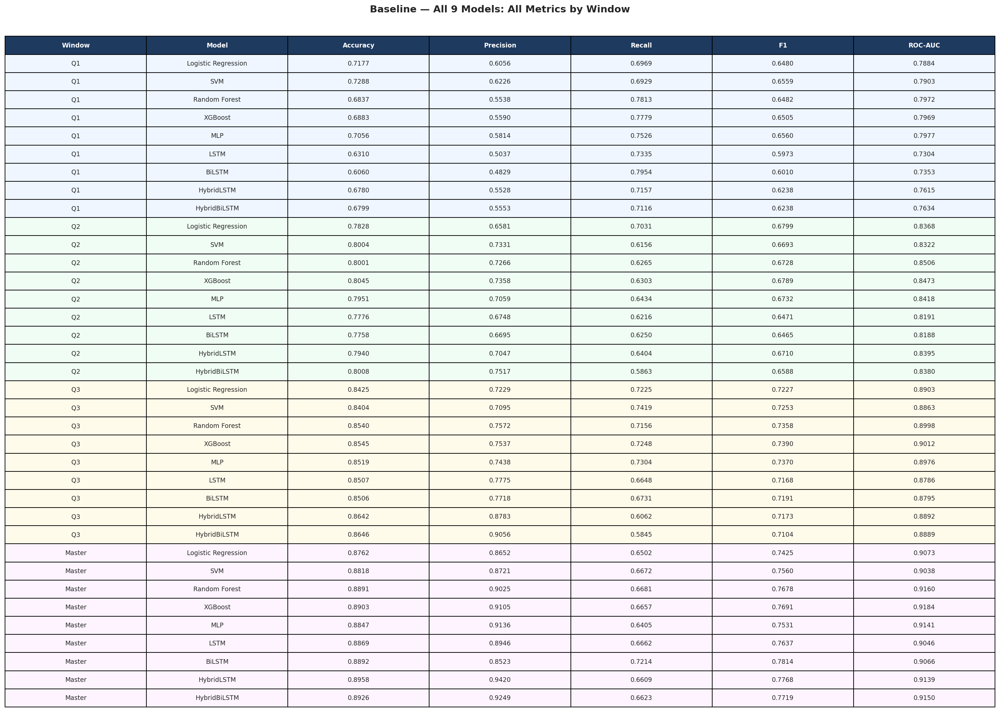


Baseline hybrid ROC-AUC verification:
Window        Model     F1  ROC-AUC
    Q1   HybridLSTM 0.6238   0.7615
    Q1 HybridBiLSTM 0.6238   0.7634
    Q2   HybridLSTM 0.6710   0.8395
    Q2 HybridBiLSTM 0.6588   0.8380
    Q3   HybridLSTM 0.7173   0.8892
    Q3 HybridBiLSTM 0.7104   0.8889
Master   HybridLSTM 0.7768   0.9139
Master HybridBiLSTM 0.7719   0.9150


In [129]:

print("S1-Fig1: Baseline metrics table — all 9 models")

# Correct sources:
# df_base        = Baseline tabular models (5)
# df_lstm        = LSTM and BiLSTM (2)
# df_hybrid_base = Baseline HybridLSTM and HybridBiLSTM (2)
# df_hybrid      = CAF hybrids — DO NOT use in Section 1

df_s1 = pd.concat(
    [df_base, df_lstm, df_hybrid_base],
    ignore_index=True
).copy()

# Ensure consistent checkpoint and model names
df_s1["Window"] = df_s1["Window"].astype(str).str.strip()
df_s1["Model"] = (
    df_s1["Model"].astype(str)
    .str.replace("_tuned", "", regex=False)
    .str.replace("_CAF", "", regex=False)
    .str.strip()
)

windows_order = ["Q1", "Q2", "Q3", "Master"]

models_order = [
    "Logistic Regression",
    "SVM",
    "Random Forest",
    "XGBoost",
    "MLP",
    "LSTM",
    "BiLSTM",
    "HybridLSTM",
    "HybridBiLSTM"
]

cols_show = [
    "Window", "Model", "Accuracy",
    "Precision", "Recall", "F1", "ROC-AUC"
]

# Validate the results before plotting
expected = pd.MultiIndex.from_product(
    [windows_order, models_order],
    names=["Window", "Model"]
)

df_s1 = df_s1.set_index(["Window", "Model"])

if df_s1.index.has_duplicates:
    raise ValueError("Duplicate baseline model/window results found.")

missing = expected.difference(df_s1.index)

if len(missing):
    raise ValueError(f"Missing baseline results: {list(missing)}")

df_s1 = df_s1.reindex(expected).reset_index()

# Prepare the display table
tbl_data = df_s1[cols_show].copy()

for metric in ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]:
    tbl_data[metric] = pd.to_numeric(
        tbl_data[metric], errors="coerce"
    ).map(lambda x: f"{x:.4f}" if pd.notna(x) else "N/A")

# Draw the table
fig, ax = plt.subplots(figsize=(20, 14))
ax.axis("off")

tbl = ax.table(
    cellText=tbl_data.values,
    colLabels=cols_show,
    cellLoc="center",
    loc="center",
    bbox=[0, 0, 1, 1]
)

tbl.auto_set_font_size(False)
tbl.set_fontsize(9)

for j in range(len(cols_show)):
    tbl[0, j].set_facecolor("#1E3A5F")
    tbl[0, j].set_text_props(
        color="white",
        fontweight="bold"
    )

win_bg = {
    "Q1": "#EFF6FF",
    "Q2": "#F0FDF4",
    "Q3": "#FFFBEB",
    "Master": "#FDF4FF"
}

for i, row in enumerate(tbl_data.itertuples(index=False), 1):
    bg = win_bg.get(row.Window, "white")
    for j in range(len(cols_show)):
        tbl[i, j].set_facecolor(bg)

fig.suptitle(
    "Baseline — All 9 Models: All Metrics by Window",
    fontsize=14,
    fontweight="bold",
    y=1.01
)

plt.tight_layout()
plt.show()

# Verify that the actual baseline hybrid results were used
print("\nBaseline hybrid ROC-AUC verification:")
print(
    df_s1.loc[
        df_s1["Model"].isin(["HybridLSTM", "HybridBiLSTM"]),
        ["Window", "Model", "F1", "ROC-AUC"]
    ].to_string(index=False)
)


### Fig 2 — F1 Grouped Bar per Window

df_base: using in-memory table
df_lstm: using in-memory table
df_hybrid_base: using in-memory table

F1 values used in Section 1 Figure 2:
Model   Logistic Regression     SVM  Random Forest  XGBoost     MLP    LSTM  BiLSTM  HybridLSTM  HybridBiLSTM
Window                                                                                                       
Master               0.7425  0.7560         0.7678   0.7691  0.7531  0.7637  0.7814      0.7768        0.7719
Q1                   0.6480  0.6559         0.6482   0.6505  0.6560  0.5973  0.6010      0.6238        0.6238
Q2                   0.6799  0.6693         0.6728   0.6789  0.6732  0.6471  0.6465      0.6710        0.6588
Q3                   0.7227  0.7253         0.7358   0.7390  0.7370  0.7168  0.7191      0.7173        0.7104


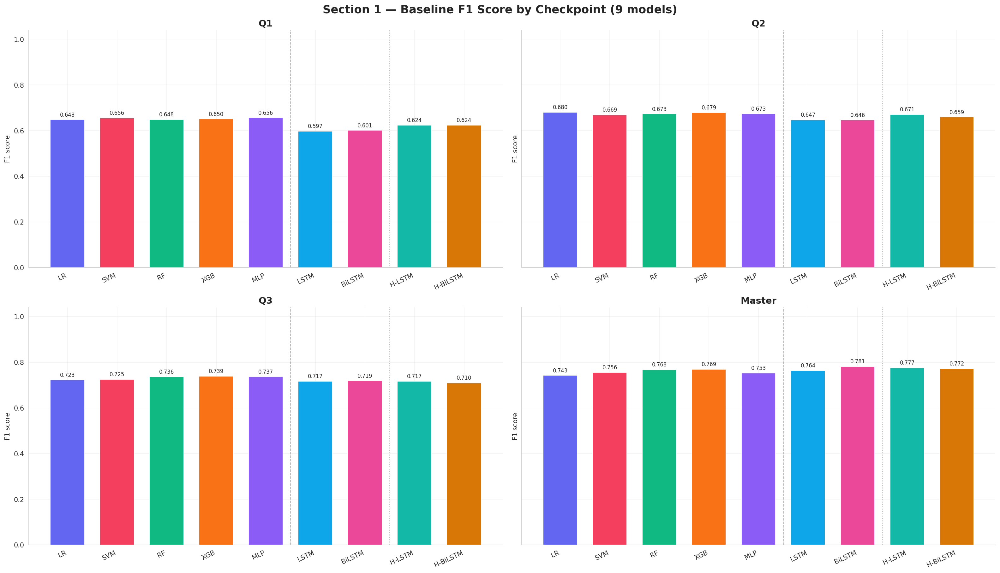

In [117]:
MODELS_FIG2 = [
    "Logistic Regression", "SVM", "Random Forest", "XGBoost", "MLP",
    "LSTM", "BiLSTM", "HybridLSTM", "HybridBiLSTM"
]
WINDOWS_FIG2 = ["Q1", "Q2", "Q3", "Master"]
MODEL_SHORT_FIG2 = ["LR", "SVM", "RF", "XGB", "MLP", "LSTM", "BiLSTM", "H-LSTM", "H-BiLSTM"]
MODEL_COLORS_FIG2 = ["#6366F1", "#F43F5E", "#10B981", "#F97316", "#8B5CF6",
                     "#0EA5E9", "#EC4899", "#14B8A6", "#D97706"]

def fig2_source(variable_name, csv_name):
    # Prefer the current notebook's loaded results to historical files.
    obj = globals().get(variable_name)
    if isinstance(obj, pd.DataFrame) and {"Window", "Model", "F1"}.issubset(obj.columns) and len(obj):
        print(f"{variable_name}: using in-memory table")
        return obj.copy()
    paths = [Path(csv_name), Path.cwd() / 'results' / csv_name]
    for p in paths:
        if p.is_file():
            print(f"{variable_name}: using {p.resolve()}")
            return pd.read_csv(p, usecols=["Window", "Model", "F1"])
    raise FileNotFoundError(f"Missing {csv_name}. Run the existing results-loading cell first, "
                            f"or place the CSV in the notebook's working directory ({Path.cwd()}).")

parts = []
for frame, source in [
    (fig2_source('df_base', 'results_tuned_baseline.csv'), 'tabular'),
    (fig2_source('df_lstm', 'results_tuned_lstm_models.csv'), 'sequence'),
    (fig2_source('df_hybrid_base', 'results_tuned_hybrid_models.csv'), 'hybrid baseline'),
]:
    if frame.empty:
        raise ValueError(f"{source}: no results")
    frame = frame[['Window', 'Model', 'F1']].copy()
    frame['Window'] = frame['Window'].astype('string').str.strip()
    frame['Model'] = (frame['Model'].astype('string')
                      .str.replace('_tuned', '', regex=False)
                      .str.replace('_CAF', '', regex=False)
                      .str.strip())
    frame['F1'] = pd.to_numeric(frame['F1'], errors='coerce')
    frame['Source'] = source
    parts.append(frame)

fig2_data = pd.concat(parts, ignore_index=True)
fig2_data = fig2_data[fig2_data['Window'].isin(WINDOWS_FIG2)
                      & fig2_data['Model'].isin(MODELS_FIG2)].copy()
if fig2_data[['Window', 'Model']].duplicated().any():
    dupes = fig2_data.loc[fig2_data[['Window', 'Model']].duplicated(False), ['Window','Model','Source']]
    raise ValueError(f"Duplicate baseline rows (check source files):\n{dupes.to_string(index=False)}")

expected = pd.MultiIndex.from_product([WINDOWS_FIG2, MODELS_FIG2], names=['Window', 'Model'])
observed = pd.MultiIndex.from_frame(fig2_data[['Window', 'Model']])
missing = expected.difference(observed)
if len(missing):
    raise ValueError(f"Missing baseline F1 results for these pairs: {list(missing)}. "
                     "Do not substitute CAF hybrids or zero-filled values.")
if fig2_data['F1'].isna().any() or not fig2_data['F1'].between(0, 1).all():
    raise ValueError("Some F1 values are missing or outside [0,1]; inspect result files.")

f1_grid = (fig2_data.set_index(['Window','Model'])['F1']
           .reindex(expected).unstack('Model').reindex(columns=MODELS_FIG2))
print("\nF1 values used in Section 1 Figure 2:")
print(f1_grid.round(4).to_string())

fig, axes = plt.subplots(2, 2, figsize=(21, 12), sharey=True, constrained_layout=True)
fig.suptitle("Section 1 — Baseline F1 Score by Checkpoint (9 models)",
             fontsize=17, fontweight='bold')
for ax, window in zip(axes.flat, WINDOWS_FIG2):
    values = f1_grid.loc[window].to_numpy(dtype=float)
    bars = ax.bar(np.arange(len(values)), values, color=MODEL_COLORS_FIG2,
                  width=0.69, edgecolor='white', linewidth=0.9)
    ax.set_title(window, fontsize=14, fontweight='bold')
    ax.set_ylabel('F1 score')
    ax.set_ylim(0, 1.04)  # FIX: do not clip Q1/Q2 bars with an axis starting at 0.68.
    ax.set_yticks(np.arange(0, 1.01, 0.2))
    ax.set_xticks(np.arange(len(values)))
    ax.set_xticklabels(MODEL_SHORT_FIG2, rotation=25, ha='right', fontsize=10)
    ax.axvline(4.5, color='gray', lw=1, linestyle='--', alpha=0.5)
    ax.axvline(6.5, color='gray', lw=1, linestyle=':', alpha=0.5)
    ax.grid(axis='y', alpha=0.22)
    ax.set_axisbelow(True)
    for bar, value in zip(bars, values):
        ax.annotate(f"{value:.3f}", (bar.get_x() + bar.get_width()/2, value),
                    xytext=(0, 3), textcoords='offset points', ha='center', va='bottom', fontsize=8)

plt.show()


### Fig 2b — Accuracy Grouped Bar per Window

  S1-Fig2b: Accuracy grouped bar — all 9 models, 2 windows per row


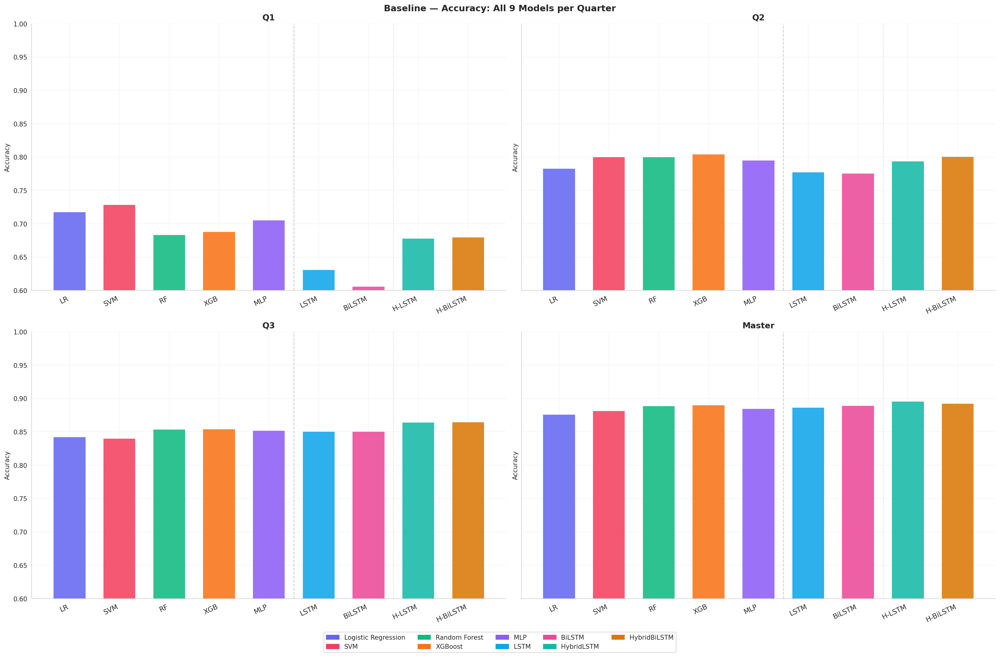

In [70]:
print("  S1-Fig2b: Accuracy grouped bar — all 9 models, 2 windows per row")
fig, axes = plt.subplots(2, 2, figsize=(22, 14), sharey=True)
axes = axes.flatten()
fig.suptitle("Baseline — Accuracy: All 9 Models per Quarter",
             fontsize=14, fontweight="bold")
for ax, window in zip(axes, WINDOWS):
    vals = [get_val_sec(1, window, m, "Accuracy") for m in MODELS]
    ax.bar(x_all, vals, color=colors_all, alpha=0.87, edgecolor="white", width=0.65)
    ax.set_xticks(x_all)
    ax.set_xticklabels([MODEL_SHORT[m] for m in MODELS], fontsize=11, rotation=25, ha="right")
    ax.set_title(window, fontsize=13, fontweight="bold")
    ax.set_ylabel("Accuracy"); fmt_ax(ax, (0.60, 1.0))
    ax.axvline(4.5, color="gray", lw=1.2, linestyle="--", alpha=0.4)
    ax.axvline(6.5, color="gray", lw=1.2, linestyle=":", alpha=0.4)
fig.legend(handles=[mpatches.Patch(color=MODEL_COLORS[m], label=m) for m in MODELS],
           loc="lower center", ncol=5, fontsize=10, bbox_to_anchor=(0.5, -0.04))
plt.tight_layout(); plt.show()

### Fig 3 — ROC-AUC Grouped Bar per Window

S1-Fig3: ROC-AUC — all 9 baseline models


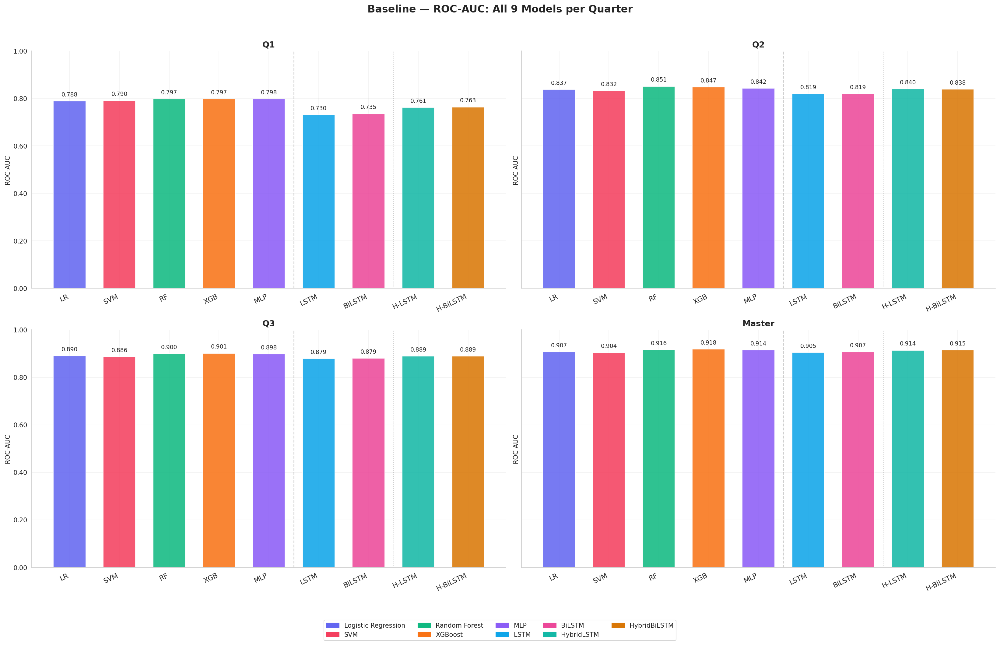

In [118]:

print("S1-Fig3: ROC-AUC — all 9 baseline models")

fig, axes = plt.subplots(2, 2, figsize=(22, 14), sharey=True)
axes = axes.flatten()

fig.suptitle(
    "Baseline — ROC-AUC: All 9 Models per Quarter",
    fontsize=16,
    fontweight="bold"
)

for ax, window in zip(axes, WINDOWS):
    vals = [
        get_val_sec(1, window, m, "ROC-AUC")
        for m in MODELS
    ]

    bars = ax.bar(
        x_all, vals,
        color=colors_all,
        alpha=0.87,
        edgecolor="white",
        width=0.65
    )

    ax.set_xticks(x_all)
    ax.set_xticklabels(
        [MODEL_SHORT[m] for m in MODELS],
        fontsize=11,
        rotation=25,
        ha="right"
    )

    ax.set_title(window, fontsize=13, fontweight="bold")
    ax.set_ylabel("ROC-AUC")

    # FIX: Show bars from zero instead of clipping below 0.80
    fmt_ax(ax, (0.0, 1.0))

    # Show exact ROC-AUC values above the bars
    for bar, value in zip(bars, vals):
        if np.isfinite(value):
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                value + 0.015,
                f"{value:.3f}",
                ha="center",
                va="bottom",
                fontsize=9
            )

    ax.axvline(4.5, color="gray", lw=1.2,
               linestyle="--", alpha=0.4)
    ax.axvline(6.5, color="gray", lw=1.2,
               linestyle=":", alpha=0.4)

fig.legend(
    handles=[
        mpatches.Patch(color=MODEL_COLORS[m], label=m)
        for m in MODELS
    ],
    loc="lower center",
    ncol=5,
    fontsize=10,
    bbox_to_anchor=(0.5, -0.02)
)

plt.tight_layout(rect=[0, 0.05, 1, 0.96])
plt.show()


### Fig 4 — F1 & ROC-AUC Progression Across Quarters

S1-Fig4: F1 & ROC-AUC progression across quarters


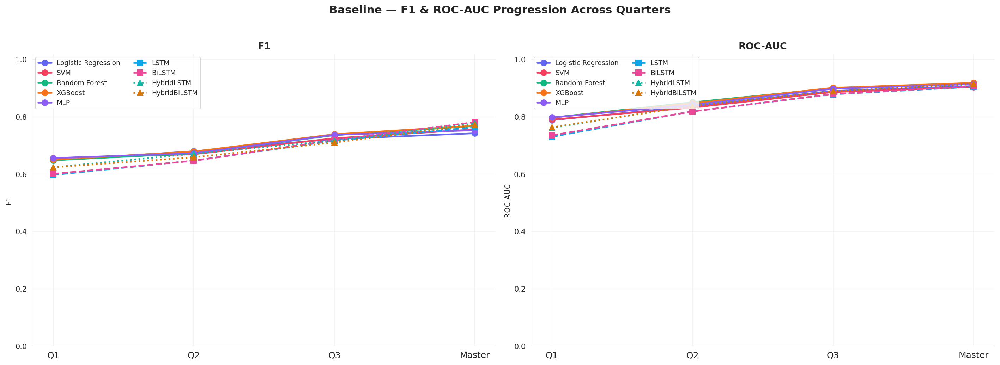

In [119]:

print("S1-Fig4: F1 & ROC-AUC progression across quarters")

fig, axes = plt.subplots(1, 2, figsize=(19, 7))

fig.suptitle(
    "Baseline — F1 & ROC-AUC Progression Across Quarters",
    fontsize=15,
    fontweight="bold"
)

for ax, metric in zip(axes, ["F1", "ROC-AUC"]):
    for model in MODELS:
        vals = np.array(
            [get_val_sec(1, w, model, metric) for w in WINDOWS],
            dtype=float
        )

        ax.plot(
            xpos, vals,
            color=MODEL_COLORS[model],
            marker=markers[model],
            lw=2.2,
            ms=8,
            linestyle=line_styles[model],
            label=model
        )

        missing = [
            w for w, value in zip(WINDOWS, vals)
            if not np.isfinite(value)
        ]
        if missing:
            print(f"Missing {metric} for {model}: {missing}")

    ax.set_xticks(xpos)
    ax.set_xticklabels(WINDOWS, fontsize=12)
    ax.set_title(metric, fontsize=13, fontweight="bold")
    ax.set_ylabel(metric)

    # FIX: Include lower Q1 and Q2 scores
    ax.set_ylim(0.0, 1.02)

    ax.set_xlim(-0.15, len(WINDOWS) - 0.85)
    ax.grid(True, alpha=0.25)

    ax.legend(fontsize=9, loc="upper left", ncol=2)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


### Fig 5 — ROC-AUC Heatmap

  S1-Fig5: ROC-AUC heatmap


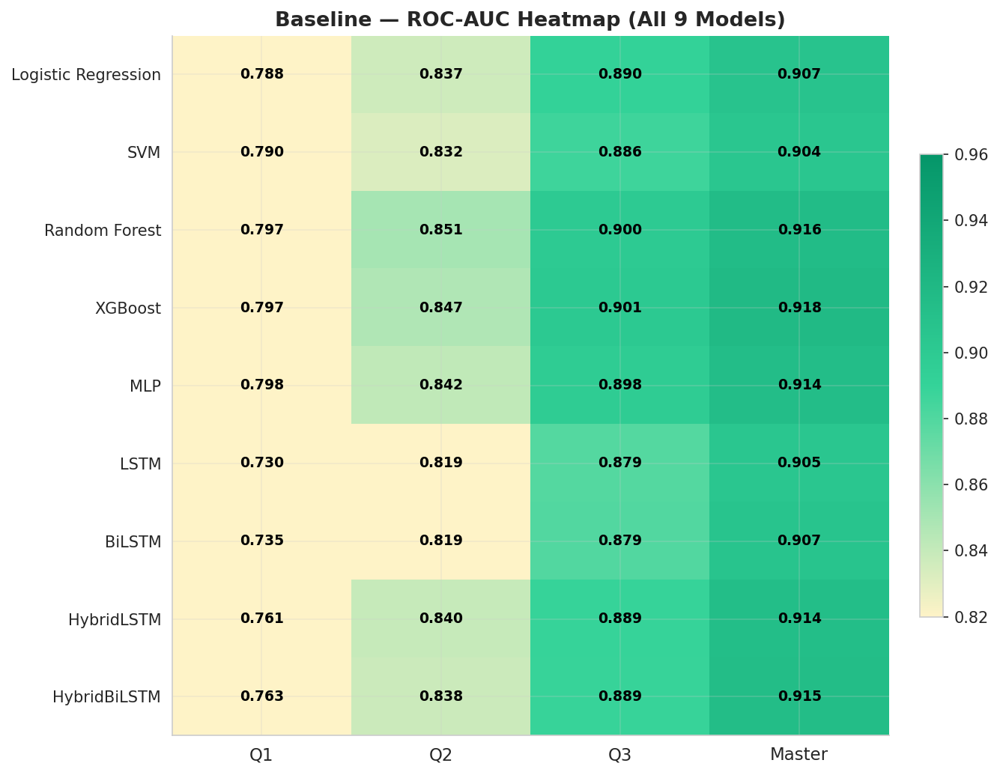

In [73]:
print("  S1-Fig5: ROC-AUC heatmap")
cmap_g = LinearSegmentedColormap.from_list("g", ["#FEF3C7","#34D399","#059669"])
heatmap_data = np.array([[get_val_sec(1,w,m,"ROC-AUC") for w in WINDOWS] for m in MODELS])
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(heatmap_data, cmap=cmap_g, vmin=0.82, vmax=0.96, aspect="auto")
ax.set_xticks(range(len(WINDOWS))); ax.set_xticklabels(WINDOWS, fontsize=11)
ax.set_yticks(range(len(MODELS))); ax.set_yticklabels(MODELS, fontsize=10)
ax.set_title("Baseline — ROC-AUC Heatmap (All 9 Models)",
             fontsize=13, fontweight="bold")
for i in range(len(MODELS)):
    for j in range(len(WINDOWS)):
        v = heatmap_data[i,j]
        ax.text(j, i, f"{v:.3f}", ha="center", va="center", fontsize=9,
                fontweight="bold", color="white" if v > 0.93 else "black")
plt.colorbar(im, ax=ax, fraction=0.03, pad=0.04)
plt.tight_layout(); plt.show()

### Fig 6 — Confusion Matrices

  S1-Fig6: Confusion matrices


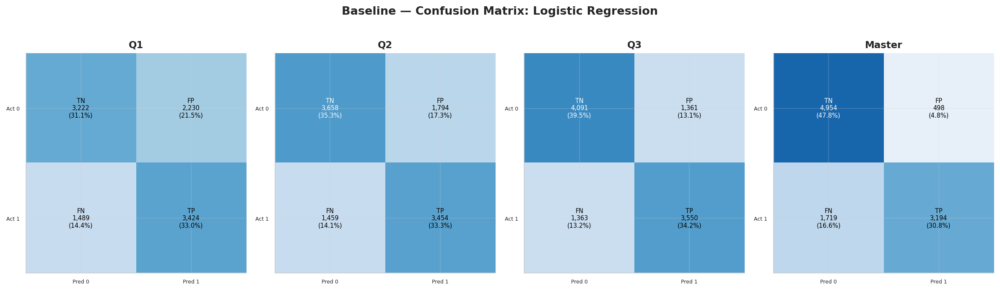

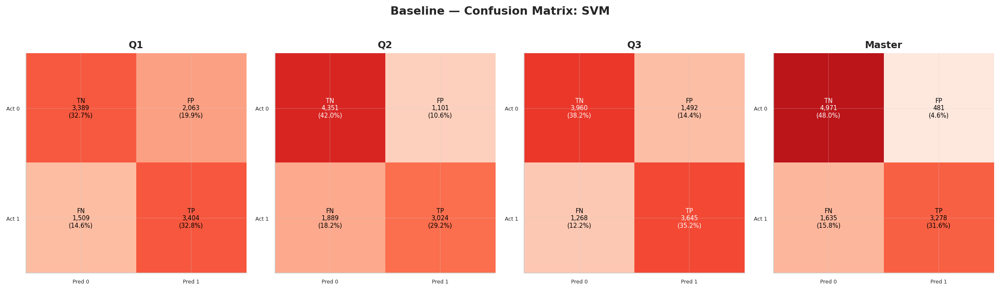

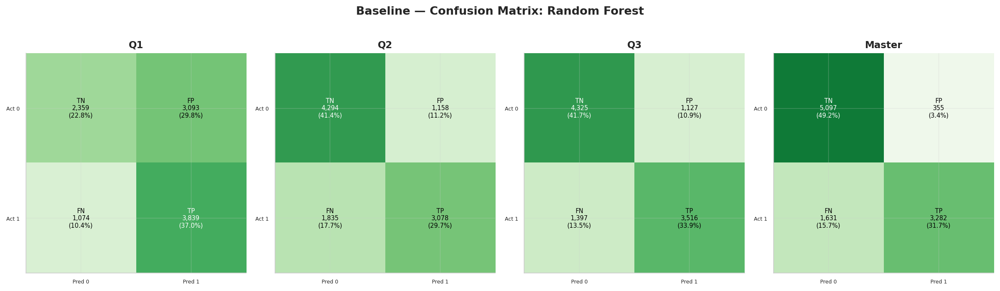

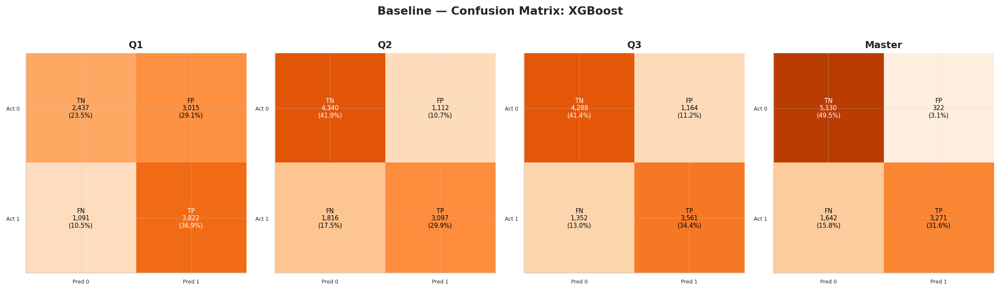

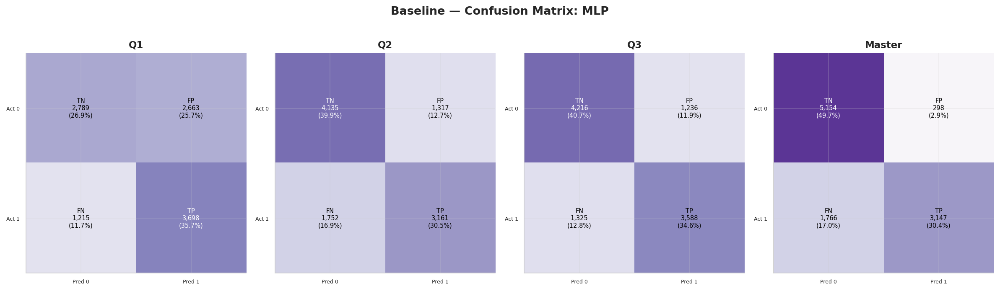

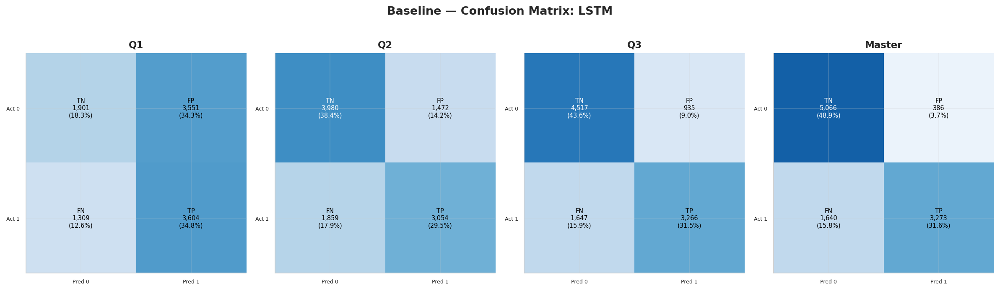

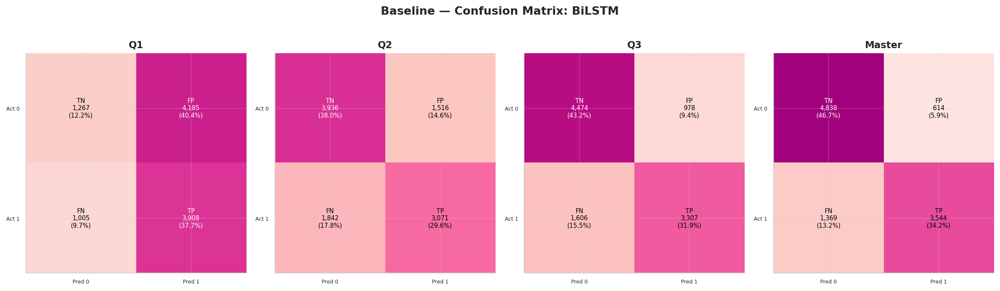

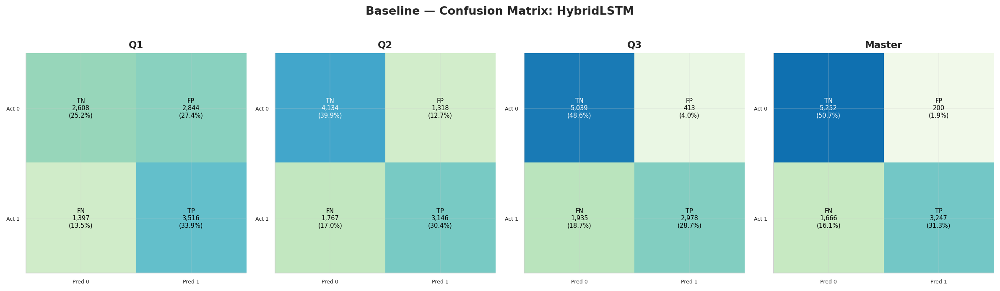

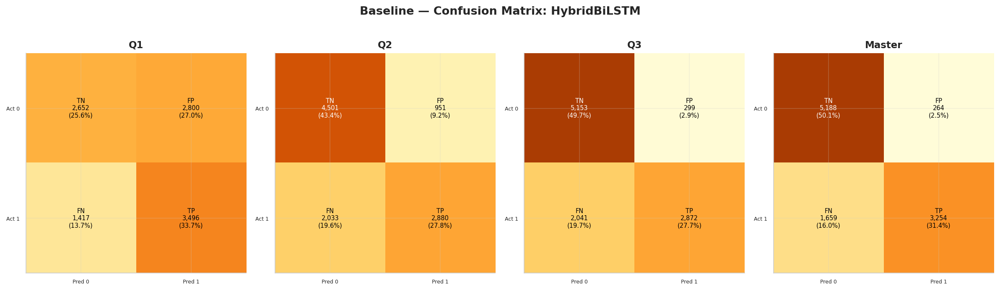

In [74]:
print("  S1-Fig6: Confusion matrices")

cmap_per_model = {
    "Logistic Regression": "Blues",
    "SVM":                 "Reds",
    "Random Forest":       "Greens",
    "XGBoost":             "Oranges",
    "MLP":                 "Purples",
    "LSTM":                "Blues",
    "BiLSTM":              "RdPu",
    "HybridLSTM":          "GnBu",
    "HybridBiLSTM":        "YlOrBr",
}

ALL_MODELS = list(cmap_per_model.keys())

for model in ALL_MODELS:
    n_windows = len(WINDOWS)
    fig, axes_cm = plt.subplots(1, n_windows, figsize=(n_windows * 4, 4.5),
                                squeeze=False)
    fig.suptitle(f"Baseline — Confusion Matrix: {model}",
                 fontsize=13, fontweight="bold", y=1.02)

    for c, window in enumerate(WINDOWS):
        ax = axes_cm[0, c]
        draw_cm(ax,
                get_val_sec(1, window, model, "Accuracy"),
                get_val_sec(1, window, model, "Precision"),
                get_val_sec(1, window, model, "Recall"),
                cmap_per_model[model])
        ax.set_title(window, fontsize=11, fontweight="bold")

    plt.tight_layout()
    plt.show()

### Fig 7 — Radar Charts per Window

  S1-Fig7: Radar charts per window


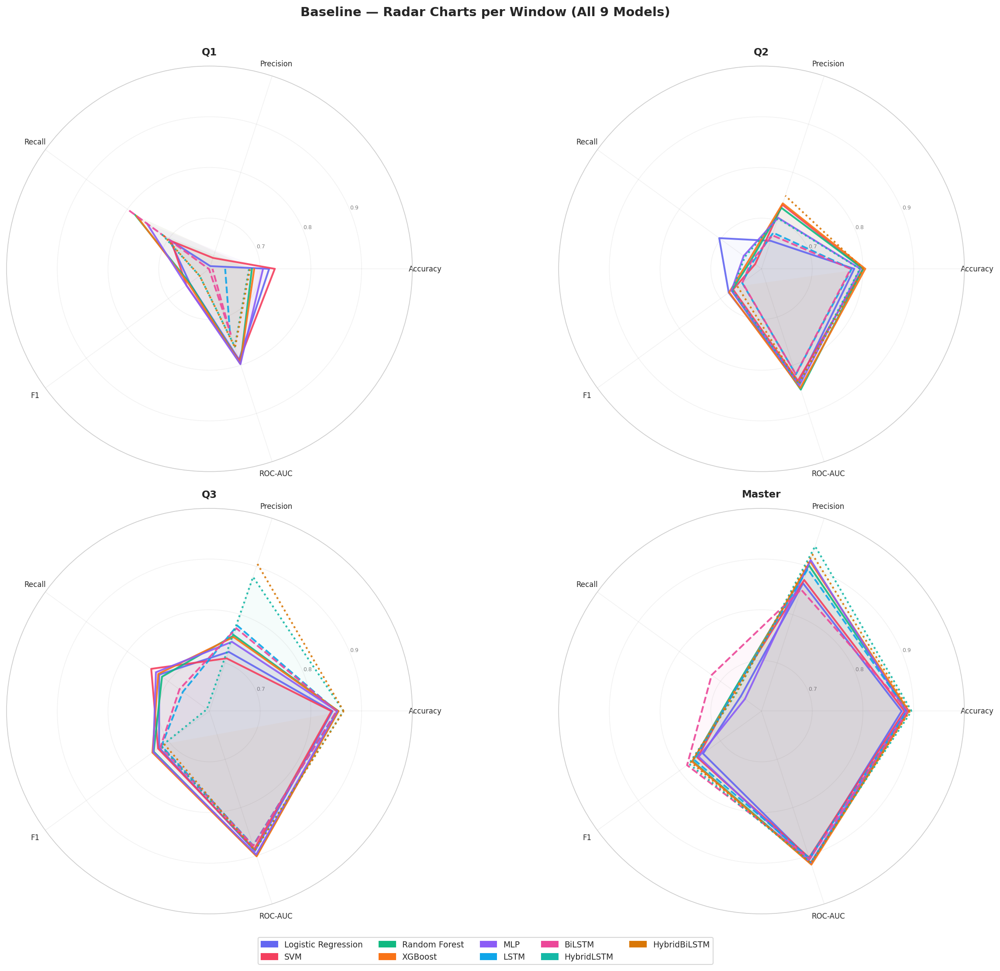

  Section 1 complete.



In [75]:
print("  S1-Fig7: Radar charts per window")
fig, axes_r = plt.subplots(2, 2, figsize=(18, 14), subplot_kw=dict(polar=True))
axes_r = axes_r.flatten()
fig.suptitle("Baseline — Radar Charts per Window (All 9 Models)",
             fontsize=14, fontweight="bold", y=1.01)
for ax, window in zip(axes_r, WINDOWS):
    for model in MODELS:
        vals = [get_val_sec(1,window,model,m) for m in rad_metrics] + \
               [get_val_sec(1,window,model,rad_metrics[0])]
        ax.plot(angles, vals, color=MODEL_COLORS[model], lw=2,
                linestyle=line_styles[model], alpha=0.9)
        ax.fill(angles, vals, color=MODEL_COLORS[model], alpha=0.04)
    ax.set_xticks(angles[:-1]); ax.set_xticklabels(rad_metrics, fontsize=8)
    ax.set_ylim(0.60, 1.0); ax.set_yticks([0.7,0.8,0.9])
    ax.set_yticklabels(["0.7","0.8","0.9"], fontsize=6, color="gray")
    ax.set_title(window, fontsize=11, fontweight="bold", pad=12)
fig.legend(handles=[mpatches.Patch(color=MODEL_COLORS[m], label=m) for m in MODELS],
           loc="lower center", ncol=5, fontsize=9, bbox_to_anchor=(0.5,-0.04))
plt.tight_layout(); plt.show()
print("  Section 1 complete.\n")


## Section 2 — Tuned Cluster-Aware Models

### Fig 1 — Metrics Summary Table

  S2-Fig1: Metrics table — all 9 models


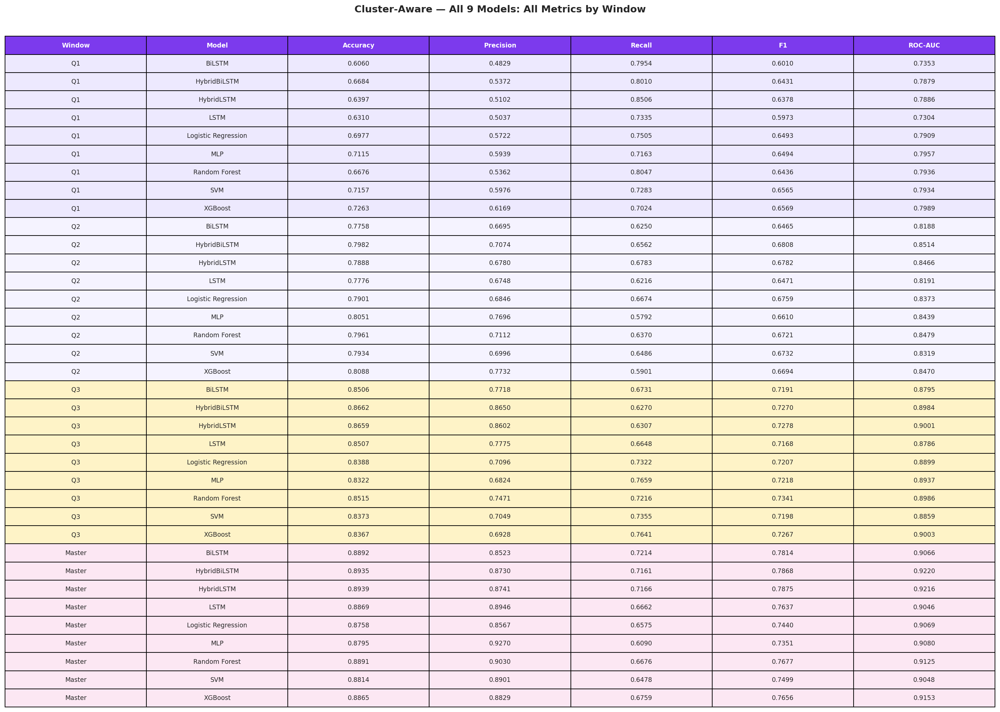

In [76]:
print("  S2-Fig1: Metrics table — all 9 models")
df_s2 = pd.concat([df_clus, df_lstm, df_hybrid], ignore_index=True)
fig, ax = plt.subplots(figsize=(20, 14))
ax.axis("off")
tbl_data = df_s2.sort_values(["Window","Model"])[cols_show].copy()
for c in METRICS: tbl_data[c] = tbl_data[c].map(lambda v: f"{v:.4f}")
tbl = ax.table(cellText=tbl_data.values, colLabels=cols_show,
               cellLoc="center", loc="center", bbox=[0,0,1,1])
tbl.auto_set_font_size(False); tbl.set_fontsize(9)
win_bg2 = {"Q1":"#EDE9FE","Q2":"#F5F3FF","Q3":"#FEF3C7","Master":"#FCE7F3"}
for j in range(len(cols_show)):
    tbl[0,j].set_facecolor("#7C3AED")
    tbl[0,j].set_text_props(color="white", fontweight="bold")
for i, row in enumerate(tbl_data.itertuples(), 1):
    bg = win_bg2.get(row.Window, "white")
    for j in range(len(cols_show)): tbl[i,j].set_facecolor(bg)
fig.suptitle("Cluster-Aware — All 9 Models: All Metrics by Window",
             fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout(); plt.show()

### Fig 2 — F1 Score

S2-Fig2: F1 grouped bar — all 9 models, 2 windows per row


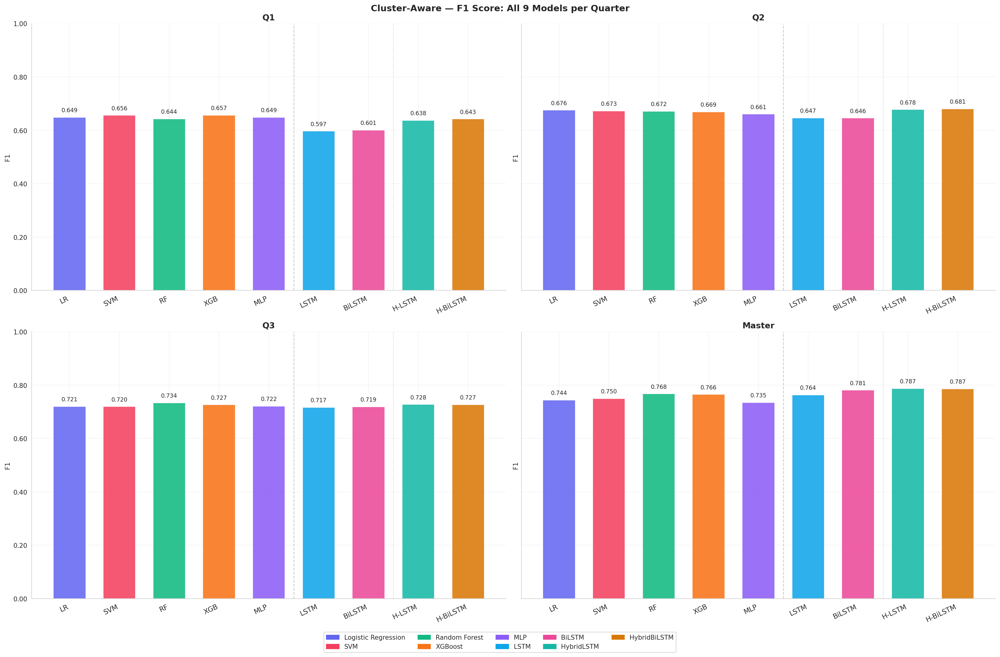

In [120]:
print("S2-Fig2: F1 grouped bar — all 9 models, 2 windows per row")

fig, axes = plt.subplots(2, 2, figsize=(22, 14), sharey=True)
axes = axes.flatten()

fig.suptitle(
    "Cluster-Aware — F1 Score: All 9 Models per Quarter",
    fontsize=14,
    fontweight="bold"
)

for ax, window in zip(axes, WINDOWS):
    vals = [get_val_sec(2, window, m, "F1") for m in MODELS]

    bars = ax.bar(
        x_all,
        vals,
        color=colors_all,
        alpha=0.87,
        edgecolor="white",
        width=0.65
    )

    ax.set_xticks(x_all)
    ax.set_xticklabels(
        [MODEL_SHORT[m] for m in MODELS],
        fontsize=11,
        rotation=25,
        ha="right"
    )

    ax.set_title(window, fontsize=13, fontweight="bold")
    ax.set_ylabel("F1")

    # FIX: show full range so Q1/Q2 bars are visible
    fmt_ax(ax, (0.0, 1.0))

    # Optional value labels
    for bar, value in zip(bars, vals):
        if value is not None and np.isfinite(value):
            ax.text(
                bar.get_x() + bar.get_width()/2,
                value + 0.015,
                f"{value:.3f}",
                ha="center",
                va="bottom",
                fontsize=9
            )

    ax.axvline(4.5, color="gray", lw=1.2, linestyle="--", alpha=0.4)
    ax.axvline(6.5, color="gray", lw=1.2, linestyle=":", alpha=0.4)

fig.legend(
    handles=[mpatches.Patch(color=MODEL_COLORS[m], label=m) for m in MODELS],
    loc="lower center",
    ncol=5,
    fontsize=10,
    bbox_to_anchor=(0.5, -0.04)
)

plt.tight_layout()
plt.show()

### Fig 2b — Accuracy Grouped Bar per Window

  S2-Fig2b: Accuracy grouped bar — all 9 models, 2 windows per row


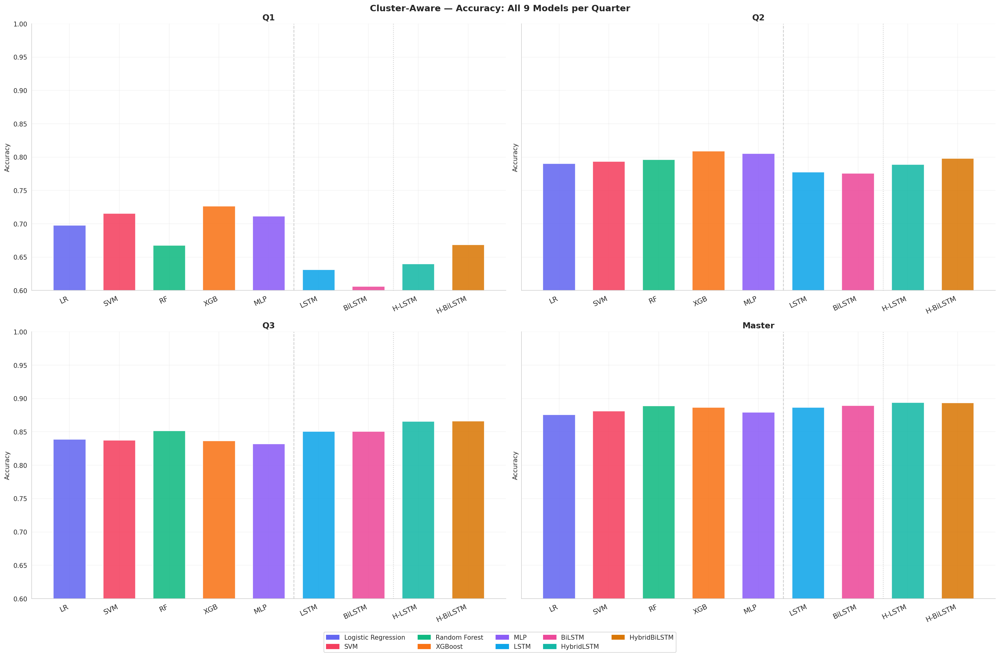

In [78]:
print("  S2-Fig2b: Accuracy grouped bar — all 9 models, 2 windows per row")
fig, axes = plt.subplots(2, 2, figsize=(22, 14), sharey=True)
axes = axes.flatten()
fig.suptitle("Cluster-Aware — Accuracy: All 9 Models per Quarter",
             fontsize=14, fontweight="bold")
for ax, window in zip(axes, WINDOWS):
    vals = [get_val_sec(2, window, m, "Accuracy") for m in MODELS]
    ax.bar(x_all, vals, color=colors_all, alpha=0.87, edgecolor="white", width=0.65)
    ax.set_xticks(x_all)
    ax.set_xticklabels([MODEL_SHORT[m] for m in MODELS], fontsize=11, rotation=25, ha="right")
    ax.set_title(window, fontsize=13, fontweight="bold")
    ax.set_ylabel("Accuracy"); fmt_ax(ax, (0.60, 1.0))
    ax.axvline(4.5, color="gray", lw=1.2, linestyle="--", alpha=0.4)
    ax.axvline(6.5, color="gray", lw=1.2, linestyle=":", alpha=0.4)
fig.legend(handles=[mpatches.Patch(color=MODEL_COLORS[m], label=m) for m in MODELS],
           loc="lower center", ncol=5, fontsize=10, bbox_to_anchor=(0.5, -0.04))
plt.tight_layout(); plt.show()

### Fig 3 — ROC-AUC

S2-Fig3: ROC-AUC grouped bar — all 9 models


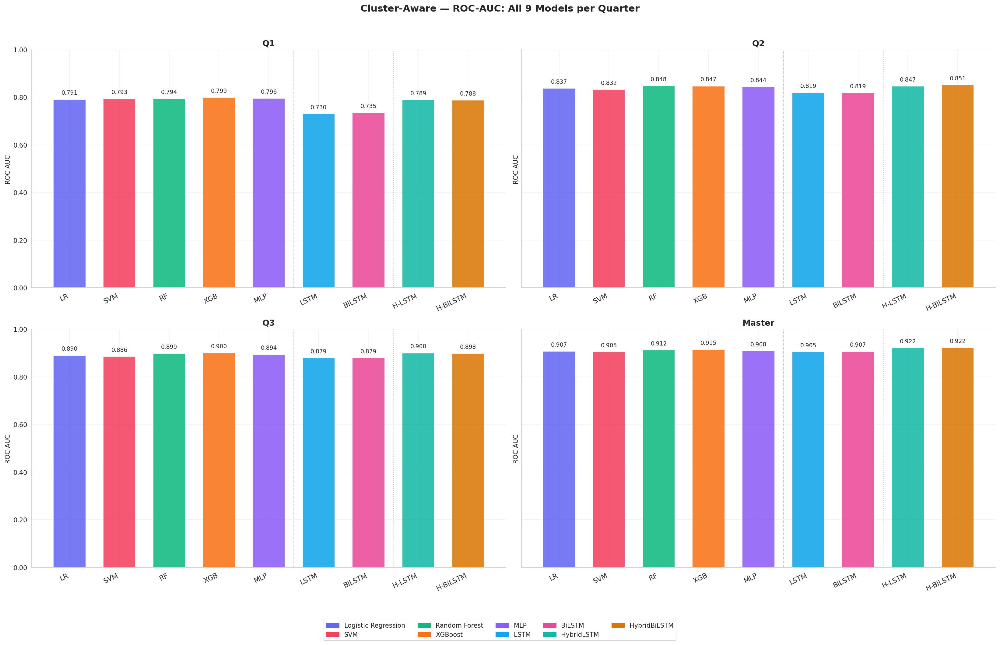

In [121]:

print("S2-Fig3: ROC-AUC grouped bar — all 9 models")

fig, axes = plt.subplots(2, 2, figsize=(22, 14), sharey=True)
axes = axes.flatten()

fig.suptitle(
    "Cluster-Aware — ROC-AUC: All 9 Models per Quarter",
    fontsize=15,
    fontweight="bold"
)

for ax, window in zip(axes, WINDOWS):

    vals = [
        get_val_sec(2, window, m, "ROC-AUC")
        for m in MODELS
    ]

    bars = ax.bar(
        x_all, vals,
        color=colors_all,
        alpha=0.87,
        edgecolor="white",
        width=0.65
    )

    ax.set_xticks(x_all)
    ax.set_xticklabels(
        [MODEL_SHORT[m] for m in MODELS],
        fontsize=11,
        rotation=25,
        ha="right"
    )

    ax.set_title(window, fontsize=13, fontweight="bold")
    ax.set_ylabel("ROC-AUC")

    # FIX: Display the full bar height
    fmt_ax(ax, (0.0, 1.0))

    # Display ROC-AUC above each bar
    for bar, value in zip(bars, vals):
        if value is not None and np.isfinite(value):
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                value + 0.015,
                f"{value:.3f}",
                ha="center",
                va="bottom",
                fontsize=9
            )

    ax.axvline(4.5, color="gray", lw=1.2,
               linestyle="--", alpha=0.4)
    ax.axvline(6.5, color="gray", lw=1.2,
               linestyle=":", alpha=0.4)

fig.legend(
    handles=[
        mpatches.Patch(
            color=MODEL_COLORS[m],
            label=m
        )
        for m in MODELS
    ],
    loc="lower center",
    ncol=5,
    fontsize=10,
    bbox_to_anchor=(0.5, -0.02)
)

plt.tight_layout(rect=[0, 0.05, 1, 0.96])
plt.show()


### Fig 4 — Progression Line Chart

S2-Fig4: Cluster-Aware F1 & ROC-AUC Progression


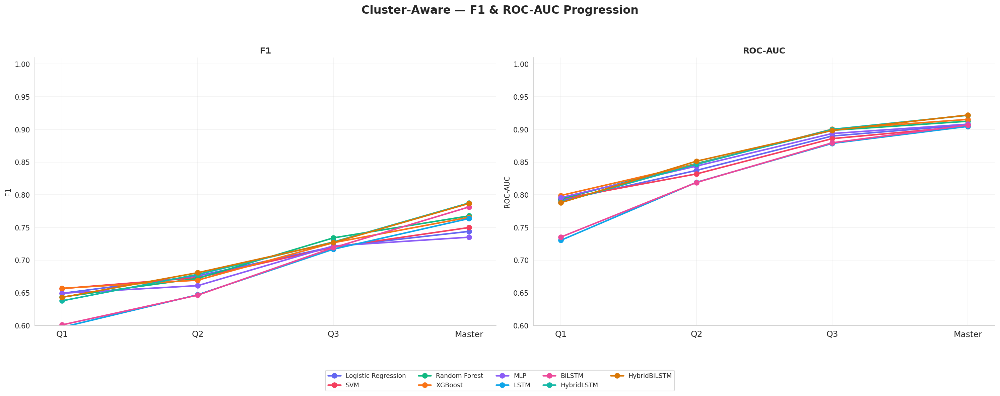


Q1 and Q2 results used in the plots:
Window               Model     F1  ROC-AUC
    Q1              BiLSTM 0.6010   0.7353
    Q1        HybridBiLSTM 0.6431   0.7879
    Q1          HybridLSTM 0.6378   0.7886
    Q1                LSTM 0.5973   0.7304
    Q1 Logistic Regression 0.6493   0.7909
    Q1                 MLP 0.6494   0.7957
    Q1       Random Forest 0.6436   0.7936
    Q1                 SVM 0.6565   0.7934
    Q1             XGBoost 0.6569   0.7989
    Q2              BiLSTM 0.6465   0.8188
    Q2        HybridBiLSTM 0.6808   0.8514
    Q2          HybridLSTM 0.6782   0.8466
    Q2                LSTM 0.6471   0.8191
    Q2 Logistic Regression 0.6759   0.8373
    Q2                 MLP 0.6610   0.8439
    Q2       Random Forest 0.6721   0.8479
    Q2                 SVM 0.6732   0.8319
    Q2             XGBoost 0.6694   0.8470


In [122]:
print("S2-Fig4: Cluster-Aware F1 & ROC-AUC Progression")

# Existing results from your notebook
sources = [
    df_clus,      # Cluster-aware tabular models
    df_lstm,      # LSTM and BiLSTM
    df_hybrid     # Cluster-aware hybrid models
]

plot_df = pd.concat(sources, ignore_index=True).copy()

# Standardize names and numeric values
plot_df["Window"] = plot_df["Window"].astype(str).str.strip()
plot_df["Model"] = (
    plot_df["Model"].astype(str)
    .str.replace("_tuned", "", regex=False)
    .str.replace("_CAF", "", regex=False)
    .str.strip()
)

for metric in ["F1", "ROC-AUC"]:
    plot_df[metric] = pd.to_numeric(
        plot_df[metric], errors="coerce"
    )

windows = ["Q1", "Q2", "Q3", "Master"]
positions = np.arange(len(windows))

fig, axes = plt.subplots(1, 2, figsize=(20, 8))
fig.suptitle(
    "Cluster-Aware — F1 & ROC-AUC Progression",
    fontsize=16, fontweight="bold"
)

for ax, metric in zip(axes, ["F1", "ROC-AUC"]):
    for model in MODELS:
        subset = plot_df[plot_df["Model"] == model]

        values = []
        for window in windows:
            matched = subset.loc[
                subset["Window"] == window, metric
            ].dropna()

            values.append(
                matched.iloc[0] if not matched.empty else np.nan
            )

        values = np.array(values, dtype=float)

        if not np.isfinite(values).all():
            print(
                f"Missing {metric} for {model}:",
                [w for w, v in zip(windows, values)
                 if not np.isfinite(v)]
            )

        ax.plot(
            positions,
            values,
            marker="o",
            linewidth=2.2,
            markersize=7,
            color=MODEL_COLORS[model],
            label=model
        )

    ax.set_xticks(positions)
    ax.set_xticklabels(windows, fontsize=12)
    ax.set_xlim(-0.2, 3.2)
    ax.set_ylim(0.60, 1.01)
    ax.set_title(metric, fontweight="bold")
    ax.set_ylabel(metric)
    ax.grid(True, alpha=0.25)

# Use a shared legend outside the plots
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles, labels,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.01),
    ncol=5,
    fontsize=9
)

plt.tight_layout(rect=[0, 0.13, 1, 0.94])
plt.show()

# Verify Q1 and Q2 explicitly
print("\nQ1 and Q2 results used in the plots:")
print(
    plot_df.loc[
        plot_df["Window"].isin(["Q1", "Q2"]),
        ["Window", "Model", "F1", "ROC-AUC"]
    ].sort_values(["Window", "Model"]).to_string(index=False)
)


### Fig 5 — ROC-AUC Heatmap

  S2-Fig5: ROC-AUC heatmap


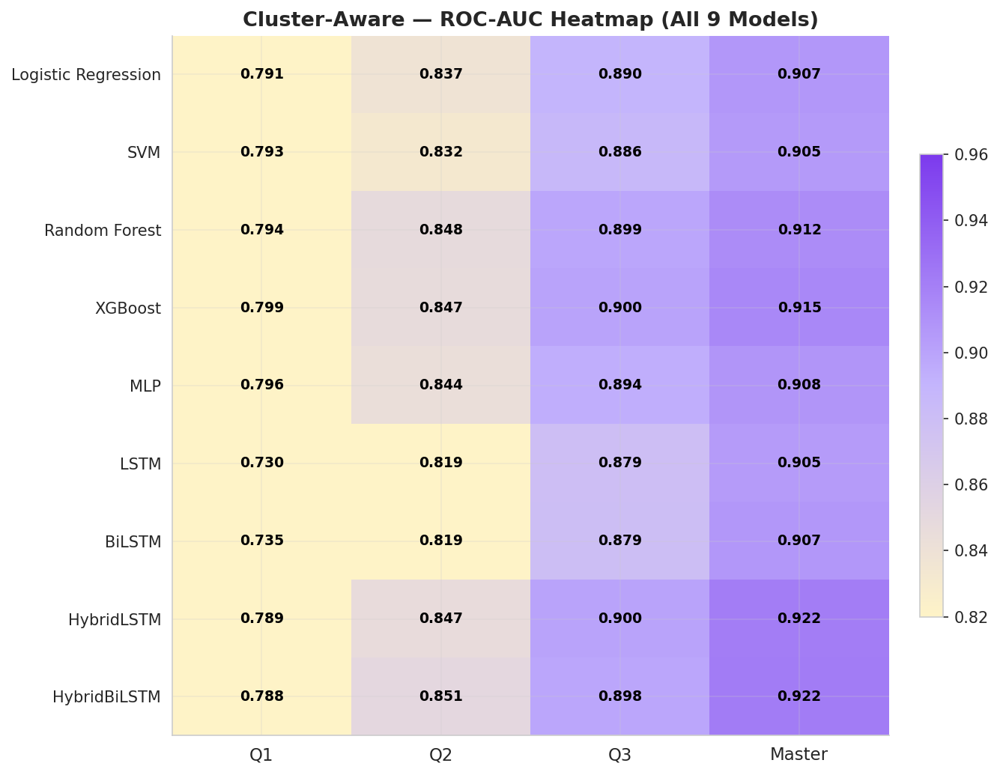

In [81]:
print("  S2-Fig5: ROC-AUC heatmap")
cmap_p = LinearSegmentedColormap.from_list("p", ["#FEF3C7","#C4B5FD","#7C3AED"])
heatmap_data2 = np.array([[get_val_sec(2,w,m,"ROC-AUC") for w in WINDOWS] for m in MODELS])
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(heatmap_data2, cmap=cmap_p, vmin=0.82, vmax=0.96, aspect="auto")
ax.set_xticks(range(len(WINDOWS))); ax.set_xticklabels(WINDOWS, fontsize=11)
ax.set_yticks(range(len(MODELS))); ax.set_yticklabels(MODELS, fontsize=10)
ax.set_title("Cluster-Aware — ROC-AUC Heatmap (All 9 Models)",
             fontsize=13, fontweight="bold")
for i in range(len(MODELS)):
    for j in range(len(WINDOWS)):
        v = heatmap_data2[i,j]
        ax.text(j, i, f"{v:.3f}", ha="center", va="center", fontsize=9,
                fontweight="bold", color="white" if v > 0.93 else "black")
plt.colorbar(im, ax=ax, fraction=0.03, pad=0.04)
plt.tight_layout(); plt.show()

### Fig 6 — Confusion Matrices

In [82]:
df_hybrid["Model"] = df_hybrid["Model"].str.replace("_CAF", "", regex=False).str.strip()

  S2-Fig6: Confusion matrices


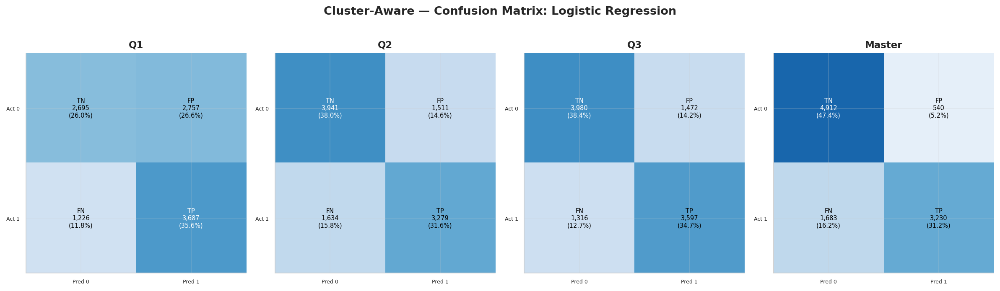

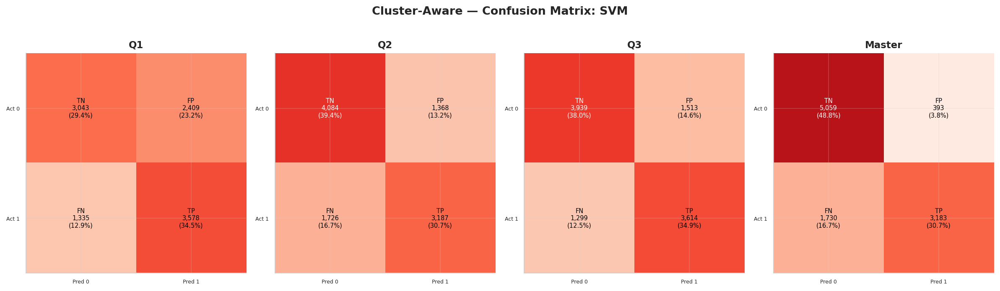

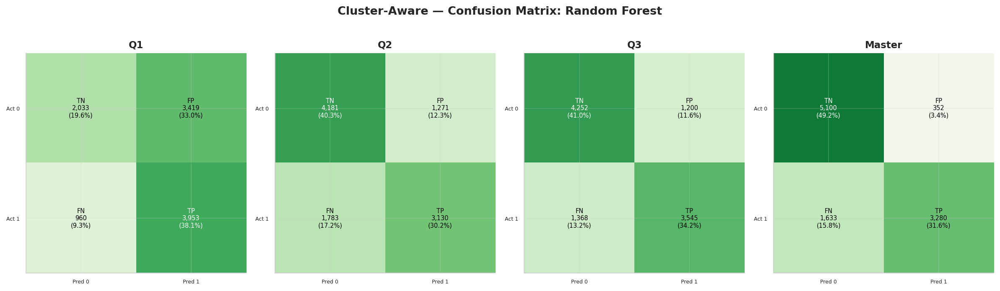

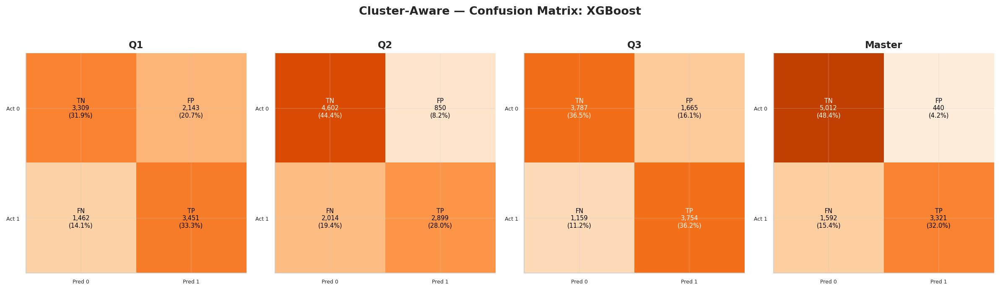

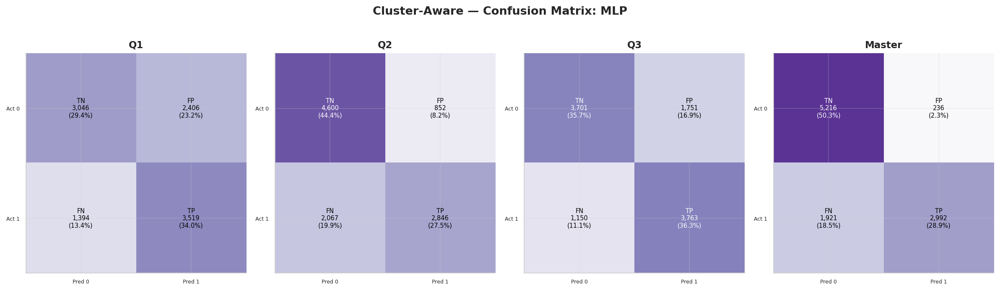

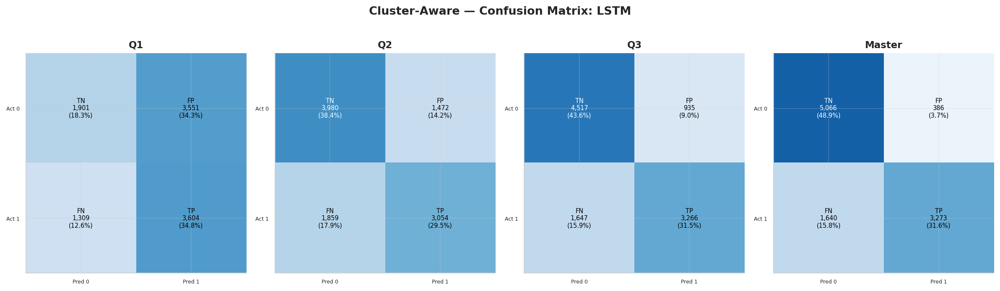

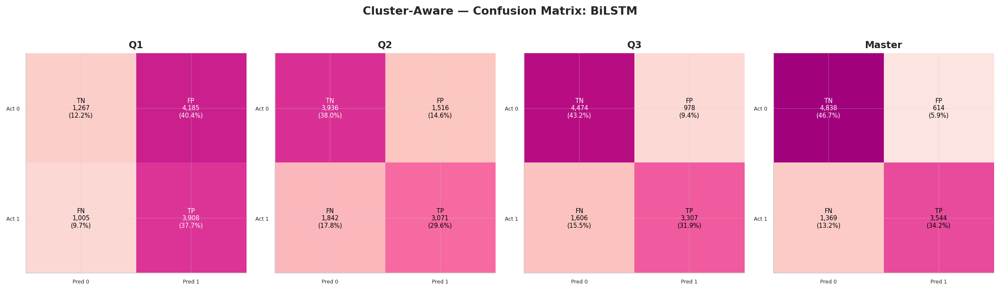

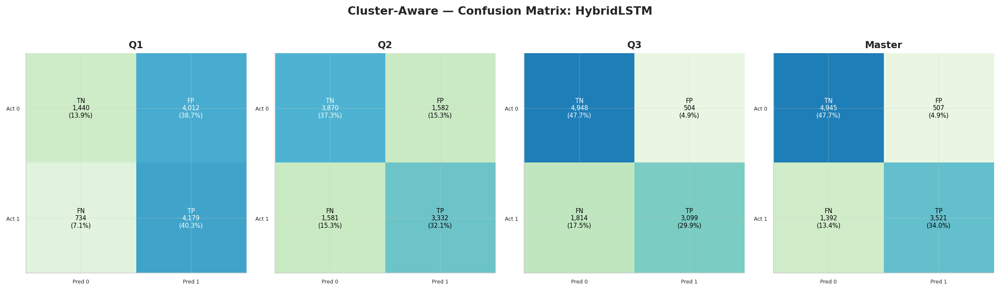

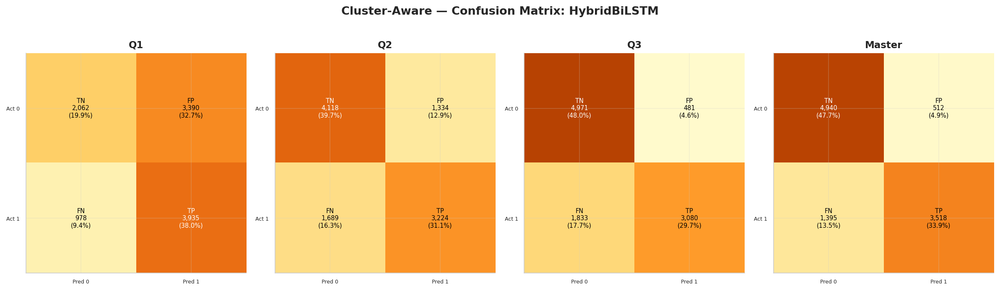

In [83]:
print("  S2-Fig6: Confusion matrices")

for model in ALL_MODELS:
    n_windows = len(WINDOWS)
    fig, axes_cm = plt.subplots(1, n_windows, figsize=(n_windows * 4, 4.5),
                                squeeze=False)
    fig.suptitle(f"Cluster-Aware — Confusion Matrix: {model}",
                 fontsize=13, fontweight="bold", y=1.02)

    for c, window in enumerate(WINDOWS):
        ax = axes_cm[0, c]
        draw_cm(ax,
                get_val_sec(2, window, model, "Accuracy"),
                get_val_sec(2, window, model, "Precision"),
                get_val_sec(2, window, model, "Recall"),
                cmap_per_model[model])
        ax.set_title(window, fontsize=11, fontweight="bold")

    plt.tight_layout()
    plt.show()

### Fig 7 — Radar Charts

  S2-Fig7: Radar charts per window


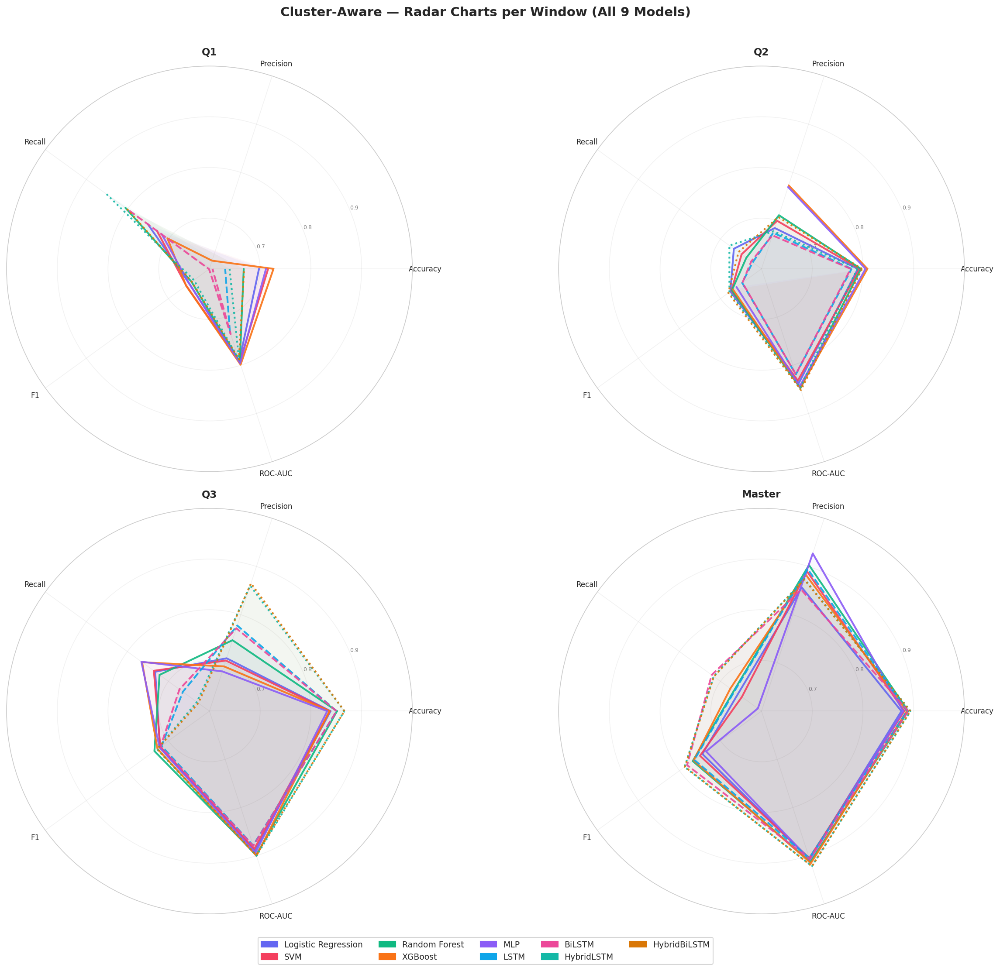

  Section 2 complete.



In [84]:
print("  S2-Fig7: Radar charts per window")
fig, axes_r = plt.subplots(2, 2, figsize=(18, 14), subplot_kw=dict(polar=True))
axes_r = axes_r.flatten()
fig.suptitle("Cluster-Aware — Radar Charts per Window (All 9 Models)",
             fontsize=14, fontweight="bold", y=1.01)
for ax, window in zip(axes_r, WINDOWS):
    for model in MODELS:
        vals = [get_val_sec(2,window,model,m) for m in rad_metrics] + \
               [get_val_sec(2,window,model,rad_metrics[0])]
        ax.plot(angles, vals, color=MODEL_COLORS[model], lw=2,
                linestyle=line_styles[model], alpha=0.9)
        ax.fill(angles, vals, color=MODEL_COLORS[model], alpha=0.04)
    ax.set_xticks(angles[:-1]); ax.set_xticklabels(rad_metrics, fontsize=8)
    ax.set_ylim(0.60, 1.0); ax.set_yticks([0.7,0.8,0.9])
    ax.set_yticklabels(["0.7","0.8","0.9"], fontsize=6, color="gray")
    ax.set_title(window, fontsize=11, fontweight="bold", pad=12)
fig.legend(handles=[mpatches.Patch(color=MODEL_COLORS[m], label=m) for m in MODELS],
           loc="lower center", ncol=5, fontsize=9, bbox_to_anchor=(0.5,-0.04))
plt.tight_layout(); plt.show()
print("  Section 2 complete.\n")

## Section 3 — Baseline vs Cluster-Aware


### Fig 1 — F1: Baseline vs Cluster-Aware

S3-Fig1: F1 Baseline vs Cluster-Aware


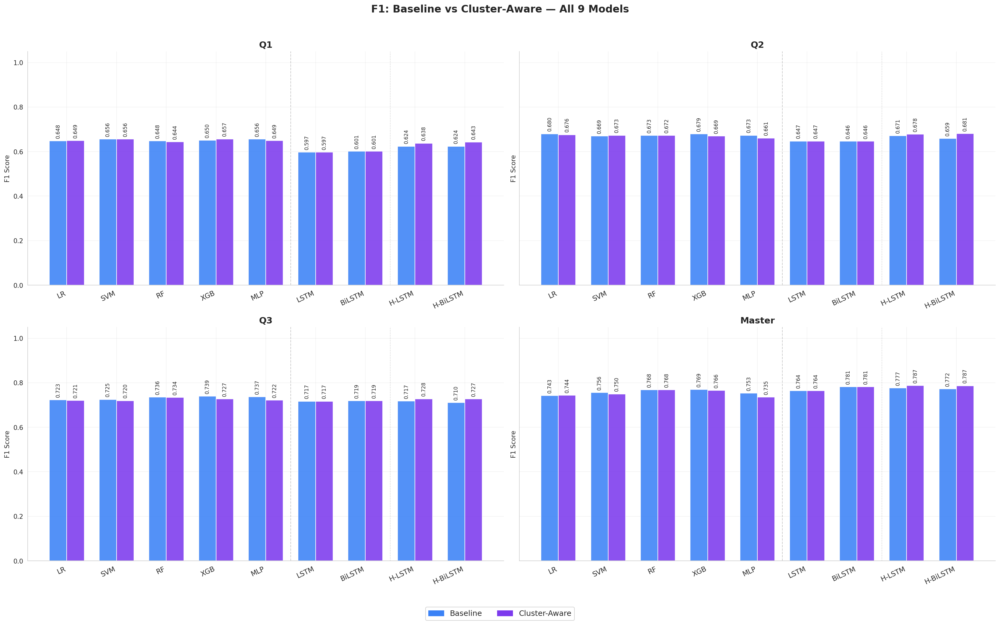


Q1 F1 comparison:
Logistic Regression    Baseline=0.6480  CAF=0.6493
SVM                    Baseline=0.6559  CAF=0.6565
Random Forest          Baseline=0.6482  CAF=0.6436
XGBoost                Baseline=0.6505  CAF=0.6569
MLP                    Baseline=0.6560  CAF=0.6494
LSTM                   Baseline=0.5973  CAF=0.5973
BiLSTM                 Baseline=0.6010  CAF=0.6010
HybridLSTM             Baseline=0.6238  CAF=0.6378
HybridBiLSTM           Baseline=0.6238  CAF=0.6431

Q2 F1 comparison:
Logistic Regression    Baseline=0.6799  CAF=0.6759
SVM                    Baseline=0.6693  CAF=0.6732
Random Forest          Baseline=0.6728  CAF=0.6721
XGBoost                Baseline=0.6789  CAF=0.6694
MLP                    Baseline=0.6732  CAF=0.6610
LSTM                   Baseline=0.6471  CAF=0.6471
BiLSTM                 Baseline=0.6465  CAF=0.6465
HybridLSTM             Baseline=0.6710  CAF=0.6782
HybridBiLSTM           Baseline=0.6588  CAF=0.6808


In [ ]:
print("S3-Fig1: F1 Baseline vs Cluster-Aware")

width2 = 0.35

fig, axes = plt.subplots(
    2, 2, figsize=(22, 14), sharey=True
)
axes = axes.flatten()

fig.suptitle(
    "F1: Baseline vs Cluster-Aware — All 9 Models",
    fontsize=16,
    fontweight="bold"
)

for ax, window in zip(axes, WINDOWS):

    b_vals = np.array([
        get_val_sec(1, window, m, "F1")
        for m in MODELS
    ], dtype=float)

    c_vals = np.array([
        get_val_sec(2, window, m, "F1")
        for m in MODELS
    ], dtype=float)

    # Report genuinely missing results
    for model, b, c in zip(MODELS, b_vals, c_vals):
        if not np.isfinite(b):
            print(f"Missing BASELINE: {window} / {model}")
        if not np.isfinite(c):
            print(f"Missing CAF: {window} / {model}")

    bars_base = ax.bar(
        x_all - width2 / 2,
        b_vals,
        width2,
        color=BASE_COL,
        alpha=0.88,
        edgecolor="white",
        label="Baseline"
    )

    bars_caf = ax.bar(
        x_all + width2 / 2,
        c_vals,
        width2,
        color=CLUS_COL,
        alpha=0.88,
        edgecolor="white",
        label="Cluster-Aware"
    )

    ax.set_xticks(x_all)
    ax.set_xticklabels(
        [MODEL_SHORT[m] for m in MODELS],
        fontsize=11,
        rotation=25,
        ha="right"
    )

    ax.set_title(
        window,
        fontsize=14,
        fontweight="bold"
    )
    ax.set_ylabel("F1 Score")

    # FIX: Show the full bar heights
    ax.set_ylim(0.0, 1.05)

    # Labels above bars
    for bars, values in [
        (bars_base, b_vals),
        (bars_caf, c_vals)
    ]:
        for bar, value in zip(bars, values):
            if np.isfinite(value):
                ax.text(
                    bar.get_x() + bar.get_width() / 2,
                    value + 0.012,
                    f"{value:.3f}",
                    ha="center",
                    va="bottom",
                    fontsize=8,
                    rotation=90
                )

    ax.axvline(
        4.5, color="gray", lw=1,
        linestyle="--", alpha=0.4
    )
    ax.axvline(
        6.5, color="gray", lw=1,
        linestyle=":", alpha=0.4
    )

    ax.grid(axis="y", alpha=0.25)

fig.legend(
    handles=[
        mpatches.Patch(
            color=BASE_COL, label="Baseline"
        ),
        mpatches.Patch(
            color=CLUS_COL, label="Cluster-Aware"
        )
    ],
    loc="lower center",
    ncol=2,
    fontsize=12,
    bbox_to_anchor=(0.5, 0.01)
)

plt.tight_layout(rect=[0, 0.06, 1, 0.96])
plt.show()

# Explicitly verify Q1/Q2 values
for window in ["Q1", "Q2"]:
    print(f"\n{window} F1 comparison:")
    for model in MODELS:
        baseline = get_val_sec(1, window, model, "F1")
        caf = get_val_sec(2, window, model, "F1")
        print(
            f"{model:22s} "
            f"Baseline={baseline:.4f}  "
            f"CAF={caf:.4f}"
        )


### Fig 1b — Accuracy : Baseline vs Cluster-Aware

  S3-Fig1b: Accuracy side-by-side comparison


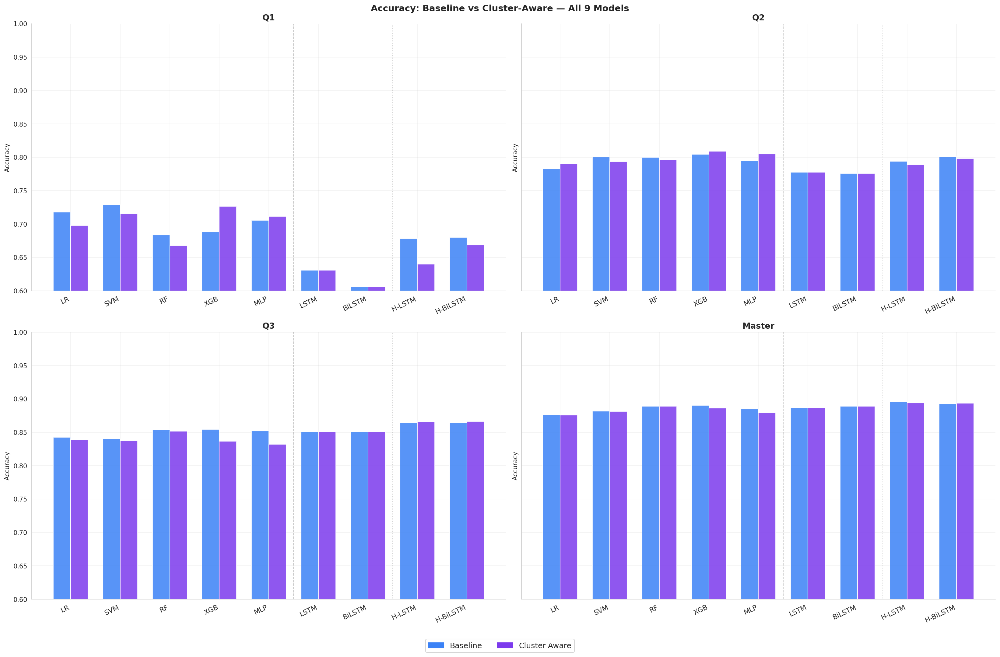

In [86]:
print("  S3-Fig1b: Accuracy side-by-side comparison")
width2 = 0.35
patches_bc = [mpatches.Patch(color=BASE_COL, label="Baseline"),
              mpatches.Patch(color=CLUS_COL, label="Cluster-Aware")]
fig, axes = plt.subplots(2, 2, figsize=(22, 14), sharey=True)
axes = axes.flatten()
fig.suptitle("Accuracy: Baseline vs Cluster-Aware — All 9 Models",
             fontsize=14, fontweight="bold")
for ax, window in zip(axes, WINDOWS):
    b_vals = [get_val_sec(1, window, m, "Accuracy") for m in MODELS]
    c_vals = [get_val_sec(2, window, m, "Accuracy") for m in MODELS]
    ax.bar(x_all - width2/2, b_vals, width2, color=BASE_COL,  alpha=0.85, edgecolor="white")
    ax.bar(x_all + width2/2, c_vals, width2, color=CLUS_COL, alpha=0.85, edgecolor="white")
    ax.set_xticks(x_all)
    ax.set_xticklabels([MODEL_SHORT[m] for m in MODELS], fontsize=11, rotation=25, ha="right")
    ax.set_title(window, fontsize=13, fontweight="bold")
    ax.set_ylabel("Accuracy"); fmt_ax(ax, (0.60, 1.0))
    ax.axvline(4.5, color="gray", lw=1, linestyle="--", alpha=0.4)
    ax.axvline(6.5, color="gray", lw=1, linestyle=":", alpha=0.4)
fig.legend(handles=patches_bc, loc="lower center", ncol=2,
           fontsize=12, bbox_to_anchor=(0.5, -0.04))
plt.tight_layout(); plt.show()

### Fig 2 — ROC-AUC: Baseline vs Cluster-Aware

S3-Fig2: ROC-AUC — Baseline vs Cluster-Aware


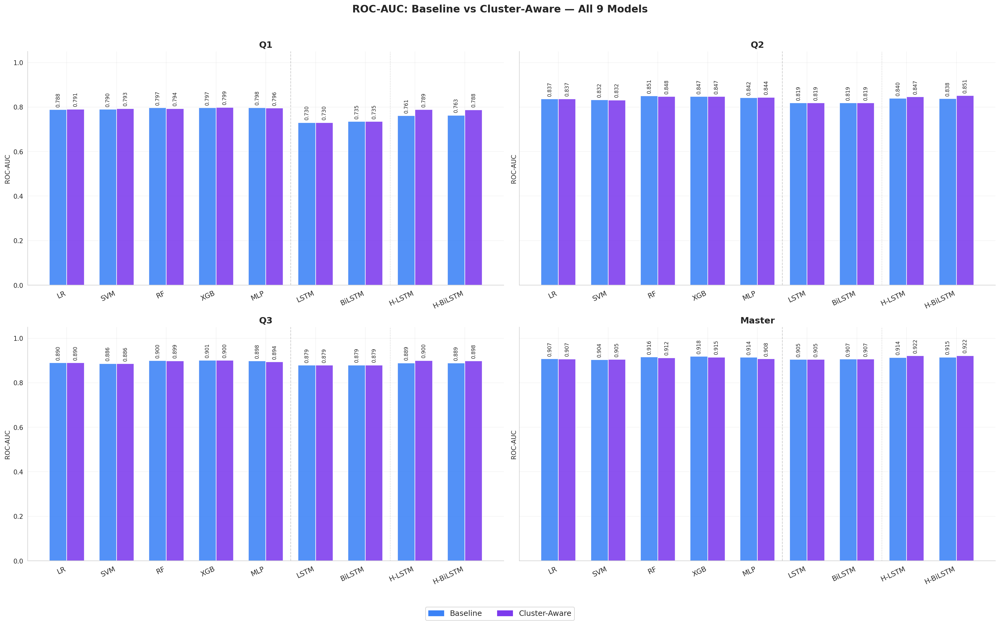


Q1 ROC-AUC values:
Logistic Regression    Baseline=0.7884  CAF=0.7909
SVM                    Baseline=0.7903  CAF=0.7934
Random Forest          Baseline=0.7972  CAF=0.7936
XGBoost                Baseline=0.7969  CAF=0.7989
MLP                    Baseline=0.7977  CAF=0.7957
LSTM                   Baseline=0.7304  CAF=0.7304
BiLSTM                 Baseline=0.7353  CAF=0.7353
HybridLSTM             Baseline=0.7615  CAF=0.7886
HybridBiLSTM           Baseline=0.7634  CAF=0.7879


In [124]:

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

print("S3-Fig2: ROC-AUC — Baseline vs Cluster-Aware")

width2 = 0.35
x_positions = np.arange(len(MODELS))

fig, axes = plt.subplots(
    2, 2, figsize=(22, 14), sharey=True
)
axes = axes.flatten()

fig.suptitle(
    "ROC-AUC: Baseline vs Cluster-Aware — All 9 Models",
    fontsize=16,
    fontweight="bold"
)

for ax, window in zip(axes, WINDOWS):

    b_vals = np.array([
        get_val_sec(1, window, m, "ROC-AUC")
        for m in MODELS
    ], dtype=float)

    c_vals = np.array([
        get_val_sec(2, window, m, "ROC-AUC")
        for m in MODELS
    ], dtype=float)

    # Check for missing results
    for model, b, c in zip(MODELS, b_vals, c_vals):
        if not np.isfinite(b):
            print(f"Missing BASELINE: {window} / {model}")
        if not np.isfinite(c):
            print(f"Missing CLUSTER-AWARE: {window} / {model}")

    bars_base = ax.bar(
        x_positions - width2 / 2,
        b_vals,
        width2,
        color=BASE_COL,
        alpha=0.88,
        edgecolor="white",
        label="Baseline"
    )

    bars_caf = ax.bar(
        x_positions + width2 / 2,
        c_vals,
        width2,
        color=CLUS_COL,
        alpha=0.88,
        edgecolor="white",
        label="Cluster-Aware"
    )

    ax.set_xticks(x_positions)
    ax.set_xticklabels(
        [MODEL_SHORT[m] for m in MODELS],
        fontsize=11,
        rotation=25,
        ha="right"
    )

    ax.set_title(window, fontsize=14, fontweight="bold")
    ax.set_ylabel("ROC-AUC")

    # FIX: Display full height of all bars
    ax.set_ylim(0.0, 1.05)

    # Add numerical labels
    for bars, values in [
        (bars_base, b_vals),
        (bars_caf, c_vals)
    ]:
        for bar, value in zip(bars, values):
            if np.isfinite(value):
                ax.text(
                    bar.get_x() + bar.get_width() / 2,
                    value + 0.012,
                    f"{value:.3f}",
                    ha="center",
                    va="bottom",
                    fontsize=8,
                    rotation=90
                )

    ax.axvline(
        4.5, color="gray", lw=1,
        linestyle="--", alpha=0.4
    )
    ax.axvline(
        6.5, color="gray", lw=1,
        linestyle=":", alpha=0.4
    )

    ax.grid(axis="y", alpha=0.25)

fig.legend(
    handles=[
        mpatches.Patch(color=BASE_COL, label="Baseline"),
        mpatches.Patch(color=CLUS_COL, label="Cluster-Aware")
    ],
    loc="lower center",
    ncol=2,
    fontsize=12,
    bbox_to_anchor=(0.5, 0.01)
)

plt.tight_layout(rect=[0, 0.06, 1, 0.96])
plt.show()

# Verify actual Q1 values being plotted
print("\nQ1 ROC-AUC values:")
for model in MODELS:
    b = get_val_sec(1, "Q1", model, "ROC-AUC")
    c = get_val_sec(2, "Q1", model, "ROC-AUC")
    print(f"{model:22s} Baseline={b}  CAF={c}")


### Fig 3 — Delta Heatmap (Cluster − Baseline)

  S3-Fig3: Delta heatmap — Cluster minus Baseline (tabular models)


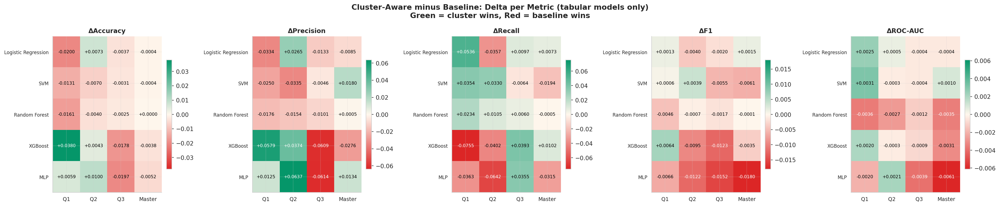

In [88]:
print("  S3-Fig3: Delta heatmap — Cluster minus Baseline (tabular models)")
MODELS_TAB = ["Logistic Regression","SVM","Random Forest","XGBoost","MLP"]
div_cmap = LinearSegmentedColormap.from_list("div", [RED,"#FFF7ED",GREEN])
fig, axes = plt.subplots(1, len(METRICS), figsize=(24, 5))
fig.suptitle("Cluster-Aware minus Baseline: Delta per Metric (tabular models only)\n"
             "Green = cluster wins, Red = baseline wins",
             fontsize=13, fontweight="bold")
for ax, metric in zip(axes, METRICS):
    delta = np.array([[gv(df_clus,w,m,metric) - gv(df_base,w,m,metric)
                       for w in WINDOWS] for m in MODELS_TAB])
    lim = max(abs(delta.max()), abs(delta.min()), 0.003)
    im  = ax.imshow(delta, cmap=div_cmap, vmin=-lim, vmax=lim, aspect="auto")
    ax.set_xticks(range(len(WINDOWS))); ax.set_xticklabels(WINDOWS, fontsize=9)
    ax.set_yticks(range(len(MODELS_TAB))); ax.set_yticklabels(MODELS_TAB, fontsize=8)
    ax.set_title(f"Δ{metric}", fontsize=11, fontweight="bold")
    for i in range(len(MODELS_TAB)):
        for j in range(len(WINDOWS)):
            v = delta[i,j]
            ax.text(j, i, f"{v:+.4f}", ha="center", va="center", fontsize=7.5,
                    color="white" if abs(v)>lim*0.55 else "black")
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout(); plt.show()

### Fig 4 — Per-Model Line Charts

Loaded C:\Users\Anushree\Documents\PythonProjects\OULAD\oulad-clustered-student-engagement\notebooks\results_tuned_baseline.csv
Loaded C:\Users\Anushree\Documents\PythonProjects\OULAD\oulad-clustered-student-engagement\notebooks\results_tuned_caf.csv

Q1/Q2 values used (CSV-derived when present):
Window               Model  Baseline F1  CAF F1  Baseline ROC-AUC  CAF ROC-AUC
    Q1 Logistic Regression       0.6480  0.6493            0.7884       0.7909
    Q1                 SVM       0.6559  0.6565            0.7903       0.7934
    Q1       Random Forest       0.6482  0.6436            0.7972       0.7936
    Q1             XGBoost       0.6505  0.6569            0.7969       0.7989
    Q1                 MLP       0.6560  0.6494            0.7977       0.7957
    Q2 Logistic Regression       0.6799  0.6759            0.8368       0.8373
    Q2                 SVM       0.6693  0.6732            0.8322       0.8319
    Q2       Random Forest       0.6728  0.6721            0.8506     

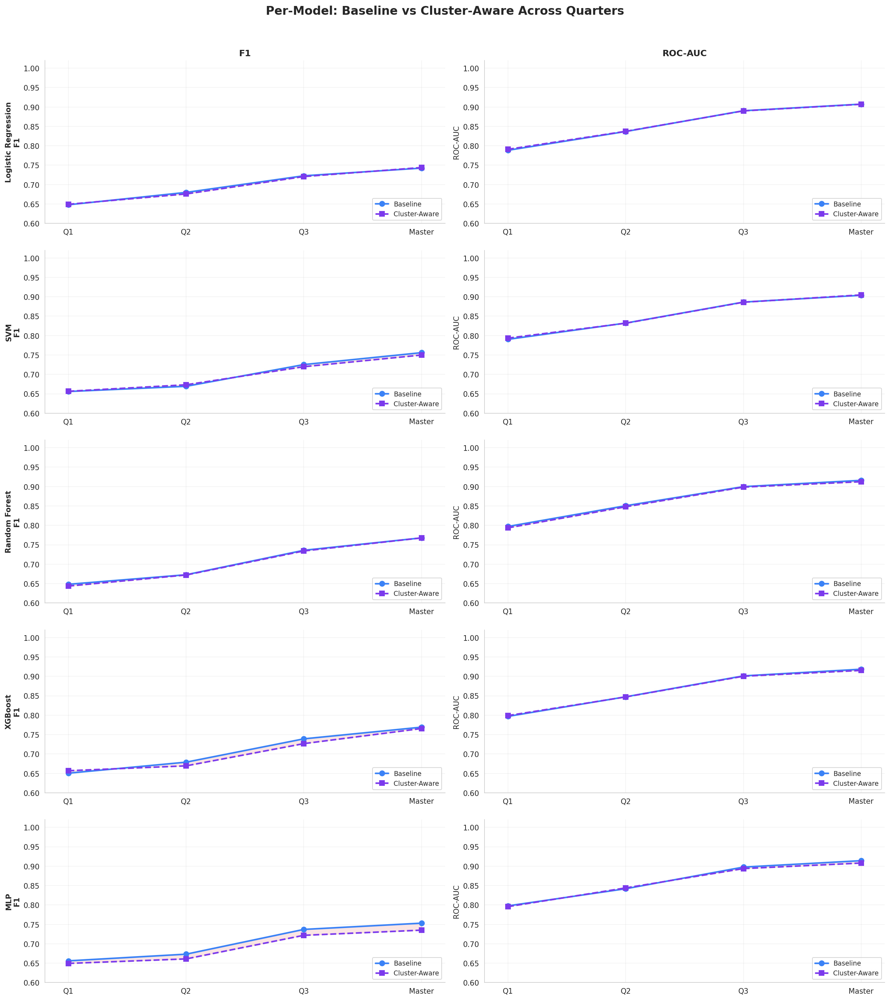

In [125]:
MODEL_NAMES = ["Logistic Regression", "SVM", "Random Forest", "XGBoost", "MLP"]
WINDOW_NAMES = ["Q1", "Q2", "Q3", "Master"]
METRIC_NAMES = ["F1", "ROC-AUC"]
BASE_COLOR, CAF_COLOR = "#3B82F6", "#7C3AED"


def load_results(filename, fallback_name):
    # Check notebook folder first, then common adjacent directories.
    cwd = Path.cwd()
    candidates = [cwd / filename, cwd.parent / filename,
                  cwd / "results" / filename, cwd.parent / "results" / filename]
    for path in candidates:
        if path.is_file():
            print(f"Loaded {path.resolve()}")
            return pd.read_csv(path)
    source = globals().get(fallback_name)
    if isinstance(source, pd.DataFrame):
        print(f"Using in-memory {fallback_name} (CSV not found)")
        return source.copy()
    raise FileNotFoundError(
        f"Could not find {filename}. Put it beside this notebook, or run the "
        f"result-loading cell that defines {fallback_name}."
    )


def clean_results(df, name):
    cols = ["Window", "Model", "F1", "ROC-AUC"]
    absent = [c for c in cols if c not in df.columns]
    if absent:
        raise ValueError(f"{name} is missing columns: {absent}")
    out = df[cols].copy()
    out["Window"] = out["Window"].astype(str).str.strip().str.upper().replace({
        "MASTER": "Master", "Q1": "Q1", "Q2": "Q2", "Q3": "Q3"
    })
    out["Model"] = (out["Model"].astype(str).str.strip()
                    .str.replace(r"(?i)_tuned$", "", regex=True)
                    .str.replace(r"(?i)_CAF$", "", regex=True).str.strip())
    for metric in METRIC_NAMES:
        out[metric] = pd.to_numeric(out[metric], errors="coerce")
    out = out[out["Model"].isin(MODEL_NAMES) & out["Window"].isin(WINDOW_NAMES)]
    duplicates = out.duplicated(["Window", "Model"], keep=False)
    if duplicates.any():
        raise ValueError(f"{name}: duplicate (Window, Model) results. Resolve before plotting:\n"
                         f"{out.loc[duplicates, ['Window', 'Model']].to_string(index=False)}")
    return out.set_index(["Window", "Model"]).reindex(
        pd.MultiIndex.from_product([WINDOW_NAMES, MODEL_NAMES], names=["Window", "Model"])
    )


base = clean_results(load_results("results_tuned_baseline.csv", "df_base"), "Baseline")
caf = clean_results(load_results("results_tuned_caf.csv", "df_clus"), "Cluster-Aware")

# Print missing data before drawing anything; missing cannot be fixed by changing axes.
for label, data in [("Baseline", base), ("Cluster-Aware", caf)]:
    for metric in METRIC_NAMES:
        missing = data.index[data[metric].isna()].tolist()
        if missing:
            print(f"WARNING: {label} {metric} missing: {missing}")

print("\nQ1/Q2 values used (CSV-derived when present):")
rows = []
for w in ("Q1", "Q2"):
    for model in MODEL_NAMES:
        rows.append({
            "Window": w, "Model": model,
            "Baseline F1": base.loc[(w, model), "F1"],
            "CAF F1": caf.loc[(w, model), "F1"],
            "Baseline ROC-AUC": base.loc[(w, model), "ROC-AUC"],
            "CAF ROC-AUC": caf.loc[(w, model), "ROC-AUC"],
        })
print(pd.DataFrame(rows).round(4).to_string(index=False))

x = np.arange(len(WINDOW_NAMES))
fig, axes = plt.subplots(len(MODEL_NAMES), 2, figsize=(17, 19), sharex=True)
fig.suptitle("Per-Model: Baseline vs Cluster-Aware Across Quarters",
             fontsize=16, fontweight="bold", y=0.997)

for row, model in enumerate(MODEL_NAMES):
    for col, metric in enumerate(METRIC_NAMES):
        ax = axes[row, col]
        b = np.array([base.loc[(w, model), metric] for w in WINDOW_NAMES], dtype=float)
        c = np.array([caf.loc[(w, model), metric] for w in WINDOW_NAMES], dtype=float)

        ax.plot(x, b, color=BASE_COLOR, marker="o", linewidth=2.2,
                markersize=7, label="Baseline")
        ax.plot(x, c, color=CAF_COLOR, marker="s", linewidth=2.2,
                markersize=7, linestyle="--", label="Cluster-Aware")

        both_valid = np.isfinite(b) & np.isfinite(c)
        if both_valid.any():
            delta = c[both_valid] - b[both_valid]
            ax.fill_between(x, b, c, where=both_valid,
                            color="#059669" if delta.mean() >= 0 else "#DC2626",
                            alpha=0.12)

        # All Q1/Q2 values remain in view. The x-axis is explicitly pinned to all 4 quarters.
        ax.set_ylim(0.60, 1.02)
        ax.set_xlim(-0.2, 3.2)
        ax.set_xticks(x, WINDOW_NAMES)
        ax.tick_params(axis="x", labelbottom=True)
        ax.grid(alpha=0.25)
        ax.set_title(metric if row == 0 else "", fontsize=12, fontweight="bold")
        if col == 0:
            ax.set_ylabel(model + "\n" + metric, fontsize=10, fontweight="bold")
        else:
            ax.set_ylabel(metric, fontsize=10)
        ax.legend(loc="lower right", fontsize=9)

plt.tight_layout(rect=[0, 0, 1, 0.98], h_pad=2.0)
plt.show()


### Fig 5 — Best Score per Group

S3-Fig5: loading saved model results
  results_tuned_baseline.csv: C:\Users\Anushree\Documents\PythonProjects\OULAD\oulad-clustered-student-engagement\notebooks\results_tuned_baseline.csv
  results_tuned_caf.csv: C:\Users\Anushree\Documents\PythonProjects\OULAD\oulad-clustered-student-engagement\notebooks\results_tuned_caf.csv
  results_tuned_lstm_models.csv: C:\Users\Anushree\Documents\PythonProjects\OULAD\oulad-clustered-student-engagement\notebooks\results_tuned_lstm_models.csv
  results_tuned_hybrid_caf_models.csv: C:\Users\Anushree\Documents\PythonProjects\OULAD\oulad-clustered-student-engagement\notebooks\results_tuned_hybrid_caf_models.csv

Values used (especially Q1/Q2):
 Metric                       Series     Q1     Q2     Q3  Master
     F1      Best Baseline (tabular) 0.6560 0.6799 0.7390  0.7691
     F1 Best Cluster-Aware (tabular) 0.6569 0.6759 0.7341  0.7677
     F1                         LSTM 0.5973 0.6471 0.7168  0.7637
     F1                       BiLSTM 0.6010 0.64

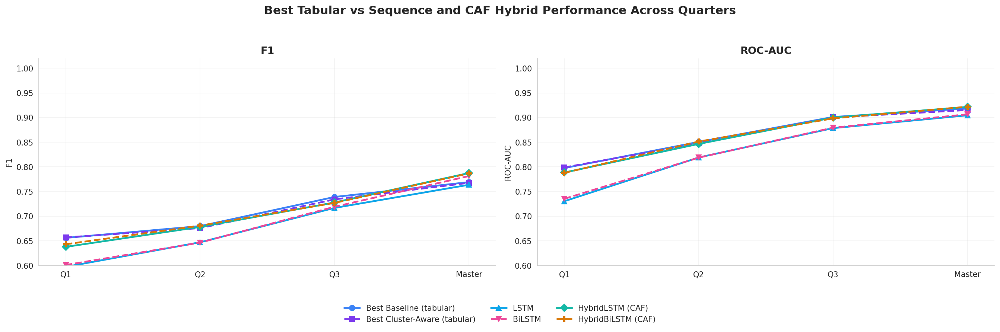

In [126]:
QUARTERS = ["Q1", "Q2", "Q3", "Master"]
METRICS = ["F1", "ROC-AUC"]
TABULAR = ["Logistic Regression", "SVM", "Random Forest", "XGBoost", "MLP"]
COLORS = {
    "Best Baseline (tabular)": "#3B82F6",
    "Best Cluster-Aware (tabular)": "#7C3AED",
    "LSTM": "#0EA5E9",
    "BiLSTM": "#EC4899",
    "HybridLSTM (CAF)": "#14B8A6",
    "HybridBiLSTM (CAF)": "#D97706",
}
FILES = {
    "Baseline tabular": ("results_tuned_baseline.csv", "df_base"),
    "CAF tabular": ("results_tuned_caf.csv", "df_clus"),
    "LSTM/BiLSTM": ("results_tuned_lstm_models.csv", "df_lstm"),
    "CAF hybrids": ("results_tuned_hybrid_caf_models.csv", "df_hybrid"),
}

def _read_s3f5(filename, variable):
    folder = Path.cwd()
    paths = [folder / filename, folder.parent / filename,
             folder / "results" / filename, folder.parent / "results" / filename]
    for path in paths:
        if path.is_file():
            print(f"  {filename}: {path.resolve()}")
            return pd.read_csv(path)
    existing = globals().get(variable)
    if isinstance(existing, pd.DataFrame):
        print(f"  {filename}: using in-memory {variable} (CSV not found)")
        return existing.copy()
    raise FileNotFoundError(f"{filename} not found. Put the results CSVs beside your notebook "
                            f"or run the cell creating {variable}.")

def _clean_s3f5(data, label):
    required = ["Window", "Model", "F1", "ROC-AUC"]
    missing = [x for x in required if x not in data.columns]
    if missing:
        raise ValueError(f"{label}: columns missing: {missing}")
    data = data[required].copy()
    data["Window"] = data["Window"].astype(str).str.strip().str.upper().replace({"MASTER": "Master"})
    data["Model"] = (data["Model"].astype(str).str.strip()
                     .str.replace(r"(?i)_tuned$", "", regex=True)
                     .str.replace(r"(?i)_CAF$", "", regex=True)
                     .str.strip())
    for metric in METRICS:
        data[metric] = pd.to_numeric(data[metric], errors="coerce")
    data = data[data["Window"].isin(QUARTERS)]
    if data.duplicated(["Window", "Model"]).any():
        duplicates = data.loc[data.duplicated(["Window", "Model"], keep=False), ["Window", "Model"]]
        raise ValueError(f"{label}: duplicate results:\n{duplicates.to_string(index=False)}")
    return data.set_index(["Window", "Model"])

print("S3-Fig5: loading saved model results")
data = {name: _clean_s3f5(_read_s3f5(*file_info), name)
        for name, file_info in FILES.items()}

def _value(table, window, model, metric):
    try:
        return float(table.loc[(window, model), metric])
    except KeyError:
        return float("nan")

def _best(table, window, models, metric):
    vals = np.array([_value(table, window, model, metric) for model in models], dtype=float)
    return float(np.max(vals[np.isfinite(vals)])) if np.isfinite(vals).any() else float("nan")

# Best baseline/CAF means the best of the five tabular models (same as original plot).
series = {}
for metric in METRICS:
    series[metric] = {
        "Best Baseline (tabular)": [_best(data["Baseline tabular"], w, TABULAR, metric) for w in QUARTERS],
        "Best Cluster-Aware (tabular)": [_best(data["CAF tabular"], w, TABULAR, metric) for w in QUARTERS],
        "LSTM": [_value(data["LSTM/BiLSTM"], w, "LSTM", metric) for w in QUARTERS],
        "BiLSTM": [_value(data["LSTM/BiLSTM"], w, "BiLSTM", metric) for w in QUARTERS],
        "HybridLSTM (CAF)": [_value(data["CAF hybrids"], w, "HybridLSTM", metric) for w in QUARTERS],
        "HybridBiLSTM (CAF)": [_value(data["CAF hybrids"], w, "HybridBiLSTM", metric) for w in QUARTERS],
    }

# Show data availability; no interpolation of absent results.
check = []
for metric, curves in series.items():
    for name, values in curves.items():
        missing = [q for q, v in zip(QUARTERS, values) if not np.isfinite(v)]
        if missing:
            print(f"WARNING: {metric} / {name} missing {missing}")
        check.append({"Metric": metric, "Series": name,
                      **{q: v for q, v in zip(QUARTERS, values)}})
check_df = pd.DataFrame(check)
print("\nValues used (especially Q1/Q2):")
print(check_df.round(4).to_string(index=False))

x = np.arange(4)
fig, axes = plt.subplots(1, 2, figsize=(18, 6), sharex=True)
fig.suptitle("Best Tabular vs Sequence and CAF Hybrid Performance Across Quarters",
             fontsize=15, fontweight="bold")
styles = ["-", "--", "-", "--", "-", "--"]
markers = ["o", "s", "^", "v", "D", "P"]
for ax, metric in zip(axes, METRICS):
    for (label, vals), style, marker in zip(series[metric].items(), styles, markers):
        ax.plot(x, vals, color=COLORS[label], linestyle=style,
                marker=marker, lw=2.3, ms=7, label=label)
    ax.set_title(metric, fontsize=13, fontweight="bold")
    ax.set_ylabel(metric)
    ax.set_xticks(x, QUARTERS)
    ax.set_xlim(-0.20, 3.2)
    ax.set_ylim(0.60, 1.02)  # includes all known Q1/Q2 scores
    ax.grid(alpha=0.25)

# Avoid upper-left legend covering Q1 and Q2 points.
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, fontsize=10,
           bbox_to_anchor=(0.5, 0.01), frameon=False)
fig.tight_layout(rect=[0, 0.14, 1, 0.94])
plt.show()


### Fig 6 — Win / Tie / Loss Tally

  S3-Fig6: Win / Tie / Loss tally


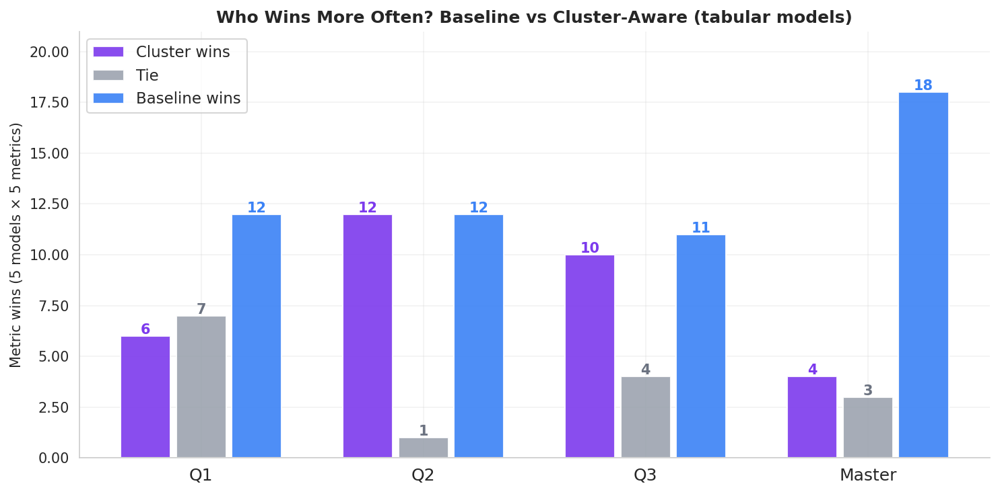

In [91]:
print("  S3-Fig6: Win / Tie / Loss tally")
records = []
for window in WINDOWS:
    for model in MODELS_TAB:
        for metric in METRICS:
            bv = gv(df_base, window, model, metric)
            cv = gv(df_clus, window, model, metric)
            d  = cv - bv
            records.append({"Window":window,"Model":model,"Metric":metric,
                             "Winner":"Cluster" if d>0.001 else "Baseline" if d<-0.001 else "Tie"})
rec_df  = pd.DataFrame(records)
summary = rec_df.groupby(["Window","Winner"]).size().unstack(fill_value=0)
for col in ["Cluster","Baseline","Tie"]:
    if col not in summary.columns: summary[col] = 0
summary = summary[["Cluster","Tie","Baseline"]]
fig, ax = plt.subplots(figsize=(10, 5))
w_bar = 0.25; x_w = np.arange(len(WINDOWS))
ax.bar(x_w-w_bar, summary["Cluster"],  w_bar*0.9, color=CLUS_COL,  label="Cluster wins",  alpha=0.9)
ax.bar(x_w,        summary["Tie"],      w_bar*0.9, color="#9CA3AF", label="Tie",            alpha=0.9)
ax.bar(x_w+w_bar,  summary["Baseline"],w_bar*0.9, color=BASE_COL,  label="Baseline wins", alpha=0.9)
for i, (ci,ti,bi) in enumerate(zip(summary["Cluster"],summary["Tie"],summary["Baseline"])):
    ax.text(i-w_bar, ci+0.1, str(ci), ha="center", fontsize=10, fontweight="bold", color=CLUS_COL)
    ax.text(i,        ti+0.1, str(ti), ha="center", fontsize=10, fontweight="bold", color="#6B7280")
    ax.text(i+w_bar,  bi+0.1, str(bi), ha="center", fontsize=10, fontweight="bold", color=BASE_COL)
ax.set_xticks(x_w); ax.set_xticklabels(WINDOWS, fontsize=12)
ax.set_ylabel("Metric wins (5 models × 5 metrics)", fontsize=10)
ax.set_title("Who Wins More Often? Baseline vs Cluster-Aware (tabular models)",
             fontsize=12, fontweight="bold")
ax.legend(fontsize=11); fmt_ax(ax, (0, summary.values.max()+3))
plt.tight_layout(); plt.show()

### Fig 7 — Final Winner Summary

S3-Fig7: Final winner summary


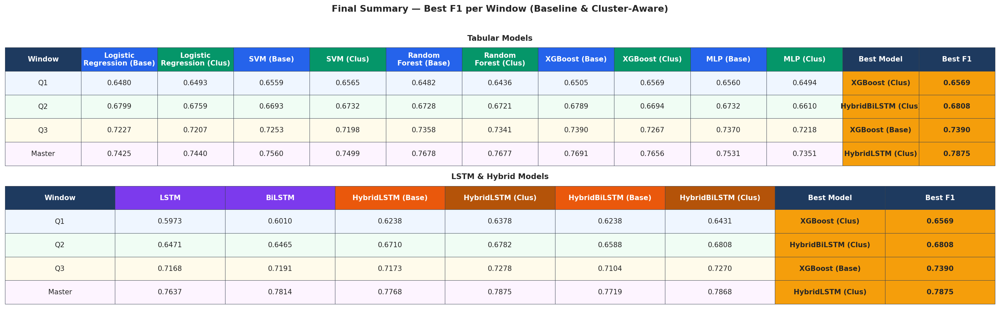

In [92]:
print("S3-Fig7: Final winner summary")

def make_summary_table(ax, sum_df, title, header_colors):
    ax.axis("off")
    tbl = ax.table(
        cellText=sum_df.values,
        colLabels=sum_df.columns,
        cellLoc="center",
        loc="center",
        bbox=[0, 0, 1, 1]
    )
    tbl.auto_set_font_size(False)
    tbl.set_fontsize(10)
    tbl.scale(1, 2.2)

    for j, col in enumerate(sum_df.columns):
        tbl[0, j].set_facecolor(header_colors.get(col, "#1E3A5F"))
        tbl[0, j].set_text_props(color="white", fontweight="bold")

    for i in range(1, len(sum_df) + 1):
        bg = win_bg.get(sum_df.iloc[i - 1]["Window"], "white")
        for j in range(len(sum_df.columns)):
            tbl[i, j].set_facecolor(bg)
        # highlight best F1 columns
        for j in [len(sum_df.columns) - 1, len(sum_df.columns) - 2]:
            tbl[i, j].set_facecolor("#F59E0B")
            tbl[i, j].set_text_props(fontweight="bold")

    for key, cell in tbl.get_celld().items():
        cell.set_edgecolor("#374151")
        cell.set_linewidth(0.5)

    ax.set_title(title, fontsize=11, fontweight="bold", pad=10)

tab_rows, deep_rows = [], []

for window in WINDOWS:
    tab_row  = {"Window": window}
    deep_row = {"Window": window}

    for m in MODELS_TAB:
        tab_row[f"{m} (Base)"] = gv(df_base, window, m, "F1")
        tab_row[f"{m} (Clus)"] = gv(df_clus, window, m, "F1")

    for m in ["LSTM", "BiLSTM"]:
        deep_row[m] = gv(df_lstm, window, m, "F1")

    for m in ["HybridLSTM", "HybridBiLSTM"]:
        deep_row[f"{m} (Base)"] = gv(df_hybrid_base, window, m, "F1")
        deep_row[f"{m} (Clus)"] = gv(df_hybrid, window, m, "F1")

    all_vals = {**{k: v for k, v in tab_row.items() if k != "Window"},
                **{k: v for k, v in deep_row.items() if k != "Window"}}
    best_key = max(all_vals, key=lambda k: all_vals[k] if not pd.isna(all_vals[k]) else -1)
    best_f1  = f"{all_vals[best_key]:.4f}"

    tab_row["Best Model"]  = best_key
    tab_row["Best F1"]     = best_f1
    deep_row["Best Model"] = best_key
    deep_row["Best F1"]    = best_f1

    tab_rows.append(tab_row)
    deep_rows.append(deep_row)

def fmt_df(rows):
    df = pd.DataFrame(rows)
    df.columns = [c.replace("Logistic Regression", "Logistic\nRegression")
                   .replace("Random Forest", "Random\nForest") 
                  for c in df.columns]
    num_cols = [c for c in df.columns if c not in ["Window", "Best Model", "Best F1"]]
    for c in num_cols:
        df[c] = df[c].map(lambda v: f"{v:.4f}" if not pd.isna(v) else "—")
    return df

tab_df  = fmt_df(tab_rows)
deep_df = fmt_df(deep_rows)

tab_colors = {"Window": "#1E3A5F", "Best Model": "#1E3A5F", "Best F1": "#1E3A5F"}
for m in MODELS_TAB:
    wrapped = m.replace("Logistic Regression", "Logistic\nRegression").replace("Random Forest", "Random\nForest")
    tab_colors[f"{wrapped} (Base)"] = "#2563EB"
    tab_colors[f"{wrapped} (Clus)"] = "#059669"

deep_colors = {"Window": "#1E3A5F", "Best Model": "#1E3A5F", "Best F1": "#1E3A5F",
               "LSTM": "#7C3AED", "BiLSTM": "#7C3AED"}
for m in ["HybridLSTM", "HybridBiLSTM"]:
    deep_colors[f"{m} (Base)"] = "#EA580C"
    deep_colors[f"{m} (Clus)"] = "#B45309"

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(20, 6))
fig.suptitle("Final Summary — Best F1 per Window (Baseline & Cluster-Aware)",
             fontsize=13, fontweight="bold", y=1.02)

make_summary_table(ax1, tab_df,  "Tabular Models",       tab_colors)
make_summary_table(ax2, deep_df, "LSTM & Hybrid Models", deep_colors)

plt.tight_layout()
plt.show()

### Accuracy Trend Graph

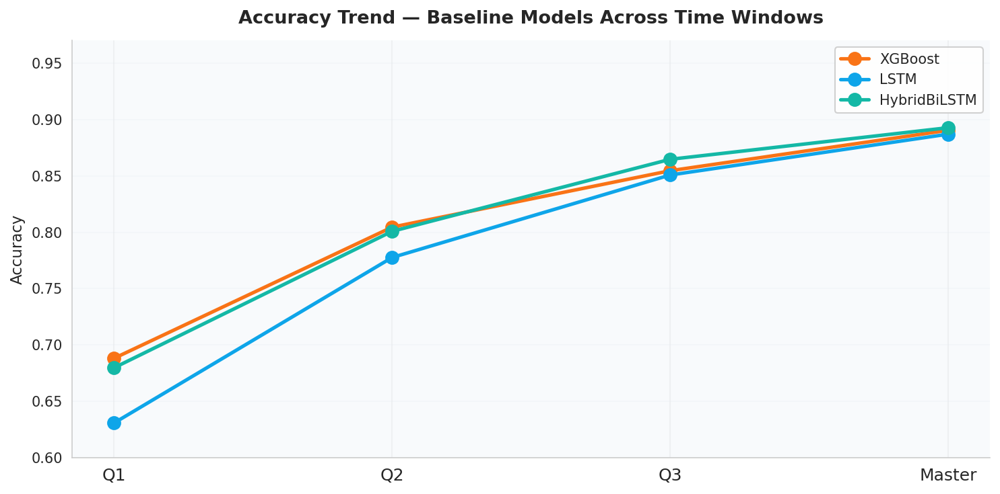

In [127]:
TREND_MODELS  = ["XGBoost", "LSTM", "HybridBiLSTM"]
TREND_COLORS  = {"XGBoost": "#F97316", "LSTM": "#0EA5E9", "HybridBiLSTM": "#14B8A6"}
x = np.arange(len(WINDOWS))

# pull accuracy for section 1 (baseline)
bl_acc = {}
for m in TREND_MODELS:
    vals = [get_val_sec(1, w, m, "Accuracy") for w in WINDOWS]
    if not all(np.isnan(v) for v in vals):
        bl_acc[m] = vals

fig, ax = plt.subplots(figsize=(10, 5))
fig.patch.set_facecolor("white")
ax.set_facecolor("#F8FAFC")
ax.grid(axis="y", color="#E2E8F0", linewidth=0.8, zorder=0)
ax.set_axisbelow(True)

for model, vals in bl_acc.items():
    col = TREND_COLORS[model]
    ax.plot(x, vals, marker="o", markersize=9, linewidth=2.5,
            color=col, label=model, zorder=3)

ax.set_xticks(x)
ax.set_xticklabels(WINDOWS, fontsize=12)
ax.set_ylim(0.60, 0.97)
ax.set_ylabel("Accuracy", fontsize=11)
ax.set_title("Accuracy Trend — Baseline Models Across Time Windows",
             fontsize=13, fontweight="bold", pad=12)
ax.legend(fontsize=10, framealpha=0.9)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

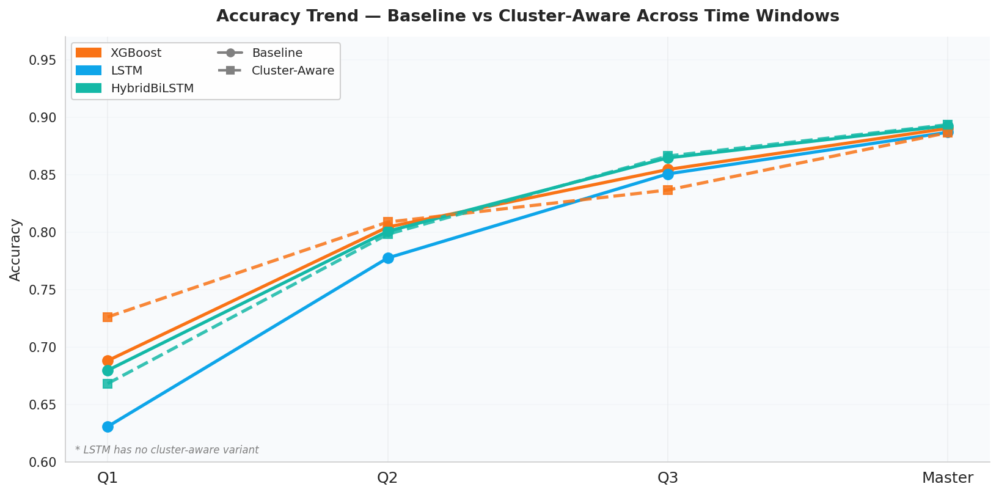

In [128]:
TREND_MODELS = ["XGBoost", "LSTM", "HybridBiLSTM"]
HAS_CLUSTER  = ["XGBoost", "HybridBiLSTM"]   # LSTM has no cluster variant
TREND_COLORS = {"XGBoost": "#F97316", "LSTM": "#0EA5E9", "HybridBiLSTM": "#14B8A6"}
x = np.arange(len(WINDOWS))

bl_acc, ca_acc = {}, {}
for m in TREND_MODELS:
    v_bl = [get_val_sec(1, w, m, "Accuracy") for w in WINDOWS]
    if not all(np.isnan(v) for v in v_bl):
        bl_acc[m] = v_bl

for m in HAS_CLUSTER:                         # only pull cluster for these two
    v_ca = [get_val_sec(2, w, m, "Accuracy") for w in WINDOWS]
    if not all(np.isnan(v) for v in v_ca):
        ca_acc[m] = v_ca

fig, ax = plt.subplots(figsize=(11, 5.5))
fig.patch.set_facecolor("white")
ax.set_facecolor("#F8FAFC")
ax.grid(axis="y", color="#E2E8F0", linewidth=0.8, zorder=0)
ax.set_axisbelow(True)

for model, vals in bl_acc.items():
    col = TREND_COLORS[model]
    ax.plot(x, vals, marker="o", markersize=8, linewidth=2.5,
            color=col, linestyle="-", zorder=3)

for model, vals in ca_acc.items():
    col = TREND_COLORS[model]
    ax.plot(x, vals, marker="s", markersize=7, linewidth=2.5,
            color=col, linestyle="--", zorder=3, alpha=0.85)

ax.set_xticks(x)
ax.set_xticklabels(WINDOWS, fontsize=12)
ax.set_ylim(0.60, 0.97)
ax.set_ylabel("Accuracy", fontsize=11)
ax.set_title("Accuracy Trend — Baseline vs Cluster-Aware Across Time Windows",
             fontsize=13, fontweight="bold", pad=12)

handles = [mpatches.Patch(color=TREND_COLORS[m], label=m) for m in TREND_MODELS]
handles += [
    plt.Line2D([0],[0], color="grey", linewidth=2, linestyle="-",
               marker="o", markersize=6, label="Baseline"),
    plt.Line2D([0],[0], color="grey", linewidth=2, linestyle="--",
               marker="s", markersize=6, label="Cluster-Aware"),
]
ax.annotate("* LSTM has no cluster-aware variant",
            xy=(0.01, 0.02), xycoords="axes fraction",
            fontsize=8, color="grey", style="italic")
ax.legend(handles=handles, fontsize=9.5, ncol=2, framealpha=0.9, loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()


####   Explainability of Top Performing model

Course quarter cutoffs: Q1=10  Q2=20  Q3=30  Master=39 weeks

BEST MODEL PER WINDOW:
  Baseline  Q1     → MLP                       AUC=0.7977
  Baseline  Q2     → Random Forest             AUC=0.8506
  Baseline  Q3     → XGBoost                   AUC=0.9012
  Baseline  Master → XGBoost                   AUC=0.9184
  Cluster   Q1     → XGBoost                   AUC=0.7989
  Cluster   Q2     → HybridBiLSTM              AUC=0.8514
  Cluster   Q3     → HybridLSTM                AUC=0.9001
  Cluster   Master → HybridLSTM                AUC=0.9216

───────────────────────────────────────────────────────
  Baseline Q1  →  MLP  AUC=0.7977
───────────────────────────────────────────────────────
  ✓ top feature: n_missed_assessments_Q1  (31 total)

───────────────────────────────────────────────────────
  Baseline Q2  →  Random Forest  AUC=0.8506
───────────────────────────────────────────────────────
  ✓ top feature: n_missed_assessments_Q2  (32 total)

────────────────────────────────────────

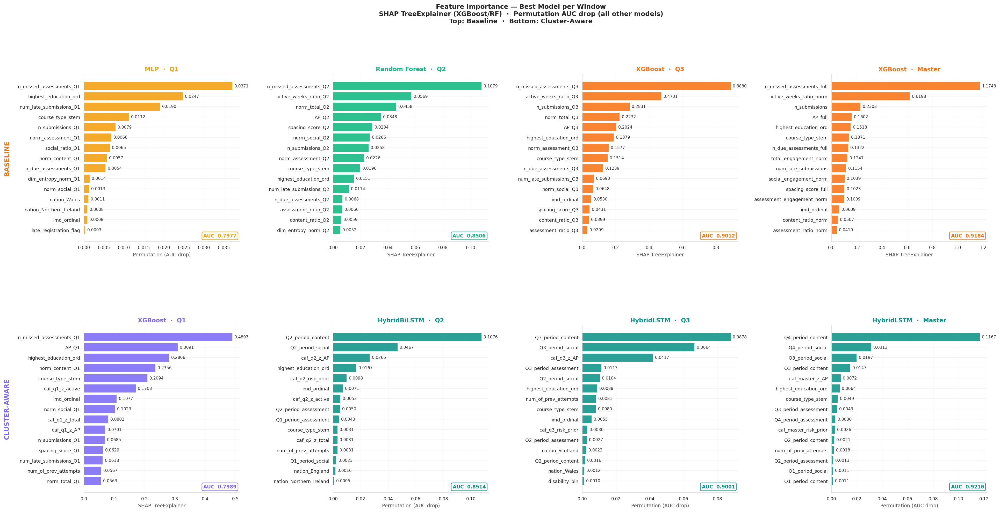

In [95]:
#error
# #feature importance

# single RNG source
import shap


RNG = np.random.default_rng(42)
torch.manual_seed(42)

TARGET      = "target_at_risk"
AUC_TIE_TOL = 0.002
TOP_N       = 15
N_BG        = 50
MAX_EXPLAIN = 200
N_REPEATS   = 5
KEYS        = ["id_student","code_module","code_presentation"]

TABULAR_MODELS = {"XGBoost","MLP","Random Forest","Logistic Regression","SVM"}
TREE_MODELS    = {"XGBoost","Random Forest"}
SEQ_MODELS     = {"LSTM","BiLSTM","HybridLSTM","HybridBiLSTM"}

WINDOWS_BASELINE = {
    "Q1":{"train":ml_Q1_train,"test":ml_Q1_test},
    "Q2":{"train":ml_Q2_train,"test":ml_Q2_test},
    "Q3":{"train":ml_Q3_train,"test":ml_Q3_test},
    "Master":{"train":ml_master_train,"test":ml_master_test},
}
WINDOWS_CAF = {
    "Q1":{"train":ml_Q1_train_caf,"test":ml_Q1_test_caf},
    "Q2":{"train":ml_Q2_train_caf,"test":ml_Q2_test_caf},
    "Q3":{"train":ml_Q3_train_caf,"test":ml_Q3_test_caf},
    "Master":{"train":ml_master_train_caf,"test":ml_master_test_caf},
}
# Keep the actual CAF feature lists produced by the preceding modelling cell.
# Overwriting them with SELECTED_FEATURES silently drops all CAF additions.
assert all(f"caf_{w.lower()}_risk_prior" in SELECTED_FEATURES_CLUSTER_AWARE_FINAL[w]
           for w in ("Q1", "Q2", "Q3", "Master")), "CAF feature lists were overwritten"

shap.initjs()

Q1_END  = int(course_windows["q1_end"].max())
Q2_END  = int(course_windows["q2_end"].max())
Q3_END  = int(course_windows["q3_end"].max())
Q4_END  = int(course_windows["q4_end"].max())

print(f"Course quarter cutoffs: Q1={Q1_END}  Q2={Q2_END}  "
      f"Q3={Q3_END}  Master={Q4_END} weeks")

# temporal grouping per window using actual cutoffs
TEMPORAL_GROUPS = {
    "Q1": [
        ("Early", 0, Q1_END),
    ],
    "Q2": [
        ("Q1_period", 0,      Q1_END),
        ("Q2_period", Q1_END, Q2_END),
    ],
    "Q3": [
        ("Q1_period", 0,      Q1_END),
        ("Q2_period", Q1_END, Q2_END),
        ("Q3_period", Q2_END, Q3_END),
    ],
    "Master": [
        ("Q1_period", 0,      Q1_END),
        ("Q2_period", Q1_END, Q2_END),
        ("Q3_period", Q2_END, Q3_END),
        ("Q4_period", Q3_END, Q4_END),
    ],
}

# load csv's
def _load(path):
    df = pd.read_csv(path, usecols=lambda c: c in
                     ["Window","Model","ROC-AUC","Accuracy","Best_Params"])
    df["Model"] = df["Model"].str.replace("_tuned","",regex=False)\
                             .str.replace("_CAF","",regex=False).str.strip()
    return df

df_b  = _load("results_tuned_baseline.csv")
df_c  = _load("results_tuned_caf.csv")
df_l  = _load("results_tuned_lstm_models.csv")
df_hb = _load("results_tuned_hybrid_models.csv")
df_hc = _load("results_tuned_hybrid_caf_models.csv")

# Best model per window
def best_model(dfs, window):
    rows = []
    for df in dfs:
        sub = df[df.Window==window].dropna(subset=["ROC-AUC","Accuracy"])
        for _,r in sub.iterrows():
            rows.append({"model":r.Model,
                         "auc":float(r["ROC-AUC"]),
                         "acc":float(r.Accuracy)})
    if not rows: raise ValueError(f"No results for {window}")
    rows = sorted(rows, key=lambda x:(x["auc"],x["acc"]), reverse=True)
    best = rows[0]
    if len(rows)>1 and abs(rows[0]["auc"]-rows[1]["auc"]) < AUC_TIE_TOL:
        best = max(rows[:2], key=lambda x: x["acc"])
    return best["model"], round(best["auc"],4)

PANELS = {}
for exp, dfs in [
    ("Baseline", [df_b, df_l, df_hb]),
    ("Cluster",  [df_c, df_hc]),
]:
    for window in ["Q1","Q2","Q3","Master"]:
        model, auc = best_model(dfs, window)
        PANELS[(exp,window)] = {"model":model,"auc":auc}

print("\nBEST MODEL PER WINDOW:")
for (exp,win),v in PANELS.items():
    print(f"  {exp:9s} {win:6s} → {v['model']:25s} AUC={v['auc']:.4f}")

# Param loader
_DEF = {"hidden_size":64,"num_layers":2,"dropout":0.3,
        "static_hidden_dim":32,"clf_hidden_dim":64,
        "lr":1e-3,"batch_size":256,"weight_decay":1e-4}

def get_params(model, window, experiment):
    if "Hybrid" in model and experiment=="Cluster": df = df_hc
    elif "Hybrid" in model:                         df = df_hb
    elif model in {"LSTM","BiLSTM"}:                df = df_l
    elif experiment=="Cluster":                     df = df_c
    else:                                           df = df_b
    # _load() strips _tuned and _CAF suffixes, so match normalised names.
    for name in [model, f"{model}_CAF"]:
        row = df[(df.Model==name)&(df.Window==window)]
        if len(row):
            raw = row.iloc[0].get("Best_Params",None)
            if raw is not None and pd.notna(raw):
                try: return ast.literal_eval(str(raw))
                except: pass
    return _DEF.copy()

# Tabular data
def get_tabular_data(window, experiment):
    if experiment=="Baseline":
        features = SELECTED_FEATURES_BASE[window]
        train_df = WINDOWS_BASELINE[window]["train"]
        test_df  = WINDOWS_BASELINE[window]["test"]
    else:
        features = SELECTED_FEATURES_CLUSTER_AWARE_FINAL[window]
        train_df = WINDOWS_CAF[window]["train"]
        test_df  = WINDOWS_CAF[window]["test"]
    Xtr = train_df[features].fillna(0).values
    Xte = test_df[features].fillna(0).values
    ytr = train_df[TARGET].astype(int).values
    yte = test_df[TARGET].astype(int).values
    spw = (ytr==0).sum()/max((ytr==1).sum(),1)
    return Xtr, Xte, ytr, yte, list(features), spw

# Build tabular model
def build_tabular(model_name, window, experiment):
    Xtr, Xte, ytr, yte, features, spw = get_tabular_data(window, experiment)
    params = get_params(model_name, window, experiment)
    clfs = {
        "XGBoost": XGBClassifier(scale_pos_weight=spw,eval_metric="auc",
                                  random_state=42,n_jobs=-1,verbosity=0),
        "MLP": MLPClassifier(early_stopping=True,validation_fraction=0.1,
                              random_state=42),
        "Random Forest": RandomForestClassifier(class_weight="balanced",
                                                 random_state=42,n_jobs=-1),
        "Logistic Regression": LogisticRegression(class_weight="balanced",
                                                   max_iter=1000,random_state=42),
        "SVM": SVC(kernel="rbf",class_weight="balanced",
                   probability=True,random_state=42),
    }
    pipe = Pipeline([("scaler",RobustScaler()),("clf",clfs[model_name])])
    if params: pipe.set_params(**params)
    pipe.fit(Xtr, ytr)
    return pipe, Xtr, Xte, ytr, yte, features

# Sequence data 
def get_seq_data(window, experiment):
    q_end_col, global_max_wk = {
        "Q1":     ("q1_end", Q1_END),
        "Q2":     ("q2_end", Q2_END),
        "Q3":     ("q3_end", Q3_END),
        "Master": ("q4_end", Q4_END),
    }[window]

    # Apply the *same* checkpoint enrollment filter as the evaluated models.
    seq_train_window, seq_test_window = checkpoint_sequence_pair(
        ml_seq_train, ml_seq_test, window
    )
    X_tr_seq = build_sequences_masked(seq_train_window, global_max_wk, q_end_col)
    X_te_seq = build_sequences_masked(seq_test_window, global_max_wk, q_end_col)
    y_tr     = seq_train_window[TARGET].astype(int).values
    y_te     = seq_test_window[TARGET].astype(int).values

    # actual quarter cutoffs for temporal grouping
    dim_names = ["content","assessment","social"]
    groups = []
    for period_name, wk_start, wk_end in TEMPORAL_GROUPS[window]:
        for dim_idx, dim_name in enumerate(dim_names):
            groups.append((
                f"{period_name}_{dim_name}",
                wk_start,
                min(wk_end, global_max_wk),
                dim_idx
            ))

    print(f"    seq shape: {X_tr_seq.shape}")
    print(f"    temporal groups: {[g[0] for g in groups]}")

    return X_tr_seq, X_te_seq, y_tr, y_te, groups, seq_train_window, seq_test_window

#  Build neural model 
def build_neural(model_name, window, experiment):
    params = get_params(model_name, window, experiment)
    X_tr_seq, X_te_seq, y_tr, y_te, groups, seq_train_window, seq_test_window = get_seq_data(
        window, experiment)
    seq_train_h_window, seq_test_h_window = checkpoint_sequence_pair(
        ml_seq_train_h, ml_seq_test_h, window
    )
    if not seq_train_window[KEYS].reset_index(drop=True).equals(seq_train_h_window[KEYS].reset_index(drop=True)):
        raise ValueError(f"{window}: explanation sequence/static train keys differ")
    if not seq_test_window[KEYS].reset_index(drop=True).equals(seq_test_h_window[KEYS].reset_index(drop=True)):
        raise ValueError(f"{window}: explanation sequence/static test keys differ")

    n_dims = X_tr_seq.shape[2]  # 3: content, assessment, social

    sc_seq = RobustScaler().fit(X_tr_seq.reshape(-1, n_dims))
    X_tr_s = sc_seq.transform(
        X_tr_seq.reshape(-1, n_dims)).reshape(X_tr_seq.shape)
    X_te_s = sc_seq.transform(
        X_te_seq.reshape(-1, n_dims)).reshape(X_te_seq.shape)

    is_hybrid = "Hybrid" in model_name

    if is_hybrid:
        if experiment == "Baseline":
            static_cols = HYBRID_STATIC_BASE
            X_sta_tr    = seq_train_h_window[static_cols].fillna(0).values
            X_sta_te    = seq_test_h_window[static_cols].fillna(0).values
        else:
            static_cols = HYBRID_STATIC_CAF[window]
            extra = [c for c in static_cols
                     if c not in seq_train_h_window.columns]
            tr_df = seq_train_h_window.copy()
            te_df = seq_test_h_window.copy()
            if extra:
                src_tr = WINDOWS_CAF[window]["train"]
                src_te = WINDOWS_CAF[window]["test"]
                for _name, _source, _target in (("train", src_tr, tr_df), ("test", src_te, te_df)):
                    _missing = set(KEYS + extra) - set(_source.columns)
                    if _missing:
                        raise KeyError(f"{window} {_name}: missing CAF explanation columns {sorted(_missing)}")
                tr_df  = tr_df.merge(
                    src_tr[KEYS+extra].drop_duplicates(KEYS),
                    on=KEYS, how="left", validate="one_to_one", indicator=True)
                te_df  = te_df.merge(
                    src_te[KEYS+extra].drop_duplicates(KEYS),
                    on=KEYS, how="left", validate="one_to_one", indicator=True)
                if not tr_df["_merge"].eq("both").all() or not te_df["_merge"].eq("both").all():
                    raise ValueError(f"{window}: explanation CAF merge lost student rows")
                tr_df.drop(columns="_merge",inplace=True)
                te_df.drop(columns="_merge",inplace=True)
            for c in static_cols:
                if c not in tr_df.columns: tr_df[c] = 0.
                if c not in te_df.columns: te_df[c] = 0.
            X_sta_tr = tr_df[static_cols].fillna(0).values
            X_sta_te = te_df[static_cols].fillna(0).values

        sc_sta   = RobustScaler().fit(X_sta_tr)
        X_sta_tr = sc_sta.transform(X_sta_tr)
        X_sta_te = sc_sta.transform(X_sta_te)

        assert len(X_sta_tr)==len(X_tr_s), \
            f"Train mismatch: seq={len(X_tr_s)} static={len(X_sta_tr)}"
        assert len(X_sta_te)==len(X_te_s), \
            f"Test mismatch: seq={len(X_te_s)} static={len(X_sta_te)}"

        model = HybridLSTM(
            seq_input_size    = n_dims,
            static_input_size = len(static_cols),
            hidden_size       = params.get("hidden_size",      64),
            num_layers        = params.get("num_layers",         2),
            dropout           = params.get("dropout",          0.3),
            bidirectional     = (model_name=="HybridBiLSTM"),
            static_hidden_dim = params.get("static_hidden_dim", 32),
            clf_hidden_dim    = params.get("clf_hidden_dim",    64),
        )
    else:
        X_sta_tr    = None
        X_sta_te    = None
        sc_sta      = None
        static_cols = []
        model = LSTMModel(
            input_size     = n_dims,
            hidden_size    = params.get("hidden_size",   64),
            num_layers     = params.get("num_layers",     2),
            dropout        = params.get("dropout",       0.3),
            bidirectional  = (model_name=="BiLSTM"),
            clf_hidden_dim = params.get("clf_hidden_dim", 64),
        )

    pw   = torch.tensor([(y_tr==0).sum()/max((y_tr==1).sum(),1)],
                         dtype=torch.float32)
    crit = nn.BCEWithLogitsLoss(pos_weight=pw)
    opt  = torch.optim.Adam(model.parameters(),
                             lr=params.get("lr",1e-3),
                             weight_decay=params.get("weight_decay",1e-4))

    # Point 5: group disjoint validation, never row-random by student.
    tri, vli = grouped_holdout_indices(y_tr, presentation_groups(seq_train_window))
    Xt_seq = torch.tensor(X_tr_s, dtype=torch.float32)
    yt     = torch.tensor(y_tr,   dtype=torch.float32)
    if is_hybrid:
        Xt_sta = torch.tensor(X_sta_tr, dtype=torch.float32)

    best_st, best_auc, wait = None, -np.inf, 0
    bs = params.get("batch_size", 256)

    for ep in range(100):
        model.train()
        if is_hybrid:
            for xb_seq,xb_sta,yb in DataLoader(
                TensorDataset(Xt_seq[tri],Xt_sta[tri],yt[tri]),
                batch_size=bs, shuffle=True,
                drop_last=(len(tri)>bs and len(tri)%bs==1)
            ):
                opt.zero_grad()
                out = model(xb_seq,xb_sta).squeeze(-1)
                crit(out,yb).backward()
                nn.utils.clip_grad_norm_(model.parameters(),1.)
                opt.step()
        else:
            for xb,yb in DataLoader(
                TensorDataset(Xt_seq[tri],yt[tri]),
                batch_size=bs, shuffle=True
            ):
                opt.zero_grad()
                out = model(xb)
                if isinstance(out,tuple): out=out[0]
                crit(out,yb).backward()
                nn.utils.clip_grad_norm_(model.parameters(),1.)
                opt.step()

        model.eval()
        with torch.no_grad():
            if is_hybrid:
                logits = model(Xt_seq[vli],Xt_sta[vli]).squeeze(-1)
            else:
                logits = model(Xt_seq[vli])
                if isinstance(logits,tuple): logits=logits[0]
            probs = torch.sigmoid(logits).numpy().ravel()

        va = roc_auc_score(y_tr[vli],probs)
        if va > best_auc:
            best_auc = va
            best_st  = {k:v.clone() for k,v in model.state_dict().items()}
            wait = 0
        else:
            wait += 1
        if wait >= 10: break

    if best_st is None:
        raise RuntimeError(f"{window}: feature-importance neural fit could not select a valid checkpoint")
    model.load_state_dict(best_st)
    print(f"    val_auc={best_auc:.4f}  ep={ep+1}")

    return (model, sc_seq, sc_sta,
            X_tr_s, X_te_s,
            X_sta_tr, X_sta_te,
            y_tr, y_te,
            groups, list(static_cols), is_hybrid)

# SHAP TreeExplainer on SCALED features 
# model was trained on scaled data so SHAP must also use scaled input
def shap_tree(pipe, Xte, features):
    idx       = RNG.choice(len(Xte), min(MAX_EXPLAIN,len(Xte)), replace=False)
    # scale to match training distribution
    X_explain = pipe.named_steps["scaler"].transform(Xte[idx])

    exp = shap.TreeExplainer(pipe.named_steps["clf"])
    sv  = exp.shap_values(X_explain)
    if isinstance(sv,list): sv=sv[1]
    elif sv.ndim==3:        sv=sv[:,:,1]

    return pd.Series(np.abs(sv).mean(0), index=features)\
             .sort_values(ascending=False)

# Permutation for tabular non-tree 
def permutation_importance_tabular(pipe, Xte, yte, features):
    idx  = RNG.choice(len(Xte), min(MAX_EXPLAIN,len(Xte)), replace=False)
    if len(np.unique(yte[idx])) < 2:
        _pos, _neg = np.flatnonzero(yte == 1), np.flatnonzero(yte == 0)
        if not len(_pos) or not len(_neg):
            raise ValueError("Permutation AUC requires both outcome classes")
        idx[:2] = [_pos[0], _neg[0]]
    Xte  = Xte[idx]
    yte  = yte[idx]

    base_auc    = roc_auc_score(yte, pipe.predict_proba(Xte)[:,1])
    importances = {}

    for i, feat in enumerate(features):
        drops = []
        for _ in range(N_REPEATS):
            Xte_perm      = Xte.copy()
            perm_idx      = RNG.permutation(len(Xte))
            Xte_perm[:,i] = Xte_perm[perm_idx,i]
            perm_auc      = roc_auc_score(yte,
                                pipe.predict_proba(Xte_perm)[:,1])
            drops.append(base_auc - perm_auc)
        importances[feat] = np.mean(drops)

    return pd.Series(importances).sort_values(ascending=False)

# Permutation for neural 
def permutation_importance_neural(model, sc_seq, sc_sta,
                                   X_te_seq_s, X_te_sta_s,
                                   yte, groups, sta_feats,
                                   is_hybrid):
    idx        = RNG.choice(len(X_te_seq_s),
                            min(MAX_EXPLAIN,len(X_te_seq_s)), replace=False)
    if len(np.unique(yte[idx])) < 2:
        _pos, _neg = np.flatnonzero(yte == 1), np.flatnonzero(yte == 0)
        if not len(_pos) or not len(_neg):
            raise ValueError("Neural permutation AUC requires both outcome classes")
        idx[:2] = [_pos[0], _neg[0]]
    X_te_seq_s = X_te_seq_s[idx]
    yte        = yte[idx]
    if X_te_sta_s is not None:
        X_te_sta_s = X_te_sta_s[idx]

    def predict(X_seq_s, X_sta_s=None):
        model.eval()
        Xt_seq = torch.tensor(X_seq_s, dtype=torch.float32)
        with torch.no_grad():
            if is_hybrid and X_sta_s is not None:
                Xt_sta = torch.tensor(X_sta_s, dtype=torch.float32)
                logits = model(Xt_seq,Xt_sta).squeeze(-1)
            else:
                logits = model(Xt_seq)
                if isinstance(logits,tuple): logits=logits[0]
            return torch.sigmoid(logits).numpy().ravel()

    base_auc    = roc_auc_score(yte, predict(X_te_seq_s, X_te_sta_s))
    importances = {}
    n_samples   = X_te_seq_s.shape[0]

    # actual quarter cutoffs used in groups
    for feat_name, wk_start, wk_end, dim_idx in groups:
        drops = []
        for _ in range(N_REPEATS):
            X_perm   = X_te_seq_s.copy()
            perm_idx = RNG.permutation(n_samples)
            X_perm[:,wk_start:wk_end,dim_idx] = \
                X_perm[perm_idx,wk_start:wk_end,dim_idx]
            perm_auc = roc_auc_score(yte, predict(X_perm, X_te_sta_s))
            drops.append(base_auc - perm_auc)
        importances[feat_name] = np.mean(drops)

    if is_hybrid and X_te_sta_s is not None:
        for i, feat in enumerate(sta_feats):
            drops = []
            for _ in range(N_REPEATS):
                X_sta_perm      = X_te_sta_s.copy()
                perm_idx        = RNG.permutation(n_samples)
                X_sta_perm[:,i] = X_sta_perm[perm_idx,i]
                perm_auc = roc_auc_score(yte,
                               predict(X_te_seq_s, X_sta_perm))
                drops.append(base_auc - perm_auc)
            importances[feat] = np.mean(drops)

    return pd.Series(importances).sort_values(ascending=False)

# Compute importance 
imp = {}

for (exp,window),info in PANELS.items():
    model_name = info["model"]
    auc        = info["auc"]
    print(f"\n{'─'*55}")
    print(f"  {exp} {window}  →  {model_name}  AUC={auc}")
    print(f"{'─'*55}")

    if model_name in TABULAR_MODELS:
        pipe, Xtr, Xte, ytr, yte, features = build_tabular(
            model_name, window, exp)

        if model_name in TREE_MODELS:
            try:
                fi     = shap_tree(pipe, Xte, features)
                method = "SHAP TreeExplainer"
            except Exception as _shap_err:
                print(f"  SHAP unavailable for {model_name}: {_shap_err}; using permutation instead")
                fi     = permutation_importance_tabular(pipe, Xte, yte, features)
                method = "Permutation (AUC drop; SHAP fallback)"
        else:
            fi     = permutation_importance_tabular(
                pipe, Xte, yte, features)
            method = "Permutation (AUC drop)"

    else:
        (model, sc_seq, sc_sta,
         X_tr_s, X_te_s,
         X_sta_tr, X_sta_te,
         ytr, yte,
         groups, sta_feats, is_hybrid) = build_neural(
             model_name, window, exp)

        fi     = permutation_importance_neural(
            model, sc_seq, sc_sta,
            X_te_s, X_sta_te,
            yte, groups, sta_feats, is_hybrid
        )
        method = "Permutation (AUC drop)"

    imp[(exp,window)] = {
        "fi":fi,
        "model":model_name,
        "auc":auc,
        "method":method
    }
    print(f"  ✓ top feature: {fi.index[0]}  ({len(fi)} total)")

print("\n✓ All 8 done")

# plot
COLORS = {
    ("Baseline","XGBoost"):            "#F97316",
    ("Baseline","Random Forest"):      "#10B981",
    ("Baseline","HybridBiLSTM"):       "#00C9A7",
    ("Baseline","HybridLSTM"):         "#00C9A7",
    ("Baseline","LSTM"):               "#0EA5E9",
    ("Baseline","BiLSTM"):             "#EC4899",
    ("Baseline","MLP"):                "#F59E0B",
    ("Baseline","Logistic Regression"):"#6366F1",
    ("Baseline","SVM"):                "#F43F5E",
    ("Cluster","XGBoost"):             "#7C6AF7",
    ("Cluster","Random Forest"):       "#059669",
    ("Cluster","HybridBiLSTM"):        "#0D9488",
    ("Cluster","HybridLSTM"):          "#0D9488",
    ("Cluster","MLP"):                 "#D97706",
    ("Cluster","Logistic Regression"): "#4F46E5",
    ("Cluster","SVM"):                 "#BE123C",
}

windows  = ["Q1","Q2","Q3","Master"]
exp_list = ["Baseline","Cluster"]

fig, axes = plt.subplots(2,4,figsize=(30,14),
                          gridspec_kw={"hspace":0.5,"wspace":0.6})
fig.suptitle(
    "Feature Importance — Best Model per Window\n"
    "SHAP TreeExplainer (XGBoost/RF)  ·  "
    "Permutation AUC drop (all other models)\n"
    "Top: Baseline  ·  Bottom: Cluster-Aware",
    fontsize=12, fontweight="bold", y=1.01
)
axes[0][0].set_ylabel("BASELINE",      fontsize=12,fontweight="bold",
                       color="#F97316",labelpad=14)
axes[1][0].set_ylabel("CLUSTER-AWARE", fontsize=12,fontweight="bold",
                       color="#7C6AF7",labelpad=14)

for row_idx,exp in enumerate(exp_list):
    for col_idx,window in enumerate(windows):
        ax     = axes[row_idx][col_idx]
        data   = imp[(exp,window)]
        fi     = data["fi"].head(TOP_N)
        mname  = data["model"]
        auc    = data["auc"]
        method = data["method"]
        col    = COLORS.get((exp,mname),"#94A3B8")
        n      = len(fi)

        ax.barh(range(n), fi.values[::-1],
                color=col, alpha=0.88,
                edgecolor="white", linewidth=0.4)
        ax.set_yticks(range(n))
        ax.set_yticklabels(fi.index[::-1], fontsize=8.5)
        ax.set_xlabel(method, fontsize=9, color="#555")
        ax.set_title(f"{mname}  ·  {window}",
                     fontsize=11, fontweight="bold", color=col, pad=6)

        x_max = max(fi.values.max(), 1e-6)
        for i,v in enumerate(fi.values[::-1]):
            ax.text(v+x_max*0.015, i, f"{v:.4f}",
                    va="center", fontsize=7.5, color="#333")

        ax.text(0.98,0.02, f"AUC  {auc:.4f}",
                transform=ax.transAxes, fontsize=9,
                color=col, ha="right", va="bottom", fontweight="bold",
                bbox=dict(boxstyle="round,pad=0.3",fc="white",
                          alpha=0.9,ec=col,lw=1.2))

        ax.spines[["top","right"]].set_visible(False)
        ax.spines["left"].set_color("#DDD")
        ax.spines["bottom"].set_color("#DDD")
        ax.tick_params(axis="x",labelsize=8)
        ax.set_axisbelow(True)
        ax.grid(axis="x",color="#EBEBEB",linewidth=0.7)

plt.tight_layout()
plt.show()

## Recommendation Pipeline

In [96]:
# Intervention catalogue

import numpy as np
import pandas as pd
from scipy.stats import pointbiserialr, f_oneway

# A1 — Intervention catalogue

INTERVENTION_CATALOGUE = {

    #  Assessment behaviour 
    "AP_full": {
        "title":     "Submit Assessments Earlier",
        "detail":    (
            "Your submission timing score is {student_val:.2f} vs {peer_val:.2f} for "
            "passing students in your cluster. Submitting earlier gives you time to "
            "review feedback before the next task."
        ),
        "category":  "assessment",
        "tier":      1,
        "vle_types": ["quiz", "externalquiz", "questionnaire"],
    },
    "num_late_submissions": {
        "title":     "Reduce Late Submissions",
        "detail":    (
            "You have {student_val:.0f} late submission(s); successful peers average "
            "{peer_val:.1f}. Submitting even one day early reduces stress and "
            "protects your grade."
        ),
        "category":  "assessment",
        "tier":      1,
        "vle_types": ["quiz", "externalquiz", "questionnaire"],
    },
    "assessment_ratio_norm": {
        "title":     "Practise More Assessment Activities",
        "detail":    (
            "Assessment activities make up {student_pct:.0f}% of your engagement "
            "vs {peer_pct:.0f}% for peers who passed. Regular quiz and self-test "
            "practice strengthens recall and identifies gaps early."
        ),
        "category":  "assessment",
        "tier":      1,
        "vle_types": ["quiz", "externalquiz", "questionnaire"],
    },

    # Content engagement 
    "content_ratio_norm": {
        "title":     "Engage More With Course Content",
        "detail":    (
            "Only {student_pct:.0f}% of your activity is on course materials vs "
            "{peer_pct:.0f}% for passing students. Prioritise readings and core "
            "resources before attempting assessments."
        ),
        "category":  "content",
        "tier":      1,
        "vle_types": ["oucontent", "resource", "url", "page", "subpage",
                      "homepage", "folder", "glossary", "htmlactivity"],
    },

    #  Consistency / self-regulation 
    "active_weeks_ratio_norm": {
        "title":     "Study More Consistently",
        "detail":    (
            "You were active in {student_pct:.0f}% of course weeks. Passing students "
            "in your group averaged {peer_pct:.0f}%. Logging in regularly — even for "
            "short sessions — outperforms occasional long ones."
        ),
        "category":  "consistency",
        "tier":      1,
        "vle_types": [],
    },
    "spacing_score_full": {
        "title":     "Spread Your Study Sessions",
        "detail":    (
            "Your spacing score is {student_val:.2f} vs {peer_val:.2f} for successful "
            "peers. Clustering all activity into a few days reduces retention. Aim for "
            "shorter, evenly distributed sessions each week."
        ),
        "category":  "consistency",
        "tier":      1,
        "vle_types": [],
    },

    # Social engagement 
    "social_ratio_norm": {
        "title":     "Participate in Discussions",
        "detail":    (
            "Forum and collaborative tool usage is {student_pct:.0f}% of your activity "
            "vs {peer_pct:.0f}% for peers who passed. Posting a question or reply "
            "once a week consistently improves learning outcomes."
        ),
        "category":  "social",
        "tier":      1,
        "vle_types": ["forumng", "ouwiki", "oucollaborate", "ouelluminate",
                      "dataplus", "sharedsubpage"],
    },
}

#  Quarter variants — generated programmatically 
_Q_TEMPLATES = {
    "AP": {
        "title_tpl":  "Submit Earlier ({q})",
        "detail_tpl": (
            "Your submission timing this quarter ({student_val:.2f}) is below "
            "the peer average ({peer_val:.2f}). Earlier submissions give you time "
            "to act on feedback before the next quarter."
        ),
        "category":  "assessment",
        "vle_types": ["quiz", "externalquiz", "questionnaire"],
    },
    "num_late_submissions": {
        "title_tpl":  "Reduce Late Submissions ({q})",
        "detail_tpl": (
            "You have {student_val:.0f} late submission(s) this quarter; peers "
            "who passed averaged {peer_val:.1f}."
        ),
        "category":  "assessment",
        "vle_types": ["quiz", "externalquiz", "questionnaire"],
    },
    "active_weeks_ratio": {
        "title_tpl":  "Study More Consistently ({q})",
        "detail_tpl": (
            "You were active in {student_pct:.0f}% of weeks this quarter. "
            "Passing students averaged {peer_pct:.0f}%. Short regular sessions "
            "beat occasional long ones."
        ),
        "category":  "consistency",
        "vle_types": [],
    },
    "spacing_score": {
        "title_tpl":  "Spread Your Sessions ({q})",
        "detail_tpl": (
            "Your spacing score this quarter is {student_val:.2f} vs "
            "{peer_val:.2f}. Distribute study time more evenly across the weeks."
        ),
        "category":  "consistency",
        "vle_types": [],
    },
    "content_ratio": {
        "title_tpl":  "Engage With Course Content ({q})",
        "detail_tpl": (
            "{student_pct:.0f}% of your activity this quarter is on course "
            "content vs {peer_pct:.0f}% for passing students."
        ),
        "category":  "content",
        "vle_types": ["oucontent", "resource", "url", "page", "subpage",
                      "homepage", "folder", "glossary", "htmlactivity"],
    },
    "assessment_ratio": {
        "title_tpl":  "Practise Assessments ({q})",
        "detail_tpl": (
            "Assessment activity is {student_pct:.0f}% of your engagement this "
            "quarter vs {peer_pct:.0f}% for peers who passed."
        ),
        "category":  "assessment",
        "vle_types": ["quiz", "externalquiz", "questionnaire"],
    },
    "social_ratio": {
        "title_tpl":  "Join the Discussion ({q})",
        "detail_tpl": (
            "Forum and collaborative usage is {student_pct:.0f}% of your activity "
            "this quarter vs {peer_pct:.0f}% for peers who passed."
        ),
        "category":  "social",
        "vle_types": ["forumng", "ouwiki", "oucollaborate"],
    },
}

for _base, _cfg in _Q_TEMPLATES.items():
    for _q in ["Q1", "Q2", "Q3", "Q4"]:
        INTERVENTION_CATALOGUE[f"{_base}_{_q}"] = {
            "title":     _cfg["title_tpl"].format(q=_q),
            "detail":    _cfg["detail_tpl"],
            "category":  _cfg["category"],
            "tier":      1,
            "vle_types": _cfg["vle_types"],
        }

_GENERIC_ENTRY = {
    "title":     "Improve {feature}",
    "detail":    (
        "Your value ({student_val:.2f}) is below the peer benchmark ({peer_val:.2f}). "
        "Closing this gap is associated with better outcomes in your learning group."
    ),
    "category":  "general",
    "tier":      1,
    "vle_types": [],
}

# A2 — Feature direction sets

HIGHER_IS_BETTER = {
    "active_weeks_ratio_norm", "spacing_score_full", "AP_full",
    "content_ratio_norm", "assessment_ratio_norm", "social_ratio_norm",
    *{f"active_weeks_ratio_{q}" for q in ["Q1","Q2","Q3","Q4"]},
    *{f"spacing_score_{q}"      for q in ["Q1","Q2","Q3","Q4"]},
    *{f"AP_{q}"                 for q in ["Q1","Q2","Q3","Q4"]},
    *{f"content_ratio_{q}"      for q in ["Q1","Q2","Q3","Q4"]},
    *{f"social_ratio_{q}"       for q in ["Q1","Q2","Q3","Q4"]},
    *{f"assessment_ratio_{q}"   for q in ["Q1","Q2","Q3","Q4"]},
}

LOWER_IS_BETTER = {
    "num_late_submissions",
    *{f"num_late_submissions_{q}" for q in ["Q1","Q2","Q3","Q4"]},
}

# A3 — VLE category - activity_type mapping (for hybrid resource layer)

CATEGORY_TO_VLE = {
    "assessment":  {"quiz", "externalquiz", "questionnaire"},
    "content":     {"oucontent", "resource", "url", "page", "subpage",
                    "homepage", "folder", "glossary", "htmlactivity"},
    "social":      {"forumng", "ouwiki", "oucollaborate", "ouelluminate",
                    "dataplus", "sharedsubpage"},
    "consistency": set(),   # behavioural — no specific resource type
}

VLE_DISPLAY_NAMES = {
    "quiz":          "Practice Quiz",
    "externalquiz":  "External Quiz",
    "questionnaire": "Questionnaire",
    "oucontent":     "Course Content",
    "resource":      "Resource Document",
    "url":           "External Link",
    "page":          "Course Page",
    "subpage":       "Sub-page",
    "forumng":       "Discussion Forum",
    "ouwiki":        "Collaborative Wiki",
    "oucollaborate": "Collaboration Tool",
    "htmlactivity":  "Interactive Activity",
    "folder":        "Resource Folder",
    "glossary":      "Glossary",
}

# A4 — Tier escalation
#
#  Tier 1: Automated nudge      — low/medium risk, 1–2 gaps
#  Tier 2: Semi-personalised    — confirmed risk OR 3+ gaps in high-risk cluster
#  Tier 3: Human escalation     — confirmed risk + late quarter + many/severe gaps

def assign_intervention_tier(at_risk_flag, n_gaps, quarter, cluster_risk_rate):
    """
    Parameters
    ----------
    at_risk_flag      : int   — 1=at-risk, 0=safe, -1=unknown
    n_gaps            : int   — number of meaningful behavioural gaps
    quarter           : str   — "Q1"|"Q2"|"Q3"|"Q4"|"master"
    cluster_risk_rate : float — % at-risk in cluster (0–100)

    Returns (tier: int, label: str, rationale: str)
    """
    high_risk_cluster = cluster_risk_rate >= 50.0
    many_gaps         = n_gaps >= 3
    late_quarter      = quarter in ("Q3", "Q4", "master")
    confirmed_risk    = (at_risk_flag == 1)

    if confirmed_risk and late_quarter and (many_gaps or high_risk_cluster):
        return (
            3,
            "Human Escalation",
            "High risk with persistent gaps at a late course stage. "
            "Advisor outreach or one-to-one support recommended.",
        )
    if confirmed_risk or (many_gaps and high_risk_cluster):
        return (
            2,
            "Semi-Personalised Support",
            "Multiple behavioural gaps or elevated cluster risk. "
            "A targeted message from the support team is recommended.",
        )
    return (
        1,
        "Automated Nudge",
        "Early or single-behaviour gap. "
        "Automated reminder or study planning prompt is appropriate.",
    )


# A5 — Quarter context descriptors

QUARTER_CONTEXT = {
    "Q1": {
        "label":      "Quarter 1 — Early Course",
        "focus":      "Habit formation and initial engagement.",
        "guidance":   "High uncertainty — use low-cost nudges only.",
        "confidence": "low",
    },
    "Q2": {
        "label":      "Quarter 2 — Primary Checkpoint ★",
        "focus":      "Main intervention window.",
        "guidance":   "Best balance of evidence and time to act. Recommended deployment point.",
        "confidence": "medium",
    },
    "Q3": {
        "label":      "Quarter 3 — Refinement Checkpoint",
        "focus":      "Escalate if weak patterns from Q2 persist.",
        "guidance":   "Escalation is appropriate for unresolved gaps.",
        "confidence": "high",
    },
    "Q4": {
        "label":      "Quarter 4 — Late Course",
        "focus":      "Diagnostic and support continuation.",
        "guidance":   "Limited recovery time — escalate persistent cases.",
        "confidence": "high",
    },
    "master": {
        "label":      "Full Course View",
        "focus":      "Complete behavioural profile across all weeks.",
        "guidance":   "Use for retrospective analysis and full-course support.",
        "confidence": "high",
    },
}

In [97]:
# Compute feature importance weights

def _compute_risk_correlation_weights(df, feature_cols, target_col="target_at_risk"):
    """
    Point-biserial |correlation| of each feature with the binary risk label.
    Answers: does this behaviour actually relate to academic risk?
    Returns {feature: normalised_weight}.
    """
    weights = {}
    y = df[target_col].values
    for feat in feature_cols:
        x = pd.to_numeric(df[feat], errors="coerce").fillna(0.0).values
        if x.std() < 1e-9:
            weights[feat] = 0.0
            continue
        corr, _        = pointbiserialr(y, x)
        weights[feat]  = abs(corr)
    total = sum(weights.values()) + 1e-9
    return {k: v / total for k, v in weights.items()}


def _compute_cluster_separability_weights(df, feature_cols, cluster_col):
    """
    ANOVA F-statistic of each feature across clusters.
    Answers: does this behaviour define how students are grouped?
    Returns {feature: normalised_weight}.
    """
    weights = {}
    for feat in feature_cols:
        groups = [grp[feat].dropna().values for _, grp in df.groupby(cluster_col)]
        groups = [g for g in groups if len(g) > 1]
        if len(groups) < 2:
            weights[feat] = 0.0
            continue
        f_stat, _      = f_oneway(*groups)
        weights[feat]  = max(float(f_stat), 0.0)
    total = sum(weights.values()) + 1e-9
    return {k: v / total for k, v in weights.items()}


def _apply_redundancy_penalty(weights, df, feature_cols, threshold=0.75):
    """
    Damp the weight of any feature that is highly correlated with a
    higher-weighted feature. Prevents near-identical behaviours from
    producing duplicate recommendations at the top of the list.
    Applied AFTER compositing, not before.
    """
    available   = [f for f in feature_cols if f in df.columns]
    corr_matrix = df[available].corr().abs()
    penalised   = weights.copy()
    seen        = set()

    for feat, _ in sorted(weights.items(), key=lambda x: x[1], reverse=True):
        if feat in seen:
            continue
        seen.add(feat)
        for other in available:
            if other == feat or other in seen:
                continue
            if corr_matrix.loc[feat, other] > threshold:
                penalised[other] *= (1.0 - corr_matrix.loc[feat, other])
                seen.add(other)

    total = sum(penalised.values()) + 1e-9
    return {k: v / total for k, v in penalised.items()}


def compute_feature_weights(
    df,
    feature_cols,
    cluster_col,
    target_col           = "target_at_risk",
    alpha                = 0.50,   # risk correlation    → relevance
    beta                 = 0.30,   # cluster separability → structural signal
    gamma                = 0.20,   # uniform baseline     → interpretability floor
    redundancy_threshold = 0.75,
):
    """
    Composite feature importance weights.  No supervised model required.

    Formula
    -------
    w_raw = alpha  * |corr(feature, risk_label)|
          + beta   * norm(ANOVA_F(feature | cluster))
          + gamma  * 1/n_features          ← prevents any weight reaching zero

    Redundancy penalty is applied AFTER normalisation.

    Returns
    -------
    weights   : dict {feature: float}  (sum ≈ 1)
    weight_df : pd.DataFrame  — full breakdown for inspection / reporting
    """
    feature_cols = [f for f in feature_cols if f in df.columns]
    n = len(feature_cols)
    if n == 0:
        return {}, pd.DataFrame()

    w_risk    = _compute_risk_correlation_weights(df, feature_cols, target_col)
    w_cluster = _compute_cluster_separability_weights(df, feature_cols, cluster_col)
    w_uniform = {f: 1.0 / n for f in feature_cols}

    composite = {
        f: (
              alpha  * w_risk.get(f, 0.0)
            + beta   * w_cluster.get(f, 0.0)
            + gamma  * w_uniform.get(f, 0.0)
        )
        for f in feature_cols
    }
    total     = sum(composite.values()) + 1e-9
    composite = {k: v / total for k, v in composite.items()}
    composite = _apply_redundancy_penalty(composite, df, feature_cols, redundancy_threshold)

    weight_df = pd.DataFrame({
        "feature":              feature_cols,
        "risk_correlation":     [round(w_risk.get(f, 0.0), 4)    for f in feature_cols],
        "cluster_separability": [round(w_cluster.get(f, 0.0), 4) for f in feature_cols],
        "composite_weight":     [round(composite.get(f, 0.0), 4) for f in feature_cols],
    }).sort_values("composite_weight", ascending=False).reset_index(drop=True)

    return composite, weight_df

### 1. Core recommendation logic

In [98]:
# Render interventions and compare students with peer benchmarks

# C1 — Template renderer

def _render_intervention(feature, student_val, peer_val):
    """
    Inject values into the catalogue entry for a given feature.
    Returns (title, detail, category, vle_types).
    Falls back to _GENERIC_ENTRY for unknown features.
    """
    entry = INTERVENTION_CATALOGUE.get(feature)
    if entry is None:
        entry = {
            **_GENERIC_ENTRY,
            "title": _GENERIC_ENTRY["title"].format(feature=feature),
        }
    fmt = dict(
        student_val = student_val,
        peer_val    = peer_val,
        student_pct = student_val * 100,
        peer_pct    = peer_val    * 100,
        feature     = feature,
    )
    try:
        title  = entry["title"].format(**fmt)
        detail = entry["detail"].format(**fmt)
    except (KeyError, ValueError):
        title  = entry.get("title", feature)
        detail = f"Your value ({student_val:.2f}) vs peer average ({peer_val:.2f})."
    return title, detail, entry.get("category", "general"), entry.get("vle_types", [])


# C2 — Hybrid resource recommendation layer

def build_hybrid_resource_recommendations(
    weak_categories,
    cluster_id,
    ml_train_df,
    vle_df,
    cluster_col,
    top_n = 3,
):

    if vle_df is None or len(vle_df) == 0 or not weak_categories:
        return []

    target_types = set()
    for cat in weak_categories:
        target_types |= CATEGORY_TO_VLE.get(cat, set())
    if not target_types:
        return []

    # Content-based: how many resources of each relevant type exist?
    vle_meta    = vle_df[["id_site", "activity_type"]].drop_duplicates()
    type_counts = (
        vle_meta[vle_meta["activity_type"].isin(target_types)]
        .groupby("activity_type")["id_site"]
        .nunique()
        .reset_index()
        .rename(columns={"id_site": "n_available"})
        .sort_values("n_available", ascending=False)
    )
    if type_counts.empty:
        return []

    # Collaborative: count of successful peers in this cluster (context label)
    n_peers = int(ml_train_df[
        (ml_train_df[cluster_col]      == cluster_id) &
        (ml_train_df["target_at_risk"] == 0)
    ].shape[0])

    recs = []
    for _, row in type_counts.head(top_n).iterrows():
        act_type   = row["activity_type"]
        n_avail    = int(row["n_available"])
        display    = VLE_DISPLAY_NAMES.get(act_type, act_type.title())
        source_cat = next(
            (c for c, types in CATEGORY_TO_VLE.items() if act_type in types), "general"
        )
        recs.append({
            "activity_type": act_type,
            "display_name":  display,
            "category":      source_cat,
            "n_available":   n_avail,
            "rationale": (
                f"Successful students in your cluster ({n_peers} peers) engage with "
                f"{display} resources. {n_avail} item(s) of this type are available "
                f"in your course."
            ),
        })
    return recs


# C3 — Core recommendation generator

def generate_recommendations(
    student_row,
    ml_train_df,
    feature_cols,
    cluster_col,
    weights,
    quarter           = "master",
    top_n             = 5,
    min_gap_threshold = 0.01,
    vle_df            = None,
):
    feature_cols = [
        f for f in feature_cols
        if f in ml_train_df.columns and f in student_row.index
    ]
    cluster_id   = int(student_row[cluster_col])
    at_risk_flag = int(student_row.get("target_at_risk", -1))

    # Steps 1–2: peer group
    cluster_mask    = ml_train_df[cluster_col] == cluster_id
    successful_mask = ml_train_df["target_at_risk"] == 0
    peers           = ml_train_df[cluster_mask & successful_mask]
    peer_fallback   = len(peers) < 5
    if peer_fallback:
        peers = ml_train_df[successful_mask]
    peer_means = peers[feature_cols].mean()

    # Steps 3–6: gap computation and ranking
    gaps = []
    for feat in feature_cols:
        student_val = float(student_row[feat])
        peer_val    = float(peer_means[feat])
        w           = weights.get(feat, 1.0 / max(len(feature_cols), 1))

        if feat in HIGHER_IS_BETTER:
            raw_gap = peer_val - student_val
        elif feat in LOWER_IS_BETTER:
            raw_gap = student_val - peer_val
        else:
            raw_gap = abs(peer_val - student_val)

        if raw_gap < min_gap_threshold:
            continue

        title, detail, category, _ = _render_intervention(feat, student_val, peer_val)
        gaps.append({
            "feature":      feat,
            "title":        title,
            "detail":       detail,
            "category":     category,
            "student_val":  round(student_val, 3),
            "peer_val":     round(peer_val, 3),
            "raw_gap":      round(raw_gap, 3),
            "weight":       round(w, 4),
            "weighted_gap": round(raw_gap * w, 4),
            "priority":     0,
        })

    gaps.sort(key=lambda x: x["weighted_gap"], reverse=True)
    top_gaps = gaps[:top_n]
    for rank, g in enumerate(top_gaps, start=1):
        g["priority"] = rank

    # Step 7: cluster metadata + tier
    cluster_all = ml_train_df[cluster_mask]
    risk_rate   = round(float(cluster_all["target_at_risk"].mean()) * 100, 1)

    cluster_meta = {
        "cluster_id":         cluster_id,
        "cluster_size":       len(cluster_all),
        "n_peers_used":       len(peers),
        "cluster_risk_rate":  risk_rate,
        "peer_fallback_used": peer_fallback,
    }

    tier, tier_label, tier_rationale = assign_intervention_tier(
        at_risk_flag      = at_risk_flag,
        n_gaps            = len(top_gaps),
        quarter           = quarter,
        cluster_risk_rate = risk_rate,
    )
    for g in top_gaps:
        g["tier"] = tier

    tier_info = {
        "tier":           tier,
        "tier_label":     tier_label,
        "tier_rationale": tier_rationale,
        "quarter_ctx":    QUARTER_CONTEXT.get(quarter, QUARTER_CONTEXT["master"]),
    }

    # Step 8: hybrid resource suggestions
    weak_categories = list({g["category"] for g in top_gaps})
    resource_recs   = build_hybrid_resource_recommendations(
        weak_categories = weak_categories,
        cluster_id      = cluster_id,
        ml_train_df     = ml_train_df,
        vle_df          = vle_df,
        cluster_col     = cluster_col,
        top_n           = 3,
    )

    peer_profile = {f: round(float(peer_means[f]), 3) for f in feature_cols}
    return top_gaps, peer_profile, cluster_meta, resource_recs, tier_info


# C4 — End-to-end report builder

def build_recommendation_report(
    student_id,
    code_module,
    code_presentation,
    ml_train_df,
    ml_live_df,
    feature_cols,
    cluster_col,
    weights,
    quarter = "master",
    top_n   = 5,
    vle_df  = None,
):
    mask = (
        (ml_live_df["id_student"]        == student_id) &
        (ml_live_df["code_module"]        == code_module) &
        (ml_live_df["code_presentation"]  == code_presentation)
    )
    matches = ml_live_df[mask]
    if matches.empty:
        return {
            "error": (
                f"Student {student_id} not found in "
                f"{code_module} / {code_presentation}."
            )
        }

    student_row = matches.iloc[0]
    at_risk     = int(student_row.get("target_at_risk", -1))

    recs, peer_profile, cluster_meta, resource_recs, tier_info = generate_recommendations(
        student_row   = student_row,
        ml_train_df   = ml_train_df,
        feature_cols  = feature_cols,
        cluster_col   = cluster_col,
        weights       = weights,
        quarter       = quarter,
        top_n         = top_n,
        vle_df        = vle_df,
    )

    return {
        "student_id":        student_id,
        "code_module":       code_module,
        "code_presentation": code_presentation,
        "at_risk":           at_risk,
        "cluster_meta":      cluster_meta,
        "peer_profile":      peer_profile,
        "recommendations":   recs,
        "resource_recs":     resource_recs,
        "tier_info":         tier_info,
        "n_recs":            len(recs),
    }


# QUARTER - FEATURE/CLUSTER MAPPING  (shared by all wrappers)

QUARTER_MAP = {
    "master": {
        "train_attr":   "ml_master_train",
        "test_attr":    "ml_master_test",
        "feats_attr":   "CLUSTERING_FEATURES",
        "cluster_col":  "cluster_master_id",
    },
    "Q1": {"train_attr": "ml_Q1_train", "test_attr": "ml_Q1_test",
           "feats_attr": "Q1", "cluster_col": "cluster_Q1_id"},
    "Q2": {"train_attr": "ml_Q2_train", "test_attr": "ml_Q2_test",
           "feats_attr": "Q2", "cluster_col": "cluster_Q2_id"},
    "Q3": {"train_attr": "ml_Q3_train", "test_attr": "ml_Q3_test",
           "feats_attr": "Q3", "cluster_col": "cluster_Q3_id"},
    "Q4": {"train_attr": "ml_Q4_train", "test_attr": "ml_Q4_test",
           "feats_attr": "Q4", "cluster_col": "cluster_Q4_id"},
}


def _resolve_quarter_tables(quarter, ml_master_train, ml_master_test,
                            ml_Q1_train, ml_Q1_test,
                            ml_Q2_train, ml_Q2_test,
                            ml_Q3_train, ml_Q3_test,
                            ml_Q4_train, ml_Q4_test,
                            CLUSTERING_FEATURES, CLUSTER_FEATURES_Q):
    tables = {
        "master": (ml_master_train, ml_master_test, CLUSTERING_FEATURES, "cluster_master_id"),
        "Q1":     (ml_Q1_train,     ml_Q1_test,     CLUSTER_FEATURES_Q["Q1"], "cluster_Q1_id"),
        "Q2":     (ml_Q2_train,     ml_Q2_test,     CLUSTER_FEATURES_Q["Q2"], "cluster_Q2_id"),
        "Q3":     (ml_Q3_train,     ml_Q3_test,     CLUSTER_FEATURES_Q["Q3"], "cluster_Q3_id"),
        "Q4":     (ml_Q4_train,     ml_Q4_test,     CLUSTER_FEATURES_Q["Q4"], "cluster_Q4_id"),
    }
    if quarter not in tables:
        raise ValueError(f"quarter must be one of {list(tables.keys())}, got '{quarter}'")
    return tables[quarter]
     

### 2. Translation and Dashboard Layer

In [99]:
# Translate internal labels into plain English

# TRANSLATION LAYER
# Single source of truth for all user-facing text.
# Maps internal feature names, tier codes, and quarter keys to plain English.
# The dashboard never reads raw feature names or cluster IDs.

import numpy as np
import pandas as pd

FEATURE_TO_ISSUE = {
    "AP_full": "Late assessment preparation",
    "AP_Q1": "Late assessment preparation",
    "AP_Q2": "Late assessment preparation",
    "AP_Q3": "Late assessment preparation",
    "AP_Q4": "Late assessment preparation",
    "num_late_submissions": "Frequent late submissions",
    "num_late_submissions_Q1": "Frequent late submissions",
    "num_late_submissions_Q2": "Frequent late submissions",
    "num_late_submissions_Q3": "Frequent late submissions",
    "num_late_submissions_Q4": "Frequent late submissions",
    "assessment_ratio_norm": "Low assessment practice",
    "assessment_ratio_Q1": "Low assessment practice",
    "assessment_ratio_Q2": "Low assessment practice",
    "assessment_ratio_Q3": "Low assessment practice",
    "assessment_ratio_Q4": "Low assessment practice",
    "content_ratio_norm": "Low engagement with course materials",
    "content_ratio_Q1": "Low engagement with course materials",
    "content_ratio_Q2": "Low engagement with course materials",
    "content_ratio_Q3": "Low engagement with course materials",
    "content_ratio_Q4": "Low engagement with course materials",
    "spacing_score_full": "Irregular study pattern",
    "spacing_score_Q1": "Irregular study pattern",
    "spacing_score_Q2": "Irregular study pattern",
    "spacing_score_Q3": "Irregular study pattern",
    "spacing_score_Q4": "Irregular study pattern",
    "active_weeks_ratio_norm": "Low study consistency",
    "active_weeks_ratio_Q1": "Low study consistency",
    "active_weeks_ratio_Q2": "Low study consistency",
    "active_weeks_ratio_Q3": "Low study consistency",
    "active_weeks_ratio_Q4": "Low study consistency",
    "social_ratio_norm": "Low participation in discussions",
    "social_ratio_Q1": "Low participation in discussions",
    "social_ratio_Q2": "Low participation in discussions",
    "social_ratio_Q3": "Low participation in discussions",
    "social_ratio_Q4": "Low participation in discussions",
}

ISSUE_TO_AREA = {
    "Late assessment preparation":          "Assessment behaviour",
    "Frequent late submissions":            "Assessment behaviour",
    "Low assessment practice":              "Assessment behaviour",
    "Low engagement with course materials": "Use of course materials",
    "Irregular study pattern":              "Study regularity",
    "Low study consistency":                "Study consistency",
    "Low participation in discussions":     "Participation",
}

ISSUE_TO_REC_CARD = {
    "Late assessment preparation": {
        "title":          "Submit assessments earlier",
        "explanation":    (
            "Your assessments are being submitted close to or after the deadline. "
            "Students who submit earlier tend to perform better overall."
        ),
        "why_it_matters": (
            "Submitting early gives you time to review feedback and act on it "
            "before your next assessment."
        ),
        "action": (
            "Set a personal deadline 2-3 days before the official one. "
            "Start your work as soon as it is released."
        ),
    },
    "Frequent late submissions": {
        "title":          "Reduce late submissions",
        "explanation":    (
            "You have submitted work after the deadline more than once. "
            "Late submissions put pressure on your grades and your learning."
        ),
        "why_it_matters": (
            "Submitting on time is one of the strongest habits among students "
            "who pass this course."
        ),
        "action": (
            "Use a weekly planner to map out all deadlines at the start of each "
            "month. Aim to finish each piece of work one day early."
        ),
    },
    "Low assessment practice": {
        "title":          "Practise more with quizzes and self-tests",
        "explanation":    (
            "You are spending a smaller share of your study time on practice "
            "assessments compared with students who are doing well."
        ),
        "why_it_matters": (
            "Regular self-testing strengthens memory and helps you spot gaps "
            "in your understanding early enough to fix them."
        ),
        "action": (
            "Spend at least 20 minutes each week on the available quizzes, "
            "even when they are not graded."
        ),
    },
    "Low engagement with course materials": {
        "title":          "Engage more with course content",
        "explanation":    (
            "You are using course reading materials, videos, and resources "
            "less than most students who pass this course."
        ),
        "why_it_matters": (
            "Reading and engaging with core materials before assessments "
            "builds the foundation needed to answer questions well."
        ),
        "action": (
            "Before each assessed activity, revisit the relevant course pages "
            "and work through any provided resources."
        ),
    },
    "Irregular study pattern": {
        "title":          "Spread your study across the week",
        "explanation":    (
            "Your study activity is concentrated into a few bursts rather than "
            "being spread consistently across the course."
        ),
        "why_it_matters": (
            "Short, regular sessions improve long-term retention far more than "
            "last-minute cramming."
        ),
        "action": (
            "Aim for sessions of 30-60 minutes on most days of the week, "
            "rather than one long session only before deadlines."
        ),
    },
    "Low study consistency": {
        "title":          "Log in and study more regularly",
        "explanation":    (
            "You have been inactive for several weeks during the course. "
            "Students who pass tend to engage in most course weeks."
        ),
        "why_it_matters": (
            "Even small amounts of regular engagement keep the material fresh "
            "and prevent large knowledge gaps from forming."
        ),
        "action": (
            "Set a recurring reminder to check the course at least three times "
            "per week, even for a short 15-minute session."
        ),
    },
    "Low participation in discussions": {
        "title":          "Participate in course discussions",
        "explanation":    (
            "Your use of forums and collaborative tools is lower than that of "
            "students who are performing well."
        ),
        "why_it_matters": (
            "Discussing ideas with peers deepens understanding and often reveals "
            "concepts you may have missed from the materials."
        ),
        "action": (
            "Post one question or reply in the forum each week. "
            "A short, thoughtful response is more valuable than saying nothing."
        ),
    },
}

_GENERIC_REC_CARD = {
    "title":          "Focus on this area",
    "explanation":    "Your activity in this area is below that of students who are doing well.",
    "why_it_matters": "Closing this gap is associated with better course outcomes.",
    "action":         "Review the course materials in this area and increase your engagement.",
}

TIER_LABELS = {
    1: {
        "short":            "On Track",
        "colour_key":       "green",
        "student_message":  (
            "You are doing well overall. Keep up your current habits and consider "
            "the suggestions below to maintain your progress."
        ),
        "instructor_note":  "Low-intensity automated reminder is appropriate.",
        "admin_label":      "Light support",
    },
    2: {
        "short":            "Needs Attention",
        "colour_key":       "amber",
        "student_message":  (
            "Some areas of your study behaviour need attention. Acting on the "
            "recommendations below soon will make a real difference to your outcome."
        ),
        "instructor_note":  "Targeted personal message or study guide is recommended.",
        "admin_label":      "Targeted support",
    },
    3: {
        "short":            "Urgent Support",
        "colour_key":       "red",
        "student_message":  (
            "Your study behaviour shows several areas of concern at this stage. "
            "Please reach out to your tutor or student support team as soon as possible."
        ),
        "instructor_note":  "Direct one-to-one outreach or meeting is recommended.",
        "admin_label":      "Urgent support",
    },
}

QUARTER_CONTEXT = {
    "Q1": {
        "label":      "Early Stage (Q1)",
        "note":       "Early signal - lower confidence. Light-touch nudges are appropriate.",
        "guidance":   (
            "Focus on building good habits now. Small actions at this stage "
            "have the greatest long-term effect."
        ),
        "confidence": "low",
    },
    "Q2": {
        "label":      "Main Checkpoint (Q2) *",
        "note":       "Primary intervention stage - best balance of evidence and time to act.",
        "guidance":   (
            "This is the most important point to act. Students who improve their "
            "behaviour at Q2 have strong chances of finishing well."
        ),
        "confidence": "medium",
    },
    "Q3": {
        "label":      "Refinement Stage (Q3)",
        "note":       "Escalation stage - act quickly if issues from Q2 persist.",
        "guidance":   (
            "If issues flagged at Q2 have not been addressed, now is the time "
            "to seek direct support."
        ),
        "confidence": "high",
    },
    "Q4": {
        "label":      "Late Stage (Q4)",
        "note":       "Late-stage monitoring - limited time remaining to recover.",
        "guidance":   (
            "Recovery is still possible. Focus your remaining time on the "
            "highest-priority recommendations."
        ),
        "confidence": "high",
    },
    "master": {
        "label":      "Full Course View",
        "note":       "Retrospective full-course summary.",
        "guidance":   "This view reflects behaviour across the whole course.",
        "confidence": "high",
    },
}

ISSUE_TO_INSTRUCTOR_ACTION = {
    "Late assessment preparation": (
        "Send an assessment reminder and encourage students to start work "
        "as soon as it is released."
    ),
    "Frequent late submissions": (
        "Highlight all upcoming deadlines and share a simple deadline planning template."
    ),
    "Low assessment practice": (
        "Release a practice quiz prompt or self-test activity this week."
    ),
    "Low engagement with course materials": (
        "Post an announcement linking to the key resources most students are not engaging with."
    ),
    "Irregular study pattern": (
        "Share a short pacing guide - shorter, regular sessions beat concentrated cramming."
    ),
    "Low study consistency": (
        "Send a re-engagement message to students who have been inactive for two or more weeks."
    ),
    "Low participation in discussions": (
        "Post a targeted discussion prompt in the forum to encourage peer interaction."
    ),
}

RESOURCE_DISPLAY = {
    "quiz":          {"label": "Practice Quiz",        "icon": "quiz"},
    "externalquiz":  {"label": "External Quiz",        "icon": "quiz"},
    "questionnaire": {"label": "Self-assessment",      "icon": "checklist"},
    "oucontent":     {"label": "Course Content",       "icon": "book"},
    "resource":      {"label": "Resource Document",    "icon": "document"},
    "url":           {"label": "External Link",        "icon": "link"},
    "page":          {"label": "Course Page",          "icon": "book"},
    "subpage":       {"label": "Course Section",       "icon": "book"},
    "forumng":       {"label": "Discussion Forum",     "icon": "chat"},
    "ouwiki":        {"label": "Collaborative Wiki",   "icon": "edit"},
    "oucollaborate": {"label": "Collaboration Tool",   "icon": "people"},
    "htmlactivity":  {"label": "Interactive Activity", "icon": "screen"},
    "folder":        {"label": "Resource Folder",      "icon": "folder"},
    "glossary":      {"label": "Glossary",             "icon": "book"},
}

BEHAVIOUR_TILE_CONFIG = [
    {
        "key": "study_consistency", "label": "Study Consistency",
        "features": ["active_weeks_ratio_norm", "active_weeks_ratio_Q1",
                     "active_weeks_ratio_Q2", "active_weeks_ratio_Q3", "active_weeks_ratio_Q4"],
        "good": 0.70, "moderate": 0.40, "higher_better": True,
    },
    {
        "key": "assessment_prep", "label": "Assessment Preparation",
        "features": ["AP_full", "AP_Q1", "AP_Q2", "AP_Q3", "AP_Q4"],
        "good": 0.65, "moderate": 0.35, "higher_better": True,
    },
    {
        "key": "content_engagement", "label": "Content Engagement",
        "features": ["content_ratio_norm", "content_ratio_Q1", "content_ratio_Q2",
                     "content_ratio_Q3", "content_ratio_Q4"],
        "good": 0.50, "moderate": 0.25, "higher_better": True,
    },
    {
        "key": "participation", "label": "Participation",
        "features": ["social_ratio_norm", "social_ratio_Q1", "social_ratio_Q2",
                     "social_ratio_Q3", "social_ratio_Q4"],
        "good": 0.10, "moderate": 0.03, "higher_better": True,
    },
    {
        "key": "study_regularity", "label": "Study Regularity",
        "features": ["spacing_score_full", "spacing_score_Q1", "spacing_score_Q2",
                     "spacing_score_Q3", "spacing_score_Q4"],
        "good": 0.65, "moderate": 0.35, "higher_better": True,
    },
    {
        "key": "submission_timeliness", "label": "Submission Timeliness",
        "features": ["num_late_submissions", "num_late_submissions_Q1",
                     "num_late_submissions_Q2", "num_late_submissions_Q3",
                     "num_late_submissions_Q4"],
        "good": 0.5, "moderate": 1.5, "higher_better": False,
    },
]

# Translation helpers

def _issue_label(feature):
    return FEATURE_TO_ISSUE.get(feature, feature.replace("_", " ").title())

def _rec_card(issue):
    return ISSUE_TO_REC_CARD.get(issue, _GENERIC_REC_CARD)

def _support_level(tier):
    return TIER_LABELS.get(int(tier), TIER_LABELS[1])

def _tile_status(value, cfg):
    if cfg["higher_better"]:
        if value >= cfg["good"]:     return "Good"
        if value >= cfg["moderate"]: return "Moderate"
        return "Needs improvement"
    else:
        if value <= cfg["good"]:     return "Good"
        if value <= cfg["moderate"]: return "Moderate"
        return "Needs improvement"

def _build_behaviour_tiles(student_row, feature_cols):
    available = set(feature_cols) & set(student_row.index)
    tiles = []
    for cfg in BEHAVIOUR_TILE_CONFIG:
        matched = [f for f in cfg["features"] if f in available]
        if not matched:
            continue
        val = float(student_row[matched[0]])
        tiles.append({
            "key":    cfg["key"],
            "label":  cfg["label"],
            "status": _tile_status(val, cfg),
            "value":  round(val, 3),
        })
    return tiles

In [100]:
# Build student dashboard data

# STUDENT DASHBOARD DATA

def get_student_dashboard_data(
    student_id, code_module, code_presentation,
    ml_train_df, ml_live_df, feature_cols, cluster_col, weights,
    quarter="Q2", top_n=5, vle_df=None, all_quarter_summaries=None,
):
    """
    Returns everything needed to render the student dashboard.
    All output is in plain language.

    Returns dict with keys:
        found, error, student_id, code_module, code_presentation,
        quarter_ctx, support_level, status_message,
        recommendations, behaviour_tiles, quarter_trend, resource_suggestions
    """
    mask = (
        (ml_live_df["id_student"]       == student_id) &
        (ml_live_df["code_module"]       == code_module) &
        (ml_live_df["code_presentation"] == code_presentation)
    )
    match = ml_live_df[mask]
    if match.empty:
        return {"found": False, "error": (
            f"Student {student_id} was not found in {code_module} / {code_presentation}."
        )}

    student_row = match.iloc[0]

    recs_raw, _, cluster_meta, resource_recs_raw, tier_info = generate_recommendations(
        student_row=student_row, ml_train_df=ml_train_df,
        feature_cols=feature_cols, cluster_col=cluster_col,
        weights=weights, quarter=quarter, top_n=top_n, vle_df=vle_df,
    )

    tier        = tier_info["tier"]
    support     = _support_level(tier)
    quarter_ctx = QUARTER_CONTEXT.get(quarter, QUARTER_CONTEXT["master"])

    recommendations = []
    for r in recs_raw:
        issue = _issue_label(r["feature"])
        card  = _rec_card(issue)
        recommendations.append({
            "priority":       r["priority"],
            "issue_label":    issue,
            "area":           ISSUE_TO_AREA.get(issue, "Study behaviour"),
            "title":          card["title"],
            "explanation":    card["explanation"],
            "why_it_matters": card["why_it_matters"],
            "action":         card["action"],
        })

    behaviour_tiles = _build_behaviour_tiles(student_row, feature_cols)

    quarter_trend = []
    if all_quarter_summaries:
        for q in ["Q1", "Q2", "Q3", "Q4", "master"]:
            q_sum = all_quarter_summaries.get(q)
            if q_sum is None:
                continue
            q_mask = (
                (q_sum["id_student"]       == student_id) &
                (q_sum["code_module"]       == code_module) &
                (q_sum["code_presentation"] == code_presentation)
            )
            q_row = q_sum[q_mask]
            if q_row.empty:
                continue
            q_row  = q_row.iloc[0]
            q_tier = int(q_row.get("tier", 1))
            q_sup  = _support_level(q_tier)
            quarter_trend.append({
                "quarter":       q,
                "label":         QUARTER_CONTEXT[q]["label"],
                "support_level": q_sup["short"],
                "colour_key":    q_sup["colour_key"],
                "n_issues":      int(q_row.get("n_recs", 0)),
            })

    resource_suggestions = []
    for r in resource_recs_raw:
        meta = RESOURCE_DISPLAY.get(r["activity_type"], {})
        resource_suggestions.append({
            "label":   meta.get("label", r["display_name"]),
            "icon":    meta.get("icon",  "book"),
            "n_items": r["n_available"],
            "note":    f"{r['n_available']} item(s) of this type are available in your course.",
        })

    return {
        "found":                True,
        "error":                None,
        "student_id":           student_id,
        "code_module":          code_module,
        "code_presentation":    code_presentation,
        "quarter_ctx":          quarter_ctx,
        "support_level":        support,
        "status_message":       support["student_message"],
        "recommendations":      recommendations,
        "behaviour_tiles":      behaviour_tiles,
        "quarter_trend":        quarter_trend,
        "resource_suggestions": resource_suggestions,
    }

In [101]:
# Build instructor dashboard data

# INSTRUCTOR DASHBOARD DATA

def get_instructor_dashboard_data(
    code_module, code_presentation,
    ml_train_df, ml_live_df, feature_cols, cluster_col, weights,
    quarter="Q2", top_n=5, vle_df=None, precomputed=None,
):
    """
    Returns everything needed to render the instructor dashboard.

    Returns dict with keys:
        found, error, code_module, code_presentation, quarter_ctx,
        summary_cards, support_distribution, common_issues,
        student_action_table, teaching_actions, summary_df, gap_df
    """
    quarter_ctx = QUARTER_CONTEXT.get(quarter, QUARTER_CONTEXT["master"])

    live_mask = (
        (ml_live_df["code_module"]       == code_module) &
        (ml_live_df["code_presentation"] == code_presentation)
    )
    cohort_df = ml_live_df[live_mask]
    if cohort_df.empty:
        return {"found": False, "error": (
            f"No students found for {code_module} / {code_presentation}."
        )}

    if precomputed is not None:
        summary_df, gap_df = precomputed
        summary_df = summary_df[
            (summary_df["code_module"]       == code_module) &
            (summary_df["code_presentation"] == code_presentation)
        ].copy()
        gap_df = gap_df[gap_df["id_student"].isin(summary_df["id_student"])].copy()
    else:
        summary_df, gap_df = _evaluate_cohort(
            ml_train_df=ml_train_df, ml_live_df=cohort_df,
            feature_cols=feature_cols, cluster_col=cluster_col,
            weights=weights, quarter=quarter, top_n=top_n, vle_df=vle_df,
        )

    if summary_df.empty:
        return {"found": False, "error": "No data could be generated for this cohort."}

    n           = len(summary_df)
    n_on_track  = int((summary_df["tier"] == 1).sum())
    n_attention = int((summary_df["tier"] == 2).sum())
    n_urgent    = int((summary_df["tier"] == 3).sum())
    top_issue   = (gap_df["issue_label"].mode().iloc[0]
                   if not gap_df.empty else "No issues detected")

    summary_cards = {
        "n_students":    n,
        "n_on_track":    n_on_track,
        "n_attention":   n_attention,
        "n_urgent":      n_urgent,
        "pct_on_track":  round(100 * n_on_track  / max(n, 1), 1),
        "pct_attention": round(100 * n_attention / max(n, 1), 1),
        "pct_urgent":    round(100 * n_urgent    / max(n, 1), 1),
        "top_issue":     top_issue,
        "stage_note":    quarter_ctx["note"],
        "stage_guidance":quarter_ctx["guidance"],
    }

    support_distribution = [
        {"support_level": "On Track",       "count": n_on_track,
         "pct": round(100 * n_on_track  / max(n, 1), 1), "colour_key": "green"},
        {"support_level": "Needs Attention","count": n_attention,
         "pct": round(100 * n_attention / max(n, 1), 1), "colour_key": "amber"},
        {"support_level": "Urgent Support", "count": n_urgent,
         "pct": round(100 * n_urgent    / max(n, 1), 1), "colour_key": "red"},
    ]

    common_issues = []
    if not gap_df.empty:
        ic = (
            gap_df.groupby("issue_label")
            .agg(n_students=("id_student", "nunique"),
                 avg_priority=("priority", "mean"))
            .reset_index()
            .sort_values("n_students", ascending=False)
            .reset_index(drop=True)
        )
        for _, row in ic.iterrows():
            common_issues.append({
                "issue":      row["issue_label"],
                "area":       ISSUE_TO_AREA.get(row["issue_label"], "Study behaviour"),
                "n_students": int(row["n_students"]),
                "pct":        round(100 * row["n_students"] / max(n, 1), 1),
                "urgency":    "High" if row["avg_priority"] <= 1.5 else "Medium",
            })

    action_rows = []
    for _, row in summary_df.sort_values("tier", ascending=False).iterrows():
        sg     = gap_df[gap_df["id_student"] == row["id_student"]]
        issues = sg.sort_values("priority")["issue_label"].tolist()
        main   = issues[0] if len(issues) > 0 else "None identified"
        second = issues[1] if len(issues) > 1 else "—"
        action_rows.append({
            "student_id":          row["id_student"],
            "support_level":       row["support_level"],
            "main_issue":          main,
            "second_issue":        second,
            "suggested_action":    ISSUE_TO_INSTRUCTOR_ACTION.get(
                                       main, "Review student engagement."),
            "recommended_contact": _support_level(int(row["tier"]))["instructor_note"],
        })
    student_action_table = pd.DataFrame(action_rows)

    teaching_actions = []
    for item in common_issues[:5]:
        issue = item["issue"]
        teaching_actions.append({
            "issue":      issue,
            "area":       item["area"],
            "n_students": item["n_students"],
            "pct":        item["pct"],
            "urgency":    item["urgency"],
            "action":     ISSUE_TO_INSTRUCTOR_ACTION.get(
                              issue, "Review engagement in this area."),
        })

    return {
        "found":                True,
        "error":                None,
        "code_module":          code_module,
        "code_presentation":    code_presentation,
        "quarter_ctx":          quarter_ctx,
        "summary_cards":        summary_cards,
        "support_distribution": support_distribution,
        "common_issues":        common_issues,
        "student_action_table": student_action_table,
        "teaching_actions":     teaching_actions,
        "summary_df":           summary_df,
        "gap_df":               gap_df,
    }

In [102]:
# Evaluate recommendations across a cohort

# COHORT EVALUATION LOOP  (internal)
# Runs generate_recommendations over every student in ml_live_df.
# Returns plain-language summary_df and gap_df.
# Used by instructor, admin, and evaluation functions.

def _evaluate_cohort(
    ml_train_df, ml_live_df, feature_cols, cluster_col,
    weights, quarter, top_n, vle_df=None,
):
    rows, gaps = [], []
    for _, student_row in ml_live_df.iterrows():
        recs, _, cluster_meta, resource_recs_raw, tier_info = generate_recommendations(
            student_row  = student_row,
            ml_train_df  = ml_train_df,
            feature_cols = feature_cols,
            cluster_col  = cluster_col,
            weights      = weights,
            quarter      = quarter,
            top_n        = top_n,
            vle_df       = vle_df,
        )
        at_risk    = int(student_row.get("target_at_risk", -1))
        tier       = tier_info["tier"]
        top1_feat  = recs[0]["feature"] if recs else None
        top1_issue = _issue_label(top1_feat) if top1_feat else None

        rows.append({
            "id_student":        student_row["id_student"],
            "code_module":       student_row["code_module"],
            "code_presentation": student_row["code_presentation"],
            "at_risk":           at_risk,
            "tier":              tier,
            "support_level":     _support_level(tier)["short"],
            "n_recs":            len(recs),
            "top1_issue":        top1_issue,
            "top1_area":         ISSUE_TO_AREA.get(top1_issue, "") if top1_issue else "",
            "peer_fallback":     cluster_meta.get("peer_fallback_used", False),
        })
        for r in recs:
            issue = _issue_label(r["feature"])
            gaps.append({
                "id_student":        student_row["id_student"],
                "code_module":       student_row["code_module"],
                "code_presentation": student_row["code_presentation"],
                "at_risk":           at_risk,
                "issue_label":       issue,
                "area":              ISSUE_TO_AREA.get(issue, "Study behaviour"),
                "priority":          r["priority"],
                "weighted_gap":      r["weighted_gap"],
            })
    return pd.DataFrame(rows), pd.DataFrame(gaps)

In [103]:
# Build administrator dashboard data

# ADMINISTRATOR DASHBOARD DATA

def get_admin_dashboard_data(
    ml_train_df, ml_live_df, feature_cols, cluster_col, weights,
    quarter="Q2", top_n=5, vle_df=None,
    precomputed=None, quarter_trend_data=None,
):
    """
    Returns everything needed to render the administrator dashboard.

    Returns dict with keys:
        found, error, quarter_ctx, portfolio_overview,
        module_ranking, issue_by_module, intervention_workload,
        quarter_trend, priority_action_table, summary_df, gap_df
    """
    quarter_ctx = QUARTER_CONTEXT.get(quarter, QUARTER_CONTEXT["master"])

    if precomputed is not None:
        summary_df, gap_df = precomputed
    else:
        summary_df, gap_df = _evaluate_cohort(
            ml_train_df=ml_train_df, ml_live_df=ml_live_df,
            feature_cols=feature_cols, cluster_col=cluster_col,
            weights=weights, quarter=quarter, top_n=top_n, vle_df=vle_df,
        )

    if summary_df.empty:
        return {"found": False, "error": "No data available."}

    n           = len(summary_df)
    n_on_track  = int((summary_df["tier"] == 1).sum())
    n_attention = int((summary_df["tier"] == 2).sum())
    n_urgent    = int((summary_df["tier"] == 3).sum())

    portfolio_overview = {
        "total_students":  n,
        "n_on_track":      n_on_track,
        "n_attention":     n_attention,
        "n_urgent":        n_urgent,
        "pct_on_track":    round(100 * n_on_track  / max(n, 1), 1),
        "pct_attention":   round(100 * n_attention / max(n, 1), 1),
        "pct_urgent":      round(100 * n_urgent    / max(n, 1), 1),
        "n_modules":       summary_df["code_module"].nunique(),
        "n_presentations": summary_df["code_presentation"].nunique(),
        "stage_note":      quarter_ctx["note"],
    }

    mod_rows = []
    for (mod, pres), grp in summary_df.groupby(["code_module", "code_presentation"]):
        ng = len(grp)
        t1 = int((grp["tier"] == 1).sum())
        t2 = int((grp["tier"] == 2).sum())
        t3 = int((grp["tier"] == 3).sum())
        g_sub     = gap_df[gap_df["id_student"].isin(grp["id_student"])]
        dom_issue = g_sub["issue_label"].mode().iloc[0] if not g_sub.empty else "—"
        urgent_pct = round(100 * t3 / max(ng, 1), 1)
        attn_pct   = round(100 * t2 / max(ng, 1), 1)
        priority = (
            "Critical" if urgent_pct > 10 else
            "High"     if urgent_pct > 5 or attn_pct > 30 else
            "Medium"   if attn_pct > 15 else "Low"
        )
        mod_rows.append({
            "module":           mod,
            "presentation":     pres,
            "students":         ng,
            "on_track_pct":     round(100 * t1 / max(ng, 1), 1),
            "attention_pct":    attn_pct,
            "urgent_pct":       urgent_pct,
            "n_urgent":         t3,
            "n_attention":      t2,
            "dominant_issue":   dom_issue,
            "dominant_area":    ISSUE_TO_AREA.get(dom_issue, "Study behaviour"),
            "support_priority": priority,
        })

    module_ranking = (
        pd.DataFrame(mod_rows)
        .sort_values("urgent_pct", ascending=False)
        .reset_index(drop=True)
    )

    if not gap_df.empty:
        issue_by_module = (
            gap_df.groupby(["code_module", "area"])
            .agg(n_students=("id_student", "nunique"))
            .reset_index()
            .pivot_table(index="code_module", columns="area",
                         values="n_students", fill_value=0)
            .reset_index()
        )
    else:
        issue_by_module = pd.DataFrame()

    wl_rows = []
    for (mod, pres), grp in summary_df.groupby(["code_module", "code_presentation"]):
        ng = len(grp)
        t1 = int((grp["tier"] == 1).sum())
        t2 = int((grp["tier"] == 2).sum())
        t3 = int((grp["tier"] == 3).sum())
        wl_rows.append({
            "module":           mod,
            "presentation":     pres,
            "students":         ng,
            "light_support":    t1,
            "targeted_support": t2,
            "urgent_support":   t3,
            "light_pct":        round(100 * t1 / max(ng, 1), 1),
            "targeted_pct":     round(100 * t2 / max(ng, 1), 1),
            "urgent_pct":       round(100 * t3 / max(ng, 1), 1),
        })
    intervention_workload = (
        pd.DataFrame(wl_rows)
        .sort_values("urgent_pct", ascending=False)
        .reset_index(drop=True)
    )

    quarter_trend = []
    if quarter_trend_data:
        for q in ["Q1", "Q2", "Q3", "Q4", "master"]:
            entry = quarter_trend_data.get(q)
            if entry is None:
                continue
            q_sum = entry[0] if isinstance(entry, tuple) else entry
            if q_sum is None or q_sum.empty:
                continue
            qn  = len(q_sum)
            qt3 = int((q_sum["tier"] == 3).sum())
            qt2 = int((q_sum["tier"] == 2).sum())
            quarter_trend.append({
                "quarter":       q,
                "label":         QUARTER_CONTEXT[q]["label"],
                "n_students":    qn,
                "on_track_pct":  round(100 * (qn - qt2 - qt3) / max(qn, 1), 1),
                "attention_pct": round(100 * qt2 / max(qn, 1), 1),
                "urgent_pct":    round(100 * qt3 / max(qn, 1), 1),
            })

    pa_rows = []
    for _, row in module_ranking.iterrows():
        pa_rows.append({
            "module":             row["module"],
            "presentation":       row["presentation"],
            "urgent_students":    row["n_urgent"],
            "attention_students": row["n_attention"],
            "dominant_issue":     row["dominant_issue"],
            "recommended_action": ISSUE_TO_INSTRUCTOR_ACTION.get(
                                      row["dominant_issue"],
                                      "Review engagement patterns in this module."),
            "support_priority":   row["support_priority"],
        })
    priority_action_table = pd.DataFrame(pa_rows)

    return {
        "found":                  True,
        "error":                  None,
        "quarter_ctx":            quarter_ctx,
        "portfolio_overview":     portfolio_overview,
        "module_ranking":         module_ranking,
        "issue_by_module":        issue_by_module,
        "intervention_workload":  intervention_workload,
        "quarter_trend":          quarter_trend,
        "priority_action_table":  priority_action_table,
        "summary_df":             summary_df,
        "gap_df":                 gap_df,
    }

In [104]:
# Evaluate recommendation quality

# EVALUATION LAYER  (paper / technical appendix)
# All outputs use plain-language columns and labels.

def evaluate_recommendations(
    ml_train_df, ml_eval_df, feature_cols, cluster_col,
    quarter="Q2", top_n=5, vle_df=None,
    sample_n=None, random_state=42,
    alpha=0.50, beta=0.30, gamma=0.20,
):
    weights, weight_df = compute_feature_weights(
        df=ml_train_df, feature_cols=feature_cols, cluster_col=cluster_col,
        alpha=alpha, beta=beta, gamma=gamma,
    )

    eval_df = ml_eval_df.copy()
    if sample_n is not None:
        eval_df = eval_df.sample(min(sample_n, len(eval_df)), random_state=random_state)

    print(f"Evaluating {len(eval_df):,} students [{quarter}] ...", end=" ", flush=True)

    summary_df, gap_df = _evaluate_cohort(
        ml_train_df=ml_train_df, ml_live_df=eval_df,
        feature_cols=feature_cols, cluster_col=cluster_col,
        weights=weights, quarter=quarter, top_n=top_n, vle_df=vle_df,
    )
    print("done.")

    n         = len(summary_df)
    risk_mask = summary_df["at_risk"] == 1
    safe_mask = summary_df["at_risk"] == 0

    def _m(s):
        return round(float(s.mean()), 4) if len(s) > 0 else None

    issue_freq = pd.DataFrame()
    if not gap_df.empty:
        issue_freq = (
            gap_df.groupby(["issue_label", "area"])
            .agg(n_students=("id_student", "nunique"),
                 avg_gap=("weighted_gap", "mean"))
            .reset_index()
            .sort_values("n_students", ascending=False)
            .reset_index(drop=True)
        )

    agg_stats = {
        "quarter":               quarter,
        "n_students":            n,
        "n_at_risk":             int(risk_mask.sum()),
        "n_safe":                int(safe_mask.sum()),
        "pct_with_recs":         round(100 * (summary_df["n_recs"] > 0).mean(), 1),
        "pct_at_risk_with_recs": round(100 * (summary_df.loc[risk_mask,"n_recs"]>0).mean(),1)
                                  if risk_mask.any() else None,
        "pct_safe_with_recs":    round(100 * (summary_df.loc[safe_mask,"n_recs"]>0).mean(),1)
                                  if safe_mask.any() else None,
        "avg_recs_at_risk":      _m(summary_df.loc[risk_mask, "n_recs"]),
        "avg_recs_safe":         _m(summary_df.loc[safe_mask, "n_recs"]),
        "peer_fallback_rate":    round(100 * summary_df["peer_fallback"].mean(), 1),
        "support_distribution":  summary_df["support_level"].value_counts().to_dict(),
        "top_5_issues":          issue_freq.head(5)["issue_label"].tolist()
                                  if not issue_freq.empty else [],
    }

    return summary_df, gap_df, agg_stats, weight_df, issue_freq


def compare_quarters(
    ml_master_train, ml_master_test,
    ml_Q1_train, ml_Q1_test,
    ml_Q2_train, ml_Q2_test,
    ml_Q3_train, ml_Q3_test,
    ml_Q4_train, ml_Q4_test,
    CLUSTERING_FEATURES, CLUSTER_FEATURES_Q,
    top_n=5, vle_df=None, sample_n=None,
):

    configs = [
        ("Q1",     ml_Q1_train,     ml_Q1_test,     CLUSTER_FEATURES_Q["Q1"], "cluster_Q1_id"),
        ("Q2",     ml_Q2_train,     ml_Q2_test,     CLUSTER_FEATURES_Q["Q2"], "cluster_Q2_id"),
        ("Q3",     ml_Q3_train,     ml_Q3_test,     CLUSTER_FEATURES_Q["Q3"], "cluster_Q3_id"),
        ("Q4",     ml_Q4_train,     ml_Q4_test,     CLUSTER_FEATURES_Q["Q4"], "cluster_Q4_id"),
        ("master", ml_master_train, ml_master_test, CLUSTERING_FEATURES,      "cluster_master_id"),
    ]
    comp_rows, quarter_results = [], {}
    for q_label, train_df, test_df, feat_cols, cluster_col in configs:
        result = evaluate_recommendations(
            ml_train_df=train_df, ml_eval_df=test_df,
            feature_cols=feat_cols, cluster_col=cluster_col,
            quarter=q_label, top_n=top_n, vle_df=vle_df, sample_n=sample_n,
        )
        _, _, agg, _, _ = result
        quarter_results[q_label] = result
        sd = agg.get("support_distribution", {})
        comp_rows.append({
            "quarter":             q_label,
            "quarter_label":       QUARTER_CONTEXT[q_label]["label"],
            "confidence":          QUARTER_CONTEXT[q_label]["confidence"],
            "n_students":          agg["n_students"],
            "pct_on_track":        round(100*sd.get("On Track",0)       /max(agg["n_students"],1),1),
            "pct_needs_attention": round(100*sd.get("Needs Attention",0)/max(agg["n_students"],1),1),
            "pct_urgent":          round(100*sd.get("Urgent Support",0) /max(agg["n_students"],1),1),
            "pct_with_recs":       agg["pct_with_recs"],
            "peer_fallback_rate":  agg["peer_fallback_rate"],
            "top_issue":           agg["top_5_issues"][0] if agg["top_5_issues"] else "—",
        })
    return pd.DataFrame(comp_rows), quarter_results

In [105]:
# Unified dashboard entry point

# UNIFIED ENTRY POINT

def get_dashboard_data(
    level, quarter, cohort="test",
    ml_master_train=None, ml_master_test=None,
    ml_Q1_train=None,     ml_Q1_test=None,
    ml_Q2_train=None,     ml_Q2_test=None,
    ml_Q3_train=None,     ml_Q3_test=None,
    ml_Q4_train=None,     ml_Q4_test=None,
    CLUSTERING_FEATURES=None, CLUSTER_FEATURES_Q=None,
    vle=None, top_n=5,
    student_id=None, code_module=None, code_presentation=None,
    all_quarter_summaries=None,
    precomputed=None, quarter_trend_data=None,
    prediction_df=None,
    alpha=0.50, beta=0.30, gamma=0.20,
):

    train_df, test_df, feat_cols, cluster_col = _resolve_quarter_tables(
        quarter,
        ml_master_train, ml_master_test,
        ml_Q1_train, ml_Q1_test,
        ml_Q2_train, ml_Q2_test,
        ml_Q3_train, ml_Q3_test,
        ml_Q4_train, ml_Q4_test,
        CLUSTERING_FEATURES, CLUSTER_FEATURES_Q,
    )
    live_df = (test_df if cohort == "test" else train_df).copy()

    # Deployment-only risk overlay:
    # keep the research/evaluation labels untouched, but use the fitted model
    # prediction as the operational risk signal shown by the dashboard.
    pred_cols = ["id_student", "code_module", "code_presentation",
                 "risk_probability", "predicted_class",
                 "threshold", "model_name"]
    if prediction_df is not None:
        pred_q = prediction_df.copy()
        if "quarter" in pred_q.columns:
            pred_q = pred_q[pred_q["quarter"].astype(str).str.lower()
                            == str(quarter).lower()].copy()

        available_pred_cols = [c for c in pred_cols if c in pred_q.columns]
        pred_q = pred_q[available_pred_cols].drop_duplicates(
            ["id_student", "code_module", "code_presentation"]
        )
        live_df = live_df.merge(
            pred_q,
            on=["id_student", "code_module", "code_presentation"],
            how="left",
            validate="many_to_one",
        )

        # Only the local dashboard copy is changed. This prevents final_result /
        # target_at_risk from driving a simulated live intervention decision.
        if "predicted_class" in live_df.columns:
            has_pred = live_df["predicted_class"].notna()
            live_df.loc[has_pred, "target_at_risk"] = (
                live_df.loc[has_pred, "predicted_class"].astype(int)
            )

    weights, _ = compute_feature_weights(
        df=train_df, feature_cols=feat_cols, cluster_col=cluster_col,
        alpha=alpha, beta=beta, gamma=gamma,
    )

    if level == "student":
        if any(v is None for v in [student_id, code_module, code_presentation]):
            return {"found": False, "error":
                    "student_id, code_module, and code_presentation are required."}
        result = get_student_dashboard_data(
            student_id=student_id, code_module=code_module,
            code_presentation=code_presentation,
            ml_train_df=train_df, ml_live_df=live_df,
            feature_cols=feat_cols, cluster_col=cluster_col, weights=weights,
            quarter=quarter, top_n=top_n, vle_df=vle,
            all_quarter_summaries=all_quarter_summaries,
        )
        if result.get("found") and prediction_df is not None:
            p = live_df[
                (live_df["id_student"] == student_id) &
                (live_df["code_module"] == code_module) &
                (live_df["code_presentation"] == code_presentation)
            ]
            if not p.empty and "risk_probability" in p.columns:
                r = p.iloc[0]
                result["prediction"] = {
                    "risk_probability": (
                        None if pd.isna(r.get("risk_probability"))
                        else float(r["risk_probability"])
                    ),
                    "predicted_class": (
                        None if pd.isna(r.get("predicted_class"))
                        else int(r["predicted_class"])
                    ),
                    "threshold": (
                        None if pd.isna(r.get("threshold"))
                        else float(r["threshold"])
                    ),
                    "model": r.get("model_name"),
                }
        return result

    if level == "instructor":
        if any(v is None for v in [code_module, code_presentation]):
            return {"found": False, "error":
                    "code_module and code_presentation are required."}
        result = get_instructor_dashboard_data(
            code_module=code_module, code_presentation=code_presentation,
            ml_train_df=train_df, ml_live_df=live_df,
            feature_cols=feat_cols, cluster_col=cluster_col, weights=weights,
            quarter=quarter, top_n=top_n, vle_df=vle, precomputed=precomputed,
        )
        if result.get("found") and prediction_df is not None:
            p = live_df[
                (live_df["code_module"] == code_module) &
                (live_df["code_presentation"] == code_presentation)
            ][["id_student", "risk_probability", "predicted_class",
               "threshold", "model_name"]].drop_duplicates("id_student")
            if "student_action_table" in result:
                result["student_action_table"] = result["student_action_table"].merge(
                    p, left_on="student_id", right_on="id_student", how="left"
                ).drop(columns=["id_student"], errors="ignore")
        return result

    if level == "admin":
        result = get_admin_dashboard_data(
            ml_train_df=train_df, ml_live_df=live_df,
            feature_cols=feat_cols, cluster_col=cluster_col, weights=weights,
            quarter=quarter, top_n=top_n, vle_df=vle,
            precomputed=precomputed, quarter_trend_data=quarter_trend_data,
        )
        if result.get("found") and prediction_df is not None:
            result["prediction_summary"] = {
                "mean_risk_probability": (
                    float(live_df["risk_probability"].mean())
                    if "risk_probability" in live_df.columns else None
                ),
                "n_model_flagged": (
                    int(live_df["predicted_class"].fillna(0).sum())
                    if "predicted_class" in live_df.columns else None
                ),
            }
        return result

    return {"found": False, "error":
            f"Unknown level '{level}'. Use 'student', 'instructor', or 'admin'."}


if __name__ == "__main__":
    print(
        "\nRecommendation system loaded.\n"
        "Entry point: get_dashboard_data(level, quarter, ...)\n\n"
        "Levels   : 'student' | 'instructor' | 'admin'\n"
        "Quarters : 'Q1' | 'Q2' | 'Q3' | 'Q4' | 'master'\n\n"
        "For paper evaluation: evaluate_recommendations(...)\n"
        "For cross-quarter comparison: compare_quarters(...)\n"
    )


Recommendation system loaded.
Entry point: get_dashboard_data(level, quarter, ...)

Levels   : 'student' | 'instructor' | 'admin'
Quarters : 'Q1' | 'Q2' | 'Q3' | 'Q4' | 'master'

For paper evaluation: evaluate_recommendations(...)
For cross-quarter comparison: compare_quarters(...)



In [106]:
# Example student dashboard output

# Example: Q2 student dashboard test
sample_student = ml_Q2_test.iloc[0]

student_data = get_dashboard_data(
    level="student",
    quarter="Q2",
    cohort="test",
    student_id=sample_student["id_student"],
    code_module=sample_student["code_module"],
    code_presentation=sample_student["code_presentation"],
    ml_master_train=ml_master_train, ml_master_test=ml_master_test,
    ml_Q1_train=ml_Q1_train, ml_Q1_test=ml_Q1_test,
    ml_Q2_train=ml_Q2_train, ml_Q2_test=ml_Q2_test,
    ml_Q3_train=ml_Q3_train, ml_Q3_test=ml_Q3_test,
    ml_Q4_train=ml_Q4_train, ml_Q4_test=ml_Q4_test,
    CLUSTERING_FEATURES=CLUSTERING_FEATURES,
    CLUSTER_FEATURES_Q=CLUSTER_FEATURES_Q,
    vle=vle,
    top_n=5,
)

student_data

{'found': True,
 'error': None,
 'student_id': np.int64(6516),
 'code_module': 'AAA',
 'code_presentation': '2014J',
 'quarter_ctx': {'label': 'Main Checkpoint (Q2) *',
  'note': 'Primary intervention stage - best balance of evidence and time to act.',
  'guidance': 'This is the most important point to act. Students who improve their behaviour at Q2 have strong chances of finishing well.',
  'confidence': 'medium'},
 'support_level': {'short': 'On Track',
  'colour_key': 'green',
  'student_message': 'You are doing well overall. Keep up your current habits and consider the suggestions below to maintain your progress.',
  'instructor_note': 'Low-intensity automated reminder is appropriate.',
  'admin_label': 'Light support'},
 'status_message': 'You are doing well overall. Keep up your current habits and consider the suggestions below to maintain your progress.',
 'recommendations': [{'priority': 1,
   'issue_label': 'Low assessment practice',
   'area': 'Assessment behaviour',
   'titl

In [107]:
# Example instructor dashboard output

instr_data = get_dashboard_data(
    level="instructor",
    quarter="Q2",
    cohort="test",
    code_module="AAA",
    code_presentation="2014J",
    ml_master_train=ml_master_train, ml_master_test=ml_master_test,
    ml_Q1_train=ml_Q1_train, ml_Q1_test=ml_Q1_test,
    ml_Q2_train=ml_Q2_train, ml_Q2_test=ml_Q2_test,
    ml_Q3_train=ml_Q3_train, ml_Q3_test=ml_Q3_test,
    ml_Q4_train=ml_Q4_train, ml_Q4_test=ml_Q4_test,
    CLUSTERING_FEATURES=CLUSTERING_FEATURES,
    CLUSTER_FEATURES_Q=CLUSTER_FEATURES_Q,
    vle=vle,
    top_n=5,
)

instr_data["summary_cards"]
instr_data["student_action_table"].head()
pd.DataFrame(instr_data["common_issues"])
pd.DataFrame(instr_data["teaching_actions"])

,issue,area,n_students,pct,urgency,action
0,Low assessment practice,Assessment behaviour,326,99.7,Medium,Release a practice quiz prompt or self-test ac...
1,Late assessment preparation,Assessment behaviour,206,63.0,Medium,Send an assessment reminder and encourage stud...
2,Irregular study pattern,Study regularity,174,53.2,Medium,"Share a short pacing guide - shorter, regular ..."
3,Low study consistency,Study consistency,168,51.4,Medium,Send a re-engagement message to students who h...
4,Low engagement with course materials,Use of course materials,152,46.5,Medium,Post an announcement linking to the key resour...


In [108]:
# Example administrator dashboard output

admin_data = get_dashboard_data(
    level="admin",
    quarter="Q2",
    cohort="test",
    ml_master_train=ml_master_train, ml_master_test=ml_master_test,
    ml_Q1_train=ml_Q1_train, ml_Q1_test=ml_Q1_test,
    ml_Q2_train=ml_Q2_train, ml_Q2_test=ml_Q2_test,
    ml_Q3_train=ml_Q3_train, ml_Q3_test=ml_Q3_test,
    ml_Q4_train=ml_Q4_train, ml_Q4_test=ml_Q4_test,
    CLUSTERING_FEATURES=CLUSTERING_FEATURES,
    CLUSTER_FEATURES_Q=CLUSTER_FEATURES_Q,
    vle=vle,
    top_n=5,
)

admin_data["portfolio_overview"]
admin_data["module_ranking"].head()
admin_data["intervention_workload"].head()
admin_data["priority_action_table"].head()
     

,module,presentation,urgent_students,attention_students,dominant_issue,recommended_action,support_priority
0,AAA,2014J,0,74,Low assessment practice,Release a practice quiz prompt or self-test ac...,Medium
1,BBB,2014J,0,512,Low participation in discussions,Post a targeted discussion prompt in the forum...,High
2,CCC,2014J,0,615,Late assessment preparation,Send an assessment reminder and encourage stud...,High
3,DDD,2014J,0,512,Low assessment practice,Release a practice quiz prompt or self-test ac...,High
4,EEE,2014J,0,243,Low assessment practice,Release a practice quiz prompt or self-test ac...,Medium


In [109]:
# Run recommendation evaluation for Q2

summary_Q2, gap_Q2, agg_Q2, weight_df_Q2, issue_freq_Q2 = evaluate_recommendations(
    ml_train_df=ml_Q2_train,
    ml_eval_df=ml_Q2_test,
    feature_cols=CLUSTER_FEATURES_Q["Q2"],
    cluster_col="cluster_Q2_id",
    quarter="Q2",
    top_n=5,
    vle_df=vle,
)

Evaluating 8,121 students [Q2] ... done.


In [110]:
# Compare recommendation performance across quarters

comparison_df, quarter_results = compare_quarters(
    ml_master_train, ml_master_test,
    ml_Q1_train, ml_Q1_test,
    ml_Q2_train, ml_Q2_test,
    ml_Q3_train, ml_Q3_test,
    ml_Q4_train, ml_Q4_test,
    CLUSTERING_FEATURES, CLUSTER_FEATURES_Q,
    top_n=5,
    vle_df=vle,
)

comparison_df

Evaluating 8,703 students [Q1] ... done.
Evaluating 8,121 students [Q2] ... done.
Evaluating 7,623 students [Q3] ... done.
Evaluating 7,521 students [Q4] ... done.
Evaluating 7,521 students [master] ... done.


,quarter,quarter_label,confidence,n_students,pct_on_track,pct_needs_attention,pct_urgent,pct_with_recs,peer_fallback_rate,top_issue
0,Q1,Early Stage (Q1),low,8703,62.7,37.3,0.0,100.0,0.0,Low participation in discussions
1,Q2,Main Checkpoint (Q2) *,medium,8121,67.2,32.8,0.0,100.0,0.0,Low participation in discussions
2,Q3,Refinement Stage (Q3),high,7623,71.6,1.7,26.7,100.0,0.0,Low participation in discussions
3,Q4,Late Stage (Q4),high,7521,72.5,1.2,26.3,100.0,3.1,Low participation in discussions
4,master,Full Course View,high,7521,72.5,1.2,26.3,100.0,3.1,Low participation in discussions


In [111]:
summary_Q2.groupby("at_risk")["n_recs"].mean()
summary_Q2.groupby("at_risk")["n_recs"].apply(lambda s: (s > 0).mean() * 100)

at_risk
0     99.981675
1    100.000000
Name: n_recs, dtype: float64

In [112]:
summary_Q2.groupby("at_risk")["n_recs"].agg(["mean", "median", "std", "min", "max", "count"])

,mean,median,std,min,max,count
at_risk,,,,,,
0,3.192047,3.0,1.272937,0,5,5457
1,4.180556,4.0,1.011045,1,5,2664


## Dashboard Deployment / Export

This section does **not** rerun EDA, feature-engineering design, clustering selection,
baseline comparisons, or hyperparameter search. It refits only the already-selected
winning models using the established feature sets and saved best hyperparameters,
then produces per-student probabilities for the operational dashboard.

Selected deployment models:
- Q1: HybridBiLSTM (cluster-aware / CAF)
- Q2: HybridBiLSTM (cluster-aware / CAF)
- Q3: MLP (cluster-aware / CAF)
- Master: HybridBiLSTM (cluster-aware / CAF)

The research outcome (`target_at_risk` / `final_result`) remains untouched for evaluation.
For dashboard operation, `get_dashboard_data(..., prediction_df=...)` overlays the model's
`predicted_class` onto a local copy so recommendations/support levels are driven by the
early-warning prediction rather than the student's eventual outcome.


In [113]:
def get_params(model, window, experiment):
    """
    Retrieve saved best hyperparameters from the already-computed tuning results.
    No retuning is performed.
    """

    # Map deployment experiment names to result tables
    if experiment == "Cluster":
        # Hybrid / sequence CAF models
        if model in {"HybridLSTM", "HybridBiLSTM"}:
            df = results_tuned_hybrid_caf_master
            possible_names = {
                "HybridLSTM": "HybridLSTM_CAF_tuned",
                "HybridBiLSTM": "HybridBiLSTM_CAF_tuned",
            }
            model_name = possible_names[model]

        # Conventional cluster-aware models
        elif model in {
            "Logistic Regression",
            "Random Forest",
            "XGBoost",
            "SVM",
            "MLP",
        }:
            df = results_tuned_caf
            model_name = f"{model}_tuned"

        else:
            raise ValueError(f"Unsupported model: {model}")

    elif experiment == "Baseline":
        if model in {"LSTM", "BiLSTM"}:
            df = results_tuned_seq_master
        elif model in {"HybridLSTM", "HybridBiLSTM"}:
            df = results_tuned_hybrid_master
        else:
            df = results_tuned_baseline
        model_name = f"{model}_tuned"

    else:
        raise ValueError(f"Unknown experiment: {experiment}")

    match = df[
        (df["Window"] == window) &
        (df["Model"] == model_name)
    ]

    if match.empty:
        raise ValueError(
            f"No tuned parameters found for "
            f"model={model}, window={window}, experiment={experiment}"
        )

    params_raw = match.iloc[0]["Best_Params"]

    if isinstance(params_raw, dict):
        return params_raw

    return ast.literal_eval(params_raw)

In [114]:
# ================================================================
# DASHBOARD DEPLOYMENT / EXPORT
# Refit winners only -> per-student probabilities -> dashboard CSV
# ================================================================

import json
from pathlib import Path

DEPLOYMENT_WINNERS = {
    "Q1":     {"model": "HybridBiLSTM", "experiment": "Cluster"},
    "Q2":     {"model": "HybridBiLSTM", "experiment": "Cluster"},
    "Q3":     {"model": "MLP",           "experiment": "Cluster"},
    "Master": {"model": "HybridBiLSTM", "experiment": "Cluster"},
}

DEPLOYMENT_KEYS = ["id_student", "code_module", "code_presentation"]


def _predict_hybrid_probabilities(model, X_seq, X_static, batch_size=2048):
    """Memory-safe probability prediction for the fitted hybrid PyTorch model."""
    model.eval()
    probs = []
    ds = TensorDataset(
        torch.tensor(X_seq, dtype=torch.float32),
        torch.tensor(X_static, dtype=torch.float32),
    )
    loader = DataLoader(ds, batch_size=batch_size, shuffle=False, num_workers=0)
    with torch.no_grad():
        for xb_seq, xb_static in loader:
            xb_seq = xb_seq.to(device)
            xb_static = xb_static.to(device)
            logits = model(xb_seq, xb_static)
            probs.append(torch.sigmoid(logits).cpu().numpy().ravel())
    return np.concatenate(probs)


def _deployment_oof_threshold(window, winner):
    """Read previously evaluated presentation-group OOF threshold; do not fit on in-sample scores."""
    source = (results_tuned_hybrid_caf_master if winner == "HybridBiLSTM"
              else results_tuned_caf if winner == "MLP" else None)
    if source is None:
        raise ValueError(f"Unsupported winner for threshold lookup: {winner}")
    model_label = ("HybridBiLSTM_CAF_tuned" if winner == "HybridBiLSTM" else "MLP_tuned")
    match = source[(source["Window"] == window) & (source["Model"] == model_label)]
    if len(match) != 1:
        raise ValueError(f"Expected one tuned OOF threshold for {window}/{winner}, got {len(match)}")
    thr = float(match.iloc[0]["Threshold"])
    if not np.isfinite(thr) or not (0 < thr < 1):
        raise ValueError(f"Invalid grouped OOF threshold for {window}/{winner}: {thr}")
    return thr


def refit_hybrid_caf_for_deployment(window):
    """
    Recreate the selected HybridBiLSTM_CAF with the established best parameters.

    Lightweight deployment refit using the already-selected best parameters:
      - same sequence construction
      - same CAF static features
      - same RobustScaler / sequence standardisation
      - same class-weighted BCE loss
      - fixed 8-epoch deployment fit
      - no hyperparameter retuning
    """
    if window not in {"Q1", "Q2", "Master"}:
        raise ValueError("Hybrid CAF deployment is configured for Q1, Q2, and Master.")

    params = get_params("HybridBiLSTM", window, "Cluster")
    q_end_col, global_max_wk = QUARTER_CONFIG[window]

    # Sequence branch: explicit checkpoint-specific enrollment, including Master=Q4.
    seq_tr_window, seq_te_enrolled = checkpoint_sequence_pair(ml_seq_train_h, ml_seq_test_h, window)
    # Full held-out population, including already-withdrawn students, for evaluation only.
    seq_te_window = ml_seq_test_h.copy()
    assert set(map(tuple, seq_te_enrolled[DEPLOYMENT_KEYS].to_numpy())).issubset(
        set(map(tuple, seq_te_window[DEPLOYMENT_KEYS].to_numpy()))
    )

    X_tr_seq = build_sequences_masked(seq_tr_window, global_max_wk, q_end_col)
    X_te_seq = build_sequences_masked(seq_te_window,  global_max_wk, q_end_col)
    y_tr = seq_tr_window[TARGET].astype(int).values

    # CAF static branch, aligned to the sequence-table row order by the 3-key identity.
    static_cols = list(HYBRID_STATIC_CAF[window])
    src_tr = WINDOWS_CAF[window]["train"]
    src_te = FULL_TEST_CAF[window]

    base_static = list(HYBRID_STATIC_BASE)
    caf_extra = [c for c in static_cols if c not in base_static]

    tr_static = seq_tr_window[DEPLOYMENT_KEYS + base_static].copy()
    te_static = seq_te_window[DEPLOYMENT_KEYS + base_static].copy()

    if caf_extra:
        tr_static = tr_static.merge(
            src_tr[DEPLOYMENT_KEYS + caf_extra].drop_duplicates(DEPLOYMENT_KEYS),
            on=DEPLOYMENT_KEYS, how="left", validate="many_to_one"
        )
        te_static = te_static.merge(
            src_te[DEPLOYMENT_KEYS + caf_extra].drop_duplicates(DEPLOYMENT_KEYS),
            on=DEPLOYMENT_KEYS, how="left", validate="many_to_one"
        )

    for c in static_cols:
        if c not in tr_static.columns:
            tr_static[c] = 0.0
        if c not in te_static.columns:
            te_static[c] = 0.0

    _prior_col = f"caf_{window.lower()}_risk_prior"
    if tr_static[_prior_col].isna().any() or te_static[_prior_col].isna().any():
        raise ValueError(f"{window}: missing CAF risk priors in deployment")
    X_tr_static = tr_static[static_cols].fillna(0).values.astype(np.float32)
    X_te_static = te_static[static_cols].fillna(0).values.astype(np.float32)

    assert len(X_tr_seq) == len(X_tr_static) == len(y_tr)
    assert len(X_te_seq) == len(X_te_static)

    # Deterministic deployment refit.
    torch.manual_seed(42)
    np.random.seed(42)

    # Deployment preprocessing fitted on the full training set.
    static_scaler = RobustScaler()
    X_tr_static_full_s = static_scaler.fit_transform(X_tr_static)
    X_te_static_s = static_scaler.transform(X_te_static)

    seq_mean = X_tr_seq.mean(axis=(0, 1), keepdims=True)
    seq_std = X_tr_seq.std(axis=(0, 1), keepdims=True) + 1e-8
    X_tr_seq_full_s = (X_tr_seq - seq_mean) / seq_std
    X_te_seq_s = (X_te_seq - seq_mean) / seq_std

    model = HybridLSTM(
        seq_input_size=X_tr_seq.shape[2],
        static_input_size=len(static_cols),
        hidden_size=params.get("hidden_size", 64),
        num_layers=params.get("num_layers", 2),
        dropout=params.get("dropout", 0.3),
        bidirectional=True,
        static_hidden_dim=params.get("static_hidden_dim", 32),
        clf_hidden_dim=params.get("clf_hidden_dim", 64),
    ).to(device)

    pos_weight = torch.tensor(
        [(y_tr == 0).sum() / max((y_tr == 1).sum(), 1)],
        dtype=torch.float32, device=device
    )
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    optimizer = optim.Adam(
        model.parameters(),
        lr=params.get("lr", 1e-3),
        weight_decay=params.get("weight_decay", 1e-4),
    )

    train_loader = DataLoader(
        TensorDataset(
            torch.tensor(X_tr_seq_full_s, dtype=torch.float32),
            torch.tensor(X_tr_static_full_s, dtype=torch.float32),
            torch.tensor(y_tr, dtype=torch.float32),
        ),
        batch_size=params.get("batch_size", 256),
        shuffle=True,
        drop_last=(len(y_tr) > params.get("batch_size", 256)
                   and len(y_tr) % params.get("batch_size", 256) == 1),
        num_workers=0,
    )

    # Lightweight deployment refit.
    # Hyperparameters are already fixed from research tuning.
    DEPLOYMENT_EPOCHS = 8

    for epoch in range(DEPLOYMENT_EPOCHS):
        model.train()
        running_loss = 0.0

        for xb_seq, xb_static, yb in train_loader:
            xb_seq = xb_seq.to(device)
            xb_static = xb_static.to(device)
            yb = yb.to(device)

            optimizer.zero_grad()
            logits = model(xb_seq, xb_static)
            loss = criterion(logits, yb)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            running_loss += loss.item()

        print(
            f"    deployment epoch {epoch + 1}/{DEPLOYMENT_EPOCHS} "
            f"| loss={running_loss / len(train_loader):.4f}"
        )

    model.eval()
    best_val_auc = np.nan

    # Reuse the grouped OOF research threshold; do not select on in-sample scores.
    # Caveat: fixed eight-epoch deployment refit is not probability-calibrated
    # against the selected research model; validate calibration before real use.
    test_prob = _predict_hybrid_probabilities(model, X_te_seq_s, X_te_static_s)
    threshold = _deployment_oof_threshold(window, "HybridBiLSTM")

    pred = seq_te_window[DEPLOYMENT_KEYS].copy().reset_index(drop=True)
    pred["quarter"] = window
    pred["risk_probability"] = test_prob.astype(float)
    pred["predicted_class"] = (pred["risk_probability"] >= threshold).astype(int)
    pred["threshold"] = float(threshold)
    pred["model_name"] = "HybridBiLSTM_CAF"

    artifact = {
        "model": model,
        "static_scaler": static_scaler,
        "seq_mean": seq_mean,
        "seq_std": seq_std,
        "static_cols": static_cols,
        "params": params,
        "threshold": float(threshold),
        "best_val_auc": None,
        "deployment_epochs": DEPLOYMENT_EPOCHS,
    }
    return pred, artifact


def refit_mlp_caf_for_deployment(window="Q3"):
    """Recreate the selected cluster-aware MLP and return per-student probabilities."""
    if window != "Q3":
        raise ValueError("The selected deployment MLP is configured for Q3.")

    train_df = WINDOWS_CAF[window]["train"]
    test_df = FULL_TEST_CAF[window]
    features = list(SELECTED_FEATURES_CLUSTER_AWARE_FINAL[window])
    params = get_params("MLP", window, "Cluster")

    X_tr = train_df[features].fillna(0).values
    X_te = test_df[features].fillna(0).values
    y_tr = train_df[TARGET].astype(int).values

    pipe = Pipeline([
        ("scaler", RobustScaler()),
        ("clf", MLPClassifier(
            early_stopping=True,
            validation_fraction=0.1,
            random_state=42,
        )),
    ])
    if params:
        pipe.set_params(**params)

    pipe.fit(X_tr, y_tr)
    test_prob = pipe.predict_proba(X_te)[:, 1]
    threshold = _deployment_oof_threshold(window, "MLP")

    pred = test_df[DEPLOYMENT_KEYS].copy().reset_index(drop=True)
    pred["quarter"] = window
    pred["risk_probability"] = test_prob.astype(float)
    pred["predicted_class"] = (pred["risk_probability"] >= threshold).astype(int)
    pred["threshold"] = float(threshold)
    pred["model_name"] = "MLP_CAF"

    artifact = {
        "model": pipe,
        "features": features,
        "params": params,
        "threshold": float(threshold),
    }
    return pred, artifact


def build_all_dashboard_predictions():
    """Refit only the four selected winners and concatenate student-level outputs."""
    prediction_parts = []
    artifacts = {}

    for window in ["Q1", "Q2", "Q3", "Master"]:
        winner = DEPLOYMENT_WINNERS[window]["model"]
        print(f"\n[deployment] {window}: refitting {winner} (CAF)")

        if winner == "HybridBiLSTM":
            pred, artifact = refit_hybrid_caf_for_deployment(window)
        elif winner == "MLP":
            pred, artifact = refit_mlp_caf_for_deployment(window)
        else:
            raise ValueError(f"Unsupported deployment winner: {winner}")

        prediction_parts.append(pred)
        artifacts[window] = artifact
        print(
            f"  students={len(pred):,} | "
            f"mean risk={pred['risk_probability'].mean():.3f} | "
            f"flagged={pred['predicted_class'].mean()*100:.1f}% | "
            f"threshold={pred['threshold'].iloc[0]:.2f}"
        )

    predictions = pd.concat(prediction_parts, ignore_index=True)
    return predictions, artifacts


def _dashboard_tables_for_window(window):
    if window == "Q1":
        return ml_Q1_train, ml_Q1_test, CLUSTER_FEATURES_Q["Q1"], "cluster_Q1_id"
    if window == "Q2":
        return ml_Q2_train, ml_Q2_test, CLUSTER_FEATURES_Q["Q2"], "cluster_Q2_id"
    if window == "Q3":
        return ml_Q3_train, ml_Q3_test, CLUSTER_FEATURES_Q["Q3"], "cluster_Q3_id"
    if window == "Master":
        return ml_master_train, ml_master_test, CLUSTERING_FEATURES, "cluster_master_id"
    raise ValueError(window)


def build_dashboard_student_quarter(predictions, top_n=5):
    """
    Merge predictions, pedagogical behavioural indicators, cluster/profile,
    model-driven support level, and the existing recommendation outputs.
    """
    rows = []

    for window in ["Q1", "Q2", "Q3", "Master"]:
        train_df, live_df, feature_cols, cluster_col = _dashboard_tables_for_window(window)
        pred_q = predictions[predictions["quarter"] == window].copy()

        # Operational copy only: prediction drives the dashboard support logic.
        live_ops = live_df.merge(
            pred_q,
            on=DEPLOYMENT_KEYS,
            how="left",
            validate="many_to_one",
        )
        if live_ops["predicted_class"].isna().any():
            missing = int(live_ops["predicted_class"].isna().sum())
            raise ValueError(f"{window}: {missing} dashboard rows have no model prediction.")
        live_ops["target_at_risk"] = live_ops["predicted_class"].astype(int)

        weights, _ = compute_feature_weights(
            df=train_df,
            feature_cols=feature_cols,
            cluster_col=cluster_col,
            alpha=0.50, beta=0.30, gamma=0.20,
        )

        summary_df, gap_df = _evaluate_cohort(
            ml_train_df=train_df,
            ml_live_df=live_ops,
            feature_cols=feature_cols,
            cluster_col=cluster_col,
            weights=weights,
            quarter=("master" if window == "Master" else window),
            top_n=top_n,
            vle_df=vle,
        )

        # Aggregate the existing recommendation catalogue into CSV-safe JSON strings.
        rec_agg = pd.DataFrame(columns=DEPLOYMENT_KEYS + ["recommendations", "recommendation_issues"])
        if not gap_df.empty:
            gap_local = gap_df.copy()
            gap_local["recommended_action"] = gap_local["issue_label"].map(
                ISSUE_TO_INSTRUCTOR_ACTION
            ).fillna("Review student engagement in this area.")

            def _pack_recs(g):
                ordered = g.sort_values("priority")
                payload = [
                    {
                        "priority": int(r["priority"]),
                        "issue": r["issue_label"],
                        "area": r.get("area", ISSUE_TO_AREA.get(r["issue_label"], "Study behaviour")),
                        "action": r["recommended_action"],
                    }
                    for _, r in ordered.iterrows()
                ]
                return pd.Series({
                    "recommendations": json.dumps(payload, ensure_ascii=False),
                    "recommendation_issues": " | ".join(ordered["issue_label"].astype(str).tolist()),
                })

            group_keys = [c for c in DEPLOYMENT_KEYS if c in gap_local.columns]
            if len(group_keys) == 3:
                rec_agg = gap_local.groupby(group_keys, dropna=False).apply(
                    _pack_recs
                ).reset_index()
            else:
                # Fallback: gap_df in the current notebook always carries module/presentation,
                # but retain a safe path if an older cached version has student_id only.
                tmp = gap_local.groupby("id_student", dropna=False).apply(_pack_recs).reset_index()
                rec_agg = live_ops[DEPLOYMENT_KEYS].drop_duplicates().merge(
                    tmp, on="id_student", how="left"
                )

        summary_cols = [
            c for c in DEPLOYMENT_KEYS +
            ["tier", "support_level", "n_recs", "cluster_id",
             "cluster_risk_rate"]
            if c in summary_df.columns
        ]
        summary_keep = summary_df[summary_cols].copy()

        # Pedagogically grounded behaviour columns already engineered in the notebook.
        behaviour_candidates = list(dict.fromkeys(
            list(feature_cols) + [
                "AP_full", "AP_Q1", "AP_Q2", "AP_Q3",
                "spacing_score_full", "spacing_score_Q1", "spacing_score_Q2", "spacing_score_Q3",
                "active_weeks_ratio_norm", "active_weeks_ratio_Q1",
                "active_weeks_ratio_Q2", "active_weeks_ratio_Q3",
                "content_ratio_norm", "content_ratio_Q1", "content_ratio_Q2", "content_ratio_Q3",
                "assessment_ratio_norm", "assessment_ratio_Q1",
                "assessment_ratio_Q2", "assessment_ratio_Q3",
                "social_ratio_norm", "social_ratio_Q1", "social_ratio_Q2", "social_ratio_Q3",
                "total_engagement_norm", "norm_total_Q1", "norm_total_Q2", "norm_total_Q3",
                cluster_col,
            ]
        ))
        behaviour_cols = [c for c in behaviour_candidates if c in live_ops.columns]

        export_q = live_ops[
            DEPLOYMENT_KEYS + behaviour_cols
        ].copy()
        export_q["quarter"] = window
        export_q = export_q.merge(
            pred_q,
            on=DEPLOYMENT_KEYS + ["quarter"],
            how="left",
            validate="many_to_one",
            suffixes=("", "_pred"),
        )

        # If prediction columns already came through live_ops, prefer the canonical pred_q copy.
        for col in ["risk_probability", "predicted_class", "threshold", "model_name"]:
            dup = f"{col}_pred"
            if dup in export_q.columns:
                export_q[col] = export_q[dup]
                export_q.drop(columns=[dup], inplace=True)

        export_q = export_q.merge(
            summary_keep, on=DEPLOYMENT_KEYS, how="left", validate="many_to_one"
        )
        export_q = export_q.merge(
            rec_agg, on=DEPLOYMENT_KEYS, how="left", validate="many_to_one"
        )

        export_q["recommendations"] = export_q["recommendations"].fillna("[]")
        export_q["recommendation_issues"] = export_q["recommendation_issues"].fillna("")
        rows.append(export_q)

    out = pd.concat(rows, ignore_index=True)

    # Put the dashboard-critical fields first.
    front = [
        "id_student", "code_module", "code_presentation", "quarter",
        "risk_probability", "predicted_class", "threshold", "model_name",
        "support_level", "tier", "recommendations", "recommendation_issues",
    ]
    front = [c for c in front if c in out.columns]
    rest = [c for c in out.columns if c not in front]
    return out[front + rest]

def evaluate_enrollment_performance(predictions):

    truth = base_static[
        KEYS + ["target_at_risk"]
    ].drop_duplicates(KEYS)

    predictions = predictions.merge(
        truth,
        on=KEYS,
        how="left",
        validate="many_to_one"
    )

    assert predictions["target_at_risk"].notna().all()

    # Attach enrollment status for the relevant checkpoint
    evaluated = []

    for quarter in ["Q1", "Q2", "Q3", "Master"]:

        subset = predictions[
            predictions["quarter"] == quarter
        ].copy()

        subset = add_enrollment_status(subset, quarter)
        evaluated.append(subset)

    evaluated = pd.concat(evaluated, ignore_index=True)

    performance_rows = []
    withdrawal_rows = []

    for quarter in ["Q1", "Q2", "Q3", "Master"]:

        full = evaluated[
            evaluated["quarter"] == quarter
        ].copy()

        enrolled = full[
            full["enrolled_at_checkpoint"]
        ].copy()

        withdrawn_mask = ~full["enrolled_at_checkpoint"]
        risk_mask = full["target_at_risk"] == 1
        alert_mask = full["predicted_class"] == 1

        withdrawn_at_risk = int(
            (withdrawn_mask & risk_mask).sum()
        )
        withdrawn_alerts = int(
            (withdrawn_mask & alert_mask).sum()
        )

        withdrawal_rows.append({
            "quarter": quarter,
            "total_students": len(full),
            "enrolled_students": len(enrolled),
            "already_withdrawn": int(withdrawn_mask.sum()),
            "at_risk_already_withdrawn": withdrawn_at_risk,
            "total_at_risk": int(risk_mask.sum()),
            "at_risk_already_withdrawn_pct": round(
                100 * withdrawn_at_risk / max(risk_mask.sum(), 1), 2
            ),
            "total_alerts": int(alert_mask.sum()),
            "alerts_to_withdrawn": withdrawn_alerts,
            "alerts_to_withdrawn_pct": round(
                100 * withdrawn_alerts / max(alert_mask.sum(), 1), 2
            )
        })

        for population, data in [
            ("Full", full),
            ("Enrolled", enrolled)
        ]:

            if data.empty:
                continue

            y_true = data["target_at_risk"].astype(int)
            y_pred = data["predicted_class"].astype(int)
            y_prob = data["risk_probability"].astype(float)

            auc = (
                roc_auc_score(y_true, y_prob)
                if y_true.nunique() == 2
                else float("nan")
            )

            performance_rows.append({
                "quarter": quarter,
                "population": population,
                "model": data["model_name"].iloc[0],
                "students": len(data),
                "alerts": int(y_pred.sum()),
                "true_positive_alerts": int(
                    ((y_true == 1) & (y_pred == 1)).sum()
                ),
                "auc": round(auc, 4),
                "accuracy": round(
                    accuracy_score(y_true, y_pred), 4
                ),
                "precision": round(
                    precision_score(y_true, y_pred, zero_division=0), 4
                ),
                "recall": round(
                    recall_score(y_true, y_pred, zero_division=0), 4
                ),
                "f1": round(
                    f1_score(y_true, y_pred, zero_division=0), 4
                )
            })

    # Both populations must share one probability per student and checkpoint;
    # no model is retrained or fitted on the full held-out population.
    for _q in ["Q1", "Q2", "Q3", "Master"]:
        _p = evaluated[evaluated["quarter"] == _q]
        _expected = len(ml_master_test_full) if _q == "Master" else len(FULL_TEST_WINDOWS[_q])
        assert len(_p) == _expected, f"{_q}: expected {_expected} complete test predictions, got {len(_p)}"
        assert not _p.duplicated(KEYS).any()
    performance_df = pd.DataFrame(performance_rows)
    withdrawal_df = pd.DataFrame(withdrawal_rows)

    return evaluated, performance_df, withdrawal_df

# ================================================================
# DASHBOARD DEPLOYMENT AND ENROLLMENT-AWARE EXPORT
# ================================================================

# 1. Generate full-population predictions using newly trained enrolled-only winners
dashboard_predictions_full, DEPLOYMENT_ARTIFACTS = (build_all_dashboard_predictions())

# 2. Evaluate enrollment-aware model performance
(
    evaluation_predictions,
    enrollment_performance,
    withdrawal_analysis
) = evaluate_enrollment_performance(
    dashboard_predictions_full
)

print("\nMODEL PERFORMANCE: FULL VS ENROLLED")
display(enrollment_performance)

print("\nWITHDRAWAL AND ALERT ANALYSIS")
display(withdrawal_analysis)


# 3. Identify eligible student-checkpoint records
eligible_keys = evaluation_predictions.loc[
    evaluation_predictions["enrolled_at_checkpoint"],
    KEYS + ["quarter"]
].drop_duplicates()

# 4. Filter deployed predictions to currently enrolled students
dashboard_predictions = dashboard_predictions_full.merge(
    eligible_keys,
    on=KEYS + ["quarter"],
    how="inner",
    validate="one_to_one"
)

# 5. Build actionable dashboard table (no interventions for withdrawn students)
dashboard_student_quarter_full = build_dashboard_student_quarter(
    dashboard_predictions,
    top_n=5
)

dashboard_student_quarter = dashboard_student_quarter_full.merge(
    eligible_keys,
    on=KEYS + ["quarter"],
    how="inner",
    validate="one_to_one"
)


# 6. Export research evaluation results
enrollment_performance.to_csv(
    "model_performance_enrollment_comparison.csv",
    index=False
)

withdrawal_analysis.to_csv(
    "withdrawal_alert_analysis.csv",
    index=False
)

evaluation_predictions.to_csv(
    "evaluation_student_predictions.csv",
    index=False
)


# 7. Export standard dashboard files
# These now contain ENROLLED students only
dashboard_predictions.to_csv(
    "dashboard_student_predictions.csv",
    index=False
)

dashboard_student_quarter.to_csv(
    "dashboard_student_quarter.csv",
    index=False
)


# 8. Validate deployment population
assert len(dashboard_predictions) == len(eligible_keys)

assert not dashboard_predictions.duplicated(
    KEYS + ["quarter"]
).any()

assert len(dashboard_student_quarter) == len(eligible_keys)

print("\nDEPLOYMENT EXPORT COMPLETED")
print("Full-population predictions:", len(dashboard_predictions_full))
print("Enrolled predictions:", len(dashboard_predictions))
print(
    "Excluded withdrawn records:",
    len(dashboard_predictions_full) - len(dashboard_predictions)
)

print("\nSaved dashboard files:")
print("dashboard_student_predictions.csv")
print("dashboard_student_quarter.csv")

print("\nSaved research evaluation files:")
print("model_performance_enrollment_comparison.csv")
print("withdrawal_alert_analysis.csv")
print("evaluation_student_predictions.csv")



[deployment] Q1: refitting HybridBiLSTM (CAF)
    deployment epoch 1/8 | loss=0.7334
    deployment epoch 2/8 | loss=0.6614
    deployment epoch 3/8 | loss=0.6436
    deployment epoch 4/8 | loss=0.6368
    deployment epoch 5/8 | loss=0.6311
    deployment epoch 6/8 | loss=0.6294
    deployment epoch 7/8 | loss=0.6280
    deployment epoch 8/8 | loss=0.6243
  students=11,260 | mean risk=0.539 | flagged=54.2% | threshold=0.42

[deployment] Q2: refitting HybridBiLSTM (CAF)
    deployment epoch 1/8 | loss=0.7387
    deployment epoch 2/8 | loss=0.6072
    deployment epoch 3/8 | loss=0.5762
    deployment epoch 4/8 | loss=0.5715
    deployment epoch 5/8 | loss=0.5677
    deployment epoch 6/8 | loss=0.5640
    deployment epoch 7/8 | loss=0.5567
    deployment epoch 8/8 | loss=0.5548
  students=11,260 | mean risk=0.533 | flagged=48.3% | threshold=0.46

[deployment] Q3: refitting MLP (CAF)
  students=11,260 | mean risk=0.534 | flagged=53.5% | threshold=0.36

[deployment] Master: refitting Hybri

,quarter,population,model,students,alerts,true_positive_alerts,auc,accuracy,precision,recall,f1
0,Q1,Full,HybridBiLSTM_CAF,11260,6101,4691,0.8716,0.7760,0.7689,0.8084,0.7881
1,Q1,Enrolled,HybridBiLSTM_CAF,8703,3604,2194,0.7859,0.7171,0.6088,0.6759,0.6406
2,Q2,Full,HybridBiLSTM_CAF,11260,5435,4781,0.9244,0.8512,0.8797,0.8239,0.8509
3,Q2,Enrolled,HybridBiLSTM_CAF,8121,2348,1694,0.8456,0.8000,0.7215,0.6359,0.6760
4,Q3,Full,MLP_CAF,11260,6021,5249,0.9560,0.8822,0.8718,0.9045,0.8879
5,Q3,Enrolled,MLP_CAF,7623,2431,1659,0.8937,0.8322,0.6824,0.7659,0.7218
6,Master,Full,HybridBiLSTM_CAF,11260,5519,5230,0.9680,0.9234,0.9476,0.9013,0.9239
7,Master,Enrolled,HybridBiLSTM_CAF,7521,1819,1530,0.9175,0.8906,0.8411,0.7413,0.7881



WITHDRAWAL AND ALERT ANALYSIS


,quarter,total_students,enrolled_students,already_withdrawn,at_risk_already_withdrawn,total_at_risk,at_risk_already_withdrawn_pct,total_alerts,alerts_to_withdrawn,alerts_to_withdrawn_pct
0,Q1,11260,8703,2557,2557,5803,44.06,6101,2497,40.93
1,Q2,11260,8121,3139,3139,5803,54.09,5435,3087,56.80
2,Q3,11260,7623,3637,3637,5803,62.67,6021,3590,59.62
3,Master,11260,7521,3739,3739,5803,64.43,5519,3700,67.04



DEPLOYMENT EXPORT COMPLETED
Full-population predictions: 45040
Enrolled predictions: 31968
Excluded withdrawn records: 13072

Saved dashboard files:
dashboard_student_predictions.csv
dashboard_student_quarter.csv

Saved research evaluation files:
model_performance_enrollment_comparison.csv
withdrawal_alert_analysis.csv
evaluation_student_predictions.csv


## Interpretation and reporting requirements

**Original paper comparison:** Original full-population performance may be optimistic as it includes students withdrawn before a checkpoint and uses features that can include later submissions. Report full-population predictions alongside enrolled-only evaluation of *the same original scores* when available, but label that as **post-hoc filtering**. Refit corrected models on enrolled-only training data for corrected features and quote new metrics only after rerunning. Test whether Q2 remains the best actionable balance of ROC-AUC, PR-AUC, precision/recall, number of actionable alerts, and remaining intervention time. No claim of AUC decrease or Q2 superiority is justified in advance.

**Additional caveats:** (1) Assessments are considered applicable to all presentation students unless eligibility is explicitly verified. (2) The student's individual clicks are normalized against contemporaneous peer medians, rather than a historical frozen baseline. (3) Quarter-aware filters for sequence/hybrid models must be applied at each prediction/evaluation window; a single common `ml_seq_*` table is not enough. (4) Full-course Master is retrospective.


In [115]:
# Deployment sanity checks
required_prediction_cols = {
    "id_student", "code_module", "code_presentation", "quarter",
    "risk_probability", "predicted_class", "threshold", "model_name",
}
required_dashboard_cols = required_prediction_cols | {"recommendations"}

assert required_prediction_cols.issubset(dashboard_predictions.columns)
assert required_dashboard_cols.issubset(dashboard_student_quarter.columns)
assert dashboard_predictions["risk_probability"].between(0, 1).all()
assert set(dashboard_predictions["predicted_class"].dropna().unique()).issubset({0, 1})
assert dashboard_predictions.duplicated(
    ["id_student", "code_module", "code_presentation", "quarter"]
).sum() == 0

expected_models = {
    "Q1": "HybridBiLSTM_CAF",
    "Q2": "HybridBiLSTM_CAF",
    "Q3": "MLP_CAF",
    "Master": "HybridBiLSTM_CAF",
}
observed_models = (
    dashboard_predictions.groupby("quarter")["model_name"].first().to_dict()
)
assert observed_models == expected_models, (observed_models, expected_models)

print("Deployment sanity checks passed.")


Deployment sanity checks passed.


## Interpretation for the paper

**Primary result:** enrolled-only students at each checkpoint. **Sensitivity/context result:** all test students using the *same enrolled-trained model and identical corrected checkpoint features*, with only the evaluation population changed. The full-population test does **not** reproduce the original full-population-trained approach. Compare Q1–Q3 and Master/Q4 by enrolled-only ROC-AUC and intervention time; do not assume Q2 is optimal before inspecting the numbers. Historical 46%/45% Q2 figures refer to older exported predictions and must not be presented as the newly recalculated percentages.

The full-population prediction file is for retrospective analysis only; live dashboard exports contain only enrolled students. All training-only normalization references and cluster models must be fitted on training presentations exclusively.

In [116]:
# Final variable and evaluation contract — run after all modelling/export cells
FINAL_MODEL_VARIABLES = {
    q: {
        "train_enrolled": f"ml_{q}_train",
        "test_enrolled": f"ml_{q}_test",
        "test_full": f"ml_{q}_test_full",
    } for q in ["Q1", "Q2", "Q3", "Q4"]
}
FINAL_MODEL_VARIABLES["Master"] = {
    "train_enrolled": "ml_master_train",
    "test_enrolled": "ml_master_test",
    "test_full": "ml_master_test_full"
}
print(pd.DataFrame(FINAL_MODEL_VARIABLES).T.to_string())
assert set(enrollment_performance["population"]) == {"Full", "Enrolled"}
assert set(enrollment_performance["quarter"]) == {"Q1", "Q2", "Q3", "Master"}
print("Enrolled-trained winner models evaluated on BOTH test populations; dashboard is enrolled-only.")

         train_enrolled   test_enrolled            test_full
Q1          ml_Q1_train      ml_Q1_test      ml_Q1_test_full
Q2          ml_Q2_train      ml_Q2_test      ml_Q2_test_full
Q3          ml_Q3_train      ml_Q3_test      ml_Q3_test_full
Q4          ml_Q4_train      ml_Q4_test      ml_Q4_test_full
Master  ml_master_train  ml_master_test  ml_master_test_full
Enrolled-trained winner models evaluated on BOTH test populations; dashboard is enrolled-only.
